# Predicting Sleep Disorders

---
## Phase 1 — Project introduction and objective

**Business problem.** Sleep disorders (insomnia, sleep apnea) are common, under-diagnosed and linked to lifestyle and cardiovascular health. An organisation that holds lifestyle and basic health-check data would like to know *which patterns accompany a recorded sleep disorder* and whether a simple model could support early, non-diagnostic screening conversations.

**Problem statement.** Given a person's demographics, lifestyle, sleep metrics and cardiovascular indicators, predict the recorded sleep-disorder status: **None**, **Insomnia** or **Sleep Apnea** (multiclass classification).

**Business objectives**
1. Identify patterns associated with sleep disorders.
2. Investigate demographic and lifestyle factors.
3. Understand relationships between BMI / cardiovascular indicators and sleep disorders.
4. Analyse sleep duration and sleep quality.
5. Develop and compare classification algorithms.
6. Identify a suitable final predictive model.
7. Interpret results in a meaningful and responsible manner.

**Machine-learning objectives**
* Build a *leakage-resistant* validation design (the file contains many repeated feature profiles).
* Train, tune and compare ≥ 5 classifiers (Decision Tree and Random Forest are mandatory) against a baseline, with probability calibration, false-negative analysis, subgroup analysis and distribution-shift checks.
* Save a model with a simple, tested prediction function and a monitoring design.

**Scope.** One static CSV (374 rows × 13 columns). No timestamps, site identifiers or external cohort exist, so external and temporal validation are *not possible*; the notebook says so instead of faking them.

**Workflow.** The locked test partition is created *before* EDA so that no data-driven decision can be informed by it:

`Raw data → inspection → data-quality & grouping audit → leakage-safe split → EDA (development data only) → outliers → cleaning & features → baseline → 8 classifiers → imbalance study → cross-validation → tuning (+ nested CV) → ensembles → model selection → calibration → final test evaluation → error analysis → fairness → distribution shift → saving the model → tests → monitoring → insights → limitations → audit`

## Phase 2 — Install, import and configure

In [ ]:

import importlib.util
missing = [pip for pip, mod in {"imbalanced-learn": "imblearn", "xgboost": "xgboost", "shap": "shap", "python-docx": "docx"}.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    %pip install -q {" ".join(missing)}
print("Extra libraries installed:", missing or "none needed")

Extra libraries installed: ['python-docx']


In [ ]:
# Standard library
import os, re, json, time, hashlib, platform, itertools, functools, shutil, warnings, datetime as dt
from pathlib import Path

# Data and plotting
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# scikit-learn
import sklearn
from sklearn.base import clone, BaseEstimator, TransformerMixin, ClassifierMixin, OneToOneFeatureMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, SelectFromModel, mutual_info_classif, f_classif
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, GroupShuffleSplit, GridSearchCV,
                                     RandomizedSearchCV, train_test_split, learning_curve, validation_curve)
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier, IsolationForest)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score, recall_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, log_loss, matthews_corrcoef, cohen_kappa_score, ConfusionMatrixDisplay)
from scipy.spatial.distance import cdist

# imbalanced-learn: resampling must happen INSIDE the training folds, so we use its own Pipeline
import imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

# optional libraries
try:
    import xgboost
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception as exc:
    XGB_AVAILABLE = False; print("XGBoost unavailable:", repr(exc))
try:
    import shap
    SHAP_AVAILABLE = True
except Exception as exc:
    SHAP_AVAILABLE = False; print("SHAP unavailable:", repr(exc))
import joblib

In [ ]:
SEED = 42              # one seed for the whole notebook -> reproducible results
FAST_MODE = False
N_JOBS = 2


BASE = Path("sleep_disorder_project")
OUTPUTS_DIR = BASE / "outputs"
FIG_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = BASE / "models"
DASH_DIR = BASE / "dashboard" / "dashboard_data"
REPORTS_DIR = BASE / "reports"
for folder in (OUTPUTS_DIR, FIG_DIR, MODELS_DIR, DASH_DIR, REPORTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)


np.random.seed(SEED)
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated", category=FutureWarning)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})

PLOT_ORDER = ["None", "Insomnia", "Sleep Apnea"]
PALETTE = {"None": "#0072B2", "Insomnia": "#E69F00", "Sleep Apnea": "#CC3311"}

def savefig(name):
    """Save the current figure into outputs/figures and show it."""
    plt.tight_layout(); plt.savefig(FIG_DIR / name, bbox_inches="tight"); plt.show()

def say(text):
    """Show a short, computed explanation under a table or chart."""
    display(Markdown(text))

print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__} | python {platform.python_version()}")
print("Everything will be saved in:", BASE.resolve())

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6 | python 3.13.18
Everything will be saved in: /content/sleep_disorder_project


**Fixed facts about the dataset** (taken from the data dictionary). They are written once here and used everywhere below.

In [ ]:
TARGET = "Sleep Disorder"
CLASS_ORDER = ["Insomnia", "None", "Sleep Apnea"]
RAW_FEATURES = ["Gender", "Age", "Occupation", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
                "Stress Level", "BMI Category", "Blood Pressure", "Heart Rate", "Daily Steps"]
NUMERIC_RAW = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "Heart Rate", "Daily Steps"]

# Spelling variants we harmonise (documented in Phase 3 / 4)
BMI_ALIASES = {"normal": "Normal", "normal weight": "Normal", "overweight": "Overweight", "obese": "Obese",
               "obesity": "Obese", "underweight": "Underweight"}
BMI_ORDER = {"Underweight": 0, "Normal": 1, "Overweight": 2, "Obese": 3}
OCC_ALIASES = {"sales representative": "Salesperson"}
GENDER_VALUES = ["Female", "Male"]

# Hard limits = physically / definitionally impossible values (from the data dictionary scales and basic physiology, NOT from the data)
HARD_BOUNDS = {"Age": (18, 100), "Sleep Duration": (0, 24), "Quality of Sleep": (1, 10), "Stress Level": (1, 10),
               "Physical Activity Level": (0, 1440), "Heart Rate": (30, 220), "Daily Steps": (0, 100_000),
               "Systolic BP": (50, 300), "Diastolic BP": (30, 200)}

# Rows with the same values in ALL of these columns are treated as one "profile" (Sleep Duration is left out because
# repeated rows often differ by only 0.1-0.3 hours). Profiles become the groups for leakage-safe validation.
PROFILE_COLS = [c for c in RAW_FEATURES if c != "Sleep Duration"]

## Phase 3 — Load the data and inspect it completely

**Trap #1 — the class label `None` is not a missing value.** `pd.read_csv` converts the text `"None"` to `NaN` by default, which would silently turn 59 % of the target into "missing" data. We therefore read the file with `keep_default_na=False`.

In [ ]:
# Load the data.
CSV_NAME = "Sleep_health_and_lifestyle_dataset.csv"

print("Using file:", CSV_NAME)

Using file: Sleep_health_and_lifestyle_dataset.csv


In [ ]:
naive = pd.read_csv(CSV_NAME)                              # default NA parsing  -> the trap
df = pd.read_csv(CSV_NAME, keep_default_na=False)          # correct: 'None' stays a real class label
print(f"Default parsing -> {naive[TARGET].isna().sum()} 'missing' targets   (WRONG: these are the class 'None')")
print(f"Correct parsing -> {df[TARGET].isna().sum()} missing targets; classes = {sorted(df[TARGET].unique())}")
assert set(df[TARGET].unique()) == set(CLASS_ORDER), "Unexpected target categories"

dataset_sha256 = hashlib.sha256(Path(CSV_NAME).read_bytes()).hexdigest()      # fingerprint of the file (for reproducibility)
print("\nDataset SHA-256:", dataset_sha256)
print("Shape (rows, columns):", df.shape)
raw = df.copy(deep=True)                                   # untouched copy, kept for the whole notebook

Default parsing -> 219 'missing' targets   (WRONG: these are the class 'None')
Correct parsing -> 0 missing targets; classes = ['Insomnia', 'None', 'Sleep Apnea']

Dataset SHA-256: 1efe7b6f781ff88078d08d81fe136cff98b1b0c32560f35f8650ca5984b77841
Shape (rows, columns): (374, 13)


In [ ]:
print("=== First 5 rows ===");  display(df.head())
print("=== Last 5 rows ===");   display(df.tail())
print("=== Random sample ===");  display(df.sample(5, random_state=SEED))
print("=== Columns ===");        print(list(df.columns))

=== First 5 rows ===


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1000,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2000,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2000,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9000,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9000,4,30,8,Obese,140/90,85,3000,Sleep Apnea


=== Last 5 rows ===


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
369,370,Female,59,Nurse,8.1000,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
370,371,Female,59,Nurse,8.0000,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
371,372,Female,59,Nurse,8.1000,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
372,373,Female,59,Nurse,8.1000,9,75,3,Overweight,140/95,68,7000,Sleep Apnea
373,374,Female,59,Nurse,8.1000,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


=== Random sample ===


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
329,330,Female,53,Engineer,8.5000,9,30,3,Normal,125/80,65,5000,None
33,34,Male,31,Doctor,6.1000,6,30,8,Normal,125/80,72,5000,None
15,16,Male,29,Doctor,6.0000,6,30,8,Normal,120/80,70,8000,None
325,326,Female,53,Engineer,8.5000,9,30,3,Normal,125/80,65,5000,None
57,58,Male,32,Doctor,6.0000,6,30,8,Normal,125/80,72,5000,None


=== Columns ===
['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']


In [ ]:
# Data types, unique values and missing values per column
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "n_missing": df.isna().sum(),
                     "n_empty_text": df.astype(str).apply(lambda col: col.str.strip() == "").sum()})
display(info)
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024:.1f} KiB")

,dtype,n_unique,n_missing,n_empty_text
Person ID,int64,374,0,0
Gender,object,2,0,0
Age,int64,31,0,0
Occupation,object,11,0,0
Sleep Duration,float64,27,0,0
Quality of Sleep,int64,6,0,0
Physical Activity Level,int64,16,0,0
Stress Level,int64,6,0,0
BMI Category,object,4,0,0
Blood Pressure,object,25,0,0


Memory usage: 124.9 KiB


In [ ]:
print("=== Numerical summary ===");   display(df.describe().T)
print("=== Text-column summary ==="); display(df.describe(include=["object", "string"]).T)
for col in ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]:
    print(f"\n--- values in: {col} ---"); print(df[col].value_counts().to_string())
print("\nBlood Pressure has", df["Blood Pressure"].nunique(), "different text values, e.g.", sorted(df["Blood Pressure"].unique())[:6])

=== Numerical summary ===


,count,mean,std,min,25%,50%,75%,max
Person ID,374.0000,187.5000,108.1087,1.0000,94.2500,187.5000,280.7500,374.0000
Age,374.0000,42.1845,8.6731,27.0000,35.2500,43.0000,50.0000,59.0000
Sleep Duration,374.0000,7.1321,0.7957,5.8000,6.4000,7.2000,7.8000,8.5000
Quality of Sleep,374.0000,7.3128,1.1970,4.0000,6.0000,7.0000,8.0000,9.0000
Physical Activity Level,374.0000,59.1711,20.8308,30.0000,45.0000,60.0000,75.0000,90.0000
Stress Level,374.0000,5.3850,1.7745,3.0000,4.0000,5.0000,7.0000,8.0000
Heart Rate,374.0000,70.1658,4.1357,65.0000,68.0000,70.0000,72.0000,86.0000
Daily Steps,374.0000,"6,816.8449","1,617.9157","3,000.0000","5,600.0000","7,000.0000","8,000.0000","10,000.0000"


=== Text-column summary ===


,count,unique,top,freq
Gender,374,2,Male,189
Occupation,374,11,Nurse,73
BMI Category,374,4,Normal,195
Blood Pressure,374,25,130/85,99
Sleep Disorder,374,3,None,219



--- values in: Gender ---
Gender
Male      189
Female    185

--- values in: Occupation ---
Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1

--- values in: BMI Category ---
BMI Category
Normal           195
Overweight       148
Normal Weight     21
Obese             10

--- values in: Sleep Disorder ---
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77

Blood Pressure has 25 different text values, e.g. ['115/75', '115/78', '117/76', '118/75', '118/76', '119/77']


### Data dictionary



In [ ]:
dictionary = pd.DataFrame([
    ["Person ID", "Unique ID assigned to each person", "Identifier", "EXCLUDED - identifier (row order follows Age, so it would leak position)"],
    ["Gender", "Gender of the person (Male/Female)", "Demographic", "Predictor (categorical)"],
    ["Age", "Age in years", "Demographic", "Predictor (numeric)"],
    ["Occupation", "Occupation of the person", "Demographic / lifestyle", "Predictor (categorical, some very rare levels)"],
    ["Sleep Duration", "Hours of sleep", "Sleep", "Predictor (numeric)"],
    ["Quality of Sleep", "Subjective rating, 1-10", "Sleep", "Predictor - symptom-adjacent, see leakage audit"],
    ["Physical Activity Level", "Dictionary: Low/Medium/High; CSV: integer score (unit undocumented)", "Lifestyle", "Predictor (numeric)"],
    ["Stress Level", "Subjective rating, 1-10", "Lifestyle", "Predictor (numeric)"],
    ["BMI Category", "BMI category (Normal/Overweight/Obese)", "Health", "Predictor (ordinal encoding)"],
    ["Blood Pressure", "Blood pressure in mmHg, 'SYS/DIA'", "Cardiovascular", "Parsed -> Systolic / Diastolic (+ derived pressures)"],
    ["Heart Rate", "Resting heart rate, beats per minute", "Cardiovascular", "Predictor (numeric)"],
    ["Daily Steps", "Steps per day", "Lifestyle", "Predictor (numeric)"],
    ["Sleep Disorder", "None / Insomnia / Sleep Apnea", "Target", "TARGET"],
], columns=["Column", "Meaning", "Feature Category", "Proposed Role"])
dictionary.insert(1, "Data Type", dictionary["Column"].map(df.dtypes.astype(str)))
assert list(dictionary["Column"]) == list(df.columns), "Dictionary does not cover exactly the CSV columns"
display(dictionary)

,Column,Data Type,Meaning,Feature Category,Proposed Role
0,Person ID,int64,Unique ID assigned to each person,Identifier,"EXCLUDED - identifier (row order follows Age, ..."
1,Gender,object,Gender of the person (Male/Female),Demographic,Predictor (categorical)
2,Age,int64,Age in years,Demographic,Predictor (numeric)
3,Occupation,object,Occupation of the person,Demographic / lifestyle,"Predictor (categorical, some very rare levels)"
4,Sleep Duration,float64,Hours of sleep,Sleep,Predictor (numeric)
5,Quality of Sleep,int64,"Subjective rating, 1-10",Sleep,"Predictor - symptom-adjacent, see leakage audit"
6,Physical Activity Level,int64,Dictionary: Low/Medium/High; CSV: integer scor...,Lifestyle,Predictor (numeric)
7,Stress Level,int64,"Subjective rating, 1-10",Lifestyle,Predictor (numeric)
8,BMI Category,object,BMI category (Normal/Overweight/Obese),Health,Predictor (ordinal encoding)
9,Blood Pressure,object,"Blood pressure in mmHg, 'SYS/DIA'",Cardiovascular,Parsed -> Systolic / Diastolic (+ derived pres...


### Is there any identifier, time or grouping column?
Every column is checked by **name** (id, date, time, site, hospital, device, cohort, subject, patient …) and by **uniqueness**.

In [ ]:
patterns = r"(id|date|time|stamp|site|hospital|clinic|device|cohort|subject|patient|session|source|visit|year|month)"
screen = pd.DataFrame({"name_matches_pattern": [bool(re.search(patterns, c, flags=re.I)) for c in df.columns],
                       "unique_ratio": (df.nunique() / len(df)).values,
                       "is_unique_per_row": (df.nunique() == len(df)).values}, index=df.columns)
display(screen)
rho_id_age = stats.spearmanr(df["Person ID"], df["Age"])
print(f"Person ID is unique: {df['Person ID'].is_unique} | equals 1..n: {bool((df['Person ID'].values == np.arange(1, len(df)+1)).all())} | "
      f"Age never decreases with row order: {df['Age'].is_monotonic_increasing}")
print(f"Spearman(Person ID, Age) = {rho_id_age.statistic:.3f}  -> the row order is a by-product of sorting on Age, NOT a collection time.")
say("**Findings.** No subject identifier repeats (`Person ID` is unique per row), there is **no** date/timestamp, **no** site / hospital / device / cohort column and **no** external dataset. "
    "`Person ID` is just a row counter that follows the Age ordering, so it carries positional information and is excluded from modelling (its effect is tested in the leakage audit).")

,name_matches_pattern,unique_ratio,is_unique_per_row
Person ID,True,1.0000,True
Gender,False,0.0053,False
Age,False,0.0829,False
Occupation,False,0.0294,False
Sleep Duration,False,0.0722,False
Quality of Sleep,False,0.0160,False
Physical Activity Level,False,0.0428,False
Stress Level,False,0.0160,False
BMI Category,False,0.0107,False
Blood Pressure,False,0.0668,False


Person ID is unique: True | equals 1..n: True | Age never decreases with row order: True
Spearman(Person ID, Age) = 0.999  -> the row order is a by-product of sorting on Age, NOT a collection time.


**Findings.** No subject identifier repeats (`Person ID` is unique per row), there is **no** date/timestamp, **no** site / hospital / device / cohort column and **no** external dataset. `Person ID` is just a row counter that follows the Age ordering, so it carries positional information and is excluded from modelling (its effect is tested in the leakage audit).

## Phase 4 — Data-quality audit,  and validation design
This audit looks at **records**, not at relationships between predictors and the target (the single label-aware statistic is the count of conflicting duplicate labels, reported descriptively). **No rows are deleted** here. It is placed *before* EDA because the test split must exist before any data-driven decision is made.

In [ ]:
def parse_bp(value):
    """'126/83' -> (126.0, 83.0).  Anything malformed -> (nan, nan)."""
    m = re.match(r"^\s*(\d{2,3})\s*/\s*(\d{2,3})\s*$", str(value))
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)

def clean_bmi(value):
    """'Normal Weight' -> 'Normal', 'Obesity' -> 'Obese', unknown -> NaN."""
    return np.nan if pd.isna(value) else BMI_ALIASES.get(str(value).strip().lower(), np.nan)

def clean_occupation(value):
    """Strip spaces and merge the known synonym 'Sales Representative' -> 'Salesperson'."""
    if pd.isna(value): return np.nan
    s = str(value).strip()
    return OCC_ALIASES.get(s.lower(), s)

def clean_gender(value):
    if pd.isna(value): return np.nan
    s = str(value).strip().capitalize()
    return s if s in GENDER_VALUES else np.nan

def make_groups(X):
    """Integer 'profile group' for every row: rows with identical profile share a number."""
    key = X[PROFILE_COLS].astype(str).agg("|".join, axis=1)
    return pd.factorize(key)[0]

In [ ]:
# --- Repeated records -----------------------------------------------------------------------
feat_cols = RAW_FEATURES
key_full = df[feat_cols].astype(str).agg("|".join, axis=1)        # exact feature vector (all 11 predictors)
key_prof = df[PROFILE_COLS].astype(str).agg("|".join, axis=1)     # ... ignoring Sleep Duration (near-duplicates)

dup_rows_all  = int(df.drop(columns="Person ID").duplicated().sum())      # duplicates including the target
dup_rows_feat = int(df.duplicated(subset=feat_cols).sum())                 # duplicates of the predictors only
n_unique_vectors, n_unique_profiles = key_full.nunique(), key_prof.nunique()

labels_per_vec  = df.groupby(key_full)[TARGET].transform("nunique")       # how many different labels does this exact vector carry?
labels_per_prof = df.groupby(key_prof)[TARGET].transform("nunique")
rows_conflict_vec      = int((labels_per_vec > 1).sum());  profiles_conflict_vec  = int(df.groupby(key_full)[TARGET].nunique().gt(1).sum())
rows_conflict_prof     = int((labels_per_prof > 1).sum()); profiles_conflict_prof = int(df.groupby(key_prof)[TARGET].nunique().gt(1).sum())

# "Oracle" ceiling: if a model always predicted the majority label of each identical vector, what accuracy would it get?
oracle_acc_vec  = df.groupby(key_full)[TARGET].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
oracle_acc_prof = df.groupby(key_prof)[TARGET].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)

print(f"Rows: {len(df)} | distinct feature vectors: {n_unique_vectors} | distinct profiles (ignoring Sleep Duration): {n_unique_profiles}")
print(f"Duplicate rows (all columns except ID): {dup_rows_all} | duplicate feature vectors: {dup_rows_feat}")
print(f"Feature vectors with conflicting labels: {profiles_conflict_vec} ({rows_conflict_vec} rows)")
print(f"Oracle accuracy ceiling (majority label per identical vector): {oracle_acc_vec:.3f}")

Rows: 374 | distinct feature vectors: 109 | distinct profiles (ignoring Sleep Duration): 77
Duplicate rows (all columns except ID): 242 | duplicate feature vectors: 265
Feature vectors with conflicting labels: 22 (128 rows)
Oracle accuracy ceiling (majority label per identical vector): 0.933


In [ ]:
# --- Other quality checks ---------------------------------------------------------------------
# near-zero variance (caret rule: top/second frequency ratio > 19 and unique% < 10)
nzv = []
for c in feat_cols:
    vc = df[c].value_counts()
    nzv.append({"feature": c, "top_value_share": vc.iloc[0] / len(df), "freq_ratio": vc.iloc[0] / vc.iloc[1] if len(vc) > 1 else np.inf,
                "unique_pct": 100 * df[c].nunique() / len(df)})
nzv = pd.DataFrame(nzv); nzv["near_zero_variance"] = (nzv.freq_ratio > 19) & (nzv.unique_pct < 10)

text_cols = ["Gender", "Occupation", "BMI Category", "Blood Pressure", "Sleep Disorder"]
n_whitespace = int(sum((df[c] != df[c].str.strip()).sum() for c in text_cols))     # leading/trailing spaces
n_inf = int(np.isinf(df[NUMERIC_RAW]).sum().sum())

bp_pairs = df["Blood Pressure"].map(parse_bp)
sbp = pd.Series([t[0] for t in bp_pairs]); dbp = pd.Series([t[1] for t in bp_pairs])
n_bp_bad = int(sbp.isna().sum()); n_bp_inverted = int((sbp <= dbp).sum())          # unparsable / systolic <= diastolic

hard_viol = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in HARD_BOUNDS.items() if c in df.columns}
n_hard = sum(hard_viol.values()) + int(((sbp < 50) | (sbp > 300) | (dbp < 30) | (dbp > 200)).sum())

dup_cols, const_cols = int(df.T.duplicated().sum()), int((df.nunique() <= 1).sum())
n_bmi_alias, n_occ_alias = int((df["BMI Category"] == "Normal Weight").sum()), int((df["Occupation"] == "Sales Representative").sum())
rare_occ = df["Occupation"].value_counts(); rare_occ = rare_occ[rare_occ < 5]

corr_s = df[NUMERIC_RAW].assign(**{"Systolic BP": sbp.values, "Diastolic BP": dbp.values}).corr(method="spearman")
redundant_pairs = [(a, b, corr_s.loc[a, b]) for a, b in itertools.combinations(corr_s.columns, 2) if abs(corr_s.loc[a, b]) >= 0.8]
print("Checks done. Hard-limit violations per column:", hard_viol)

Checks done. Hard-limit violations per column: {'Age': 0, 'Sleep Duration': 0, 'Quality of Sleep': 0, 'Stress Level': 0, 'Physical Activity Level': 0, 'Heart Rate': 0, 'Daily Steps': 0}


In [ ]:
issues = pd.DataFrame([
 [1, "Missing values (NaN / empty string)", int(df.isna().sum().sum()), "all", "None", "No action", "No NaN or empty strings. The 219 'None' targets are a real class (see Trap #1). Imputers are still kept inside the pipelines for future inputs."],
 [2, "Duplicate records (all columns except ID)", dup_rows_all, "all features + target", "High", "Retain; neutralise through group-aware validation", f"{dup_rows_all} rows repeat an earlier row. Not deleted: they may be genuine repeats or templated synthetic rows, and deleting them would also change the class balance. They would, however, leak across random folds."],
 [3, "Duplicate feature vectors (features only)", dup_rows_feat, "11 predictors", "High", "Retain; group-aware validation", f"Only {n_unique_vectors} distinct feature vectors exist among {len(df)} rows ({n_unique_profiles} 'profiles' if Sleep Duration is ignored)."],
 [4, "Conflicting labels on identical features", rows_conflict_vec, "Sleep Disorder", "High", "Retain; quantify as irreducible noise", f"{profiles_conflict_vec} identical feature vectors carry >1 label ({rows_conflict_vec} rows). Even an oracle predicting each vector's majority label reaches only {oracle_acc_vec:.1%} accuracy (in-sample), a ceiling for any model using these features."],
 [5, "Duplicate columns", dup_cols, "-", "None", "No action", "No two columns are identical."],
 [6, "Constant columns", const_cols, "-", "None", "No action", "Every column has >1 distinct value."],
 [7, "Near-zero-variance features", int(nzv.near_zero_variance.sum()), ", ".join(nzv.loc[nzv.near_zero_variance, "feature"]) or "-", "None", "No action", "caret rule (freq-ratio>19 & unique%<10) flags none."],
 [8, "Incorrect / composite data types", 2, "Blood Pressure; Physical Activity Level", "Medium", "Parse BP; treat activity as numeric", "Blood Pressure is a 'SYS/DIA' string; dictionary calls activity Low/Medium/High but the CSV holds integers."],
 [9, "Inconsistent labels", n_bmi_alias + n_occ_alias, "BMI Category; Occupation", "Low", "Harmonise via documented aliases (in the pipeline)", f"'Normal Weight' ({n_bmi_alias} rows) -> 'Normal'; 'Sales Representative' ({n_occ_alias} rows) -> 'Salesperson' (likely synonym). 'Software Engineer' vs 'Engineer' kept separate (uncertain)."],
 [10, "Leading / trailing whitespace", n_whitespace, "text columns", "None", "Strip anyway at inference", "None found in the file; stripping is still applied to future inputs."],
 [11, "Infinite values", n_inf, "numeric", "None", "No action", "None."],
 [12, "Invalid measurements (BP unparsable / systolic<=diastolic)", n_bp_bad + n_bp_inverted, "Blood Pressure", "None", "No action", "All 25 distinct BP strings match 'SYS/DIA'; systolic always > diastolic."],
 [13, "Implausible ranges (hard physiological / scale bounds)", n_hard, "numeric", "None", "No action", "No value violates HARD_BOUNDS (derived from dictionary scales / basic physiology, not from the data)."],
 [14, "Unexpected target categories", int((~df[TARGET].isin(CLASS_ORDER)).sum()), TARGET, "None", "No action", "Exactly None / Insomnia / Sleep Apnea."],
 [15, "High-cardinality features", 0, "Occupation (11 levels), Blood Pressure (25 strings)", "Low", "One-hot with min_frequency=5; BP parsed", f"{len(rare_occ)} occupations have <5 rows ({', '.join(f'{k}={v}' for k, v in rare_occ.items())}) -> pooled as 'infrequent'."],
 [16, "Identifier columns", 1, "Person ID", "High", "Exclude from features", "Row counter that follows Age ordering (Spearman with Age = %.2f); would leak position." % rho_id_age.statistic],
 [17, "Redundant features", len(redundant_pairs), "; ".join(f"{a}~{b} (rho={r:.2f})" for a, b, r in redundant_pairs) or "-", "Medium", "Retain; collinearity-aware models / regularisation", "Systolic and diastolic BP (and the derived pulse/mean pressure) are algebraically related; Sleep Duration and Quality of Sleep co-vary."],
 [18, "Potential target leakage", 0, "Quality of Sleep, Sleep Duration; Person ID", "Medium", "Audit experimentally (Phase 7)", "No feature is derived from the target, but sleep metrics are plausibly *consequences* of a disorder (indirect leakage in a screening setting). Tested via feature-set ablation."],
 [19, "Repeated subjects / records", n_unique_vectors, "-", "High", "Proxy groups for CV", "No subject ID exists, so repeated *people* cannot be identified; repeated *profiles* can and are grouped."],
], columns=["#", "Check", "Affected records", "Affected columns", "Severity", "Treatment decision", "Reason"])
display(issues.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
issues.to_csv(OUTPUTS_DIR / "data_quality_issues.csv", index=False)

,#,Check,Affected records,Affected columns,Severity,Treatment decision,Reason
0,1,Missing values (NaN / empty string),0,all,None,No action,No NaN or empty strings. The 219 'None' targets are a real class (see Trap #1). Imputers are still kept inside the pipelines for future inputs.
1,2,Duplicate records (all columns except ID),242,all features + target,High,Retain; neutralise through group-aware validation,"242 rows repeat an earlier row. Not deleted: they may be genuine repeats or templated synthetic rows, and deleting them would also change the class balance. They would, however, leak across random folds."
2,3,Duplicate feature vectors (features only),265,11 predictors,High,Retain; group-aware validation,Only 109 distinct feature vectors exist among 374 rows (77 'profiles' if Sleep Duration is ignored).
3,4,Conflicting labels on identical features,128,Sleep Disorder,High,Retain; quantify as irreducible noise,"22 identical feature vectors carry >1 label (128 rows). Even an oracle predicting each vector's majority label reaches only 93.3% accuracy (in-sample), a ceiling for any model using these features."
4,5,Duplicate columns,0,-,None,No action,No two columns are identical.
5,6,Constant columns,0,-,None,No action,Every column has >1 distinct value.
6,7,Near-zero-variance features,0,-,None,No action,caret rule (freq-ratio>19 & unique%<10) flags none.
7,8,Incorrect / composite data types,2,Blood Pressure; Physical Activity Level,Medium,Parse BP; treat activity as numeric,Blood Pressure is a 'SYS/DIA' string; dictionary calls activity Low/Medium/High but the CSV holds integers.
8,9,Inconsistent labels,23,BMI Category; Occupation,Low,Harmonise via documented aliases (in the pipeline),'Normal Weight' (21 rows) -> 'Normal'; 'Sales Representative' (2 rows) -> 'Salesperson' (likely synonym). 'Software Engineer' vs 'Engineer' kept separate (uncertain).
9,10,Leading / trailing whitespace,0,text columns,None,Strip anyway at inference,None found in the file; stripping is still applied to future inputs.


**What this means for modelling.** 265 of 374 rows (71 %) duplicate another row's feature vector, and 22 distinct vectors carry conflicting labels. Consequences:

1. A random split would put near-copies of the same record into both training and test folds → optimistic, unreliable scores.
2. Some label noise is **irreducible** with these features, so reported accuracies must be read against the oracle ceiling above.
3. The *effective* sample size is closer to the number of distinct profiles than to 374.

### Validation-strategy decision (hierarchy from the project brief)

In [ ]:
profile_sizes = pd.Series(pd.factorize(key_prof)[0]).value_counts()
hier = pd.DataFrame([
 ["1. Independent external dataset", "NOT POSSIBLE", "Only one CSV supplied; no second cohort. Not fabricated."],
 ["2. Group-based validation (subjects / sites / cohorts)", "PARTLY POSSIBLE", f"No subject/site/cohort IDs. Proxy groups built from identical feature profiles ({n_unique_profiles} groups, largest = {profile_sizes.max()} rows). Protects against duplicate leakage; it does NOT prove generalisation to new people or sites."],
 ["3. Temporal validation (TimeSeriesSplit / chronological hold-out)", "NOT POSSIBLE", "No dates or timestamps. Person ID order tracks Age, not time, so a 'chronological' split on it would really be an age-extrapolation test (run separately as a labelled stress test in Phase 22)."],
 ["4. Group-and-time-aware validation", "NOT POSSIBLE", "Requires both real groups and real time."],
 ["5. Stratified random validation", "REJECTED as primary", "Would leak duplicates; shown below only as a *contrast* to quantify the leakage."],
 ["CHOSEN", "StratifiedGroupKFold on proxy groups", "Locked group-independent hold-out (~20 %) + repeated StratifiedGroupKFold inside the development data + nested CV for tuning + GroupShuffleSplit as a variance cross-check."],
], columns=["Strategy (priority order)", "Feasibility", "Evidence / decision"])
display(hier.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("Rows per profile group:"); print(profile_sizes.describe().round(1).to_string())

,Strategy (priority order),Feasibility,Evidence / decision
0,1. Independent external dataset,NOT POSSIBLE,Only one CSV supplied; no second cohort. Not fabricated.
1,2. Group-based validation (subjects / sites / cohorts),PARTLY POSSIBLE,"No subject/site/cohort IDs. Proxy groups built from identical feature profiles (77 groups, largest = 19 rows). Protects against duplicate leakage; it does NOT prove generalisation to new people or sites."
2,3. Temporal validation (TimeSeriesSplit / chronological hold-out),NOT POSSIBLE,"No dates or timestamps. Person ID order tracks Age, not time, so a 'chronological' split on it would really be an age-extrapolation test (run separately as a labelled stress test in Phase 22)."
3,4. Group-and-time-aware validation,NOT POSSIBLE,Requires both real groups and real time.
4,5. Stratified random validation,REJECTED as primary,Would leak duplicates; shown below only as a *contrast* to quantify the leakage.
5,CHOSEN,StratifiedGroupKFold on proxy groups,Locked group-independent hold-out (~20 %) + repeated StratifiedGroupKFold inside the development data + nested CV for tuning + GroupShuffleSplit as a variance cross-check.


Rows per profile group:
count   77.0000
mean     4.9000
std      4.9000
min      1.0000
25%      1.0000
50%      2.0000
75%      7.0000
max     19.0000


### Locked hold-out split (group-independent, class-stratified)
The test partition is made of whole profile groups. Among 100 candidate shuffles we use the split whose class proportions and size (~20 %) are closest to the full data — **chosen from labels and sizes only; no model is involved**. After that the test rows are kept behind `open_test_rows()`, which writes every use into a log.

In [ ]:
X_all, y_all = df[RAW_FEATURES].copy(), df[TARGET].copy()
groups_all = make_groups(X_all)
overall_prop = y_all.value_counts(normalize=True)

def stratified_group_folds(y, groups, n_splits=5, seed=42):
    """Cut the rows into `n_splits` folds so that (1) rows of one profile group always stay together and (2) every fold has about the same class mix.
    This is the algorithm of scikit-learn's StratifiedGroupKFold(shuffle=True), written out here ON PURPOSE: older scikit-learn versions
    (1.6 and before) shuffled it incorrectly, so using our own copy gives the same folds on every Colab version. Yields (train_rows, test_rows)."""
    y, groups = np.asarray(y), np.asarray(groups)
    classes, y_code = np.unique(y, return_inverse=True)
    group_ids, g_code = np.unique(groups, return_inverse=True)
    class_total = np.bincount(y_code).astype(float)
    counts = np.zeros((len(group_ids), len(classes)))                      # classes inside each group
    np.add.at(counts, (g_code, y_code), 1)
    order = np.arange(len(group_ids)); np.random.RandomState(seed).shuffle(order)         # shuffled group order
    counts, g_code = counts[order], np.argsort(order)[g_code]
    fold_counts, fold_of_group = np.zeros((n_splits, len(classes))), {}
    for g in np.argsort(-counts.std(axis=1), kind="stable"):                # biggest class-mix first
        best, best_score, best_size = None, np.inf, np.inf
        for f in range(n_splits):                                          # put the group in the fold that keeps class shares most even
            trial = fold_counts.copy(); trial[f] += counts[g]
            score = np.mean(np.std(trial / class_total, axis=0)); size = fold_counts[f].sum()
            if score < best_score or (np.isclose(score, best_score) and size < best_size):
                best, best_score, best_size = f, score, size
        fold_counts[best] += counts[g]; fold_of_group[g] = best
    row_fold = np.array([fold_of_group[g] for g in g_code])
    for f in range(n_splits):
        yield np.where(row_fold != f)[0], np.where(row_fold == f)[0]

def one_split(seed, n_splits=5):
    """First fold of the grouped, stratified folds = a ~20 % group-independent test set."""
    return next(stratified_group_folds(y_all, groups_all, n_splits, seed))

def split_penalty(seed):
    """How far are the class shares and the test size from the ideal?  (smaller = better)"""
    dev_i, te_i = one_split(seed)
    p_te = y_all.iloc[te_i].value_counts(normalize=True).reindex(overall_prop.index).fillna(0)
    p_dev = y_all.iloc[dev_i].value_counts(normalize=True).reindex(overall_prop.index).fillna(0)
    return float(max((p_te - overall_prop).abs().max(), (p_dev - overall_prop).abs().max()) + abs(len(te_i) / len(y_all) - 0.20))

pen = pd.Series({s: split_penalty(s) for s in range(100)})
SPLIT_SEED = int(pen.idxmin())
dev_idx, test_idx = one_split(SPLIT_SEED)
print(f"Chosen split seed: {SPLIT_SEED} (penalty {pen.min():.4f}; median over all seeds {pen.median():.4f})")

# Development data = everything we may look at and learn from
X_dev, y_dev, g_dev = X_all.iloc[dev_idx], y_all.iloc[dev_idx], groups_all[dev_idx]

# Test data = locked away. Only open_test_rows(purpose) hands it out, and every use is logged.
_locked = (X_all.iloc[test_idx], y_all.iloc[test_idx], groups_all[test_idx])
test_access_log = []
def open_test_rows(purpose):
    test_access_log.append({"purpose": purpose, "time": dt.datetime.now().isoformat(timespec="seconds")})
    return _locked[0].copy(), _locked[1].copy(), _locked[2].copy()

print(f"Development partition: {len(X_dev)} rows, {len(set(g_dev))} profile groups | Locked test partition: {len(test_idx)} rows, {len(set(groups_all[test_idx]))} profile groups")

Chosen split seed: 69 (penalty 0.0311; median over all seeds 0.0315)
Development partition: 297 rows, 62 profile groups | Locked test partition: 77 rows, 15 profile groups


### Split-integrity check
Class proportions, group overlap, exact-duplicate overlap and feature distributions of the two partitions. These checks look at the test rows **only to verify integrity** and are written to the access log.

In [ ]:
# Small reusable drift helpers (PSI = population stability index; also used again in Phase 22 and Phase 24)
def psi(reference, current, bins=10, categorical=False):
    """PSI < 0.10 stable, 0.10-0.25 moderate change, > 0.25 large change."""
    ref, cur = pd.Series(reference).dropna(), pd.Series(current).dropna()
    if len(ref) == 0 or len(cur) == 0: return float("nan")
    eps = 1e-4
    if categorical:
        cats = sorted(set(ref.unique()) | set(cur.unique()), key=str)
        p = ref.value_counts(normalize=True).reindex(cats).fillna(0).values + eps
        q = cur.value_counts(normalize=True).reindex(cats).fillna(0).values + eps
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        if len(edges) < 3: edges = np.array([ref.min() - 0.5, ref.max() + 0.5])
        edges[0], edges[-1] = -np.inf, np.inf
        p = np.histogram(ref, bins=edges)[0] / len(ref) + eps
        q = np.histogram(cur, bins=edges)[0] / len(cur) + eps
    return float(np.sum((q - p) * np.log(q / p)))

def drift_flag(psi_value, p_value):
    if psi_value >= 0.25: return "ALERT"
    if psi_value >= 0.10 or (p_value is not None and not np.isnan(p_value) and p_value < 0.01): return "WARN"
    return "OK"

def drift_report(reference, current, numeric_cols, categorical_cols):
    """Compare two tables column by column (PSI + KS test for numbers, PSI + chi-square for categories)."""
    rows = []
    for c in numeric_cols:
        r, n = pd.to_numeric(reference[c], errors="coerce").dropna(), pd.to_numeric(current[c], errors="coerce").dropna()
        ks = stats.ks_2samp(r, n); p_ = psi(r, n)
        rows.append({"feature": c, "kind": "numeric", "psi": p_, "test": "KS", "statistic": ks.statistic, "p_value": ks.pvalue, "flag": drift_flag(p_, ks.pvalue)})
    for c in categorical_cols:
        r, n = reference[c].astype(str), current[c].astype(str); cats = sorted(set(r) | set(n))
        ct = pd.DataFrame({"ref": r.value_counts().reindex(cats).fillna(0), "cur": n.value_counts().reindex(cats).fillna(0)})
        try: chi2, p, _, _ = stats.chi2_contingency(ct.T.values + 0.0)
        except ValueError: chi2, p = np.nan, np.nan
        p_ = psi(r, n, categorical=True)
        rows.append({"feature": c, "kind": "categorical", "psi": p_, "test": "chi-square", "statistic": chi2, "p_value": p, "flag": drift_flag(p_, p)})
    return pd.DataFrame(rows)

In [ ]:
Xt, yt, gt = open_test_rows("split-integrity verification (class proportions, overlap, covariate comparison) - no modelling")

prop = pd.DataFrame({"overall": y_all.value_counts(), "development": y_dev.value_counts(), "test": yt.value_counts()}).reindex(CLASS_ORDER)
display(pd.concat([prop, (prop / prop.sum() * 100).round(1).add_suffix(" %")], axis=1))

key_dev_full, key_te_full = X_dev.astype(str).agg("|".join, axis=1), Xt.astype(str).agg("|".join, axis=1)
key_dev_prof, key_te_prof = X_dev[PROFILE_COLS].astype(str).agg("|".join, axis=1), Xt[PROFILE_COLS].astype(str).agg("|".join, axis=1)
integrity = pd.DataFrame({"check": ["Group overlap (profile groups in both partitions)", "Exact duplicate feature vectors in both partitions",
                                    "Near-duplicate profiles (ignoring Sleep Duration) in both", "Temporal overlap", "Rows (dev / test)"],
                          "result": [len(set(g_dev) & set(gt)), len(set(key_dev_full) & set(key_te_full)), len(set(key_dev_prof) & set(key_te_prof)),
                                     "n/a - no timestamps", f"{len(X_dev)} / {len(Xt)}"]})
display(integrity)
assert integrity.result.iloc[0] == 0 and integrity.result.iloc[1] == 0 and integrity.result.iloc[2] == 0, "LEAKAGE: partitions share records"

drift_split = drift_report(X_dev, Xt, NUMERIC_RAW, ["Gender", "Occupation", "BMI Category"])
print("Covariate comparison development vs test (a flag is a prompt to look, not a verdict):"); display(drift_split)
chi_t = stats.chi2_contingency(pd.concat([y_dev.value_counts(), yt.value_counts()], axis=1).reindex(CLASS_ORDER).fillna(0).values)
print(f"Target distribution development vs test: chi-square p = {chi_t[1]:.3f}")

,overall,development,test,overall %,development %,test %
Sleep Disorder,,,,,,
Insomnia,77,62,15,20.6000,20.9000,19.5000
None,219,175,44,58.6000,58.9000,57.1000
Sleep Apnea,78,60,18,20.9000,20.2000,23.4000


,check,result
0,Group overlap (profile groups in both partitions),0
1,Exact duplicate feature vectors in both partit...,0
2,Near-duplicate profiles (ignoring Sleep Durati...,0
3,Temporal overlap,n/a - no timestamps
4,Rows (dev / test),297 / 77


Covariate comparison development vs test (a flag is a prompt to look, not a verdict):


,feature,kind,psi,test,statistic,p_value,flag
0,Age,numeric,1.6888,KS,0.2953,0.0000,ALERT
1,Sleep Duration,numeric,2.5376,KS,0.2463,0.0009,ALERT
2,Quality of Sleep,numeric,0.2238,KS,0.2391,0.0015,WARN
3,Physical Activity Level,numeric,1.1762,KS,0.4940,0.0000,ALERT
4,Stress Level,numeric,3.1563,KS,0.3766,0.0000,ALERT
5,Heart Rate,numeric,2.1311,KS,0.2381,0.0016,ALERT
6,Daily Steps,numeric,1.6078,KS,0.5200,0.0000,ALERT
7,Gender,categorical,0.0543,chi-square,2.8397,0.0920,OK
8,Occupation,categorical,3.6054,chi-square,74.3969,0.0000,ALERT
9,BMI Category,categorical,0.0325,chi-square,1.7824,0.6188,OK


Target distribution development vs test: chi-square p = 0.824


### Why a random split would not be trustworthy here (measured)
For 200 random stratified 80/20 splits we count how many test rows have an **exact twin** (or near-twin, ignoring Sleep Duration) in the training rows. The group split has none by construction.

In [ ]:
twin_exact, twin_near = [], []
for s in range(200):
    tr_i, te_i = train_test_split(np.arange(len(X_all)), test_size=0.2, stratify=y_all, random_state=s)
    twin_exact.append(key_full.iloc[te_i].isin(set(key_full.iloc[tr_i])).mean())
    twin_near.append(key_prof.iloc[te_i].isin(set(key_prof.iloc[tr_i])).mean())
leak_df = pd.DataFrame({"Random stratified split": [np.mean(twin_exact), np.mean(twin_near)], "Group split (chosen)": [0.0, 0.0]},
                       index=["Test rows with an exact twin in training", "Test rows with a near-twin profile in training"])
display((leak_df * 100).round(1).astype(str) + " %")
say(f"**Result.** Under a random split, on average **{np.mean(twin_exact):.0%}** of test rows have an identical feature vector in the training data "
    f"(and {np.mean(twin_near):.0%} a near-twin). A model could score well there just by memorising profiles. The group split removes this; the *size* of the score inflation is measured in Phase 7.")

,Random stratified split,Group split (chosen)
Test rows with an exact twin in training,88.9 %,0.0 %
Test rows with a near-twin profile in training,91.9 %,0.0 %


**Result.** Under a random split, on average **89%** of test rows have an identical feature vector in the training data (and 92% a near-twin). A model could score well there just by memorising profiles. The group split removes this; the *size* of the score inflation is measured in Phase 7.

## Reusable pipeline and evaluation tools
Every later phase uses the definitions below. The key idea: **everything that is learned from data (imputation values, scaling, one-hot categories, feature selection, resampling) lives inside a scikit-learn `Pipeline`**, so it is re-learned on each training fold only and can never see the validation rows.

A model pipeline has four steps:

`engineer (clean + new features)  →  prep (impute / scale / one-hot)  →  select (optional)  →  classifier`

In [ ]:
# The 12 numeric columns the models use (7 raw + parsed blood pressure + BMI as a number + 2 derived pressures)
NUM_MODEL_COLS = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "Heart Rate", "Daily Steps",
                  "Systolic BP", "Diastolic BP", "BMI Ordinal", "Pulse Pressure", "Mean Arterial Pressure"]
DERIVED_COLS = ["Pulse Pressure", "Mean Arterial Pressure"]

def engineer(X):
    """Raw table -> clean modelling table. Uses only the row itself (nothing is learned), so it cannot leak."""
    out = pd.DataFrame(index=X.index)
    out["Gender"] = X["Gender"].map(clean_gender)
    out["Occupation"] = X["Occupation"].map(clean_occupation)
    for col in NUMERIC_RAW:
        out[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
    bp = X["Blood Pressure"].map(parse_bp)                                     # '126/83' -> 126 and 83
    out["Systolic BP"] = [t[0] for t in bp]
    out["Diastolic BP"] = [t[1] for t in bp]
    out["BMI Ordinal"] = X["BMI Category"].map(clean_bmi).map(BMI_ORDER).astype(float)    # Normal < Overweight < Obese
    out["Pulse Pressure"] = out["Systolic BP"] - out["Diastolic BP"]
    out["Mean Arterial Pressure"] = (out["Systolic BP"] + 2 * out["Diastolic BP"]) / 3.0
    return out

class Winsorizer(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Optional outlier treatment: cap values at quantiles learned from the TRAINING rows only."""
    def __init__(self, lower_q=0.01, upper_q=0.99):
        self.lower_q, self.upper_q = lower_q, upper_q
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.lower_, self.upper_ = np.nanquantile(A, self.lower_q, axis=0), np.nanquantile(A, self.upper_q, axis=0)
        self.n_features_in_ = A.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

class GroupCV:
    """Cross-validation splitter: StratifiedGroupKFold where the groups are the profile groups of the rows themselves.
    Because it computes groups from the rows it receives, it also works inside tools that do not pass `groups`
    (GridSearchCV, CalibratedClassifierCV, StackingClassifier, learning_curve, ...)."""
    def __init__(self, n_splits=5, shuffle=True, random_state=42):
        self.n_splits, self.shuffle, self.random_state = n_splits, shuffle, random_state
    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits
    def split(self, X, y, groups=None):
        yield from stratified_group_folds(y, make_groups(X), self.n_splits, self.random_state)

class LabelEncodedClassifier(ClassifierMixin, BaseEstimator):
    """XGBoost needs numbers as class labels; this wrapper lets it work with the text labels."""
    def __init__(self, estimator=None):
        self.estimator = estimator
    def fit(self, X, y, **fit_params):
        self.le_ = LabelEncoder().fit(y)
        self.classes_ = self.le_.classes_
        self.estimator_ = clone(self.estimator).fit(X, self.le_.transform(y), **fit_params)
        return self
    def predict(self, X):
        return self.le_.inverse_transform(np.asarray(self.estimator_.predict(X)).astype(int))
    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

In [ ]:
def make_preprocessor(num_cols, cat_cols, scaler="standard", clip=None, min_freq=5):
    """Numbers: median-impute (+ optional clipping) (+ scaling). Categories: most-frequent-impute + one-hot (rare levels pooled)."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if clip is not None:
        num_steps.append(("clip", Winsorizer(*clip)))
    if scaler == "standard": num_steps.append(("scale", StandardScaler()))
    elif scaler == "robust": num_steps.append(("scale", RobustScaler()))
    cat_steps = [("impute", SimpleImputer(strategy="most_frequent")),
                 ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False))]
    parts = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        parts.append(("cat", Pipeline(cat_steps), cat_cols))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)

def make_pipeline(estimator, scaler="standard", clip=None, add_derived=True, include_occupation=True, drop_columns=(), select=None, min_freq=5):
    """Full model = engineer -> prep -> select -> classifier.  add_derived / include_occupation / drop_columns are used for ablation studies."""
    drop_columns = tuple(drop_columns)
    num_cols = [c for c in NUM_MODEL_COLS if (add_derived or c not in DERIVED_COLS) and c not in drop_columns]
    cat_cols = [c for c in ["Gender"] + (["Occupation"] if include_occupation else []) if c not in drop_columns]
    return Pipeline([("features", FunctionTransformer(engineer)),
                     ("prep", make_preprocessor(num_cols, cat_cols, scaler, clip, min_freq)),
                     ("select", "passthrough" if select is None else select),
                     ("clf", estimator)])

def feature_names(fitted_pipeline):
    """Names of the columns that reach the classifier of a fitted pipeline."""
    names = np.asarray(fitted_pipeline.named_steps["prep"].get_feature_names_out())
    sel = fitted_pipeline.named_steps["select"]
    return list(names[sel.get_support()]) if hasattr(sel, "get_support") else list(names)

In [ ]:
# ---- Metric helpers ---------------------------------------------------------------------------
def metric_row(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=CLASS_ORDER, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f,
            "weighted_f1": f1_score(y_true, y_pred, labels=CLASS_ORDER, average="weighted", zero_division=0)}

def per_class_recall(y_true, y_pred):
    return dict(zip(CLASS_ORDER, recall_score(y_true, y_pred, labels=CLASS_ORDER, average=None, zero_division=0)))

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=CLASS_ORDER, average="macro", zero_division=0)

def brier_multiclass(y_true, proba):
    Y = label_binarize(y_true, classes=CLASS_ORDER)
    return float(np.mean(np.sum((np.asarray(proba) - Y) ** 2, axis=1)))

# ---- Cross-validation splits: 5 folds x 3 repeats (15 validation folds) ----------------------------
def make_cv_splits(X, y, n_repeats=3, n_splits=5, base_seed=SEED):
    splits = []
    for r in range(n_repeats):
        for k, (tr, va) in enumerate(GroupCV(n_splits, True, base_seed + r).split(X, y)):
            splits.append((r, k, tr, va))
    return splits

def evaluate(estimator, X, y, splits, name="model"):
    """Fit on each training fold, predict the validation fold. Returns out-of-fold (OOF) predictions and metrics."""
    n_rep = max(s[0] for s in splits) + 1
    oof_pred = np.empty((n_rep, len(y)), dtype=object)
    oof_proba = np.full((n_rep, len(y), len(CLASS_ORDER)), np.nan)
    folds = []
    for r, k, tr, va in splits:
        model = clone(estimator)
        t0 = time.perf_counter(); model.fit(X.iloc[tr], y.iloc[tr]); fit_time = time.perf_counter() - t0
        assert list(model.classes_) == CLASS_ORDER, f"class order mismatch: {model.classes_}"
        pred_va, pred_tr = model.predict(X.iloc[va]), model.predict(X.iloc[tr])
        oof_pred[r, va] = pred_va
        if hasattr(model, "predict_proba"):
            pv = np.asarray(model.predict_proba(X.iloc[va]), dtype=float)
            oof_proba[r, va] = pv / pv.sum(axis=1, keepdims=True)
        row = metric_row(y.iloc[va], pred_va)
        row.update(repeat=r, fold=k, fit_time=fit_time, train_macro_f1=macro_f1(y.iloc[tr], pred_tr), train_accuracy=accuracy_score(y.iloc[tr], pred_tr))
        folds.append(row)
    fold_df = pd.DataFrame(folds)
    pooled = []                                          # one pooled-OOF score per repeat, then averaged
    for r in range(n_rep):
        row = metric_row(y, oof_pred[r]); row.update({f"recall_{c}": v for c, v in per_class_recall(y, oof_pred[r]).items()})
        if not np.isnan(oof_proba[r]).any():
            row["log_loss"] = log_loss(y, oof_proba[r], labels=CLASS_ORDER); row["brier"] = brier_multiclass(y, oof_proba[r])
        pooled.append(row)
    pooled = pd.DataFrame(pooled)
    return {"name": name, "fold_df": fold_df, "pooled_by_repeat": pooled, "pooled": pooled.mean(), "oof_pred": oof_pred, "oof_proba": oof_proba}

def summary_row(res):
    p, f = res["pooled"], res["fold_df"]
    return {"Model": res["name"], "Accuracy": p.accuracy, "Balanced Accuracy": p.balanced_accuracy, "Macro Precision": p.macro_precision,
            "Macro Recall": p.macro_recall, "Macro F1": p.macro_f1, "Weighted F1": p.weighted_f1, "CV Mean": f.macro_f1.mean(), "CV Std": f.macro_f1.std(),
            "Train Macro F1": f.train_macro_f1.mean(), "Gap (train-CV)": f.train_macro_f1.mean() - f.macro_f1.mean(),
            "Recall Insomnia": p.recall_Insomnia, "Recall None": p.recall_None, "Recall Sleep Apnea": p["recall_Sleep Apnea"],
            "Log Loss": p.get("log_loss", np.nan), "Brier": p.get("brier", np.nan), "Fit Time (s)": f.fit_time.mean()}

def paired_delta(res_a, res_b, col="macro_f1"):
    """Fold-by-fold difference A - B: returns (mean difference, standard error, all differences)."""
    d = res_a["fold_df"][col].values - res_b["fold_df"][col].values
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), d

In [ ]:
DEV_SPLITS = make_cv_splits(X_dev, y_dev, n_repeats=1 if FAST_MODE else 3)
print(f"Development CV: {len(DEV_SPLITS)} (repeat, fold) pairs of GroupCV(5). Profile groups never straddle a split.")
first = DEV_SPLITS[0]; assert not (set(g_dev[first[2]]) & set(g_dev[first[3]]))

Development CV: 15 (repeat, fold) pairs of GroupCV(5). Profile groups never straddle a split.


## Phase 5 — Exploratory data analysi
EDA uses so no insight (and therefore no modelling decision) can be informed by the locked test rows. Parsed blood-pressure parts, harmonised BMI labels and age bands are added *for analysis only*. Each figure is followed by a short **computed** reading (the numbers are generated from the plotted data).

In [ ]:
def eda_frame(X, y):
    """Readable analysis table: parsed BP, harmonised labels and age bands (analysis only)."""
    d = X.copy(); d[TARGET] = y.values
    bp = d["Blood Pressure"].map(parse_bp)
    d["Systolic BP"] = [t[0] for t in bp]; d["Diastolic BP"] = [t[1] for t in bp]
    d["Pulse Pressure"] = d["Systolic BP"] - d["Diastolic BP"]
    d["BMI Category"] = d["BMI Category"].map(clean_bmi); d["Occupation"] = d["Occupation"].map(clean_occupation)
    d["Age Group"] = pd.cut(d["Age"], [0, 34, 44, 54, 120], labels=["<35", "35-44", "45-54", "55+"])
    return d

eda = eda_frame(X_dev, y_dev)
eda_num = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "Heart Rate", "Daily Steps", "Systolic BP", "Diastolic BP"]
print("EDA table:", eda.shape, "| rows per class:", eda[TARGET].value_counts().to_dict())

def cramers_v(ct):
    """Strength of association between two categorical variables (0 = none, 1 = perfect)."""
    chi2 = stats.chi2_contingency(ct)[0]; return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

def kw(col, data=None):
    """Kruskal-Wallis test of a numeric column across the three classes: (H, p-value, effect size epsilon^2)."""
    data = eda if data is None else data
    H, p = stats.kruskal(*[data.loc[data[TARGET] == c, col] for c in PLOT_ORDER]); return H, p, H / (len(data) - 1)

EDA table: (297, 16) | rows per class: {'None': 175, 'Insomnia': 62, 'Sleep Apnea': 60}


### 5.1 Numerical variables

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis,IQR
Age,297.0000,41.8855,9.2704,27.0000,28.0000,29.0000,33.0000,42.0000,49.0000,59.0000,59.0000,59.0000,0.3306,-1.0371,16.0000
Sleep Duration,297.0000,7.1599,0.8201,5.8000,5.9000,6.0000,6.4000,7.2000,7.9000,8.4000,8.5000,8.5000,0.0757,-1.3598,1.5000
Quality of Sleep,297.0000,7.3131,1.2519,4.0000,4.0000,6.0000,6.0000,7.0000,8.0000,9.0000,9.0000,9.0000,-0.1108,-0.8952,2.0000
Physical Activity Level,297.0000,54.9764,19.4364,30.0000,30.0000,30.0000,40.0000,55.0000,75.0000,90.0000,90.0000,90.0000,0.2010,-1.1946,35.0000
Stress Level,297.0000,5.2391,1.8288,3.0000,3.0000,3.0000,4.0000,5.0000,7.0000,8.0000,8.0000,8.0000,0.2096,-1.4127,3.0000
Heart Rate,297.0000,69.8923,4.3155,65.0000,65.0000,65.0000,68.0000,70.0000,72.0000,78.0000,85.0000,86.0000,1.3089,2.3224,4.0000
Daily Steps,297.0000,"6,487.2054","1,505.7451","3,000.0000","3,300.0000","4,200.0000","5,000.0000","6,000.0000","8,000.0000","10,000.0000","10,000.0000","10,000.0000",0.3381,-0.1037,"3,000.0000"
Systolic BP,297.0000,127.9428,7.8357,115.0000,115.0000,115.0000,120.0000,126.0000,135.0000,140.0000,140.0000,142.0000,0.1010,-0.9721,15.0000
Diastolic BP,297.0000,84.1852,6.1887,75.0000,75.0000,75.0000,80.0000,83.0000,90.0000,95.0000,95.0000,95.0000,0.4826,-0.8479,10.0000


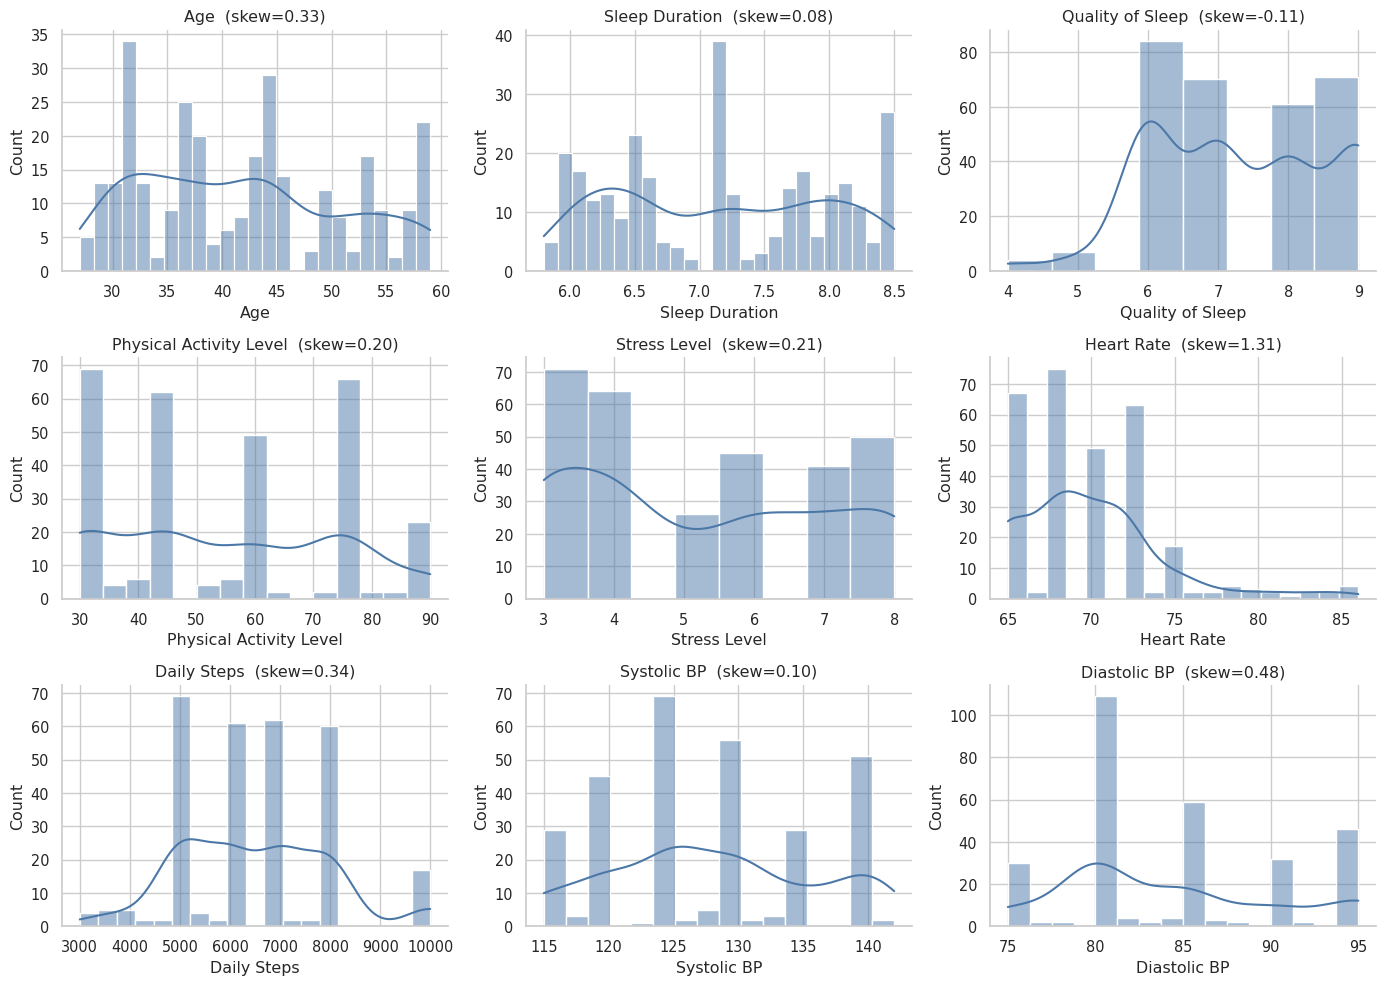

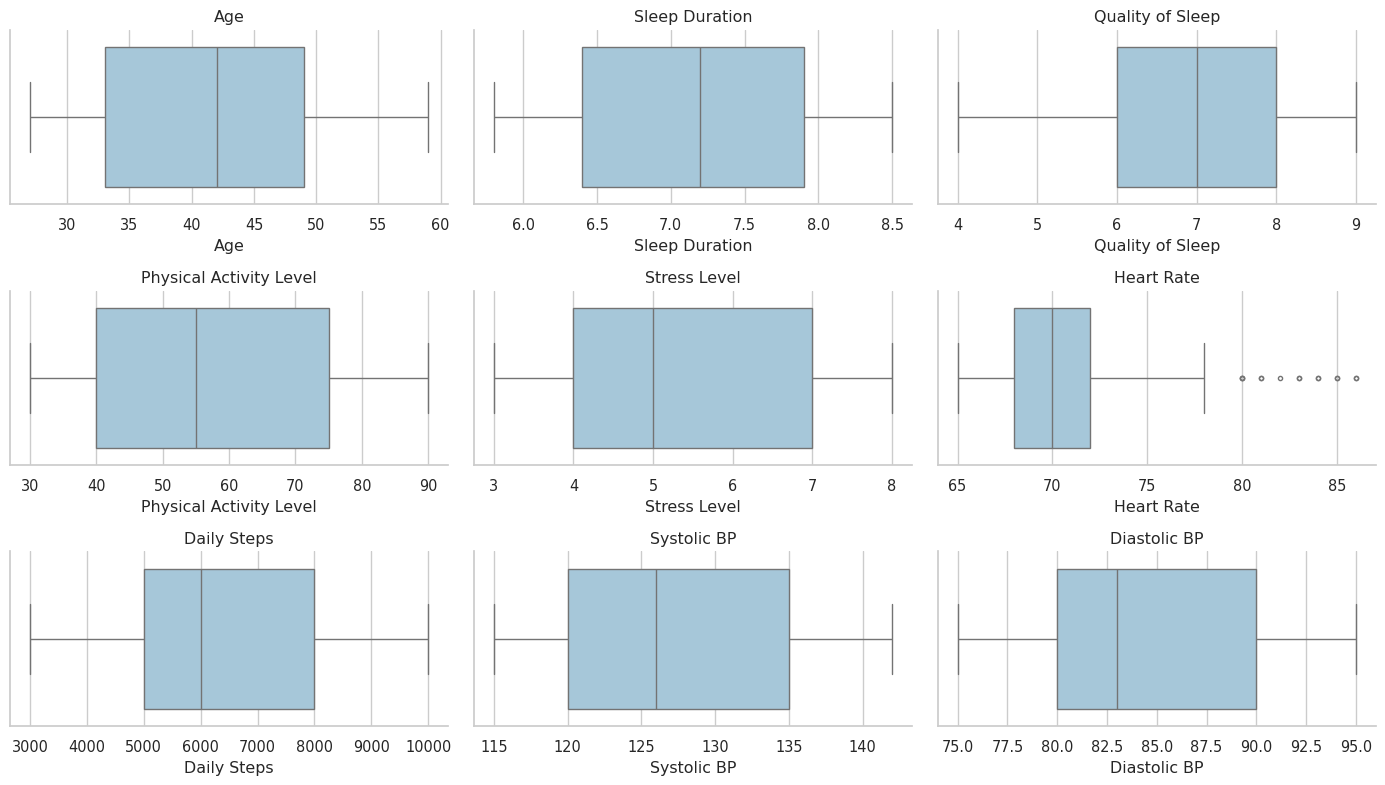

**Reading.** Most skewed: *Heart Rate* (+1.31), *Diastolic BP* (+0.48), *Daily Steps* (+0.34). Variables with few distinct values: *Quality of Sleep* (6 distinct), *Stress Level* (6 distinct). Daily Steps takes only 19 distinct values and Physical Activity Level 15: they behave like coarse scores rather than continuous measurements — a hint of templated data.

In [ ]:
desc = eda[eda_num].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = eda[eda_num].skew(); desc["kurtosis"] = eda[eda_num].kurt(); desc["IQR"] = desc["75%"] - desc["25%"]
display(desc)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), eda_num):
    sns.histplot(eda[c], kde=True, bins=min(25, max(8, eda[c].nunique())), ax=ax, color="#4C78A8"); ax.set_title(f"{c}  (skew={eda[c].skew():.2f})")
savefig("eda_hist_kde.png")

fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), eda_num):
    sns.boxplot(x=eda[c], ax=ax, color="#9ecae1", fliersize=3); ax.set_title(c)
savefig("eda_boxplots.png")

sk = desc["skew"]
say("**Reading.** Most skewed: " + ", ".join(f"*{c}* ({sk[c]:+.2f})" for c in sk.abs().sort_values(ascending=False).index[:3]) +
    ". Variables with few distinct values: " + ", ".join(f"*{c}* ({eda[c].nunique()} distinct)" for c in eda_num if eda[c].nunique() <= 12) +
    f". Daily Steps takes only {eda['Daily Steps'].nunique()} distinct values and Physical Activity Level {eda['Physical Activity Level'].nunique()}: "
    "they behave like coarse scores rather than continuous measurements — a hint of templated data.")

### 5.1b Categorical variables

--- Gender: 2 categories ---


,count,percent
Gender,,
Female,154,51.9000
Male,143,48.1000


--- BMI Category: 3 categories ---


,count,percent
BMI Category,,
Normal,167,56.2000
Overweight,121,40.7000
Obese,9,3.0000


--- Occupation: 10 categories ---


,count,percent
Occupation,,
Doctor,71,23.9000
Nurse,53,17.8000
Engineer,44,14.8000
Teacher,40,13.5000
Salesperson,33,11.1000
Accountant,26,8.8000
Lawyer,24,8.1000
Scientist,4,1.3000
Software Engineer,1,0.3000


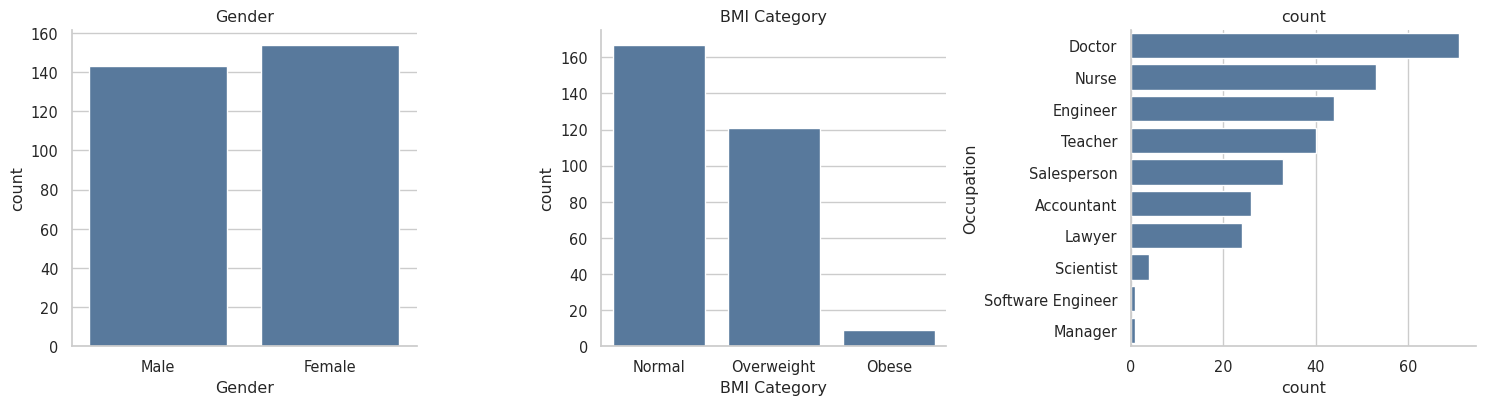

**Reading.** Gender is balanced (48% male). BMI is dominated by *Normal* (56%) and *Overweight* (41%); only 9 rows are *Obese*. Occupation has 10 levels; the three largest (Doctor, Nurse, Engineer) cover 57% of rows, and 3 levels have fewer than 5 rows (pooled as 'infrequent' when encoding).

In [ ]:
for c in ["Gender", "BMI Category", "Occupation"]:
    vc = eda[c].value_counts(); print(f"--- {c}: {len(vc)} categories ---")
    display(pd.DataFrame({"count": vc, "percent": (vc / vc.sum() * 100).round(1)}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.countplot(data=eda, x="Gender", ax=axes[0], color="#4C78A8")
sns.countplot(data=eda, x="BMI Category", order=["Normal", "Overweight", "Obese"], ax=axes[1], color="#4C78A8")
sns.countplot(data=eda, y="Occupation", order=eda["Occupation"].value_counts().index, ax=axes[2], color="#4C78A8")
for ax in axes: ax.set_title(ax.get_xlabel() or ax.get_ylabel())
savefig("eda_categorical_counts.png")

occ = eda["Occupation"].value_counts()
say(f"**Reading.** Gender is balanced ({(eda.Gender=='Male').mean():.0%} male). BMI is dominated by *Normal* ({(eda['BMI Category']=='Normal').mean():.0%}) and *Overweight* "
    f"({(eda['BMI Category']=='Overweight').mean():.0%}); only {(eda['BMI Category']=='Obese').sum()} rows are *Obese*. Occupation has {len(occ)} levels; the three largest "
    f"({', '.join(occ.index[:3])}) cover {occ.iloc[:3].sum()/len(eda):.0%} of rows, and {int((occ<5).sum())} levels have fewer than 5 rows (pooled as 'infrequent' when encoding).")

### 5.2 The target variable

,count,percent
Sleep Disorder,,
None,175,58.9000
Insomnia,62,20.9000
Sleep Apnea,60,20.2000


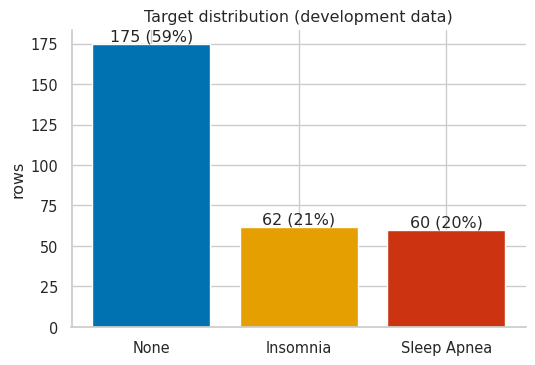

**Reading.** Majority class *None*: 175 rows; minorities: 62 (Insomnia) and 60 (Sleep Apnea) — imbalance ratio 2.9:1. A majority-class guesser scores 59% accuracy, so accuracy alone is misleading; macro-F1, balanced accuracy and per-class recall are used throughout. **Label-quality flag:** 81 development rows (27%) sit in feature vectors that carry more than one label, so some noise is irreducible.

In [ ]:
tc = eda[TARGET].value_counts().reindex(PLOT_ORDER); tp = tc / tc.sum() * 100
display(pd.DataFrame({"count": tc, "percent": tp.round(1)}))
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(PLOT_ORDER, tc.values, color=[PALETTE[c] for c in PLOT_ORDER])
for i, (v, p) in enumerate(zip(tc.values, tp.values)): ax.text(i, v + 2, f"{v} ({p:.0f}%)", ha="center")
ax.set_ylabel("rows"); ax.set_title("Target distribution (development data)"); savefig("eda_target_distribution.png")

dev_key = X_dev.astype(str).agg("|".join, axis=1)                                   # exact feature vector of every development row
n_lab = y_dev.groupby(dev_key.values).transform("nunique")
say(f"**Reading.** Majority class *None*: {tc['None']} rows; minorities: {tc['Insomnia']} (Insomnia) and {tc['Sleep Apnea']} (Sleep Apnea) — imbalance ratio {tc.max()/tc.min():.1f}:1. "
    f"A majority-class guesser scores {tc.max()/tc.sum():.0%} accuracy, so accuracy alone is misleading; macro-F1, balanced accuracy and per-class recall are used throughout. "
    f"**Label-quality flag:** {int((n_lab>1).sum())} development rows ({(n_lab>1).mean():.0%}) sit in feature vectors that carry more than one label, so some noise is irreducible.")

### 5.3 Demographics — gender, age, occupation

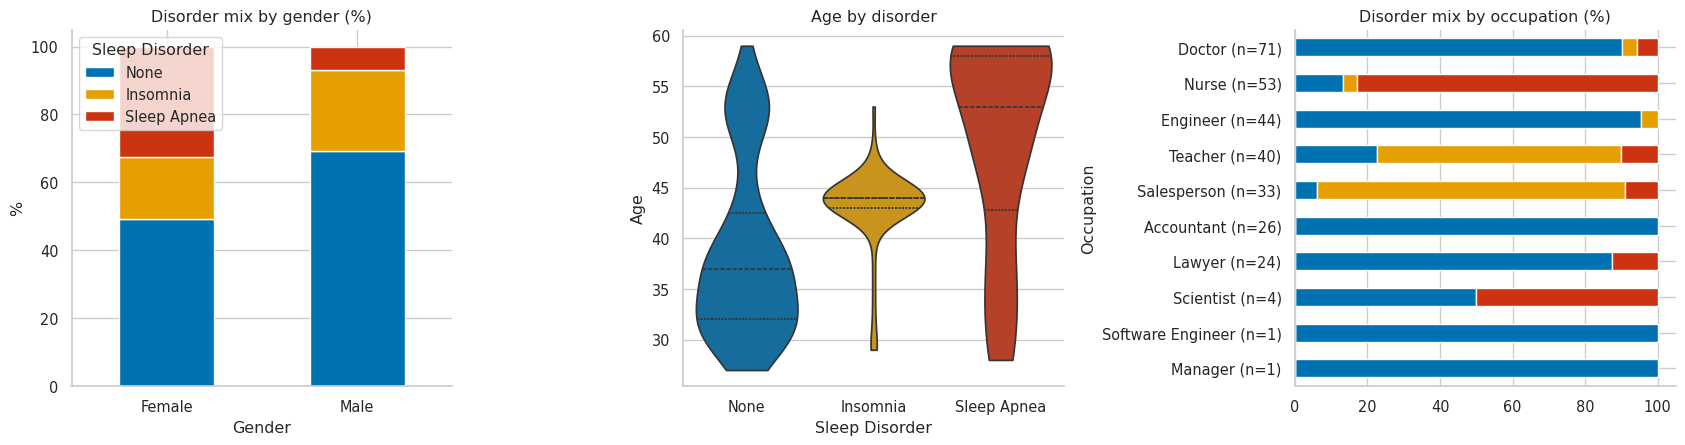

,None,Insomnia,Sleep Apnea,n
Age Group,,,,
<35,85.0000,5.0000,10.0000,80
35-44,55.9000,37.3000,6.8000,118
45-54,56.2000,21.9000,21.9000,64
55+,14.3000,0.0000,85.7000,35


**Reading.** Any disorder: 51% of women vs 31% of men (chi-square p=3.2e-07, Cramér's V=0.32). Median age: 37 (None), 44 (Insomnia), 53 (Sleep Apnea); Kruskal-Wallis p=1.3e-13. Occupations (n>=10) with the highest disorder rate: Salesperson (94%), Nurse (87%), Teacher (78%); lowest: Doctor (10%), Engineer (5%), Accountant (0%) (chi-square p=3.4e-63, V=0.77; several expected counts are <5, so treat this p as indicative). **Caution:** occupation, age, gender and BMI are strongly entangled in this file, so these are associations, not independent effects.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ct_g = pd.crosstab(eda["Gender"], eda[TARGET], normalize="index")[PLOT_ORDER] * 100
ct_g.plot(kind="bar", stacked=True, ax=axes[0], color=[PALETTE[c] for c in PLOT_ORDER], rot=0); axes[0].set_title("Disorder mix by gender (%)"); axes[0].set_ylabel("%")
sns.violinplot(data=eda, x=TARGET, y="Age", order=PLOT_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=axes[1], inner="quartile", cut=0); axes[1].set_title("Age by disorder")
ct_o = pd.crosstab(eda["Occupation"], eda[TARGET]); ct_o = ct_o.loc[ct_o.sum(axis=1).sort_values().index]
(ct_o.div(ct_o.sum(axis=1), axis=0)[PLOT_ORDER] * 100).plot(kind="barh", stacked=True, ax=axes[2], color=[PALETTE[c] for c in PLOT_ORDER], legend=False)
axes[2].set_yticks(range(len(ct_o))); axes[2].set_yticklabels([f"{o} (n={n})" for o, n in zip(ct_o.index, ct_o.sum(axis=1))]); axes[2].set_title("Disorder mix by occupation (%)")
savefig("eda_demographics.png")

age_tab = pd.crosstab(eda["Age Group"], eda[TARGET], normalize="index")[PLOT_ORDER] * 100
display(pd.concat([age_tab.round(1), pd.crosstab(eda["Age Group"], eda[TARGET]).sum(axis=1).rename("n")], axis=1))

ct_gender, ct_occ = pd.crosstab(eda["Gender"], eda[TARGET]), pd.crosstab(eda["Occupation"], eda[TARGET])
chi_g, chi_o = stats.chi2_contingency(ct_gender), stats.chi2_contingency(ct_occ)
H, p_age, e_age = kw("Age")
age_med = eda.groupby(TARGET)["Age"].median()
occ_dis = (1 - pd.crosstab(eda["Occupation"], eda[TARGET], normalize="index")["None"]).where(ct_occ.sum(axis=1) >= 10).dropna().sort_values(ascending=False)
say(f"**Reading.** Any disorder: {1-ct_g.loc['Female','None']/100:.0%} of women vs {1-ct_g.loc['Male','None']/100:.0%} of men (chi-square p={chi_g[1]:.2g}, Cramér's V={cramers_v(ct_gender):.2f}). "
    f"Median age: {age_med['None']:.0f} (None), {age_med['Insomnia']:.0f} (Insomnia), {age_med['Sleep Apnea']:.0f} (Sleep Apnea); Kruskal-Wallis p={p_age:.2g}. "
    "Occupations (n>=10) with the highest disorder rate: " + ", ".join(f"{o} ({r:.0%})" for o, r in occ_dis.head(3).items()) + "; lowest: " + ", ".join(f"{o} ({r:.0%})" for o, r in occ_dis.tail(3).items()) +
    f" (chi-square p={chi_o[1]:.2g}, V={cramers_v(ct_occ):.2f}; several expected counts are <5, so treat this p as indicative). "
    "**Caution:** occupation, age, gender and BMI are strongly entangled in this file, so these are associations, not independent effects.")

### 5.4 Lifestyle — physical activity, stress, daily steps

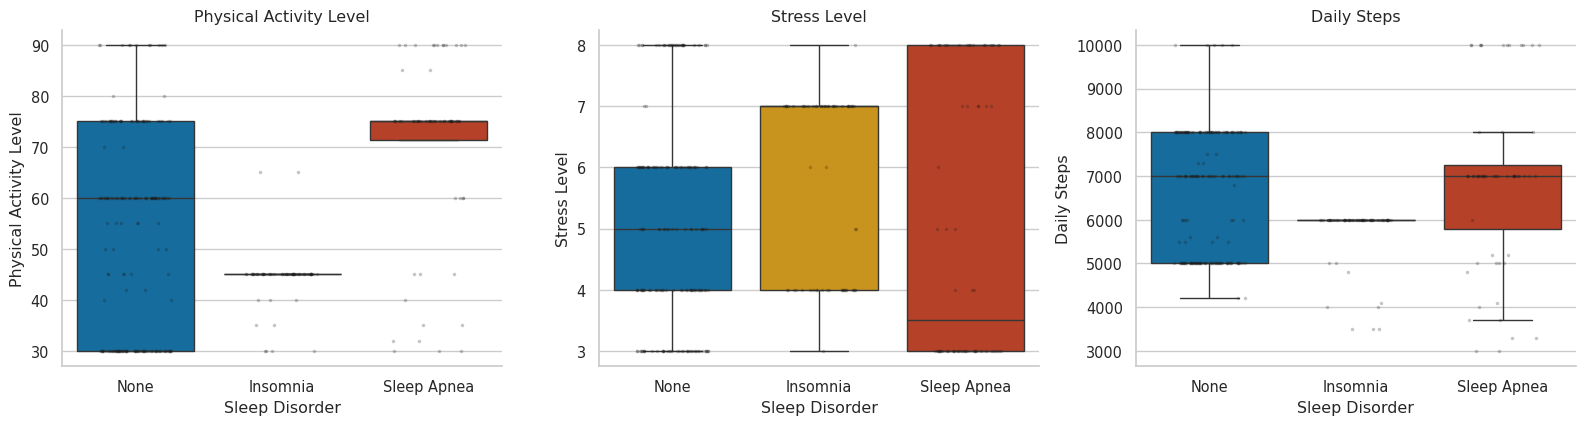

,Physical Activity Level,Stress Level,Daily Steps
Sleep Disorder,,,
None,60.0000,5.0000,"7,000.0000"
Insomnia,45.0000,7.0000,"6,000.0000"
Sleep Apnea,75.0000,3.5000,"7,000.0000"


**Reading.** Median stress: None=5, Insomnia=7, Sleep Apnea=4; median steps: None=7,000, Insomnia=6,000, Sleep Apnea=7,000; median activity: None=60, Insomnia=45, Sleep Apnea=75. Kruskal-Wallis: Physical Activity Level p=3.6e-12 (eps2=0.18), Stress Level p=0.016 (eps2=0.03), Daily Steps p=7.5e-05 (eps2=0.06). The spread within each class is wide for activity and steps, so no single lifestyle variable separates the classes cleanly.

In [ ]:
life = ["Physical Activity Level", "Stress Level", "Daily Steps"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, c in zip(axes, life):
    sns.boxplot(data=eda, x=TARGET, y=c, order=PLOT_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=ax, fliersize=0)
    sns.stripplot(data=eda, x=TARGET, y=c, order=PLOT_ORDER, color="k", alpha=.25, size=2.5, jitter=.25, ax=ax); ax.set_title(c)
savefig("eda_lifestyle.png")
med = eda.groupby(TARGET)[life].median().reindex(PLOT_ORDER); display(med)
res = {c: kw(c) for c in life}
say("**Reading.** Median stress: " + ", ".join(f"{k}={med.loc[k,'Stress Level']:.0f}" for k in PLOT_ORDER) +
    "; median steps: " + ", ".join(f"{k}={med.loc[k,'Daily Steps']:,.0f}" for k in PLOT_ORDER) + "; median activity: " + ", ".join(f"{k}={med.loc[k,'Physical Activity Level']:.0f}" for k in PLOT_ORDER) +
    ". Kruskal-Wallis: " + ", ".join(f"{c} p={res[c][1]:.2g} (eps2={res[c][2]:.2f})" for c in life) +
    ". The spread within each class is wide for activity and steps, so no single lifestyle variable separates the classes cleanly.")

### 5.5 Sleep — duration and quality

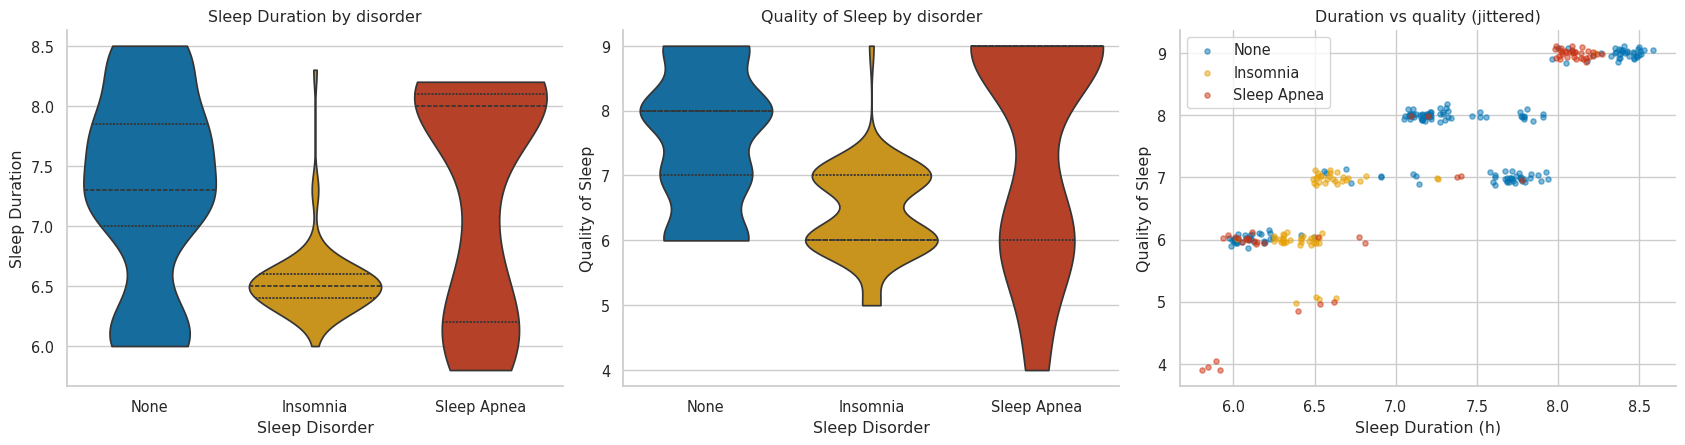

Sleep Duration               Quality of Sleep              
                       median   mean    std           median   mean    std
Sleep Disorder                                                            
None                   7.3000 7.3337 0.7990           8.0000 7.5543 1.0593
Insomnia               6.5000 6.5339 0.3062           6.0000 6.4194 0.6906
Sleep Apnea            8.0000 7.3000 0.9346           9.0000 7.5333 1.7317

**Reading.** Median sleep duration: 7.3 h (None), 6.5 h (Insomnia), 8.0 h (Sleep Apnea); median quality: 8, 6, 9. Kruskal-Wallis: duration p=2.4e-08 (eps2=0.12); quality p=5.1e-10 (eps2=0.14). Duration and quality are strongly correlated (Spearman rho=0.90). Insomnia has shorter median sleep than None; Sleep Apnea has equal/longer median sleep than None - **counter-intuitive for apnea**, a hint that the file is synthetic/templated rather than clinically measured. Sleep duration/quality may be *consequences* of a disorder, so they are **indirect-leakage candidates** for a screening use-case; this is tested in Phase 7.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, c in zip(axes[:2], ["Sleep Duration", "Quality of Sleep"]):
    sns.violinplot(data=eda, x=TARGET, y=c, order=PLOT_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=ax, inner="quartile", cut=0); ax.set_title(c + " by disorder")
rng = np.random.default_rng(SEED)
for cl in PLOT_ORDER:
    s = eda[eda[TARGET] == cl]
    axes[2].scatter(s["Sleep Duration"] + rng.normal(0, .03, len(s)), s["Quality of Sleep"] + rng.normal(0, .06, len(s)), s=14, alpha=.5, color=PALETTE[cl], label=cl)
axes[2].set_xlabel("Sleep Duration (h)"); axes[2].set_ylabel("Quality of Sleep"); axes[2].legend(); axes[2].set_title("Duration vs quality (jittered)")
savefig("eda_sleep.png")

sm = eda.groupby(TARGET)[["Sleep Duration", "Quality of Sleep"]].agg(["median", "mean", "std"]).reindex(PLOT_ORDER); display(sm)
rho_dq = stats.spearmanr(eda["Sleep Duration"], eda["Quality of Sleep"]).statistic
kd, kq = kw("Sleep Duration"), kw("Quality of Sleep")
dur = sm[("Sleep Duration", "median")]; qual = sm[("Quality of Sleep", "median")]
apnea_note = " - **counter-intuitive for apnea**, a hint that the file is synthetic/templated rather than clinically measured." if dur["Sleep Apnea"] >= dur["None"] else "."
say(f"**Reading.** Median sleep duration: {dur['None']:.1f} h (None), {dur['Insomnia']:.1f} h (Insomnia), {dur['Sleep Apnea']:.1f} h (Sleep Apnea); median quality: {qual['None']:.0f}, {qual['Insomnia']:.0f}, {qual['Sleep Apnea']:.0f}. "
    f"Kruskal-Wallis: duration p={kd[1]:.2g} (eps2={kd[2]:.2f}); quality p={kq[1]:.2g} (eps2={kq[2]:.2f}). Duration and quality are strongly correlated (Spearman rho={rho_dq:.2f}). "
    f"Insomnia has {'shorter' if dur['Insomnia'] < dur['None'] else 'equal/longer'} median sleep than None; Sleep Apnea has {'shorter' if dur['Sleep Apnea'] < dur['None'] else 'equal/longer'} median sleep than None" + apnea_note +
    " Sleep duration/quality may be *consequences* of a disorder, so they are **indirect-leakage candidates** for a screening use-case; this is tested in Phase 7.")

### 5.6 Health — BMI, blood pressure, heart rate

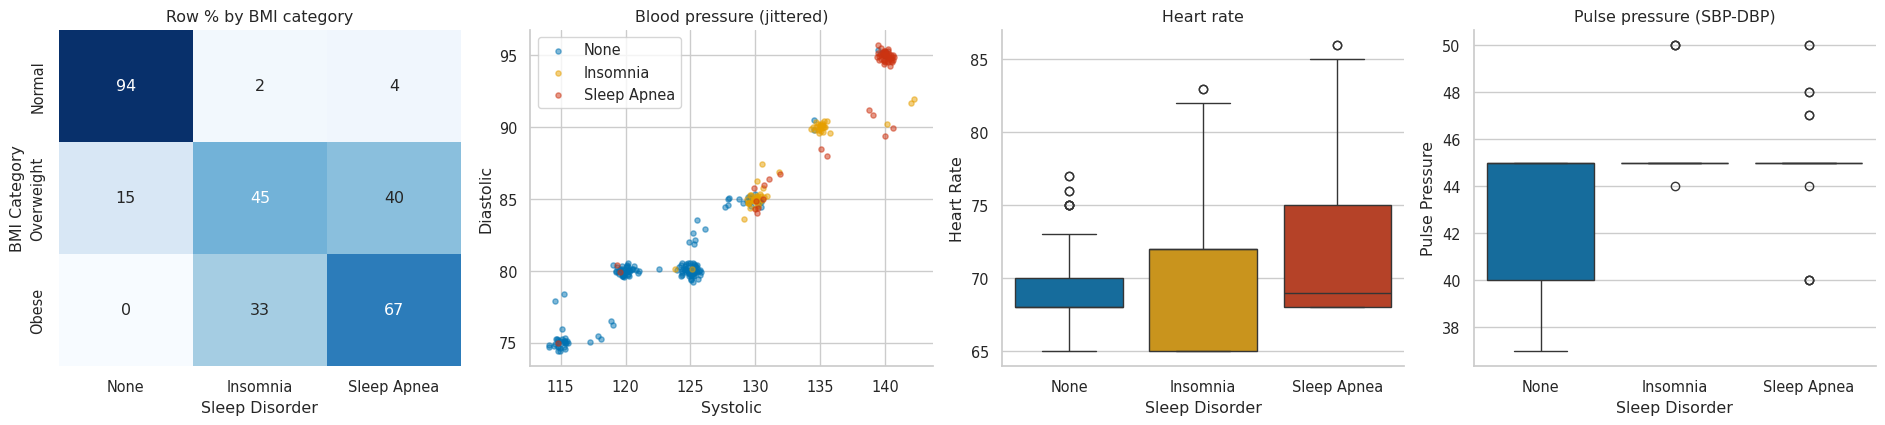

Sleep Disorder,None,Insomnia,Sleep Apnea,total
BMI Category,,,,
Normal,157,4,6,167
Overweight,18,55,48,121
Obese,0,3,6,9


,Systolic BP,Diastolic BP,Heart Rate,Pulse Pressure
Sleep Disorder,,,,
None,125.0000,80.0000,68.0000,45.0000
Insomnia,130.0000,85.5000,72.0000,45.0000
Sleep Apnea,140.0000,95.0000,69.0000,45.0000


**Reading.** Share with *any* recorded disorder by BMI: Normal=6% (n=167), Overweight=85% (n=121), Obese=100% (n=9) (chi-square p=9.3e-42, V=0.58). Median BP: None 125/80; Insomnia 130/86; Sleep Apnea 140/95; median heart rate: None=68, Insomnia=72, Sleep Apnea=69. BMI and BP take few distinct values and form tight clusters (jitter is for display only).

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
ct_b = pd.crosstab(eda["BMI Category"], eda[TARGET]).reindex(["Normal", "Overweight", "Obese"])[PLOT_ORDER]
sns.heatmap(ct_b.div(ct_b.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("Row % by BMI category")
for cl in PLOT_ORDER:
    s = eda[eda[TARGET] == cl]
    axes[1].scatter(s["Systolic BP"] + rng.normal(0, .4, len(s)), s["Diastolic BP"] + rng.normal(0, .3, len(s)), s=14, alpha=.5, color=PALETTE[cl], label=cl)
axes[1].set_xlabel("Systolic"); axes[1].set_ylabel("Diastolic"); axes[1].legend(); axes[1].set_title("Blood pressure (jittered)")
sns.boxplot(data=eda, x=TARGET, y="Heart Rate", order=PLOT_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=axes[2]); axes[2].set_title("Heart rate")
sns.boxplot(data=eda, x=TARGET, y="Pulse Pressure", order=PLOT_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=axes[3]); axes[3].set_title("Pulse pressure (SBP-DBP)")
savefig("eda_health.png")

display(ct_b.assign(total=ct_b.sum(axis=1)))
health_med = eda.groupby(TARGET)[["Systolic BP", "Diastolic BP", "Heart Rate", "Pulse Pressure"]].median().reindex(PLOT_ORDER); display(health_med)
dis_rate_bmi = 1 - ct_b["None"] / ct_b.sum(axis=1)
say("**Reading.** Share with *any* recorded disorder by BMI: " + ", ".join(f"{k}={v:.0%} (n={int(ct_b.loc[k].sum())})" for k, v in dis_rate_bmi.items()) +
    f" (chi-square p={stats.chi2_contingency(ct_b)[1]:.2g}, V={cramers_v(ct_b):.2f}). Median BP: " + "; ".join(f"{k} {health_med.loc[k,'Systolic BP']:.0f}/{health_med.loc[k,'Diastolic BP']:.0f}" for k in PLOT_ORDER) +
    "; median heart rate: " + ", ".join(f"{k}={health_med.loc[k,'Heart Rate']:.0f}" for k in PLOT_ORDER) + ". BMI and BP take few distinct values and form tight clusters (jitter is for display only).")

### 5.7 Every predictor against the target

,feature,test,statistic,p_value,effect_size,effect_metric,p_bonferroni
0,Occupation,chi-square,349.1432,0.0000,0.7667,Cramer's V,0.0000
1,Diastolic BP,Kruskal-Wallis,180.3207,0.0000,0.6092,epsilon^2,0.0000
2,Systolic BP,Kruskal-Wallis,173.7420,0.0000,0.5870,epsilon^2,0.0000
3,BMI Category,chi-square,198.1696,0.0000,0.5776,Cramer's V,0.0000
4,Age Group,chi-square,142.6367,0.0000,0.4900,Cramer's V,0.0000
5,Gender,chi-square,29.9038,0.0000,0.3173,Cramer's V,0.0000
6,Pulse Pressure,Kruskal-Wallis,75.4215,0.0000,0.2548,epsilon^2,0.0000
7,Age,Kruskal-Wallis,59.2857,0.0000,0.2003,epsilon^2,0.0000
8,Physical Activity Level,Kruskal-Wallis,52.6919,0.0000,0.1780,epsilon^2,0.0000
9,Quality of Sleep,Kruskal-Wallis,42.7811,0.0000,0.1445,epsilon^2,0.0000


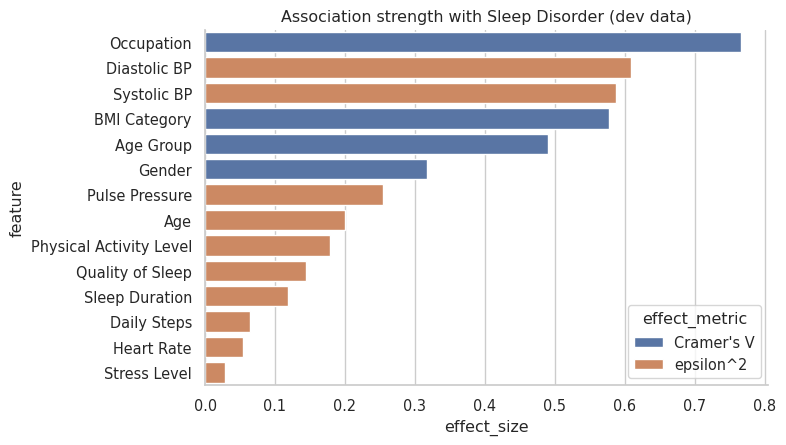

**Reading.** Strongest associations: *Occupation* (Cramer's V=0.77), *Diastolic BP* (epsilon^2=0.61), *Systolic BP* (epsilon^2=0.59), *BMI Category* (Cramer's V=0.58). 13 of 14 predictors stay significant after Bonferroni correction. Effect sizes of the two metrics are not directly comparable, and with so many repeated rows the p-values overstate the real evidence.

In [ ]:
rows = []
for c in eda_num + ["Pulse Pressure"]:
    H, p, e = kw(c); rows.append({"feature": c, "test": "Kruskal-Wallis", "statistic": H, "p_value": p, "effect_size": e, "effect_metric": "epsilon^2"})
for c in ["Gender", "BMI Category", "Occupation", "Age Group"]:
    ct = pd.crosstab(eda[c], eda[TARGET]); chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p, "effect_size": cramers_v(ct), "effect_metric": "Cramer's V"})
biv = pd.DataFrame(rows)
biv["p_bonferroni"] = (biv.p_value * len(biv)).clip(upper=1.0)                      # Bonferroni: multiply p by the number of tests
biv = biv.sort_values("effect_size", ascending=False).reset_index(drop=True)
display(biv); biv.to_csv(OUTPUTS_DIR / "eda_bivariate_tests.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.6)); sns.barplot(data=biv, y="feature", x="effect_size", hue="effect_metric", dodge=False, ax=ax)
ax.set_title("Association strength with Sleep Disorder (dev data)"); savefig("eda_bivariate_effects.png")
say("**Reading.** Strongest associations: " + ", ".join(f"*{r.feature}* ({r.effect_metric}={r.effect_size:.2f})" for r in biv.head(4).itertuples()) +
    f". {int((biv.p_bonferroni<0.05).sum())} of {len(biv)} predictors stay significant after Bonferroni correction. Effect sizes of the two metrics are not directly comparable, and with so many repeated rows the p-values overstate the real evidence.")

### 5.8 Several variables together — correlations, pairs, grouped statistics

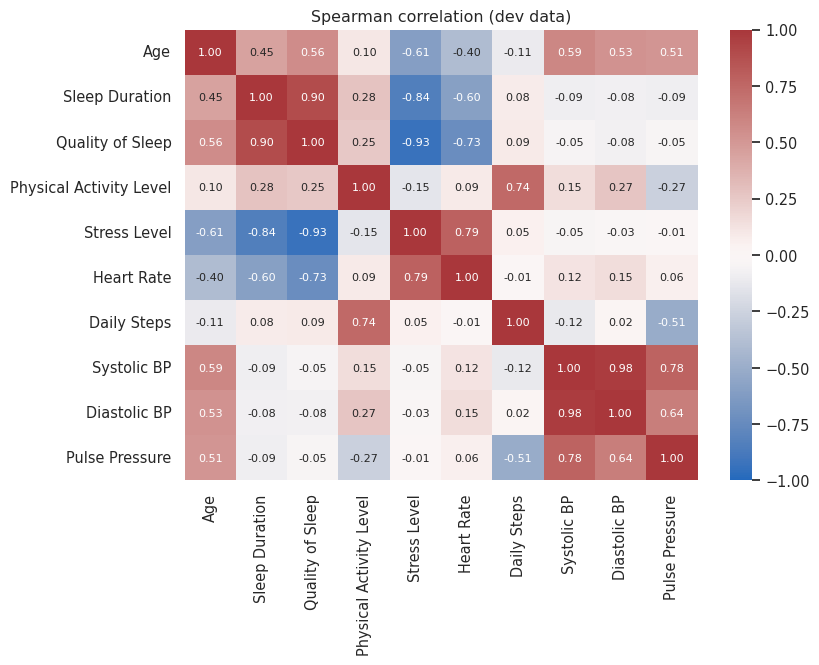

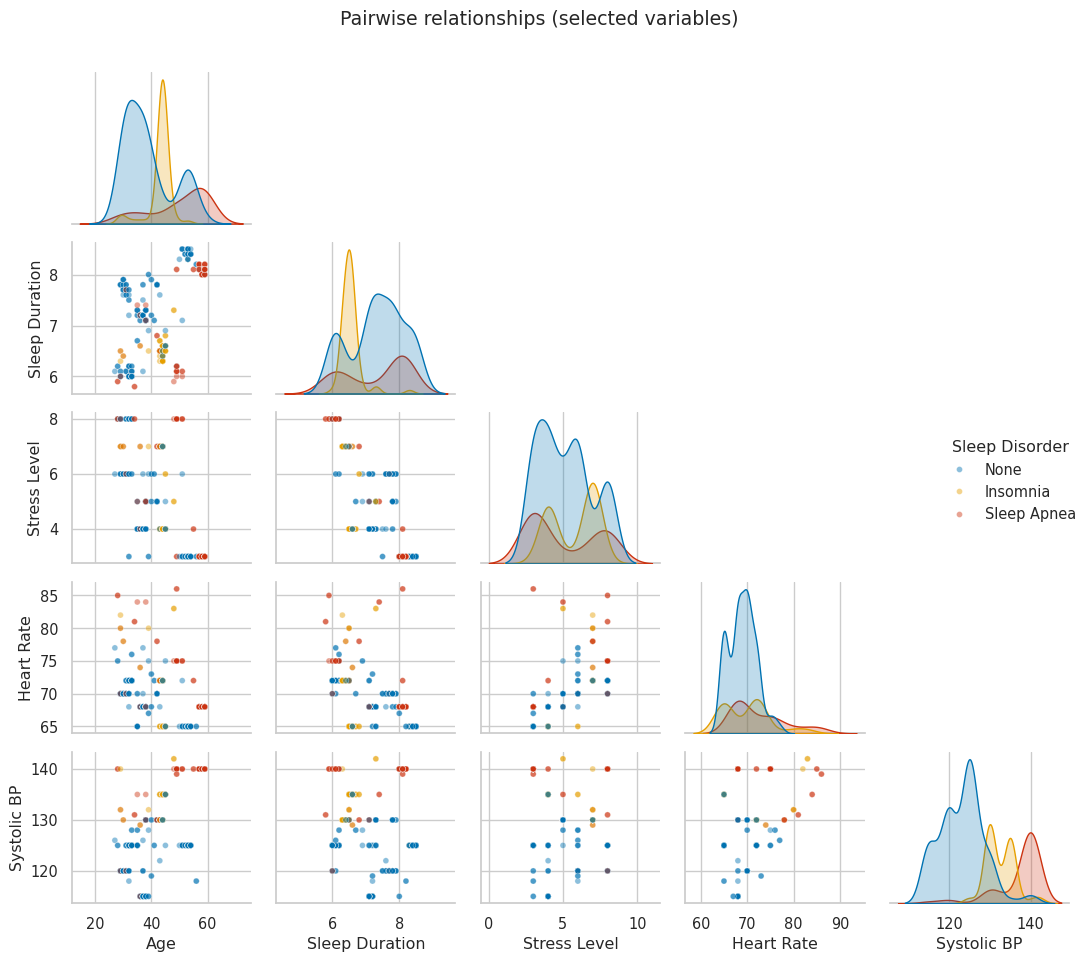

rho
Systolic BP      Diastolic BP      0.9752
Quality of Sleep Stress Level     -0.9315
Sleep Duration   Quality of Sleep  0.8955
                 Stress Level     -0.8409
Stress Level     Heart Rate        0.7851
Systolic BP      Pulse Pressure    0.7793

In [ ]:
corr = eda[eda_num + ["Pulse Pressure"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation (dev data)"); savefig("eda_corr_heatmap.png")

g = sns.pairplot(eda, vars=["Age", "Sleep Duration", "Stress Level", "Heart Rate", "Systolic BP"], hue=TARGET, hue_order=PLOT_ORDER, palette=PALETTE, corner=True, plot_kws={"alpha": .45, "s": 18}, height=1.9)
g.figure.suptitle("Pairwise relationships (selected variables)", y=1.01); savefig("eda_pairplot.png")

tri = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("rho").to_frame()
tri["abs"] = tri.rho.abs(); top_pairs = tri.sort_values("abs", ascending=False).head(6); display(top_pairs[["rho"]])

=== Median of every numeric variable, by disorder ===


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP
Sleep Disorder,,,,,,,,,
None,37.0000,7.3000,8.0000,60.0000,5.0000,68.0000,"7,000.0000",125.0000,80.0000
Insomnia,44.0000,6.5000,6.0000,45.0000,7.0000,72.0000,"6,000.0000",130.0000,85.5000
Sleep Apnea,53.0000,8.0000,9.0000,75.0000,3.5000,69.0000,"7,000.0000",140.0000,95.0000


=== Share with any disorder: BMI x Gender ===


mean          size     
Gender       Female   Male Female Male
BMI Category                          
Normal       0.0833 0.0421     72   95
Overweight   0.8765 0.8000     81   40
Obese        1.0000 1.0000      1    8

=== Disorder counts by Occupation x BMI ===


Sleep Disorder                  None  Insomnia  Sleep Apnea
Occupation        BMI Category                             
Accountant        Normal          26         0            0
Doctor            Normal          64         1            2
                  Obese            0         2            2
Engineer          Normal          41         1            0
                  Overweight       1         1            0
Lawyer            Normal          19         0            1
                  Obese            0         0            2
                  Overweight       2         0            0
Manager           Overweight       1         0            0
Nurse             Normal           2         2            2
                  Overweight       5         0           42
Salesperson       Obese            0         0            2
                  Overweight       2        28            1
Scientist         Overweight       2         0            2
Software Engineer Overweight       1         0            0
Teacher           Normal           5         0            1
                  Obese            0         1            0
                  Overweight       4        26            3

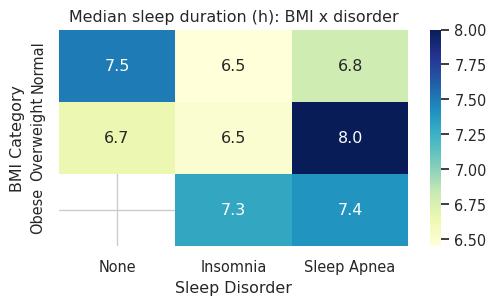

**Reading.** Strongest rank correlations: Systolic BP ~ Diastolic BP (+0.98), Quality of Sleep ~ Stress Level (-0.93), Sleep Duration ~ Quality of Sleep (+0.90), Sleep Duration ~ Stress Level (-0.84), Stress Level ~ Heart Rate (+0.79), Systolic BP ~ Pulse Pressure (+0.78). Several are structural (systolic ~ diastolic ~ pulse pressure) and the sleep-quality / stress / duration trio moves together, so multicollinearity is expected. It is handled by regularisation, tree models and in-pipeline selection rather than by arbitrary column deletion. The BMI x gender table shows that disorder prevalence changes strongly with BMI inside *both* genders, so the gender gap is partly confounded by BMI/occupation mix.

In [ ]:
print("=== Median of every numeric variable, by disorder ==="); display(eda.groupby(TARGET)[eda_num].median().reindex(PLOT_ORDER))

print("=== Share with any disorder: BMI x Gender ===")
tmp = eda.assign(any_disorder=(eda[TARGET] != "None").astype(int))
display(tmp.pivot_table(index="BMI Category", columns="Gender", values="any_disorder", aggfunc=["mean", "size"]).reindex(["Normal", "Overweight", "Obese"]))

print("=== Disorder counts by Occupation x BMI ==="); display(pd.crosstab([eda["Occupation"], eda["BMI Category"]], eda[TARGET])[PLOT_ORDER])

piv = eda.pivot_table(index="BMI Category", columns=TARGET, values="Sleep Duration", aggfunc="median").reindex(["Normal", "Overweight", "Obese"])[PLOT_ORDER]
fig, ax = plt.subplots(figsize=(5.2, 3.2)); sns.heatmap(piv, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax); ax.set_title("Median sleep duration (h): BMI x disorder"); savefig("eda_bmi_sleep_heatmap.png")

say("**Reading.** Strongest rank correlations: " + ", ".join(f"{a} ~ {b} ({r:+.2f})" for (a, b), r in top_pairs.rho.items()) +
    ". Several are structural (systolic ~ diastolic ~ pulse pressure) and the sleep-quality / stress / duration trio moves together, so multicollinearity is expected. "
    "It is handled by regularisation, tree models and in-pipeline selection rather than by arbitrary column deletion. The BMI x gender table shows that disorder prevalence changes strongly with BMI inside *both* genders, so the gender gap is partly confounded by BMI/occupation mix.")

### 5.9 EDA conclusions

In [ ]:
top = biv.head(5)
say("**What the development data show**\n\n"
    "* **Patterns / BMI & cardiovascular:** strongest univariate associations: " + ", ".join(f"*{r.feature}*" for r in top.itertuples()) +
    f". Share with any recorded disorder by BMI: {dis_rate_bmi.round(2).to_dict()}; median systolic BP by class: {health_med['Systolic BP'].round(0).to_dict()}.\n"
    "* **Demographics:** age, gender and occupation are associated with the target but entangled with each other and with BMI.\n"
    "* **Sleep:** duration and quality differ by class, are collinear, and are plausibly *consequences* of the disorders.\n"
    "* **Lifestyle:** stress, steps and activity are associated with the target but with wide within-class spread.\n"
    f"* **Class balance:** {tc['None']} / {tc['Insomnia']} / {tc['Sleep Apnea']} (None / Insomnia / Sleep Apnea) — moderate imbalance.\n"
    "* **Data caveat (important):** the table is dominated by repeated, near-identical profiles and carries irreducible label conflicts, so associations look cleaner than real-world data would and p-values are optimistic.\n\n"
    "*These are observed associations in one dataset, not causal effects or clinical findings.*")

**What the development data show**

* **Patterns / BMI & cardiovascular:** strongest univariate associations: *Occupation*, *Diastolic BP*, *Systolic BP*, *BMI Category*, *Age Group*. Share with any recorded disorder by BMI: {'Normal': 0.06, 'Overweight': 0.85, 'Obese': 1.0}; median systolic BP by class: {'None': 125.0, 'Insomnia': 130.0, 'Sleep Apnea': 140.0}.
* **Demographics:** age, gender and occupation are associated with the target but entangled with each other and with BMI.
* **Sleep:** duration and quality differ by class, are collinear, and are plausibly *consequences* of the disorders.
* **Lifestyle:** stress, steps and activity are associated with the target but with wide within-class spread.
* **Class balance:** 175 / 62 / 60 (None / Insomnia / Sleep Apnea) — moderate imbalance.
* **Data caveat (important):** the table is dominated by repeated, near-identical profiles and carries irreducible label conflicts, so associations look cleaner than real-world data would and p-values are optimistic.

*These are observed associations in one dataset, not causal effects or clinical findings.*

## Phase 6 — Outlier detection and treatment
*(development partition; detection is descriptive, the treatment is judged by leakage-safe cross-validation)*

Outlier **investigation** is never skipped; **treatment** is applied only if the evidence supports it. Methods: IQR fences, box plots, quantiles, z-score and robust (MAD) z-score, plausibility screens, and two multivariate detectors (Isolation Forest, Local Outlier Factor).

,IQR lower,IQR upper,n_outliers (1.5 IQR),% outliers,n_extreme (3 IQR),n |z|>3,n |robust z|>3.5,MAD,min,p1,p99,max
feature,,,,,,,,,,,,
Age,9.0000,73.0000,0,0.0000,0,0,0,8.0000,27.0000,28.0000,59.0000,59.0000
Sleep Duration,4.1500,10.1500,0,0.0000,0,0,0,0.7000,5.8000,5.9000,8.5000,8.5000
Quality of Sleep,3.0000,11.0000,0,0.0000,0,0,0,1.0000,4.0000,4.0000,9.0000,9.0000
Physical Activity Level,-12.5000,127.5000,0,0.0000,0,0,0,20.0000,30.0000,30.0000,90.0000,90.0000
Stress Level,-0.5000,11.5000,0,0.0000,0,0,0,2.0000,3.0000,3.0000,8.0000,8.0000
Heart Rate,62.0000,78.0000,14,4.7138,4,8,11,2.0000,65.0000,65.0000,85.0000,86.0000
Daily Steps,500.0000,"12,500.0000",0,0.0000,0,0,0,"1,000.0000","3,000.0000","3,300.0000","10,000.0000","10,000.0000"
Systolic BP,97.5000,157.5000,0,0.0000,0,0,0,6.0000,115.0000,115.0000,140.0000,142.0000
Diastolic BP,65.0000,105.0000,0,0.0000,0,0,0,3.0000,75.0000,75.0000,95.0000,95.0000


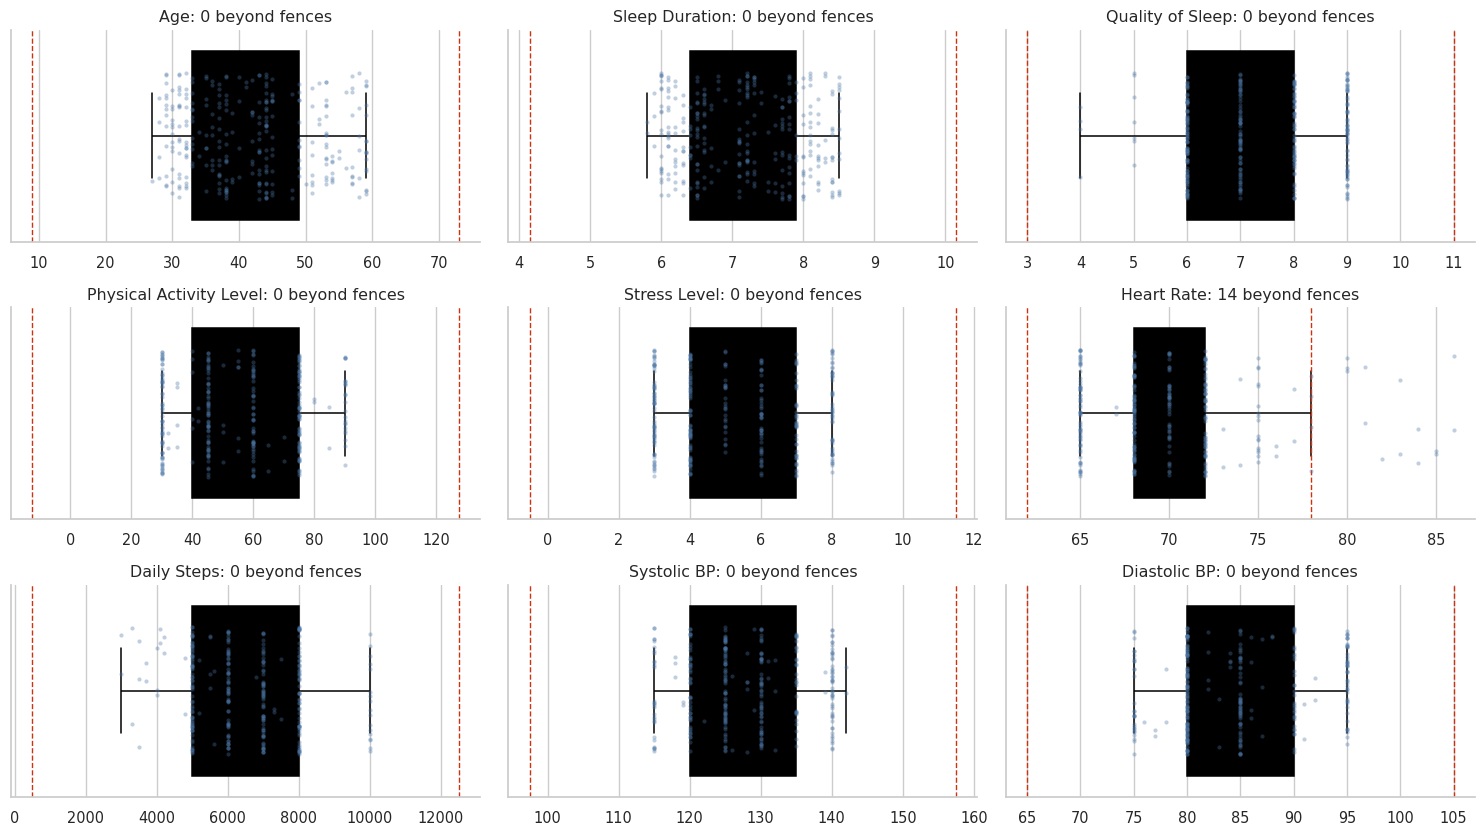

**Reading.** 1 of 9 features have values beyond the 1.5-IQR fences: *Heart Rate* (14 rows, 4.7%). Extreme (3-IQR) outliers: 4 in total. Robust-z counts are NaN where MAD = 0 (more than half of the rows share one value) — itself a sign of clustered, templated data.

In [ ]:
out_num = eda_num

def iqr_bounds(s, k=1.5):
    """Tukey fences: Q1 - k*IQR and Q3 + k*IQR."""
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

rows = []
for c in out_num:
    s = eda[c].astype(float)
    lo, hi = iqr_bounds(s); lo3, hi3 = iqr_bounds(s, 3.0)
    flag = (s < lo) | (s > hi)
    med = s.median(); mad = (s - med).abs().median()
    robust_z = 0.6745 * (s - med) / mad if mad > 0 else pd.Series(np.nan, index=s.index)
    z = (s - s.mean()) / s.std()
    rows.append({"feature": c, "IQR lower": lo, "IQR upper": hi, "n_outliers (1.5 IQR)": int(flag.sum()), "% outliers": 100 * flag.mean(),
                 "n_extreme (3 IQR)": int(((s < lo3) | (s > hi3)).sum()), "n |z|>3": int((z.abs() > 3).sum()),
                 "n |robust z|>3.5": int((robust_z.abs() > 3.5).sum()) if mad > 0 else np.nan, "MAD": mad,
                 "min": s.min(), "p1": s.quantile(.01), "p99": s.quantile(.99), "max": s.max()})
outl = pd.DataFrame(rows).set_index("feature"); display(outl)
outl.to_csv(OUTPUTS_DIR / "outlier_summary_by_feature.csv")

fig, axes = plt.subplots(3, 3, figsize=(15, 8.5))
for ax, c in zip(axes.ravel(), out_num):
    lo, hi = iqr_bounds(eda[c])
    sns.stripplot(x=eda[c], ax=ax, size=3, alpha=.35, jitter=.3, color="#4C78A8")
    sns.boxplot(x=eda[c], ax=ax, color="none", fliersize=0, linewidth=1.1)
    ax.axvline(lo, color="#CC3311", ls="--", lw=1); ax.axvline(hi, color="#CC3311", ls="--", lw=1)
    ax.set_title(f"{c}: {int(outl.loc[c, 'n_outliers (1.5 IQR)'])} beyond fences"); ax.set_xlabel("")
savefig("outliers_fences.png")

flagged_feats = outl.index[outl["n_outliers (1.5 IQR)"] > 0].tolist()
say(f"**Reading.** {len(flagged_feats)} of {len(out_num)} features have values beyond the 1.5-IQR fences: " +
    ", ".join(f"*{c}* ({int(outl.loc[c,'n_outliers (1.5 IQR)'])} rows, {outl.loc[c,'% outliers']:.1f}%)" for c in flagged_feats) +
    f". Extreme (3-IQR) outliers: {int(outl['n_extreme (3 IQR)'].sum())} in total. Robust-z counts are NaN where MAD = 0 (more than half of the rows share one value) — itself a sign of clustered, templated data.")

### 6.1b Plausibility and multivariate screens
*Hard bounds* (`HARD_BOUNDS`) define **impossible** values. The *typical-range* limits below are generic, analyst-defined screening limits used only to flag values for review — nothing is removed because of them.

In [ ]:
TYPICAL = {"Age": (18, 80), "Sleep Duration": (4, 10), "Quality of Sleep": (1, 10), "Stress Level": (1, 10),
           "Heart Rate": (40, 110), "Daily Steps": (0, 30000), "Systolic BP": (90, 180), "Diastolic BP": (50, 110)}
HARD = dict(HARD_BOUNDS)
plaus = pd.DataFrame([{"feature": c, "hard_bounds": HARD.get(c), "typical_screen": TYPICAL.get(c),
                       "n_outside_hard": int(((eda[c] < HARD[c][0]) | (eda[c] > HARD[c][1])).sum()) if c in HARD else 0,
                       "n_outside_typical": int(((eda[c] < TYPICAL[c][0]) | (eda[c] > TYPICAL[c][1])).sum()) if c in TYPICAL else np.nan} for c in out_num])
display(plaus)
coherence = {"systolic <= diastolic": int((eda["Systolic BP"] <= eda["Diastolic BP"]).sum()), "unparsable BP": int(eda["Systolic BP"].isna().sum()),
             "Sleep Duration with >1 decimal": int((eda["Sleep Duration"].round(1) != eda["Sleep Duration"]).sum())}
print("Coherence checks (possible data-entry errors):", coherence)

# Multivariate detectors: Isolation Forest and Local Outlier Factor (5 % contamination is fixed, so counts are by construction)
Z = StandardScaler().fit_transform(eda[out_num])
iso_flag = IsolationForest(contamination=0.05, random_state=SEED).fit(Z).predict(Z) == -1
lof_flag = LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(Z) == -1
consensus = iso_flag & lof_flag
print(f"Isolation Forest flags {iso_flag.sum()}, LOF flags {lof_flag.sum()}, both flag {consensus.sum()} of {len(Z)} rows")
display(eda.loc[consensus, out_num + [TARGET]].drop_duplicates().head(10))

,feature,hard_bounds,typical_screen,n_outside_hard,n_outside_typical
0,Age,"(18, 100)","(18, 80)",0,0.0000
1,Sleep Duration,"(0, 24)","(4, 10)",0,0.0000
2,Quality of Sleep,"(1, 10)","(1, 10)",0,0.0000
3,Physical Activity Level,"(0, 1440)",None,0,NaN
4,Stress Level,"(1, 10)","(1, 10)",0,0.0000
5,Heart Rate,"(30, 220)","(40, 110)",0,0.0000
6,Daily Steps,"(0, 100000)","(0, 30000)",0,0.0000
7,Systolic BP,"(50, 300)","(90, 180)",0,0.0000
8,Diastolic BP,"(30, 200)","(50, 110)",0,0.0000


Coherence checks (possible data-entry errors): {'systolic <= diastolic': 0, 'unparsable BP': 0, 'Sleep Duration with >1 decimal': 0}
Isolation Forest flags 15, LOF flags 14, both flag 6 of 297 rows


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP,Sleep Disorder
1,28,6.2000,6,60,8,75,10000,125.0000,80.0000,None
149,39,8.0000,9,80,3,67,7500,115.0000,78.0000,None
276,49,8.1000,9,85,3,86,3700,139.0000,91.0000,Sleep Apnea


### 6.2 Outlier classification (transparent rules)

In [ ]:
def profile_support(idx):
    """How many development rows share exactly this feature vector? (repeated values are probably meaningful, not errors)"""
    return int((dev_key == dev_key.loc[idx]).sum())

items = []
for c in out_num:
    lo, hi = iqr_bounds(eda[c])
    for idx, v in eda.loc[(eda[c] < lo) | (eda[c] > hi), c].items():
        items.append({"row": idx, "feature": c, "value": v, "direction": "high" if v > hi else "low", "fence": hi if v > hi else lo,
                      "profile_support": profile_support(idx), "multivariate_consensus": bool(consensus[eda.index.get_loc(idx)])})
items = pd.DataFrame(items)

def classify(r):
    c, v = r.feature, r.value
    if c in HARD and not (HARD[c][0] <= v <= HARD[c][1]): return "Impossible or invalid value"
    if c in TYPICAL and not (TYPICAL[c][0] <= v <= TYPICAL[c][1]): return "Uncertain - requires further investigation"
    if r.profile_support >= 3: return "Unusually distributed but meaningful observation"
    if r.multivariate_consensus: return "Potential data-entry error (isolated + multivariate anomaly) - verify at source"
    return "Valid extreme observation"

if len(items):
    items["classification"] = items.apply(classify, axis=1)
    display(items.groupby(["feature", "direction", "classification"]).agg(rows=("row", "size"), value=("value", "first"), fence=("fence", "first"), min_profile_support=("profile_support", "min")).reset_index())
    cls_counts = items.classification.value_counts()
else:
    cls_counts = pd.Series(dtype=int); print("No IQR outliers detected.")
print("\nClassification counts (feature-value flags):"); print(cls_counts.to_string())
items.to_csv(OUTPUTS_DIR / "outlier_flagged_observations.csv", index=False)

,feature,direction,classification,rows,value,fence,min_profile_support
0,Heart Rate,high,Potential data-entry error (isolated + multiva...,2,86,78.0000,2
1,Heart Rate,high,Valid extreme observation,12,85,78.0000,1



Classification counts (feature-value flags):
classification
Valid extreme observation                                                          12
Potential data-entry error (isolated + multivariate anomaly) - verify at source     2


### 6.3 – 6.5 Treatment decision: does clipping or robust scaling help? (leakage-safe test)
Four variants are compared with the **same** group cross-validation: (A) keep every value, (B) cap at the 1st–99th percentile, (C) cap at the 5th–95th percentile, (D) robust scaling. The caps are learned inside each training fold only.

In [ ]:
skews = eda[out_num].skew()
print("Largest |skewness|: %.2f -> a log transform is %s" % (skews.abs().max(), "worth testing" if (skews.abs() > 1).any() else "NOT justified (no strongly skewed feature)"))

variants = {"A: standard scaling, no clipping (retain values)": dict(scaler="standard", clip=None),
            "B: winsorise 1%-99% + standard": dict(scaler="standard", clip=(0.01, 0.99)),
            "C: winsorise 5%-95% + standard": dict(scaler="standard", clip=(0.05, 0.95)),
            "D: RobustScaler (median/IQR), no clipping": dict(scaler="robust", clip=None)}
models_out = {"Logistic Regression": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
              "SVM": lambda: SVC(class_weight="balanced", probability=False, random_state=SEED),
              "Random Forest": lambda: RandomForestClassifier(n_estimators=150, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS)}

out_results = {}
for mname, make_model in models_out.items():
    for vname, opts in variants.items():
        if mname == "Random Forest" and opts["scaler"] == "robust": continue     # trees do not care about scaling
        out_results[(mname, vname)] = evaluate(make_pipeline(make_model(), **opts), X_dev, y_dev, DEV_SPLITS, name=f"{mname} | {vname}")

first_variant = list(variants)[0]
tab = []
for (mname, vname), r in out_results.items():
    d, se, _ = paired_delta(r, out_results[(mname, first_variant)])
    tab.append({"model": mname, "variant": vname, "macro_F1 (OOF)": r["pooled"].macro_f1, "CV mean": r["fold_df"].macro_f1.mean(), "CV std": r["fold_df"].macro_f1.std(),
                "delta vs A": d, "SE of delta": se, "|delta| > 2 SE": abs(d) > 2 * se and vname != first_variant})
outlier_cmp = pd.DataFrame(tab); display(outlier_cmp)
outlier_cmp.to_csv(OUTPUTS_DIR / "outlier_treatment_comparison.csv", index=False)

Largest |skewness|: 1.31 -> a log transform is worth testing


,model,variant,macro_F1 (OOF),CV mean,CV std,delta vs A,SE of delta,|delta| > 2 SE
0,Logistic Regression,"A: standard scaling, no clipping (retain values)",0.8594,0.8528,0.0597,0.0000,0.0000,False
1,Logistic Regression,B: winsorise 1%-99% + standard,0.8601,0.8533,0.0507,0.0004,0.0061,False
2,Logistic Regression,C: winsorise 5%-95% + standard,0.8629,0.8559,0.0470,0.0031,0.0080,False
3,Logistic Regression,"D: RobustScaler (median/IQR), no clipping",0.8543,0.8468,0.0492,-0.0060,0.0062,False
4,SVM,"A: standard scaling, no clipping (retain values)",0.8513,0.8415,0.0509,0.0000,0.0000,False
5,SVM,B: winsorise 1%-99% + standard,0.8513,0.8415,0.0509,0.0000,0.0000,False
6,SVM,C: winsorise 5%-95% + standard,0.8499,0.8403,0.0539,-0.0013,0.0032,False
7,SVM,"D: RobustScaler (median/IQR), no clipping",0.8638,0.8553,0.0556,0.0138,0.0071,False
8,Random Forest,"A: standard scaling, no clipping (retain values)",0.8658,0.8554,0.0590,0.0000,0.0000,False
9,Random Forest,B: winsorise 1%-99% + standard,0.8658,0.8554,0.0590,0.0000,0.0000,False


,"values changed (0.01, 0.99)","values changed (0.05, 0.95)"
Age,1,5
Sleep Duration,2,18
Quality of Sleep,0,11
Physical Activity Level,0,0
Stress Level,0,0
Heart Rate,2,14
Daily Steps,2,14
Systolic BP,2,2
Diastolic BP,0,0
TOTAL,9,64


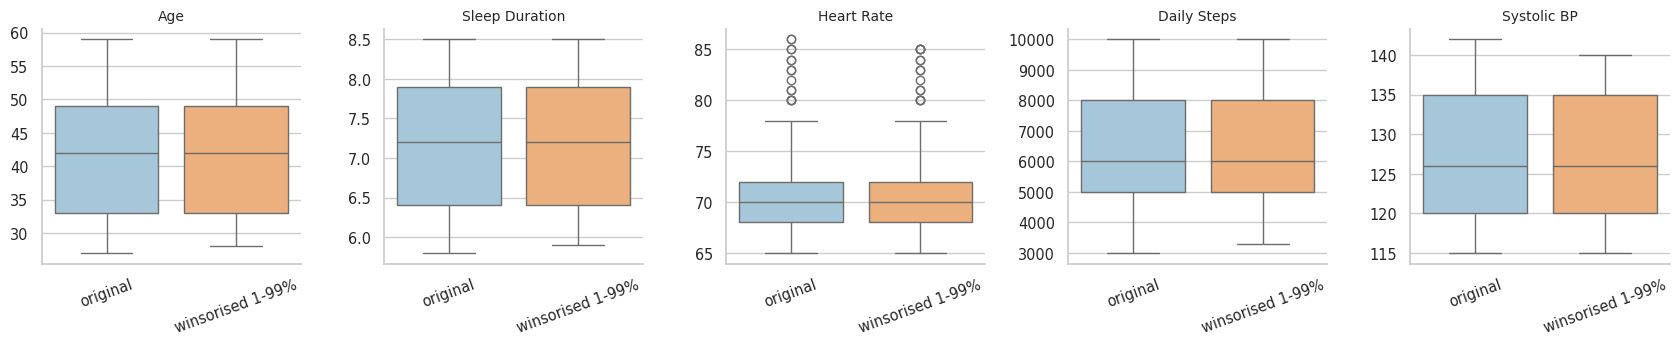

In [ ]:
# How many training values would the clipping change? (thresholds learned on the development rows only)
Fdev = engineer(X_dev)[out_num]
affected = []
for q in [(0.01, 0.99), (0.05, 0.95)]:
    clipper = Winsorizer(*q).fit(Fdev)
    changed = (clipper.transform(Fdev) != Fdev.values)
    affected.append(pd.Series(changed.sum(axis=0), index=out_num, name=f"values changed {q}"))
affected = pd.concat(affected, axis=1); affected.loc["TOTAL"] = affected.sum(); display(affected)

clipper = Winsorizer(0.01, 0.99).fit(Fdev)
Fclip = pd.DataFrame(clipper.transform(Fdev), columns=out_num, index=Fdev.index)
changed_cols = [c for c in out_num if (Fclip[c] != Fdev[c]).any()]
if changed_cols:
    fig, axes = plt.subplots(1, len(changed_cols), figsize=(3.4 * len(changed_cols), 3.6), squeeze=False)
    for ax, c in zip(axes[0], changed_cols):
        sns.boxplot(data=pd.DataFrame({"original": Fdev[c], "winsorised 1-99%": Fclip[c]}), ax=ax, palette=["#9ecae1", "#fdae6b"]); ax.set_title(c, fontsize=10); ax.tick_params(axis="x", rotation=20)
    savefig("outliers_before_after.png")

In [ ]:
decisions = []
for mname in models_out:
    sub = outlier_cmp[(outlier_cmp.model == mname) & (outlier_cmp.variant != first_variant)]
    clip_helps = bool(((sub["delta vs A"] > 0) & sub["|delta| > 2 SE"] & sub.variant.str.contains("winsorise")).any())
    decisions.append({"model": mname, "clip_helps": clip_helps, "best_delta": sub["delta vs A"].max(), "worst_delta": sub["delta vs A"].min()})
decisions = pd.DataFrame(decisions); display(decisions)

# DECISION RULE: clip only if it clearly helps (> 2 SE) for at least two of the three models
CLIP_CHOICE = (0.01, 0.99) if decisions.clip_helps.sum() >= 2 else None
n_valid = int(cls_counts.get("Valid extreme observation", 0)) + int(cls_counts.get("Unusually distributed but meaningful observation", 0))
say(f"""**Outlier decision (evidence-based).**
* **Detection:** {int(outl['n_outliers (1.5 IQR)'].sum())} feature-value flags across {len(flagged_feats)} features; **{int(plaus.n_outside_hard.sum())} impossible values**, {int(plaus.n_outside_typical.sum())} values outside the analyst-defined typical screens, **{sum(coherence.values())} coherence failures**.
* **Classification:** {n_valid} of {len(items)} flags are valid extremes or meaningful clustered values; uncertain: {int(cls_counts.get('Uncertain - requires further investigation', 0))}; potential entry errors: {int(cls_counts.get('Potential data-entry error (isolated + multivariate anomaly) - verify at source', 0))}.
* **Treatment test:** winsorising / robust scaling changes macro-F1 by {decisions.worst_delta.min():+.3f} to {decisions.best_delta.max():+.3f} versus keeping values; clipping clearly helped (>2 SE) for {int(decisions.clip_helps.sum())} of {len(decisions)} models.
* **Decision:** **{'apply learned 1%-99% winsorisation inside the pipeline' if CLIP_CHOICE else 'RETAIN all original values — no clipping, no row removal, no log transform'}.** {'' if CLIP_CHOICE else 'The extremes are plausible, repeated, internally consistent measurements; capping them changes the data without a measurable benefit and discards information.'}
* The `Winsorizer` is fitted per fold, so it could be switched on for future data without leakage.""")

,model,clip_helps,best_delta,worst_delta
0,Logistic Regression,False,0.0031,-0.0060
1,SVM,False,0.0138,-0.0013
2,Random Forest,False,0.0000,-0.0083


**Outlier decision (evidence-based).**
* **Detection:** 14 feature-value flags across 1 features; **0 impossible values**, 0 values outside the analyst-defined typical screens, **0 coherence failures**.
* **Classification:** 12 of 14 flags are valid extremes or meaningful clustered values; uncertain: 0; potential entry errors: 2.
* **Treatment test:** winsorising / robust scaling changes macro-F1 by -0.008 to +0.014 versus keeping values; clipping clearly helped (>2 SE) for 0 of 3 models.
* **Decision:** **RETAIN all original values — no clipping, no row removal, no log transform.** The extremes are plausible, repeated, internally consistent measurements; capping them changes the data without a measurable benefit and discards information.
* The `Winsorizer` is fitted per fold, so it could be switched on for future data without leakage.

## Phase 7 — Cleaning, feature engineering, leakage audit and feature selection

In [ ]:
# 7.1 Cleaning: raw and cleaned versions side by side. Duplicates are NOT dropped (see Phase 4).
clean_all = engineer(X_all)
clean_all.insert(0, "row_id", X_all.index)
print("RAW:", raw.shape, "| CLEANED modelling table:", clean_all.shape, "| rows removed: 0")
display(clean_all.head())

bp_audit = raw["Blood Pressure"].value_counts().rename_axis("raw text").to_frame("rows")
bp_audit[["SBP", "DBP"]] = [parse_bp(s) for s in bp_audit.index]
print("Blood-pressure parsing: %d distinct texts, %d unparsable, %d with systolic<=diastolic" % (len(bp_audit), bp_audit.SBP.isna().sum(), (bp_audit.SBP <= bp_audit.DBP).sum()))
display(bp_audit.head(8))
assert clean_all[["Systolic BP", "Diastolic BP"]].notna().all().all()

fe_table = pd.DataFrame([
  ["Systolic BP / Diastolic BP", "Parsed from 'SYS/DIA'", "Available at prediction time", "No - derived from predictors only"],
  ["BMI Ordinal", "Underweight<Normal<Overweight<Obese", "Yes", "No"],
  ["Pulse Pressure", "SBP - DBP", "Yes", "No"],
  ["Mean Arterial Pressure", "(SBP + 2 DBP) / 3", "Yes", "No"],
  ["Age group (analysis only)", "<35, 35-44, 45-54, 55+", "Yes", "Not used in models (discretising loses information; trees can split on Age)"],
  ["Sleep-quality / duration ratios, steps x activity, ...", "Rejected", "-", "Rejected as arbitrary: no domain rationale and extra collinearity"]],
  columns=["Feature", "Definition", "Available at prediction?", "Leakage check"])
display(fe_table)

RAW: (374, 13) | CLEANED modelling table: (374, 15) | rows removed: 0


,row_id,Gender,Occupation,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic BP,Diastolic BP,BMI Ordinal,Pulse Pressure,Mean Arterial Pressure
0,0,Male,Software Engineer,27.0000,6.1000,6.0000,42.0000,6.0000,77.0000,"4,200.0000",126.0000,83.0000,2.0000,43.0000,97.3333
1,1,Male,Doctor,28.0000,6.2000,6.0000,60.0000,8.0000,75.0000,"10,000.0000",125.0000,80.0000,1.0000,45.0000,95.0000
2,2,Male,Doctor,28.0000,6.2000,6.0000,60.0000,8.0000,75.0000,"10,000.0000",125.0000,80.0000,1.0000,45.0000,95.0000
3,3,Male,Salesperson,28.0000,5.9000,4.0000,30.0000,8.0000,85.0000,"3,000.0000",140.0000,90.0000,3.0000,50.0000,106.6667
4,4,Male,Salesperson,28.0000,5.9000,4.0000,30.0000,8.0000,85.0000,"3,000.0000",140.0000,90.0000,3.0000,50.0000,106.6667


Blood-pressure parsing: 25 distinct texts, 0 unparsable, 0 with systolic<=diastolic


,rows,SBP,DBP
raw text,,,
130/85,99,130.0000,85.0000
140/95,65,140.0000,95.0000
125/80,65,125.0000,80.0000
120/80,45,120.0000,80.0000
115/75,32,115.0000,75.0000
135/90,27,135.0000,90.0000
140/90,4,140.0000,90.0000
125/82,4,125.0000,82.0000


,Feature,Definition,Available at prediction?,Leakage check
0,Systolic BP / Diastolic BP,Parsed from 'SYS/DIA',Available at prediction time,No - derived from predictors only
1,BMI Ordinal,Underweight<Normal<Overweight<Obese,Yes,No
2,Pulse Pressure,SBP - DBP,Yes,No
3,Mean Arterial Pressure,(SBP + 2 DBP) / 3,Yes,No
4,Age group (analysis only),"<35, 35-44, 45-54, 55+",Yes,Not used in models (discretising loses informa...
5,"Sleep-quality / duration ratios, steps x activ...",Rejected,-,Rejected as arbitrary: no domain rationale and...


### 7.2 Leakage audit
Three experiments measure the leakage risks that *can* be measured; the others are verified by construction and by an explicit **fold-isolation check**.

* **Experiment A** — would the identifier `Person ID` leak?
* **Experiment B** — how much do results depend on suspicious feature groups (feature-set ablation)?
* **Experiment C** — how much does an ordinary random CV inflate scores compared with the group CV?

In [ ]:
# Experiment A: identifier leakage. Person ID follows the Age ordering, so it is a positional proxy.
F_dev = engineer(X_dev)
F_dev_id = F_dev.assign(**{"Person ID": raw.loc[X_dev.index, "Person ID"].values})

def simple_pipe(estimator, cols, cat=("Gender", "Occupation")):
    return Pipeline([("prep", make_preprocessor(list(cols), list(cat), None)), ("clf", estimator)])

base_cols = list(NUM_MODEL_COLS)
idr = {}
for nm, make_model in {"Decision Tree": lambda: DecisionTreeClassifier(min_samples_leaf=3, random_state=SEED),
                       "Random Forest": lambda: RandomForestClassifier(150, min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS)}.items():
    for flag, frame, cols in [("without Person ID", F_dev, base_cols), ("WITH Person ID", F_dev_id, base_cols + ["Person ID"])]:
        idr[(nm, flag)] = evaluate(simple_pipe(make_model(), cols), frame, y_dev, DEV_SPLITS, name=f"{nm} {flag}")
leakA = pd.DataFrame([{"model": k[0], "features": k[1], "OOF macro F1": v["pooled"].macro_f1, "CV mean": v["fold_df"].macro_f1.mean()} for k, v in idr.items()])
display(leakA)

,model,features,OOF macro F1,CV mean
0,Decision Tree,without Person ID,0.8072,0.8029
1,Decision Tree,WITH Person ID,0.7607,0.7264
2,Random Forest,without Person ID,0.8659,0.8571
3,Random Forest,WITH Person ID,0.8593,0.8487


,model,feature set,OOF macro F1,OOF balanced acc,CV std,recall Insomnia,recall Apnea
0,Logistic Regression,All features (default),0.8594,0.8728,0.0597,0.8710,0.8389
1,Logistic Regression,No derived BP features,0.8547,0.8685,0.0489,0.8710,0.8278
2,Logistic Regression,No Occupation,0.8310,0.8596,0.1250,0.8871,0.8556
3,Logistic Regression,"No sleep metrics (Sleep Duration, Quality of S...",0.8530,0.8666,0.0544,0.8710,0.8222
4,Logistic Regression,"No cardiovascular (BP, Heart Rate)",0.8373,0.8497,0.0427,0.8871,0.7611
5,Logistic Regression,No BMI,0.8594,0.8728,0.0598,0.8710,0.8389
6,Random Forest,All features (default),0.8658,0.8659,0.0590,0.8656,0.7778
7,Random Forest,No derived BP features,0.8659,0.8659,0.0441,0.8602,0.7833
8,Random Forest,No Occupation,0.8788,0.8788,0.0557,0.8710,0.8111
9,Random Forest,"No sleep metrics (Sleep Duration, Quality of S...",0.8641,0.8642,0.0504,0.8548,0.7833


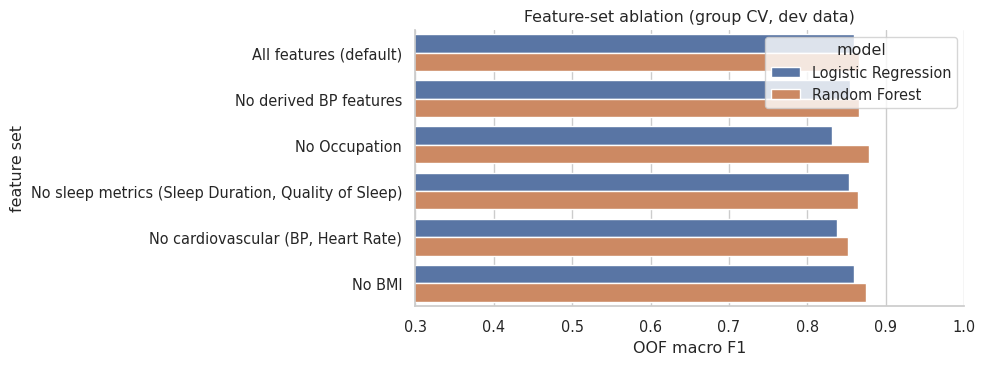

In [ ]:
# Experiment B: feature-set ablation under group CV (does any feature family carry the result?)
ablate = {"All features (default)": {},
          "No derived BP features": dict(add_derived=False),
          "No Occupation": dict(include_occupation=False),
          "No sleep metrics (Sleep Duration, Quality of Sleep)": dict(drop_columns=("Sleep Duration", "Quality of Sleep")),
          "No cardiovascular (BP, Heart Rate)": dict(drop_columns=("Systolic BP", "Diastolic BP", "Pulse Pressure", "Mean Arterial Pressure", "Heart Rate")),
          "No BMI": dict(drop_columns=("BMI Ordinal",))}
abl_models = {"Logistic Regression": (lambda: LogisticRegression(max_iter=3000, class_weight="balanced"), "standard"),
              "Random Forest": (lambda: RandomForestClassifier(150, class_weight="balanced", min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS), None)}

abl_rows, abl_res = [], {}
for mname, (make_model, scaler) in abl_models.items():
    for aname, opts in ablate.items():
        r = evaluate(make_pipeline(make_model(), scaler=scaler, clip=CLIP_CHOICE, **opts), X_dev, y_dev, DEV_SPLITS, name=f"{mname} | {aname}")
        abl_res[(mname, aname)] = r
        abl_rows.append({"model": mname, "feature set": aname, "OOF macro F1": r["pooled"].macro_f1, "OOF balanced acc": r["pooled"].balanced_accuracy,
                         "CV std": r["fold_df"].macro_f1.std(), "recall Insomnia": r["pooled"].recall_Insomnia, "recall Apnea": r["pooled"]["recall_Sleep Apnea"]})
ablation = pd.DataFrame(abl_rows); display(ablation); ablation.to_csv(OUTPUTS_DIR / "feature_set_ablation.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 3.8)); sns.barplot(data=ablation, y="feature set", x="OOF macro F1", hue="model", ax=ax)
ax.set_xlim(0.3, 1); ax.set_title("Feature-set ablation (group CV, dev data)"); savefig("leakage_ablation.png")

In [ ]:
# Experiment C: ordinary random stratified CV versus the group CV (same pipelines, same number of folds)
def make_random_splits(X, y, n_repeats=3, n_splits=5, base_seed=SEED):
    return [(r, k, tr, va) for r in range(n_repeats)
            for k, (tr, va) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=base_seed + r).split(X, y))]
RAND_SPLITS = make_random_splits(X_dev, y_dev, n_repeats=1 if FAST_MODE else 3)

infl = []
for mname, (make_model, scaler) in abl_models.items():
    rand_res = evaluate(make_pipeline(make_model(), scaler=scaler, clip=CLIP_CHOICE), X_dev, y_dev, RAND_SPLITS, name=mname + " random-CV")
    group_res = abl_res[(mname, "All features (default)")]
    infl.append({"model": mname, "macro F1 random CV": rand_res["pooled"].macro_f1, "macro F1 group CV": group_res["pooled"].macro_f1,
                 "inflation (random - group)": rand_res["pooled"].macro_f1 - group_res["pooled"].macro_f1,
                 "accuracy random": rand_res["pooled"].accuracy, "accuracy group": group_res["pooled"].accuracy})
infl = pd.DataFrame(infl); display(infl)

,model,macro F1 random CV,macro F1 group CV,inflation (random - group),accuracy random,accuracy group
0,Logistic Regression,0.8752,0.8594,0.0158,0.8990,0.8866
1,Random Forest,0.8871,0.8658,0.0213,0.9147,0.9001


In [ ]:
# Fold-isolation check: every learned transformation must be fitted on the TRAINING rows of a fold only
r_, k_, tr_, va_ = DEV_SPLITS[0]
probe = make_pipeline(RandomForestClassifier(50, random_state=SEED), scaler="standard", clip=(0.01, 0.99),
                      select=SelectKBest(functools.partial(mutual_info_classif, random_state=SEED), k=10)).fit(X_dev.iloc[tr_], y_dev.iloc[tr_])
num_pipe = probe.named_steps["prep"].named_transformers_["num"]
F_tr = engineer(X_dev.iloc[tr_])
cols_num = probe.named_steps["prep"].transformers_[0][2]
checks = {
 "imputer medians == training-fold medians": np.allclose(num_pipe["impute"].statistics_, F_tr[cols_num].median().values),
 "scaler saw exactly the training-fold rows": int(num_pipe["scale"].n_samples_seen_) == len(tr_),
 "clipper quantiles == training-fold quantiles": np.allclose(num_pipe["clip"].lower_, np.nanquantile(F_tr[cols_num].astype(float).fillna(F_tr[cols_num].median()).values, 0.01, axis=0)),
 "one-hot categories come from training rows only": set(probe.named_steps["prep"].named_transformers_["cat"]["onehot"].categories_[1]) == set(F_tr["Occupation"].dropna().unique()),
 "feature selector fitted on training rows (n_features_in_ matches)": probe.named_steps["select"].n_features_in_ == probe.named_steps["prep"].get_feature_names_out().shape[0],
 "no profile group straddles train / validation": not (set(g_dev[tr_]) & set(g_dev[va_])),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "Fold isolation violated"

,passed
imputer medians == training-fold medians,True
scaler saw exactly the training-fold rows,True
clipper quantiles == training-fold quantiles,True
one-hot categories come from training rows only,True
feature selector fitted on training rows (n_features_in_ matches),True
no profile group straddles train / validation,True


In [ ]:
# Summary of the leakage audit
inflA = leakA.pivot(index="model", columns="features", values="OOF macro F1")
a_delta = (inflA["WITH Person ID"] - inflA["without Person ID"]).round(3).to_dict()
b_all = ablation[ablation["feature set"] == "All features (default)"].set_index("model")["OOF macro F1"]
b_nosleep = ablation[ablation["feature set"].str.startswith("No sleep")].set_index("model")["OOF macro F1"]

leak_table = pd.DataFrame([
 ["Direct target leakage", "PASS", "No predictor is derived from Sleep Disorder; all 11 raw predictors are intake-type measurements."],
 ["Indirect target leakage", "PASS WITH LIMITATION", "Sleep Duration / Quality of Sleep are plausible *consequences* of the disorders. Macro-F1 without them: " + ", ".join(f"{k} {b_nosleep[k]:.3f} (default {b_all[k]:.3f})" for k in b_all.index) + ". Kept as predictors, flagged as symptom-adjacent."],
 ["Duplicate observations across partitions", "PASS", "0 shared profile groups / exact vectors / near-duplicates between development and test (Phase 4); group-aware CV inside development."],
 ["Identifier-based leakage", "PASS", f"Person ID excluded. Change in OOF macro-F1 if it were included: {a_delta}."],
 ["Target-derived features", "PASS", "None created (feature table above)."],
 ["Feature-selection leakage", "PASS", "SelectKBest / SelectFromModel are pipeline steps; fold-isolation check passed."],
 ["Imputation / scaling / encoding leakage", "PASS", "All fitted inside Pipeline + ColumnTransformer; statistics equal training-fold statistics (check above)."],
 ["Resampling leakage", "PASS", "imblearn Pipeline (Phase 10): samplers act only while fitting, never on validation rows."],
 ["Outlier-threshold leakage", "PASS", "Winsorizer thresholds learned per training fold (check above); CLIP_CHOICE=%s." % (CLIP_CHOICE,)],
 ["Hyper-parameter-selection leakage", "PASS", "Tuning uses development CV only; nested CV estimates the effect of tuning; test partition locked until Phase 16 (access log at the end)."],
 ["Validation-design leakage (random CV)", "QUANTIFIED", "Random-CV minus group-CV macro-F1: " + ", ".join(f"{r.model} {r['inflation (random - group)']:+.3f}" for _, r in infl.iterrows()) + "."],
], columns=["Leakage type", "Status", "Evidence"])
display(leak_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
leak_table.to_csv(OUTPUTS_DIR / "leakage_audit.csv", index=False)

,Leakage type,Status,Evidence
0,Direct target leakage,PASS,No predictor is derived from Sleep Disorder; all 11 raw predictors are intake-type measurements.
1,Indirect target leakage,PASS WITH LIMITATION,"Sleep Duration / Quality of Sleep are plausible *consequences* of the disorders. Macro-F1 without them: Logistic Regression 0.853 (default 0.859), Random Forest 0.864 (default 0.866). Kept as predictors, flagged as symptom-adjacent."
2,Duplicate observations across partitions,PASS,0 shared profile groups / exact vectors / near-duplicates between development and test (Phase 4); group-aware CV inside development.
3,Identifier-based leakage,PASS,"Person ID excluded. Change in OOF macro-F1 if it were included: {'Decision Tree': -0.046, 'Random Forest': -0.007}."
4,Target-derived features,PASS,None created (feature table above).
5,Feature-selection leakage,PASS,SelectKBest / SelectFromModel are pipeline steps; fold-isolation check passed.
6,Imputation / scaling / encoding leakage,PASS,All fitted inside Pipeline + ColumnTransformer; statistics equal training-fold statistics (check above).
7,Resampling leakage,PASS,"imblearn Pipeline (Phase 10): samplers act only while fitting, never on validation rows."
8,Outlier-threshold leakage,PASS,Winsorizer thresholds learned per training fold (check above); CLIP_CHOICE=None.
9,Hyper-parameter-selection leakage,PASS,Tuning uses development CV only; nested CV estimates the effect of tuning; test partition locked until Phase 16 (access log at the end).


### 7.3 Feature selection and multicollinearity
First an analysis (mutual information, ANOVA F, VIF); the *actual* selection happens inside cross-validation.

,Mutual information,ANOVA F,VIF
Mean Arterial Pressure,0.5716,229.0375,0.7665
Systolic BP,0.5507,201.0786,0.3526
Diastolic BP,0.5394,236.2155,1.2617
Sleep Duration,0.5343,26.8651,5.6190
Age,0.4921,40.5340,5.3149
Daily Steps,0.4649,11.7759,5.5544
Physical Activity Level,0.4070,35.2294,5.5567
BMI Ordinal,0.3937,237.7179,5.7711
Heart Rate,0.3086,17.9509,3.8913
Stress Level,0.3064,3.1027,11.8439


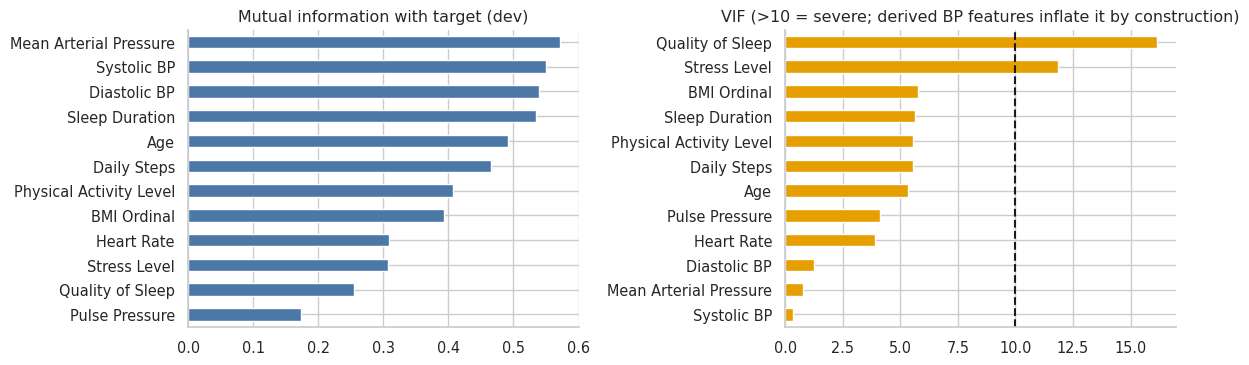

In [ ]:
Fnum = engineer(X_dev)[NUM_MODEL_COLS].astype(float)
Fnum = Fnum.fillna(Fnum.median())

corr_p = Fnum.corr()
vif = pd.Series(np.diag(np.linalg.pinv(corr_p.values)), index=corr_p.index, name="VIF").sort_values(ascending=False)       # variance inflation factor
mi = pd.Series(mutual_info_classif(Fnum, y_dev, discrete_features=False, random_state=SEED), index=NUM_MODEL_COLS, name="Mutual information").sort_values(ascending=False)
anova_f = pd.Series(f_classif(Fnum, y_dev)[0], index=NUM_MODEL_COLS, name="ANOVA F").loc[mi.index]
fs_table = pd.concat([mi, anova_f, vif.loc[mi.index]], axis=1); display(fs_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
mi.sort_values().plot.barh(ax=axes[0], color="#4C78A8"); axes[0].set_title("Mutual information with target (dev)")
vif.sort_values().plot.barh(ax=axes[1], color="#E69F00"); axes[1].axvline(10, color="k", ls="--"); axes[1].set_title("VIF (>10 = severe; derived BP features inflate it by construction)")
savefig("feature_mi_vif.png")

In [ ]:
# Selection options evaluated INSIDE the cross-validation
mi_select = lambda k: SelectKBest(functools.partial(mutual_info_classif, random_state=SEED), k=k)
sel_options = {"none": None, "MI top-6": mi_select(6), "MI top-10": mi_select(10), "MI top-15": mi_select(15),
               "RF importance >= median": SelectFromModel(RandomForestClassifier(100, random_state=SEED), threshold="median")}
sel_rows = []
for mname, (make_model, scaler) in abl_models.items():
    for sname, selector in sel_options.items():
        r = evaluate(make_pipeline(make_model(), scaler=scaler, clip=CLIP_CHOICE, select=selector), X_dev, y_dev, DEV_SPLITS, name=f"{mname}|{sname}")
        sel_rows.append({"model": mname, "selection (inside CV)": sname, "OOF macro F1": r["pooled"].macro_f1, "CV std": r["fold_df"].macro_f1.std()})
sel_df = pd.DataFrame(sel_rows)
display(sel_df.pivot(index="selection (inside CV)", columns="model", values="OOF macro F1"))
best_sel = sel_df.sort_values("OOF macro F1", ascending=False).iloc[0]
say("**Reading.** Highest mutual information: " + ", ".join(f"*{c}* ({v:.2f})" for c, v in mi.head(4).items()) +
    f". VIF > 10 for {int((vif>10).sum())} features ({', '.join(vif[vif>10].index[:5])}) — expected, because systolic/diastolic/pulse/mean-arterial pressure are algebraically linked. "
    f"No feature is dropped merely for being correlated. Best selection setting in CV: {best_sel['model']} with '{best_sel['selection (inside CV)']}' = {best_sel['OOF macro F1']:.3f} "
    f"(range {sel_df['OOF macro F1'].min():.3f}-{sel_df['OOF macro F1'].max():.3f}). Selection therefore stays a *tunable pipeline option* in Phase 12.")

model,Logistic Regression,Random Forest
selection (inside CV),,
MI top-10,0.8091,0.8750
MI top-15,0.8594,0.8788
MI top-6,0.7921,0.8638
RF importance >= median,0.8183,0.8676
none,0.8594,0.8658


**Reading.** Highest mutual information: *Mean Arterial Pressure* (0.57), *Systolic BP* (0.55), *Diastolic BP* (0.54), *Sleep Duration* (0.53). VIF > 10 for 2 features (Quality of Sleep, Stress Level) — expected, because systolic/diastolic/pulse/mean-arterial pressure are algebraically linked. No feature is dropped merely for being correlated. Best selection setting in CV: Random Forest with 'MI top-15' = 0.879 (range 0.792-0.879). Selection therefore stays a *tunable pipeline option* in Phase 12.

## Phase 8 — Baseline model

A baseline defines the score any real model must beat; without it, "85 % accuracy" means nothing. With a 59 % majority class, a classifier that always says *None* already scores 59 % accuracy but finds **no** disorder at all. All numbers below use the same repeated group-aware CV as every other model (out-of-fold predictions, averaged over repeats).

In [ ]:
baseline_specs = {"Baseline: most frequent": DummyClassifier(strategy="most_frequent"),
                  "Baseline: stratified random": DummyClassifier(strategy="stratified", random_state=SEED),
                  "Baseline: uniform random": DummyClassifier(strategy="uniform", random_state=SEED)}
baseline_res = {n: evaluate(make_pipeline(e, scaler=None), X_dev, y_dev, DEV_SPLITS, name=n) for n, e in baseline_specs.items()}

bl_export = pd.DataFrame([{"Model": n, "Accuracy": r["pooled"].accuracy, "Balanced Accuracy": r["pooled"].balanced_accuracy, "Macro Precision": r["pooled"].macro_precision,
                           "Macro Recall": r["pooled"].macro_recall, "Macro F1": r["pooled"].macro_f1, "Weighted F1": r["pooled"].weighted_f1}
                          for n, r in baseline_res.items()]).set_index("Model")
display(bl_export); bl_export.to_csv(OUTPUTS_DIR / "baseline_comparison.csv")

BASELINE_RES = baseline_res["Baseline: most frequent"]
say(f"**Reading.** The majority-class baseline reaches accuracy {BASELINE_RES['pooled'].accuracy:.3f} but balanced accuracy {BASELINE_RES['pooled'].balanced_accuracy:.3f} and macro-F1 {BASELINE_RES['pooled'].macro_f1:.3f} "
    "(recall 0 for both disorders). Any useful model must clearly beat these, especially on macro-F1 / balanced accuracy.")

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,,
Baseline: most frequent,0.5892,0.3333,0.1964,0.3333,0.2472,0.4369
Baseline: stratified random,0.4579,0.3471,0.3503,0.3471,0.3468,0.4478
Baseline: uniform random,0.3086,0.3208,0.3195,0.3208,0.2939,0.3274


**Reading.** The majority-class baseline reaches accuracy 0.589 but balanced accuracy 0.333 and macro-F1 0.247 (recall 0 for both disorders). Any useful model must clearly beat these, especially on macro-F1 / balanced accuracy.

## Phase 9 — Train eight classification models (≥ 5 required)

Eight algorithms are **trained and cross-validated** with the same repeated, group-aware CV: Decision Tree, Random Forest, Logistic Regression, SVM, K-Nearest Neighbours, Extra Trees, HistGradientBoosting and XGBoost. Default (untuned) settings are used here so that Phase 12 can show a genuine *before / after tuning* contrast. Scale-sensitive models (LR, SVM, KNN) get a `StandardScaler`; tree models do not.

In [ ]:
# name -> (function that builds the classifier, scaler to use)
MODEL_SPECS = {
 "Decision Tree":        (lambda: DecisionTreeClassifier(random_state=SEED), None),
 "Random Forest":        (lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=N_JOBS), None),
 "Logistic Regression":  (lambda: LogisticRegression(max_iter=5000), "standard"),
 "SVM":                  (lambda: SVC(probability=True, random_state=SEED), "standard"),
 "K-Nearest Neighbors":  (lambda: LabelEncodedClassifier(KNeighborsClassifier(n_neighbors=5)), "standard"),      # label-encoded: older scikit-learn crashed on text labels in KNN
 "Extra Trees":          (lambda: ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=N_JOBS), None),
 "HistGradientBoosting": (lambda: HistGradientBoostingClassifier(random_state=SEED), None),
}
if XGB_AVAILABLE:
    MODEL_SPECS["XGBoost"] = (lambda: LabelEncodedClassifier(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, eval_metric="mlogloss",
                                                                          n_jobs=N_JOBS, random_state=SEED, tree_method="hist")), None)
LIMITS = {"Decision Tree": "high variance; unstable splits; over-fits duplicates", "Random Forest": "less interpretable; probabilities tend to be under-confident",
          "Logistic Regression": "linear decision boundaries; needs scaling", "SVM": "needs scaling; slow probabilities (internal Platt CV); opaque",
          "K-Nearest Neighbors": "sensitive to scaling/k; no model structure; duplicates make neighbours trivial", "Extra Trees": "randomised splits; opaque",
          "HistGradientBoosting": "many hyper-parameters; can over-fit tiny data", "XGBoost": "extra dependency; many hyper-parameters; can over-fit tiny data"}

def build_default(name, **overrides):
    make_model, scaler = MODEL_SPECS[name]
    return make_pipeline(make_model(), scaler=scaler, clip=CLIP_CHOICE, **overrides)

model_res = {}
for n in MODEL_SPECS:
    t0 = time.perf_counter(); model_res[n] = evaluate(build_default(n), X_dev, y_dev, DEV_SPLITS, name=n)
    print(f"{n:<22s} macro-F1 (OOF) {model_res[n]['pooled'].macro_f1:.3f} | fold mean {model_res[n]['fold_df'].macro_f1.mean():.3f} +/- {model_res[n]['fold_df'].macro_f1.std():.3f} | {time.perf_counter()-t0:5.1f}s")
assert len(model_res) >= 5, "need at least five trained classifiers"

Decision Tree          macro-F1 (OOF) 0.768 | fold mean 0.747 +/- 0.111 |   1.2s
Random Forest          macro-F1 (OOF) 0.825 | fold mean 0.805 +/- 0.093 |  16.6s
Logistic Regression    macro-F1 (OOF) 0.862 | fold mean 0.855 +/- 0.042 |   2.3s
SVM                    macro-F1 (OOF) 0.863 | fold mean 0.853 +/- 0.062 |   1.3s
K-Nearest Neighbors    macro-F1 (OOF) 0.854 | fold mean 0.843 +/- 0.054 |   1.3s
Extra Trees            macro-F1 (OOF) 0.818 | fold mean 0.799 +/- 0.089 |  13.6s
HistGradientBoosting   macro-F1 (OOF) 0.821 | fold mean 0.797 +/- 0.089 |   4.6s
XGBoost                macro-F1 (OOF) 0.813 | fold mean 0.788 +/- 0.087 |   5.3s


In [ ]:
cmp_cols = ["Model", "Accuracy", "Balanced Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "CV Mean", "CV Std"]
default_tab = pd.DataFrame([summary_row(r) for r in [BASELINE_RES] + list(model_res.values())]).set_index("Model")
display(default_tab[cmp_cols[1:]].sort_values("Macro F1", ascending=False))

def clf_settings(name):
    keep = ("random_state", "n_estimators", "max_depth", "n_neighbors", "C", "kernel", "learning_rate", "criterion", "max_iter")
    return str({k.replace("estimator__", ""): v for k, v in build_default(name).named_steps["clf"].get_params().items() if k.replace("estimator__", "") in keep})
detail = pd.DataFrame({"Preprocessing": {n: " -> ".join(s for s, _ in build_default(n).steps) for n in MODEL_SPECS},
                       "Training configuration": {n: clf_settings(n) for n in MODEL_SPECS},
                       "Train macro-F1": default_tab.loc[list(MODEL_SPECS), "Train Macro F1"], "CV (validation) macro-F1": default_tab.loc[list(MODEL_SPECS), "CV Mean"],
                       "Overfit gap": default_tab.loc[list(MODEL_SPECS), "Gap (train-CV)"], "Fit time (s)": default_tab.loc[list(MODEL_SPECS), "Fit Time (s)"],
                       "Limitations": pd.Series(LIMITS)})
display(detail.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
default_tab.to_csv(OUTPUTS_DIR / "model_comparison_default.csv")

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,CV Mean,CV Std
Model,,,,,,,,
SVM,0.8979,0.8670,0.8599,0.8670,0.8626,0.8984,0.8525,0.0618
Logistic Regression,0.8923,0.8711,0.8536,0.8711,0.8617,0.8936,0.8548,0.0418
K-Nearest Neighbors,0.8878,0.8576,0.8515,0.8576,0.8539,0.8880,0.8426,0.0544
Random Forest,0.8664,0.8121,0.8419,0.8121,0.8254,0.8635,0.8052,0.0933
HistGradientBoosting,0.8608,0.8029,0.8444,0.8029,0.8206,0.8573,0.7975,0.0892
Extra Trees,0.8608,0.8052,0.8334,0.8052,0.8178,0.8581,0.7989,0.0892
XGBoost,0.8575,0.7975,0.8327,0.7975,0.8130,0.8539,0.7882,0.0873
Decision Tree,0.8103,0.7649,0.7767,0.7649,0.7675,0.8100,0.7474,0.1108
Baseline: most frequent,0.5892,0.3333,0.1964,0.3333,0.2472,0.4369,0.2472,0.0036


,Preprocessing,Training configuration,Train macro-F1,CV (validation) macro-F1,Overfit gap,Fit time (s),Limitations
Decision Tree,features -> prep -> select -> clf,"{'criterion': 'gini', 'max_depth': None, 'random_state': 42}",0.929717,0.747412,0.182305,0.021712,high variance; unstable splits; over-fits duplicates
Random Forest,features -> prep -> select -> clf,"{'criterion': 'gini', 'max_depth': None, 'n_estimators': 300, 'random_state': 42}",0.930069,0.805209,0.124860,0.774649,less interpretable; probabilities tend to be under-confident
Logistic Regression,features -> prep -> select -> clf,"{'C': 1.0, 'max_iter': 5000, 'random_state': None}",0.918088,0.854761,0.063327,0.066039,linear decision boundaries; needs scaling
SVM,features -> prep -> select -> clf,"{'C': 1.0, 'kernel': 'rbf', 'max_iter': -1, 'random_state': 42}",0.924102,0.852514,0.071588,0.029406,needs scaling; slow probabilities (internal Platt CV); opaque
K-Nearest Neighbors,features -> prep -> select -> clf,{'n_neighbors': 5},0.893138,0.842584,0.050554,0.021852,sensitive to scaling/k; no model structure; duplicates make neighbours trivial
Extra Trees,features -> prep -> select -> clf,"{'criterion': 'gini', 'max_depth': None, 'n_estimators': 300, 'random_state': 42}",0.929717,0.798924,0.130793,0.569311,randomised splits; opaque
HistGradientBoosting,features -> prep -> select -> clf,"{'learning_rate': 0.1, 'max_depth': None, 'max_iter': 100, 'random_state': 42}",0.930023,0.797468,0.132555,0.231122,many hyper-parameters; can over-fit tiny data
XGBoost,features -> prep -> select -> clf,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'random_state': 42}",0.929497,0.788206,0.141291,0.255165,extra dependency; many hyper-parameters; can over-fit tiny data


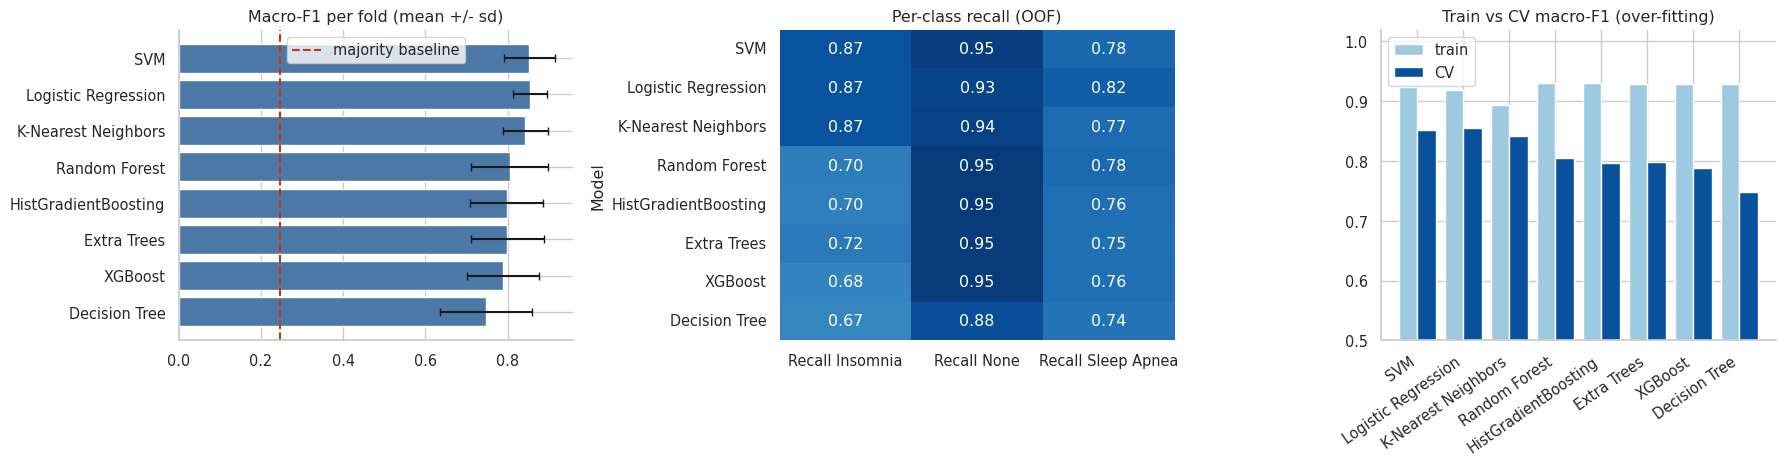

**Reading.** All 8 models beat the majority baseline (macro-F1 0.25). Best untuned macro-F1 (OOF): **SVM** (0.863); weakest: **Decision Tree** (0.768). The spread among the top 4 models (0.037) is comparable to the fold-to-fold standard deviation (~0.088), so small differences are **not** evidence of a better algorithm. Largest train-minus-CV gaps: Decision Tree (+0.18), XGBoost (+0.14), HistGradientBoosting (+0.13) — these flexible models memorise training rows.

In [ ]:
order = default_tab.loc[list(MODEL_SPECS)].sort_values("Macro F1", ascending=False).index.tolist()
sub = default_tab.loc[order]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].barh(order[::-1], sub["CV Mean"][::-1], xerr=sub["CV Std"][::-1], color="#4C78A8", capsize=3)
axes[0].axvline(BASELINE_RES["fold_df"].macro_f1.mean(), color="#CC3311", ls="--", label="majority baseline"); axes[0].legend(); axes[0].set_title("Macro-F1 per fold (mean +/- sd)")
sns.heatmap(sub[["Recall Insomnia", "Recall None", "Recall Sleep Apnea"]], annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False); axes[1].set_title("Per-class recall (OOF)")
x = np.arange(len(order))
axes[2].bar(x - .2, sub["Train Macro F1"], .4, label="train", color="#9ecae1"); axes[2].bar(x + .2, sub["CV Mean"], .4, label="CV", color="#08519c")
axes[2].set_xticks(x); axes[2].set_xticklabels(order, rotation=35, ha="right"); axes[2].legend(); axes[2].set_ylim(0.5, 1.02); axes[2].set_title("Train vs CV macro-F1 (over-fitting)")
savefig("models_default_comparison.png")

best_def = order[0]
say(f"**Reading.** All {len(order)} models beat the majority baseline (macro-F1 {BASELINE_RES['fold_df'].macro_f1.mean():.2f}). Best untuned macro-F1 (OOF): **{best_def}** ({sub.loc[best_def,'Macro F1']:.3f}); weakest: **{order[-1]}** ({sub.loc[order[-1],'Macro F1']:.3f}). "
    f"The spread among the top {min(4, len(order))} models ({sub['Macro F1'].iloc[0]-sub['Macro F1'].iloc[min(3,len(order)-1)]:.3f}) is comparable to the fold-to-fold standard deviation (~{sub['CV Std'].median():.3f}), so small differences are **not** evidence of a better algorithm. "
    "Largest train-minus-CV gaps: " + ", ".join(f"{m} ({sub.loc[m,'Gap (train-CV)']:+.2f})" for m in sub['Gap (train-CV)'].sort_values(ascending=False).index[:3]) + " — these flexible models memorise training rows.")

## Phase 10 — Class-imbalance analysis

Classes are 59 % / 21 % / 21 % (None / Insomnia / Sleep Apnea). Five strategies are compared inside **training folds only**, all with the same imbalanced-learn pipeline (clean → ordinal-encode → [sampler] → scale/one-hot → classifier), so the comparison is like-for-like:

1. no correction · 2. class-weighted training · 3. random over-sampling · 4. random under-sampling · 5. **SMOTE-NC** (the SMOTE variant for mixed numeric/categorical data — plain SMOTE would interpolate between category codes, which is meaningless).

,model,strategy,macro F1,CV std,balanced acc,Insomnia P,Insomnia R,Insomnia F1,Apnea P,Apnea R,Apnea F1,log loss
0,Logistic Regression,none,0.8653,0.0506,0.8748,0.8141,0.8710,0.8416,0.7927,0.8278,0.8098,0.4838
1,Logistic Regression,class_weight,0.8573,0.0618,0.8715,0.8187,0.8710,0.8439,0.7555,0.8389,0.7949,0.5343
2,Logistic Regression,random over-sampling,0.8535,0.0577,0.8677,0.8045,0.8817,0.8411,0.7579,0.8167,0.7861,0.5689
3,Logistic Regression,random under-sampling,0.8492,0.0557,0.8659,0.8146,0.8710,0.8417,0.7316,0.8333,0.7792,0.5231
4,Logistic Regression,SMOTE-NC,0.8595,0.0516,0.8722,0.8229,0.8710,0.8461,0.7663,0.8389,0.8009,0.5854
5,Random Forest,none,0.8218,0.0889,0.8084,0.7813,0.7097,0.7437,0.8353,0.7611,0.7964,1.2099
6,Random Forest,class_weight,0.8254,0.0890,0.8121,0.7944,0.7043,0.7465,0.8334,0.7778,0.8045,1.1874
7,Random Forest,random over-sampling,0.8219,0.0859,0.8082,0.7751,0.7204,0.7466,0.8439,0.7500,0.7939,1.1934
8,Random Forest,random under-sampling,0.8402,0.0680,0.8391,0.7704,0.8172,0.7921,0.8254,0.7611,0.7919,1.3086
9,Random Forest,SMOTE-NC,0.8196,0.0874,0.8095,0.7634,0.7097,0.7355,0.8275,0.7722,0.7988,1.2584


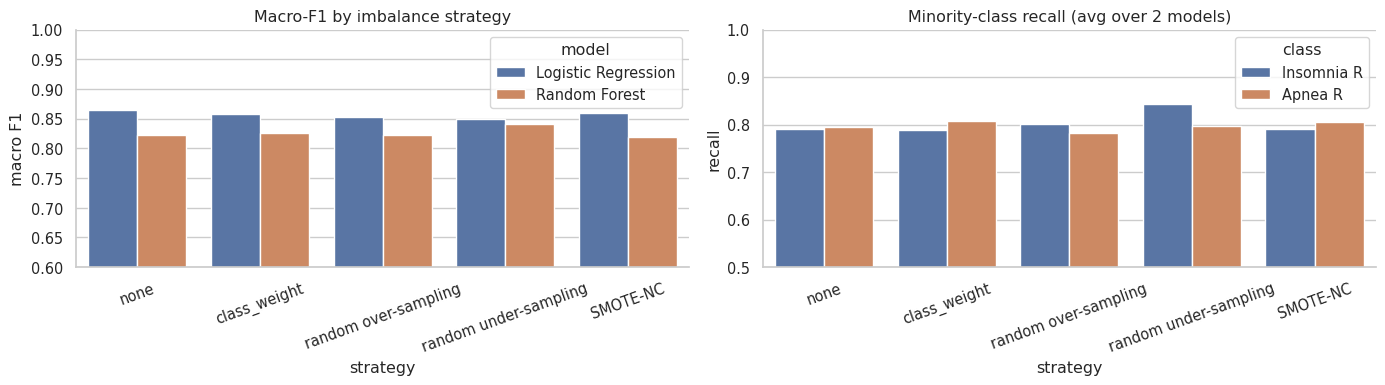

In [ ]:
def make_resampling_pipeline(estimator, sampler=None, scale=False):
    """engineer -> encode (categories as numbers) -> [sampler] -> scale + one-hot -> classifier. The sampler only acts while fitting."""
    num_cols, cat_cols = NUM_MODEL_COLS, ["Gender", "Occupation"]
    n_num, n_cat = len(num_cols), len(cat_cols)
    encode = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols),
                                ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                                  ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), cat_cols)],
                               verbose_feature_names_out=False)
    prep2 = ColumnTransformer([("num", StandardScaler() if scale else "passthrough", list(range(n_num))),
                               ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(range(n_num, n_num + n_cat)))])
    steps = [("features", FunctionTransformer(engineer)), ("encode", encode)]
    if sampler is not None:
        steps.append(("sampler", sampler))
    return ImbPipeline(steps + [("prep2", prep2), ("clf", estimator)])

cat_idx = list(range(len(NUM_MODEL_COLS), len(NUM_MODEL_COLS) + 2))        # positions of the two category columns for SMOTE-NC
strategies = {"none":                  lambda make_clf: (make_clf(None), None),
              "class_weight":          lambda make_clf: (make_clf("balanced"), None),
              "random over-sampling":  lambda make_clf: (make_clf(None), RandomOverSampler(random_state=SEED)),
              "random under-sampling": lambda make_clf: (make_clf(None), RandomUnderSampler(random_state=SEED)),
              "SMOTE-NC":              lambda make_clf: (make_clf(None), SMOTENC(categorical_features=cat_idx, k_neighbors=5, random_state=SEED))}
imb_models = {"Logistic Regression": (lambda cw: LogisticRegression(max_iter=5000, class_weight=cw), True),
              "Random Forest": (lambda cw: RandomForestClassifier(300, class_weight=cw, random_state=SEED, n_jobs=N_JOBS), False)}

def per_class_prf(y_true, oof_pred):
    """Per-class precision / recall / F1 averaged over the CV repeats -> array [3 metrics x 3 classes]."""
    out = []
    for r in range(oof_pred.shape[0]):
        p, rc, f, s = precision_recall_fscore_support(y_true, oof_pred[r], labels=CLASS_ORDER, zero_division=0); out.append(np.vstack([p, rc, f]))
    return np.mean(out, axis=0)

imb_rows, imb_res = [], {}
for mname, (make_clf, use_scale) in imb_models.items():
    for sname, build in strategies.items():
        est, sampler = build(make_clf)
        r = evaluate(make_resampling_pipeline(est, sampler, scale=use_scale), X_dev, y_dev, DEV_SPLITS, name=f"{mname}|{sname}"); imb_res[(mname, sname)] = r
        prf = per_class_prf(y_dev, r["oof_pred"])
        imb_rows.append({"model": mname, "strategy": sname, "macro F1": r["pooled"].macro_f1, "CV std": r["fold_df"].macro_f1.std(), "balanced acc": r["pooled"].balanced_accuracy,
                         "Insomnia P": prf[0, 0], "Insomnia R": prf[1, 0], "Insomnia F1": prf[2, 0], "Apnea P": prf[0, 2], "Apnea R": prf[1, 2], "Apnea F1": prf[2, 2],
                         "log loss": r["pooled"].get("log_loss", np.nan)})
imb_df = pd.DataFrame(imb_rows); display(imb_df)
imb_df.to_csv(OUTPUTS_DIR / "imbalance_strategy_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=imb_df, x="strategy", y="macro F1", hue="model", ax=axes[0]); axes[0].set_ylim(0.6, 1); axes[0].tick_params(axis="x", rotation=20); axes[0].set_title("Macro-F1 by imbalance strategy")
melted = imb_df.melt(id_vars=["model", "strategy"], value_vars=["Insomnia R", "Apnea R"], var_name="class", value_name="recall")
sns.barplot(data=melted, x="strategy", y="recall", hue="class", errorbar=None, ax=axes[1]); axes[1].set_ylim(0.5, 1); axes[1].tick_params(axis="x", rotation=20); axes[1].set_title("Minority-class recall (avg over 2 models)")
savefig("imbalance_comparison.png")

In [ ]:
avg = imb_df.groupby("strategy")[["macro F1", "balanced acc", "Insomnia R", "Apnea R", "Insomnia P", "Apnea P"]].mean().reindex(list(strategies)); display(avg)
se = imb_df["CV std"].mean() / np.sqrt(len(DEV_SPLITS))
best_s = avg["macro F1"].idxmax()
# DECISION RULE: take the SIMPLEST strategy whose macro-F1 is within one standard error of the best
IMBALANCE_CHOICE = next(s for s in strategies if avg.loc[s, "macro F1"] >= avg.loc[best_s, "macro F1"] - se)
say("**Reading.** Averaged over both models, macro-F1 by strategy: " + ", ".join(f"{s} {v:.3f}" for s, v in avg['macro F1'].items()) + f". Best: **{best_s}**. "
    f"The best-to-worst difference is {avg['macro F1'].max()-avg['macro F1'].min():.3f} against a fold-to-fold SE of ~{se:.3f}. **Decision rule:** take the *simplest* strategy within one SE of the best -> **{IMBALANCE_CHOICE}**. "
    "Resampling is not assumed to help; class weighting is also a tunable setting in Phase 12.")

,macro F1,balanced acc,Insomnia R,Apnea R,Insomnia P,Apnea P
strategy,,,,,,
none,0.8436,0.8416,0.7903,0.7944,0.7977,0.8140
class_weight,0.8413,0.8418,0.7876,0.8083,0.8066,0.7944
random over-sampling,0.8377,0.8380,0.8011,0.7833,0.7898,0.8009
random under-sampling,0.8447,0.8525,0.8441,0.7972,0.7925,0.7785
SMOTE-NC,0.8396,0.8408,0.7903,0.8056,0.7931,0.7969


**Reading.** Averaged over both models, macro-F1 by strategy: none 0.844, class_weight 0.841, random over-sampling 0.838, random under-sampling 0.845, SMOTE-NC 0.840. Best: **random under-sampling**. The best-to-worst difference is 0.007 against a fold-to-fold SE of ~0.018. **Decision rule:** take the *simplest* strategy within one SE of the best -> **none**. Resampling is not assumed to help; class weighting is also a tunable setting in Phase 12.

## Phase 11 — Cross-validation and robustness
Design: **5-fold StratifiedGroupKFold × 3 repeats** (15 validation folds) on the development data. With ~60 rows in each minority class, 5 folds leave ~12 minority rows per validation fold; 10 folds would leave ~6 and make per-class scores too noisy. Below: fold-level results, means, standard deviations and model-rank stability. `GroupShuffleSplit` is used as an independent variance check.

Fold-level macro-F1 (rows = repeat, fold):


Decision Tree  Random Forest  Logistic Regression    SVM  K-Nearest Neighbors  Extra Trees  HistGradientBoosting  XGBoost
repeat fold                                                                                                                           
0      0            0.7174         0.8698               0.8904 0.8698               0.8379       0.8698                0.8698   0.8698
       1            0.7790         0.8156               0.8156 0.8156               0.8156       0.8156                0.7832   0.7382
       2            0.6641         0.6415               0.9042 0.9042               0.9042       0.6641                0.6415   0.6641
       3            0.8613         0.8056               0.8215 0.8215               0.8737       0.8056                0.8056   0.8056
       4            0.8708         0.9199               0.8866 0.8866               0.8699       0.9199                0.9387   0.9199
1      0            0.6119         0.7238               0.8127 0.7007               0.7048       0.7007                0.7656   0.8033
       1            0.7790         0.8156               0.8156 0.8156               0.8156       0.8156                0.7832   0.7382
       2            0.6466         0.6641               0.9042 0.9042               0.9042       0.6641                0.6641   0.6641
       3            0.8702         0.8830               0.8429 0.8971               0.8429       0.8418                0.8830   0.8275
       4            0.8576         0.8947               0.9042 0.9530               0.8471       0.8947                0.8267   0.8916
2      0            0.6887         0.8698               0.8033 0.8033               0.7716       0.8033                0.8033   0.8033
       1            0.8156         0.8156               0.8156 0.8156               0.8156       0.8156                0.8237   0.7382
       2            0.6641         0.6415               0.8415 0.9042               0.8874       0.6415                0.6415   0.6415
       3            0.8613         0.8613               0.8433 0.8737               0.8433       0.8752                0.8613   0.8613
       4            0.5234         0.8563               0.9199 0.8225               0.9051       0.8563                0.8708   0.8563

,mean,std,min,max,CV%,mean rank,rank std
Logistic Regression,0.8548,0.0418,0.8033,0.9199,4.8879,3.2333,1.8980
SVM,0.8525,0.0618,0.7007,0.9530,7.2469,3.3333,1.9334
K-Nearest Neighbors,0.8426,0.0544,0.7048,0.9051,6.4616,4.4333,2.4339
Random Forest,0.8052,0.0933,0.6415,0.9199,11.5844,4.2667,1.7307
Extra Trees,0.7989,0.0892,0.6415,0.9199,11.1675,4.5333,1.6952
HistGradientBoosting,0.7975,0.0892,0.6415,0.9387,11.1900,4.6000,2.2055
XGBoost,0.7882,0.0873,0.6415,0.9199,11.0809,5.5333,1.9223
Decision Tree,0.7474,0.1108,0.5234,0.8708,14.8277,6.0667,1.9353


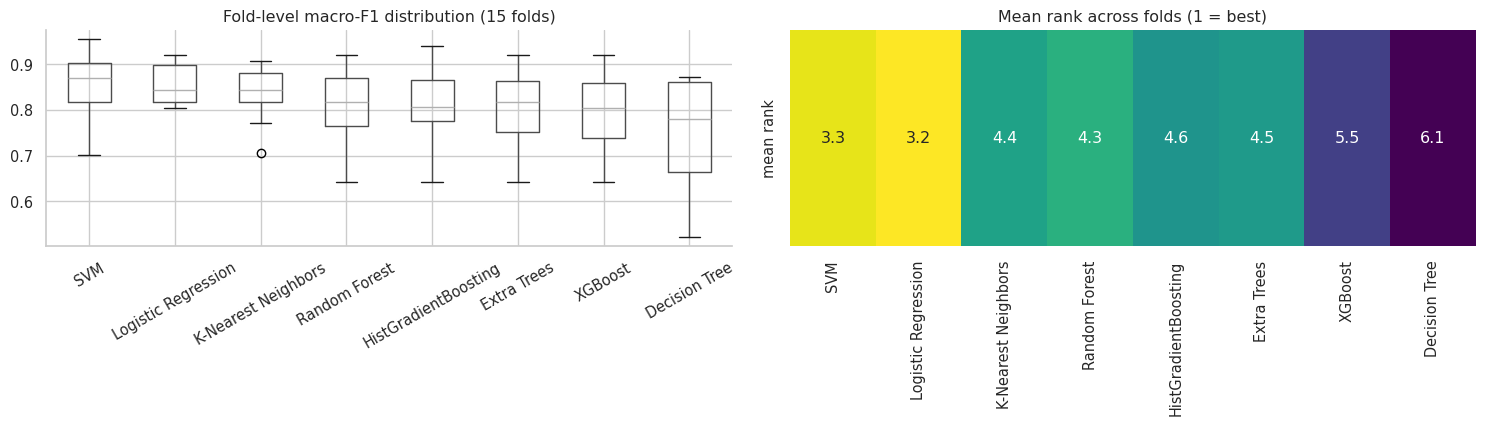

In [ ]:
fold_tab = pd.concat({n: r["fold_df"].set_index(["repeat", "fold"])["macro_f1"] for n, r in model_res.items()}, axis=1)
print("Fold-level macro-F1 (rows = repeat, fold):"); display(fold_tab)

stab = pd.DataFrame({"mean": fold_tab.mean(), "std": fold_tab.std(), "min": fold_tab.min(), "max": fold_tab.max(), "CV%": 100 * fold_tab.std() / fold_tab.mean()})
ranks = fold_tab.rank(axis=1, ascending=False)
stab["mean rank"] = ranks.mean(); stab["rank std"] = ranks.std()
display(stab.sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
fold_tab[order].boxplot(ax=axes[0], rot=30); axes[0].set_title("Fold-level macro-F1 distribution (15 folds)")
sns.heatmap(ranks[order].mean().to_frame("mean rank").T, annot=True, fmt=".1f", cmap="viridis_r", ax=axes[1], cbar=False); axes[1].set_title("Mean rank across folds (1 = best)")
savefig("cv_fold_distribution.png")

In [ ]:
# Independent variance check: 20 random group-wise 80/20 splits (GroupShuffleSplit) on the development data
gss = GroupShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED)
gss_scores = {}
for n in ["Decision Tree", "Random Forest", "Logistic Regression"]:
    scores = []
    for tr, va in gss.split(X_dev, y_dev, g_dev):
        m = clone(build_default(n)).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        scores.append(macro_f1(y_dev.iloc[va], m.predict(X_dev.iloc[va])))
    gss_scores[n] = np.array(scores)
gss_df = pd.DataFrame({n: {"GroupShuffleSplit mean": v.mean(), "GroupShuffleSplit std": v.std(), "min": v.min(), "max": v.max(),
                           "StratifiedGroupKFold mean": fold_tab[n].mean(), "StratifiedGroupKFold std": fold_tab[n].std()} for n, v in gss_scores.items()}).T
display(gss_df)
say(f"**Reading.** The two group-aware schemes agree within {np.abs(gss_df['GroupShuffleSplit mean']-gss_df['StratifiedGroupKFold mean']).max():.3f} macro-F1, but individual ~20 % hold-outs vary widely "
    f"(GroupShuffleSplit std up to {gss_df['GroupShuffleSplit std'].max():.3f}; min/max {gss_df['min'].min():.2f}-{gss_df['max'].max():.2f}). "
    "**A single test split of ~75 rows can therefore swing by this much**, so the final test result must be read with an interval (Phase 16) and the repeated-CV / nested-CV numbers carry more weight than any single split.")

,GroupShuffleSplit mean,GroupShuffleSplit std,min,max,StratifiedGroupKFold mean,StratifiedGroupKFold std
Decision Tree,0.7458,0.1435,0.3692,0.9255,0.7474,0.1108
Random Forest,0.7917,0.1343,0.5282,1.0000,0.8052,0.0933
Logistic Regression,0.8159,0.1145,0.5432,1.0000,0.8548,0.0418


**Reading.** The two group-aware schemes agree within 0.039 macro-F1, but individual ~20 % hold-outs vary widely (GroupShuffleSplit std up to 0.144; min/max 0.37-1.00). **A single test split of ~75 rows can therefore swing by this much**, so the final test result must be read with an interval (Phase 16) and the repeated-CV / nested-CV numbers carry more weight than any single split.

## Phase 12 — Hyper-parameter tuning (with nested cross-validation)

* **Search CV:** `GroupCV(5)` on the development data with a *different seed* from the evaluation CV; scoring = **macro-F1** (so minority classes count equally).
* **Search spaces** include `class_weight` (imbalance), the feature-selection step (`passthrough` / mutual-information top-8 / top-14, fitted inside each training fold) and, for scale-sensitive models, the scaler.
* **Decision Tree, Logistic Regression and KNN** use an exhaustive `GridSearchCV`; the other models use `RandomizedSearchCV`.
* **Nested CV** (outer 5 folds × inner 3-fold search) estimates what a *tuned* model really achieves on unseen groups, because the best score of a search is optimistically biased. The test partition is not touched.

In [ ]:
   SCALERS = [StandardScaler(), RobustScaler()]
SEL = ["passthrough", mi_select(8), mi_select(14)]
def budget(n):
    return max(3, n // 5) if FAST_MODE else n

TUNE_SPECS = {
 "Decision Tree": dict(est=lambda: DecisionTreeClassifier(random_state=SEED), scaler=None, kind="grid", n_iter=None, nested_iter=budget(40),
    space={"clf__criterion": ["gini", "entropy"], "clf__max_depth": [2, 3, 4, 5, 6, 8, None], "clf__min_samples_split": [2, 5, 10, 20],
           "clf__min_samples_leaf": [1, 2, 5, 10], "clf__class_weight": [None, "balanced"]}),
 "Random Forest": dict(est=lambda: RandomForestClassifier(random_state=SEED, n_jobs=1), scaler=None, kind="random", n_iter=budget(30), nested_iter=budget(12),
    space={"clf__n_estimators": [200, 400, 600], "clf__max_depth": [3, 5, 8, 12, None], "clf__min_samples_split": [2, 5, 10], "clf__min_samples_leaf": [1, 2, 4, 8],
           "clf__max_features": ["sqrt", "log2", 0.5, None], "clf__class_weight": [None, "balanced", "balanced_subsample"], "select": SEL}),
 "Logistic Regression": dict(est=lambda: LogisticRegression(max_iter=5000), scaler="standard", kind="grid", n_iter=None, nested_iter=budget(20),
    space={"clf__C": [0.01, 0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"], "select": SEL, "prep__num__scale": SCALERS}),
 "SVM": dict(est=lambda: SVC(probability=True, random_state=SEED), scaler="standard", kind="random", n_iter=budget(30), nested_iter=budget(12),
    space={"clf__C": [0.1, 0.3, 1, 3, 10, 30], "clf__gamma": ["scale", 0.01, 0.03, 0.1, 0.3], "clf__kernel": ["rbf", "linear"], "clf__class_weight": [None, "balanced"], "select": SEL}),
 "K-Nearest Neighbors": dict(est=lambda: LabelEncodedClassifier(KNeighborsClassifier()), scaler="standard", kind="grid", n_iter=None, nested_iter=budget(20),
    space={"clf__estimator__n_neighbors": [3, 5, 7, 11, 15, 21, 31], "clf__estimator__weights": ["uniform", "distance"], "clf__estimator__p": [1, 2], "select": SEL}),
 "Extra Trees": dict(est=lambda: ExtraTreesClassifier(random_state=SEED, n_jobs=1), scaler=None, kind="random", n_iter=budget(25), nested_iter=budget(10),
    space={"clf__n_estimators": [200, 400, 600], "clf__max_depth": [3, 5, 8, 12, None], "clf__min_samples_split": [2, 5, 10], "clf__min_samples_leaf": [1, 2, 4, 8],
           "clf__max_features": ["sqrt", "log2", 0.5, None], "clf__class_weight": [None, "balanced"], "select": SEL}),
 "HistGradientBoosting": dict(est=lambda: HistGradientBoostingClassifier(random_state=SEED), scaler=None, kind="random", n_iter=budget(25), nested_iter=budget(10),
    space={"clf__learning_rate": [0.03, 0.05, 0.1, 0.2], "clf__max_depth": [2, 3, 4, None], "clf__max_leaf_nodes": [4, 8, 15, 31], "clf__min_samples_leaf": [5, 10, 20, 40],
           "clf__l2_regularization": [0, 0.1, 1, 10], "clf__max_iter": [100, 200, 300], "clf__class_weight": [None, "balanced"]}),
}
if XGB_AVAILABLE:
    TUNE_SPECS["XGBoost"] = dict(est=lambda: LabelEncodedClassifier(XGBClassifier(eval_metric="mlogloss", n_jobs=1, random_state=SEED, tree_method="hist")),
        scaler=None, kind="random", n_iter=budget(20), nested_iter=budget(10),
        space={"clf__estimator__n_estimators": [100, 200, 400], "clf__estimator__max_depth": [2, 3, 4, 6], "clf__estimator__learning_rate": [0.03, 0.05, 0.1, 0.2],
               "clf__estimator__subsample": [0.7, 0.85, 1.0], "clf__estimator__colsample_bytree": [0.6, 0.8, 1.0], "clf__estimator__reg_lambda": [0.5, 1, 5],
               "clf__estimator__min_child_weight": [1, 3, 5]})

def run_search(spec, cv_seed, n_folds, n_iter, X, y):
    """Grid search (n_iter=None) or randomised search, scored by macro-F1 with group-aware CV."""
    pipe = make_pipeline(spec["est"](), scaler=spec["scaler"], clip=CLIP_CHOICE)
    cv = GroupCV(n_folds, True, cv_seed)
    if n_iter is None:
        search = GridSearchCV(pipe, spec["space"], scoring="f1_macro", cv=cv, n_jobs=N_JOBS, refit=True)
    else:
        search = RandomizedSearchCV(pipe, spec["space"], n_iter=n_iter, scoring="f1_macro", cv=cv, n_jobs=N_JOBS, random_state=SEED, refit=True)
    return search.fit(X, y)

searches, tune_time = {}, {}
for name, spec in TUNE_SPECS.items():
    t0 = time.perf_counter()
    n_iter = spec["n_iter"] if spec["kind"] == "random" else (None if not FAST_MODE else 8)
    searches[name] = run_search(spec, SEED + 100, 5, n_iter, X_dev, y_dev); tune_time[name] = time.perf_counter() - t0
    s = searches[name]
    print(f"{name:<22s} {spec['kind']:<6s} candidates={len(s.cv_results_['params']):>4d}  best CV macro-F1={s.best_score_:.3f}  ({tune_time[name]:5.1f}s)")

Decision Tree          grid   candidates= 448  best CV macro-F1=0.881  (118.3s)
Random Forest          random candidates=  30  best CV macro-F1=0.885  (142.8s)
Logistic Regression    grid   candidates=  60  best CV macro-F1=0.884  ( 30.1s)
SVM                    random candidates=  30  best CV macro-F1=0.890  ( 13.9s)
K-Nearest Neighbors    grid   candidates=  84  best CV macro-F1=0.888  ( 40.2s)
Extra Trees            random candidates=  25  best CV macro-F1=0.864  ( 79.9s)
HistGradientBoosting   random candidates=  25  best CV macro-F1=0.874  ( 38.1s)
XGBoost                random candidates=  20  best CV macro-F1=0.875  ( 15.7s)


In [ ]:
def clean_params(p):
    """Readable version of a parameter dictionary (for tables only)."""
    out = {}
    for k, v in p.items():
        key = k.replace("clf__", "").replace("estimator__", "").replace("prep__num__scale", "scaler")
        if k == "select" and hasattr(v, "k"): v = f"SelectKBest(k={v.k})"
        elif k != "select" and hasattr(v, "fit") and not isinstance(v, str): v = type(v).__name__
        out[key] = v
    return out

best_tab = pd.DataFrame({n: {"search type": "GridSearchCV" if TUNE_SPECS[n]["kind"] == "grid" else "RandomizedSearchCV", "candidates evaluated": len(s.cv_results_["params"]),
                             "best CV macro-F1 (search)": s.best_score_, "best parameters": str(clean_params(s.best_params_)), "search time (s)": tune_time[n]}
                         for n, s in searches.items()}).T
display(best_tab.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

for n in ["Decision Tree", "Random Forest"]:
    print(f"\nTop-5 configurations: {n}")
    top5 = pd.DataFrame(searches[n].cv_results_).sort_values("rank_test_score").head(5)
    display(top5[["mean_test_score", "std_test_score", "params"]].assign(params=lambda d: d.params.map(lambda p: str(clean_params(p)))))

# Re-evaluate every tuned model with the (different-seed) evaluation CV
tuned_res = {n: evaluate(clone(s.best_estimator_), X_dev, y_dev, DEV_SPLITS, name=n + " (tuned)") for n, s in searches.items()}
for n, r in tuned_res.items():
    print(f"{n:<22s} tuned OOF macro-F1 {r['pooled'].macro_f1:.3f}  (default {model_res[n]['pooled'].macro_f1:.3f})")

,search type,candidates evaluated,best CV macro-F1 (search),best parameters,search time (s)
Decision Tree,GridSearchCV,448,0.880705,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 5}",118.283294
Random Forest,RandomizedSearchCV,30,0.885387,"{'select': 'SelectKBest(k=8)', 'n_estimators': 600, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 8, 'class_weight': 'balanced_subsample'}",142.767849
Logistic Regression,GridSearchCV,60,0.883972,"{'C': 1, 'class_weight': None, 'scaler': 'StandardScaler', 'select': 'passthrough'}",30.099022
SVM,RandomizedSearchCV,30,0.889530,"{'select': 'passthrough', 'kernel': 'linear', 'gamma': 0.3, 'class_weight': None, 'C': 1}",13.882649
K-Nearest Neighbors,GridSearchCV,84,0.888066,"{'n_neighbors': 5, 'p': 1, 'weights': 'uniform', 'select': 'SelectKBest(k=14)'}",40.221048
Extra Trees,RandomizedSearchCV,25,0.864464,"{'select': 'SelectKBest(k=8)', 'n_estimators': 600, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': None}",79.865094
HistGradientBoosting,RandomizedSearchCV,25,0.873720,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.03, 'l2_regularization': 10, 'class_weight': 'balanced'}",38.081556
XGBoost,RandomizedSearchCV,20,0.874723,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 1.0}",15.663145



Top-5 configurations: Decision Tree


,mean_test_score,std_test_score,params
300,0.8807,0.0598,"{'class_weight': 'balanced', 'criterion': 'gin..."
301,0.8807,0.0598,"{'class_weight': 'balanced', 'criterion': 'gin..."
302,0.8807,0.0598,"{'class_weight': 'balanced', 'criterion': 'gin..."
303,0.8807,0.0598,"{'class_weight': 'balanced', 'criterion': 'gin..."
286,0.8807,0.0598,"{'class_weight': 'balanced', 'criterion': 'gin..."



Top-5 configurations: Random Forest


,mean_test_score,std_test_score,params
11,0.8854,0.0497,"{'select': 'SelectKBest(k=8)', 'n_estimators':..."
22,0.8854,0.0497,"{'select': 'SelectKBest(k=8)', 'n_estimators':..."
17,0.8831,0.0467,"{'select': 'SelectKBest(k=14)', 'n_estimators'..."
2,0.8747,0.0590,"{'select': 'passthrough', 'n_estimators': 600,..."
12,0.8747,0.0590,"{'select': 'passthrough', 'n_estimators': 400,..."


Decision Tree          tuned OOF macro-F1 0.817  (default 0.768)
Random Forest          tuned OOF macro-F1 0.847  (default 0.825)
Logistic Regression    tuned OOF macro-F1 0.862  (default 0.862)
SVM                    tuned OOF macro-F1 0.876  (default 0.863)
K-Nearest Neighbors    tuned OOF macro-F1 0.870  (default 0.854)
Extra Trees            tuned OOF macro-F1 0.853  (default 0.818)
HistGradientBoosting   tuned OOF macro-F1 0.860  (default 0.821)
XGBoost                tuned OOF macro-F1 0.863  (default 0.813)


In [ ]:
# Nested CV: outer 5 folds (new seed) x inner search (3 folds, smaller budget) for every model
NEST_OUTER = GroupCV(5, True, SEED + 200)
nested, nested_params = {}, {}
for name, spec in TUNE_SPECS.items():
    t0 = time.perf_counter(); f1s, bals, chosen = [], [], []
    for tr, va in NEST_OUTER.split(X_dev, y_dev):
        inner = run_search(spec, SEED + 300, 3, spec["nested_iter"], X_dev.iloc[tr], y_dev.iloc[tr])
        pred = inner.predict(X_dev.iloc[va])
        f1s.append(macro_f1(y_dev.iloc[va], pred)); bals.append(balanced_accuracy_score(y_dev.iloc[va], pred)); chosen.append(str(clean_params(inner.best_params_)))
    nested[name] = {"macro_f1": np.array(f1s), "balanced_acc": np.array(bals)}; nested_params[name] = chosen
    print(f"{name:<22s} nested macro-F1 {np.mean(f1s):.3f} +/- {np.std(f1s, ddof=1):.3f}  ({time.perf_counter()-t0:5.1f}s)")

Decision Tree          nested macro-F1 0.794 +/- 0.092  ( 22.4s)
Random Forest          nested macro-F1 0.843 +/- 0.057  (200.1s)
Logistic Regression    nested macro-F1 0.845 +/- 0.049  ( 26.8s)
SVM                    nested macro-F1 0.815 +/- 0.102  ( 16.0s)
K-Nearest Neighbors    nested macro-F1 0.847 +/- 0.040  ( 26.1s)
Extra Trees            nested macro-F1 0.846 +/- 0.049  ( 95.3s)
HistGradientBoosting   nested macro-F1 0.796 +/- 0.079  ( 41.8s)
XGBoost                nested macro-F1 0.796 +/- 0.079  ( 23.7s)


,Default (untuned) - OOF macro-F1,Tuned - best search CV score (optimistic),Tuned - re-evaluated OOF macro-F1,Nested CV macro-F1 (unbiased for tune-then-fit),Nested CV std,Gain from tuning (re-eval - default),Optimism (search - nested)
Decision Tree,0.7675,0.8807,0.8170,0.7940,0.0919,0.0495,0.0867
Random Forest,0.8254,0.8854,0.8469,0.8433,0.0567,0.0215,0.0421
Logistic Regression,0.8617,0.8840,0.8617,0.8449,0.0492,0.0000,0.0391
SVM,0.8626,0.8895,0.8758,0.8147,0.1020,0.0132,0.0748
K-Nearest Neighbors,0.8539,0.8881,0.8695,0.8469,0.0403,0.0157,0.0411
Extra Trees,0.8178,0.8645,0.8534,0.8461,0.0485,0.0356,0.0184
HistGradientBoosting,0.8206,0.8737,0.8604,0.7960,0.0791,0.0398,0.0777
XGBoost,0.8130,0.8747,0.8629,0.7960,0.0791,0.0499,0.0787


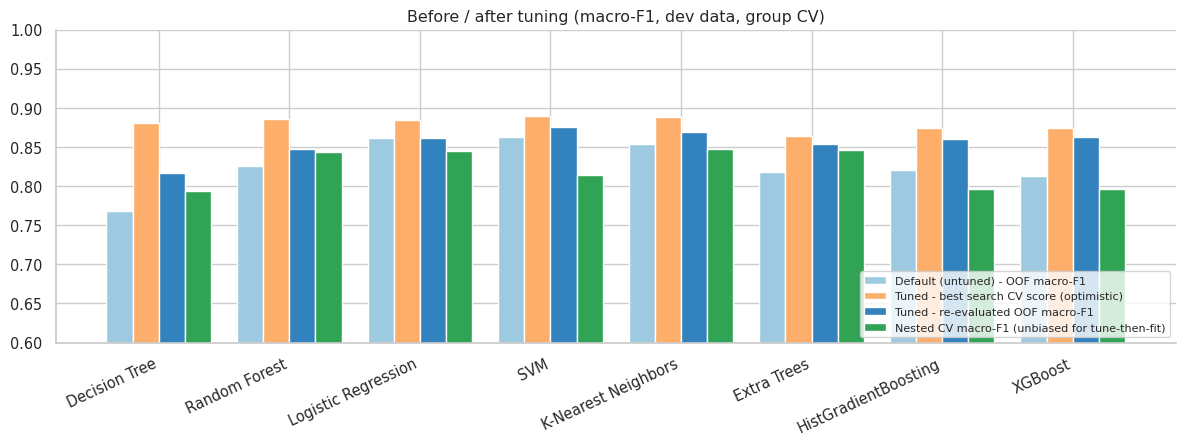

,Decision Tree,Random Forest,Logistic Regression,SVM,K-Nearest Neighbors,Extra Trees,HistGradientBoosting,XGBoost
outer fold,,,,,,,,
0,0.7185,0.8127,0.8189,0.6586,0.8005,0.8248,0.8698,0.8698
1,0.7899,0.7899,0.8156,0.8156,0.8517,0.8156,0.8156,0.8156
2,0.9295,0.9295,0.9295,0.9295,0.8982,0.9295,0.6608,0.6608
3,0.8297,0.8709,0.8470,0.8752,0.8709,0.8470,0.8204,0.8204
4,0.7024,0.8135,0.8135,0.7947,0.8135,0.8135,0.8135,0.8135


**Reading.** Tuning changes OOF macro-F1 by +0.000 to +0.050 (largest for **XGBoost**). The search's own best score overstates real performance by +0.057 on average (range +0.018 to +0.087) compared with nested CV — which is why models must not be compared by their search score. Best nested estimate: **K-Nearest Neighbors** (0.847); typical outer-fold SD is 0.068, so many models are statistically indistinguishable. No test-set information was used.

In [ ]:
ba = pd.DataFrame({n: {"Default (untuned) - OOF macro-F1": model_res[n]["pooled"].macro_f1, "Tuned - best search CV score (optimistic)": searches[n].best_score_,
                       "Tuned - re-evaluated OOF macro-F1": tuned_res[n]["pooled"].macro_f1, "Nested CV macro-F1 (unbiased for tune-then-fit)": nested[n]["macro_f1"].mean(),
                       "Nested CV std": nested[n]["macro_f1"].std(ddof=1)} for n in searches}).T
ba["Gain from tuning (re-eval - default)"] = ba["Tuned - re-evaluated OOF macro-F1"] - ba["Default (untuned) - OOF macro-F1"]
ba["Optimism (search - nested)"] = ba["Tuned - best search CV score (optimistic)"] - ba["Nested CV macro-F1 (unbiased for tune-then-fit)"]
display(ba); ba.to_csv(OUTPUTS_DIR / "tuning_before_after.csv")

fig, ax = plt.subplots(figsize=(12, 4.6)); idx = np.arange(len(ba)); w = .2
for i, (c, col) in enumerate([("Default (untuned) - OOF macro-F1", "#9ecae1"), ("Tuned - best search CV score (optimistic)", "#fdae6b"),
                              ("Tuned - re-evaluated OOF macro-F1", "#3182bd"), ("Nested CV macro-F1 (unbiased for tune-then-fit)", "#31a354")]):
    ax.bar(idx + (i - 1.5) * w, ba[c], w, label=c, color=col)
ax.set_xticks(idx); ax.set_xticklabels(ba.index, rotation=25, ha="right"); ax.set_ylim(0.6, 1.0); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Before / after tuning (macro-F1, dev data, group CV)"); savefig("tuning_before_after.png")

nested_df = pd.DataFrame({n: v["macro_f1"] for n, v in nested.items()}); nested_df.index.name = "outer fold"; display(nested_df)
say(f"**Reading.** Tuning changes OOF macro-F1 by {ba['Gain from tuning (re-eval - default)'].min():+.3f} to {ba['Gain from tuning (re-eval - default)'].max():+.3f} (largest for **{ba['Gain from tuning (re-eval - default)'].idxmax()}**). "
    f"The search's own best score overstates real performance by {ba['Optimism (search - nested)'].mean():+.3f} on average (range {ba['Optimism (search - nested)'].min():+.3f} to {ba['Optimism (search - nested)'].max():+.3f}) compared with nested CV — "
    "which is why models must not be compared by their search score. "
    f"Best nested estimate: **{ba['Nested CV macro-F1 (unbiased for tune-then-fit)'].idxmax()}** ({ba['Nested CV macro-F1 (unbiased for tune-then-fit)'].max():.3f}); typical outer-fold SD is {ba['Nested CV std'].median():.3f}, "
    "so many models are statistically indistinguishable. No test-set information was used.")

## Phase 13 — Ensemble learning
Random Forest, Extra Trees, HistGradientBoosting and XGBoost are already ensembles of trees. Here two **meta-ensembles** of the three best *tuned* models are tested: a soft-voting ensemble and a stacking ensemble (logistic-regression meta-learner with group-aware inner splits). Added complexity is accepted only if it pays for itself.

In [ ]:
top3 = sorted(tuned_res, key=lambda n: tuned_res[n]["pooled"].macro_f1, reverse=True)[:3]
print("Base learners for the meta-ensembles (best 3 tuned models by OOF macro-F1):", top3)

def base_learners():
    return [(n.replace(" ", "_").replace("(", "").replace(")", ""), clone(searches[n].best_estimator_)) for n in top3]

voting = VotingClassifier(base_learners(), voting="soft")
stacking = StackingClassifier(base_learners(), final_estimator=LogisticRegression(max_iter=3000), cv=GroupCV(3, True, SEED + 400), stack_method="predict_proba", n_jobs=1)
ens_res = {"Voting (soft, top-3)": evaluate(voting, X_dev, y_dev, DEV_SPLITS, name="Voting (soft, top-3)"),
           "Stacking (LR meta, top-3)": evaluate(stacking, X_dev, y_dev, DEV_SPLITS, name="Stacking (LR meta, top-3)")}

cmp = pd.DataFrame([summary_row(r) for r in list(tuned_res.values()) + list(ens_res.values())]).set_index("Model")
display(cmp[cmp_cols[1:] + ["Gap (train-CV)", "Fit Time (s)"]].sort_values("Macro F1", ascending=False))

best_single = max(tuned_res.values(), key=lambda r: r["pooled"].macro_f1)
best_ens = max(ens_res.values(), key=lambda r: r["pooled"].macro_f1)
d, se_, _ = paired_delta(best_ens, best_single)
verdict = ("The ensemble is **not** clearly better (|difference| < 2 SE), so its extra training cost, latency and deployment complexity are not justified by performance alone." if abs(d) < 2 * se_
           else ("The ensemble is measurably better (> 2 SE) and the added complexity can be justified." if d > 0 else "The ensemble is measurably *worse* than the single model."))
say(f"**Reading.** Best single tuned model: **{best_single['name']}** (macro-F1 {best_single['pooled'].macro_f1:.3f}); best ensemble: **{best_ens['name']}** ({best_ens['pooled'].macro_f1:.3f}). "
    f"Paired fold difference (ensemble − single) = {d:+.3f} ± {se_:.3f} (SE). " + verdict)

Base learners for the meta-ensembles (best 3 tuned models by OOF macro-F1): ['SVM', 'K-Nearest Neighbors', 'XGBoost']


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,CV Mean,CV Std,Gap (train-CV),Fit Time (s)
Model,,,,,,,,,,
"Voting (soft, top-3)",0.9102,0.8825,0.8773,0.8825,0.8797,0.9105,0.8713,0.0646,0.0546,0.2105
SVM (tuned),0.9046,0.8818,0.8704,0.8818,0.8758,0.9054,0.8696,0.0477,0.0496,0.0292
"Stacking (LR meta, top-3)",0.9035,0.8739,0.8709,0.8739,0.8721,0.9037,0.8629,0.0587,0.0588,1.0470
K-Nearest Neighbors (tuned),0.9024,0.8730,0.8682,0.8730,0.8695,0.9025,0.8604,0.0523,0.0415,0.1031
XGBoost (tuned),0.8967,0.8607,0.8655,0.8607,0.8629,0.8963,0.8487,0.0648,0.0780,0.1050
Logistic Regression (tuned),0.8923,0.8711,0.8536,0.8711,0.8617,0.8936,0.8548,0.0418,0.0633,0.0666
HistGradientBoosting (tuned),0.8967,0.8604,0.8613,0.8604,0.8604,0.8965,0.8495,0.0539,0.0664,0.1366
Extra Trees (tuned),0.8900,0.8562,0.8570,0.8562,0.8534,0.8900,0.8444,0.0557,0.0696,0.8784
Random Forest (tuned),0.8788,0.8527,0.8441,0.8527,0.8469,0.8800,0.8397,0.0613,0.0792,1.6806


**Reading.** Best single tuned model: **SVM (tuned)** (macro-F1 0.876); best ensemble: **Voting (soft, top-3)** (0.880). Paired fold difference (ensemble − single) = +0.002 ± 0.013 (SE). The ensemble is **not** clearly better (|difference| < 2 SE), so its extra training cost, latency and deployment complexity are not justified by performance alone.

## Phase 14 — Final model selection (documented decision framework)

The final candidate is chosen **before** any test-set evaluation, from development-data evidence only. Score = weighted sum of min-max-normalised criteria. Interpretability and deployment simplicity are explicit, subjective 1–5 ratings (shown below) because the brief requires balancing them against accuracy. The highest-accuracy model is **not** automatically selected.

In [ ]:
INTERP = {"Decision Tree": 5, "Logistic Regression": 5, "Random Forest": 3, "Extra Trees": 3, "HistGradientBoosting": 3, "XGBoost": 3,
          "SVM": 2, "K-Nearest Neighbors": 2, "Voting (soft, top-3)": 2, "Stacking (LR meta, top-3)": 1}          # 1-5, higher = easier to explain
DEPLOY = {"Decision Tree": 5, "Logistic Regression": 5, "Random Forest": 4, "Extra Trees": 4, "SVM": 4, "K-Nearest Neighbors": 4,
          "HistGradientBoosting": 4, "XGBoost": 3, "Voting (soft, top-3)": 3, "Stacking (LR meta, top-3)": 2}    # 1-5, higher = simpler to deploy

candidates = {**tuned_res, **ens_res}
rows = []
for n, r in candidates.items():
    s = summary_row(r)
    rows.append({"Model": n, "macro_f1": s["Macro F1"], "balanced_acc": s["Balanced Accuracy"], "min_disorder_recall": min(s["Recall Insomnia"], s["Recall Sleep Apnea"]),
                 "cv_std": s["CV Std"], "log_loss": s["Log Loss"], "overfit_gap": s["Gap (train-CV)"], "interpretability": INTERP[n], "fit_time": s["Fit Time (s)"],
                 "deploy_simplicity": DEPLOY[n], "nested_macro_f1": nested[n]["macro_f1"].mean() if n in nested else np.nan})
crit = pd.DataFrame(rows).set_index("Model")

WEIGHTS = {"macro_f1": .30, "balanced_acc": .10, "min_disorder_recall": .15, "cv_std": .10, "log_loss": .10,
           "overfit_gap": .05, "interpretability": .10, "fit_time": .05, "deploy_simplicity": .05}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9
LOWER_BETTER = {"cv_std", "log_loss", "overfit_gap", "fit_time"}

def min_max(s, lower_is_better=False):
    """Rescale a column to 0..1 (1 = best)."""
    s = s.astype(float); span = s.max() - s.min()
    z = (s - s.min()) / span if span > 0 else pd.Series(1.0, index=s.index)
    return 1 - z if lower_is_better else z
def score(weights):
    return sum(w * min_max(crit[c], c in LOWER_BETTER) for c, w in weights.items())

crit["weighted_score"] = score(WEIGHTS)
perf_only = {"macro_f1": .5, "balanced_acc": .25, "min_disorder_recall": .25}
equal = {c: 1 / len(WEIGHTS) for c in WEIGHTS}
crit["rank (main weights)"] = crit.weighted_score.rank(ascending=False).astype(int)
crit["rank (performance-only)"] = score(perf_only).rank(ascending=False).astype(int)       # does the winner change if only accuracy-type criteria count?
crit["rank (equal weights)"] = score(equal).rank(ascending=False).astype(int)
best_f1 = crit.macro_f1.max()
se_sel = np.mean([r["fold_df"].macro_f1.std() for r in candidates.values()]) / np.sqrt(len(DEV_SPLITS))
crit["within 1 SE of best macro-F1"] = crit.macro_f1 >= best_f1 - se_sel
display(crit.sort_values("weighted_score", ascending=False)); crit.to_csv(OUTPUTS_DIR / "model_selection_matrix.csv")

,macro_f1,balanced_acc,min_disorder_recall,cv_std,log_loss,overfit_gap,interpretability,fit_time,deploy_simplicity,nested_macro_f1,weighted_score,rank (main weights),rank (performance-only),rank (equal weights),within 1 SE of best macro-F1
Model,,,,,,,,,,,,,,,
SVM,0.8758,0.8818,0.8333,0.0477,0.4133,0.0496,2,0.0292,4,0.8147,0.8666,1,2,2,True
Logistic Regression,0.8617,0.8711,0.8167,0.0418,0.4799,0.0633,5,0.0666,5,0.8449,0.8363,2,4,1,False
"Voting (soft, top-3)",0.8797,0.8825,0.8222,0.0646,0.3556,0.0546,2,0.2105,3,NaN,0.8119,3,1,3,True
K-Nearest Neighbors,0.8695,0.8730,0.7833,0.0523,2.2298,0.0415,2,0.1031,4,0.8469,0.6736,4,5,4,True
"Stacking (LR meta, top-3)",0.8721,0.8739,0.8056,0.0587,0.3748,0.0588,1,1.0470,2,NaN,0.6703,5,3,7,True
HistGradientBoosting,0.8604,0.8604,0.7722,0.0539,0.3931,0.0664,3,0.1366,4,0.7960,0.6453,6,7,5,False
XGBoost,0.8629,0.8607,0.7944,0.0648,0.3578,0.0780,3,0.1050,3,0.7960,0.6442,7,6,6,False
Extra Trees,0.8534,0.8562,0.7333,0.0557,0.3716,0.0696,3,0.8784,4,0.8461,0.5156,8,9,8,False
Random Forest,0.8469,0.8527,0.7833,0.0613,0.8976,0.0792,3,1.6806,4,0.8433,0.4881,9,8,9,False


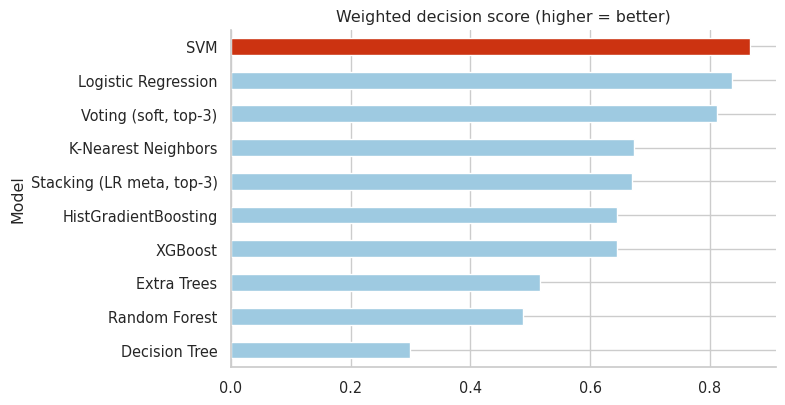

**Selected final candidate: SVM family → actual estimator: SVM (linear kernel, C=1)** (weighted score 0.867). Its OOF macro-F1 is 0.876 (best in the field: 0.880, Voting (soft, top-3)); rank under performance-only weights = 2, equal weights = 2. Models within 1 SE of the best macro-F1: SVM, K-Nearest Neighbors, Voting (soft, top-3), Stacking (LR meta, top-3). Selected parameters: `{'select': 'passthrough', 'kernel': 'linear', 'gamma': 0.3, 'class_weight': None, 'C': 1}`.

Test partition accessed so far: ['split-integrity verification (class proportions, overlap, covariate comparison) - no modelling']


In [ ]:
FINAL_NAME = crit.weighted_score.idxmax()
FINAL_ESTIMATOR = clone(searches[FINAL_NAME].best_estimator_) if FINAL_NAME in searches else clone({"Voting (soft, top-3)": voting, "Stacking (LR meta, top-3)": stacking}[FINAL_NAME])

def get_classifier(est):
    """The classifier step of a pipeline (or the estimator itself for ensembles)."""
    return est.named_steps["clf"] if hasattr(est, "named_steps") and "clf" in est.named_steps else est

def describe_estimator(est):
    """Description taken from the ACTUAL estimator object, never typed by hand."""
    clf = get_classifier(est)
    if isinstance(clf, SVC):
        return f"SVM ({clf.kernel} kernel, C={clf.C:g}" + ("" if clf.kernel == "linear" else f", gamma={clf.gamma}") + ")"
    return FINAL_NAME if FINAL_NAME in ("Voting (soft, top-3)", "Stacking (LR meta, top-3)") else type(clf).__name__

FINAL_LABEL = describe_estimator(FINAL_ESTIMATOR)
FINAL_CLF = get_classifier(FINAL_ESTIMATOR)

fig, ax = plt.subplots(figsize=(8, 4.2))
crit.weighted_score.sort_values().plot.barh(ax=ax, color=["#CC3311" if n == FINAL_NAME else "#9ecae1" for n in crit.weighted_score.sort_values().index])
ax.set_title("Weighted decision score (higher = better)"); savefig("model_selection_scores.png")

chosen_params = clean_params(searches[FINAL_NAME].best_params_) if FINAL_NAME in searches else "ensemble of " + ", ".join(top3)
say(f"**Selected final candidate: {FINAL_NAME} family → actual estimator: {FINAL_LABEL}** (weighted score {crit.weighted_score.max():.3f}). Its OOF macro-F1 is {crit.loc[FINAL_NAME,'macro_f1']:.3f} "
    f"(best in the field: {best_f1:.3f}, {crit.macro_f1.idxmax()}); rank under performance-only weights = {int(crit.loc[FINAL_NAME,'rank (performance-only)'])}, equal weights = {int(crit.loc[FINAL_NAME,'rank (equal weights)'])}. "
    f"Models within 1 SE of the best macro-F1: {', '.join(crit.index[crit['within 1 SE of best macro-F1']])}. Selected parameters: `{chosen_params}`.")
print("Test partition accessed so far:", [l["purpose"] for l in test_access_log])

## Phase 14B — Why is Insomnia recall weak?

The selected model finds *Insomnia* much less reliably than the other two classes. Before touching anything, this phase asks — using **development data only; the locked test rows are not used** —

1. How weak is Insomnia recall *inside* cross-validation, and how much does it vary from fold to fold?
2. Which Insomnia rows are persistently missed, and what do they look like (do identical inputs also carry other labels)?
3. Would a **different imbalance strategy** (class weights, over-/under-sampling, SMOTE-NC) help the *selected model family*?
4. Would a different **decision rule / threshold** for Insomnia help (chosen without peeking: leave-one-fold-out)?
5. Does any **alternative classifier** offer clearly better Insomnia recall without losing macro-F1?

**Adoption rule, written down before running** (so the outcome cannot be tuned): a change is adopted only if development macro-F1 improves by more than **2 paired standard errors** *and* by at least 0.01, *and* Insomnia recall does not fall. Otherwise the model is kept and the weakness is documented. Nothing here may modify the dataset or remove difficult rows.

In [ ]:
FINAL_DEV_RES = tuned_res[FINAL_NAME] if FINAL_NAME in tuned_res else ens_res[FINAL_NAME]
oof_f = FINAL_DEV_RES["oof_pred"]; n_rep_f = oof_f.shape[0]

cm_dev = sum(confusion_matrix(y_dev, oof_f[r], labels=CLASS_ORDER) for r in range(n_rep_f)) / n_rep_f
print(f"Development OOF confusion matrix of the selected model ({FINAL_LABEL}); mean over {n_rep_f} repeats; rows = actual, columns = predicted")
display(pd.DataFrame(cm_dev.round(1), index=[f"actual {c}" for c in CLASS_ORDER], columns=[f"pred {c}" for c in CLASS_ORDER]))

fold_recall = []
for (r, k, tr, va) in DEV_SPLITS:
    yv, pv = np.asarray(y_dev.iloc[va]), oof_f[r, va]; is_ins_fold = yv == "Insomnia"
    if is_ins_fold.sum() > 0:
        fold_recall.append({"repeat": r, "fold": k, "n_insomnia": int(is_ins_fold.sum()), "recall_Insomnia": float((pv[is_ins_fold] == "Insomnia").mean())})
fold_recall = pd.DataFrame(fold_recall); ins_dev_recall = FINAL_DEV_RES["pooled"]["recall_Insomnia"]
print(f"Insomnia recall (pooled OOF, mean of repeats) = {ins_dev_recall:.3f}; per fold: median {fold_recall.recall_Insomnia.median():.2f}, "
      f"min {fold_recall.recall_Insomnia.min():.2f}, max {fold_recall.recall_Insomnia.max():.2f} over {len(fold_recall)} folds")

Development OOF confusion matrix of the selected model (SVM (linear kernel, C=1)); mean over 3 repeats; rows = actual, columns = predicted


,pred Insomnia,pred None,pred Sleep Apnea
actual Insomnia,54.0000,2.0000,6.0000
actual None,4.7000,164.7000,5.7000
actual Sleep Apnea,6.0000,4.0000,50.0000


Insomnia recall (pooled OOF, mean of repeats) = 0.871; per fold: median 0.92, min 0.50, max 1.00 over 15 folds


In [ ]:
# Anatomy of the persistently missed Insomnia rows (development OOF, all repeats)
Xe_ = engineer(X_dev).reset_index(drop=True)
is_ins = (np.asarray(y_dev) == "Insomnia")
miss_rate = (oof_f != "Insomnia").mean(axis=0)                  # per row: share of repeats in which it was NOT predicted Insomnia
persist_fn = is_ins & (miss_rate >= 0.5); tp_rows = is_ins & (miss_rate < 0.5)
n_lab_same = y_dev.groupby(dev_key.values).transform("nunique").values
share_contra = float((n_lab_same[persist_fn] > 1).mean()) if persist_fn.sum() else float("nan")
fn_pred = pd.Series(oof_f[:, persist_fn].ravel()).value_counts(normalize=True)
print(f"Insomnia rows: {int(is_ins.sum())}; persistently missed (missed in >=50% of repeats): {int(persist_fn.sum())}; found: {int(tp_rows.sum())}")
print(f"Share of persistently missed Insomnia rows whose IDENTICAL feature vector also carries another label (irreducible with these features): {share_contra:.0%}")
print("What the missed rows are predicted as:", {k: round(float(v), 2) for k, v in fn_pred.items()})

if persist_fn.sum() >= 3 and tp_rows.sum() >= 3:
    rows_ = []
    for c in NUM_MODEL_COLS:
        a, b = Xe_.loc[persist_fn, c], Xe_.loc[tp_rows, c]
        try:
            u = stats.mannwhitneyu(a, b, alternative="two-sided"); rank_biserial = 1 - 2 * u.statistic / (len(a) * len(b))
        except ValueError:
            rank_biserial = np.nan
        rows_.append({"feature": c, "median_missed": a.median(), "median_found": b.median(), "rank_biserial (missed vs found)": rank_biserial})
    fn_tab = (pd.DataFrame(rows_).assign(abs_r=lambda d: d["rank_biserial (missed vs found)"].abs())
              .sort_values("abs_r", ascending=False).drop(columns="abs_r").reset_index(drop=True))
    display(fn_tab.head(8))
    occ_tab = pd.crosstab(X_dev["Occupation"].values, np.where(persist_fn, "missed", np.where(tp_rows, "found", "other")))
    occ_tab = occ_tab[[c for c in ["missed", "found"] if c in occ_tab]]; occ_tab = occ_tab[occ_tab.sum(axis=1) > 0]
    print("Insomnia rows by occupation (missed vs found):"); display(occ_tab)
    fn_tab.to_csv(OUTPUTS_DIR / "insomnia_missed_vs_found_features.csv", index=False)
else:
    fn_tab = pd.DataFrame(); print("Too few missed (or found) Insomnia rows for a feature comparison.")

Insomnia rows: 62; persistently missed (missed in >=50% of repeats): 8; found: 54
Share of persistently missed Insomnia rows whose IDENTICAL feature vector also carries another label (irreducible with these features): 50%
What the missed rows are predicted as: {'Sleep Apnea': 0.75, 'None': 0.25}


,feature,median_missed,median_found,rank_biserial (missed vs found)
0,Daily Steps,"4,000.0000","6,000.0000",0.9907
1,Heart Rate,80.0000,72.0000,-0.7384
2,Physical Activity Level,40.0000,45.0000,0.4375
3,Pulse Pressure,45.0000,45.0000,-0.2500
4,Age,36.0000,44.0000,0.2454
5,Quality of Sleep,6.0000,6.0000,0.2199
6,Stress Level,7.0000,7.0000,-0.1944
7,Mean Arterial Pressure,102.0000,100.0000,-0.1528


Insomnia rows by occupation (missed vs found):


col_0,missed,found
row_0,,
Doctor,3,0
Engineer,2,0
Nurse,2,0
Salesperson,0,28
Teacher,1,26


In [ ]:
# Lever 1: imbalance strategies for the SELECTED model family (inside training folds, like-for-like pipeline)
_clf0 = FINAL_CLF
supports_cw = "class_weight" in _clf0.get_params()
def final_family_clf(class_weight):
    c = clone(_clf0)
    if supports_cw: c.set_params(class_weight=class_weight)
    if "probability" in c.get_params(): c.set_params(probability=False)             # labels only -> much faster
    return c

lev_res, lev_rows = {}, []
for sname, build in strategies.items():
    est_, sampler_ = build(final_family_clf)
    lev_res[sname] = evaluate(make_resampling_pipeline(est_, sampler_, scale=True), X_dev, y_dev, DEV_SPLITS, name=f"{FINAL_NAME}|{sname}")
ADOPT_COL = "adopt (>2SE and >=0.01 and Insomnia recall not lower)"
for sname, r_ in lev_res.items():
    d_, se_, _ = paired_delta(r_, lev_res["none"])
    lev_rows.append({"strategy": sname, "macro_F1": r_["pooled"].macro_f1, "balanced_acc": r_["pooled"].balanced_accuracy, "recall_Insomnia": r_["pooled"].recall_Insomnia,
                     "recall_None": r_["pooled"].recall_None, "recall_Apnea": r_["pooled"]["recall_Sleep Apnea"], "delta_macroF1_vs_none": d_, "paired_SE": se_,
                     ADOPT_COL: bool(d_ > 2 * se_ and d_ >= 0.01 and r_["pooled"].recall_Insomnia >= lev_res["none"]["pooled"].recall_Insomnia)})
lev_df = pd.DataFrame(lev_rows); display(lev_df.round(3)); lev_df.to_csv(OUTPUTS_DIR / "insomnia_imbalance_strategies_final_family.csv", index=False)
print(f"Reference: the selected pipeline itself (class_weight={getattr(_clf0, 'class_weight', 'n/a')}): macro-F1 {FINAL_DEV_RES['pooled'].macro_f1:.3f}, Insomnia recall {ins_dev_recall:.3f}")
adoptable = lev_df[lev_df[ADOPT_COL]]
STRATEGY_ADOPTED = None if adoptable.empty else adoptable.sort_values("delta_macroF1_vs_none").iloc[-1].strategy

,strategy,macro_F1,balanced_acc,recall_Insomnia,recall_None,recall_Apnea,delta_macroF1_vs_none,paired_SE,adopt (>2SE and >=0.01 and Insomnia recall not lower)
0,none,0.8810,0.8860,0.8710,0.9430,0.8440,0.0000,0.0000,False
1,class_weight,0.8620,0.8710,0.8710,0.9300,0.8110,-0.0200,0.0090,False
2,random over-sampling,0.8620,0.8710,0.9140,0.9280,0.7720,-0.0180,0.0140,False
3,random under-sampling,0.8700,0.8800,0.8710,0.9240,0.8440,-0.0110,0.0080,False
4,SMOTE-NC,0.8620,0.8760,0.8870,0.9070,0.8330,-0.0170,0.0090,False


Reference: the selected pipeline itself (class_weight=None): macro-F1 0.876, Insomnia recall 0.871


In [ ]:
# Lever 2: a decision rule that favours Insomnia (probability scaling). The weight is chosen WITHOUT peeking:
# for every fold, pick the best weight on the OTHER folds' out-of-fold probabilities and score it on this fold.
P_ = FINAL_DEV_RES["oof_proba"]; yd_ = np.asarray(y_dev)
W_GRID = np.round(np.arange(1.0, 3.01, 0.25), 2); ins_col = CLASS_ORDER.index("Insomnia")

def predict_with_weight(P, w):
    v = np.ones(len(CLASS_ORDER)); v[ins_col] = w
    return np.array(CLASS_ORDER)[np.argmax(P * v, axis=1)]

grid_rows = []
for w in W_GRID:
    mf = np.mean([macro_f1(yd_, predict_with_weight(P_[r], w)) for r in range(n_rep_f)])
    ir = np.mean([(predict_with_weight(P_[r], w)[yd_ == "Insomnia"] == "Insomnia").mean() for r in range(n_rep_f)])
    grid_rows.append({"insomnia_weight": w, "macro_F1": mf, "recall_Insomnia": ir})
grid_df = pd.DataFrame(grid_rows); display(grid_df.round(3))

diffs_, chosen_ = [], []
for (r, k, tr, va) in DEV_SPLITS:
    other = np.setdiff1d(np.arange(len(yd_)), va)
    w_best = W_GRID[int(np.argmax([macro_f1(yd_[other], predict_with_weight(P_[r][other], w)) for w in W_GRID]))]; chosen_.append(w_best)
    diffs_.append(macro_f1(yd_[va], predict_with_weight(P_[r][va], w_best)) - macro_f1(yd_[va], predict_with_weight(P_[r][va], 1.0)))
diffs_ = np.array(diffs_); thr_gain, thr_se = diffs_.mean(), diffs_.std(ddof=1) / np.sqrt(len(diffs_))
THRESHOLD_ADOPTED = bool(thr_gain > 2 * thr_se and thr_gain >= 0.01)
print(f"Leave-one-fold-out Insomnia weight: median {np.median(chosen_):.2f} (range {min(chosen_):.2f}-{max(chosen_):.2f}); honest macro-F1 gain vs weight 1.0 = {thr_gain:+.4f} +/- {thr_se:.4f} (SE) -> adopt: {THRESHOLD_ADOPTED}")
grid_df.to_csv(OUTPUTS_DIR / "insomnia_threshold_scan_dev.csv", index=False)

,insomnia_weight,macro_F1,recall_Insomnia
0,1.0000,0.8910,0.8710
1,1.2500,0.8840,0.8710
2,1.5000,0.8840,0.8710
3,1.7500,0.8780,0.8710
4,2.0000,0.8770,0.8710
5,2.2500,0.8710,0.8760
6,2.5000,0.8700,0.8760
7,2.7500,0.8630,0.8760
8,3.0000,0.8630,0.8760


Leave-one-fold-out Insomnia weight: median 1.00 (range 1.00-2.25); honest macro-F1 gain vs weight 1.0 = -0.0021 +/- 0.0021 (SE) -> adopt: False


,model,macro_F1,recall_Insomnia,recall_Apnea,balanced_acc,delta_macroF1_vs_selected,paired_SE,is_selected
0,Extra Trees,0.8530,0.8920,0.7330,0.8560,-0.0250,0.0170,False
1,K-Nearest Neighbors,0.8700,0.8870,0.7830,0.8730,-0.0090,0.0130,False
2,"Voting (soft, top-3)",0.8800,0.8710,0.8220,0.8820,0.0020,0.0130,False
3,Decision Tree,0.8170,0.8710,0.8000,0.8400,-0.0520,0.0240,False
4,SVM,0.8760,0.8710,0.8330,0.8820,0.0000,0.0000,True
5,Logistic Regression,0.8620,0.8710,0.8170,0.8710,-0.0150,0.0070,False
6,"Stacking (LR meta, top-3)",0.8720,0.8660,0.8060,0.8740,-0.0070,0.0120,False
7,Random Forest,0.8470,0.8550,0.7830,0.8530,-0.0300,0.0180,False
8,HistGradientBoosting,0.8600,0.8550,0.7720,0.8600,-0.0200,0.0140,False
9,XGBoost,0.8630,0.8330,0.7940,0.8610,-0.0210,0.0120,False


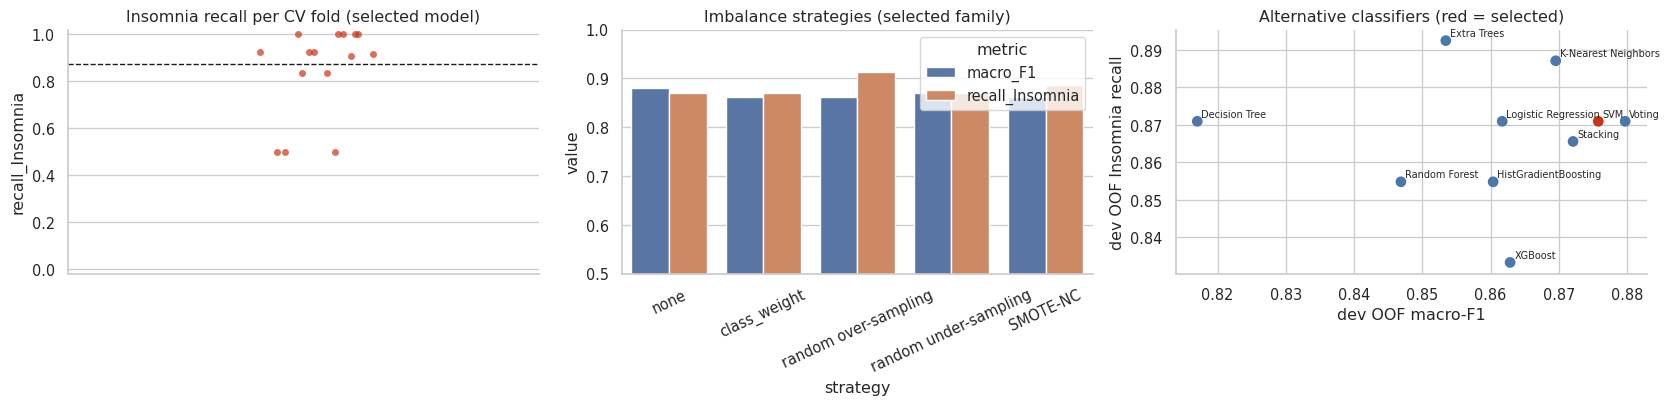

In [ ]:
# Lever 3: alternative classifiers (all already tuned / ensembled on the development folds)
alt_rows = []
for nm, r_ in {**tuned_res, **ens_res}.items():
    base_name = nm.replace(" (tuned)", ""); d_, se_, _ = paired_delta(r_, FINAL_DEV_RES)
    alt_rows.append({"model": base_name, "macro_F1": r_["pooled"].macro_f1, "recall_Insomnia": r_["pooled"].recall_Insomnia, "recall_Apnea": r_["pooled"]["recall_Sleep Apnea"],
                     "balanced_acc": r_["pooled"].balanced_accuracy, "delta_macroF1_vs_selected": d_, "paired_SE": se_, "is_selected": base_name == FINAL_NAME})
alt_df = pd.DataFrame(alt_rows).sort_values("recall_Insomnia", ascending=False).reset_index(drop=True)
display(alt_df.round(3)); alt_df.to_csv(OUTPUTS_DIR / "insomnia_alternative_classifiers_dev.csv", index=False)

better_ins = alt_df[(~alt_df.is_selected) & (alt_df.recall_Insomnia > ins_dev_recall)]
clear_win = alt_df[(~alt_df.is_selected) & (alt_df.delta_macroF1_vs_selected > 2 * alt_df.paired_SE) & (alt_df.delta_macroF1_vs_selected >= 0.01) & (alt_df.recall_Insomnia >= ins_dev_recall)]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.stripplot(data=fold_recall, y="recall_Insomnia", ax=axes[0], color="#CC3311", alpha=.7, jitter=.15)
axes[0].axhline(ins_dev_recall, ls="--", color="k", lw=1); axes[0].set_ylim(-.02, 1.02); axes[0].set_title("Insomnia recall per CV fold (selected model)")
melted = lev_df.melt(id_vars="strategy", value_vars=["macro_F1", "recall_Insomnia"], var_name="metric")
sns.barplot(data=melted, x="strategy", y="value", hue="metric", ax=axes[1]); axes[1].tick_params(axis="x", rotation=25); axes[1].set_ylim(0.5, 1); axes[1].set_title("Imbalance strategies (selected family)")
axes[2].scatter(alt_df.macro_F1, alt_df.recall_Insomnia, c=np.where(alt_df.is_selected, "#CC3311", "#4C78A8"), s=45)
for _, rr in alt_df.iterrows():
    axes[2].annotate(rr.model.replace(" (soft, top-3)", "").replace(" (LR meta, top-3)", ""), (rr.macro_F1, rr.recall_Insomnia), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[2].set_xlabel("dev OOF macro-F1"); axes[2].set_ylabel("dev OOF Insomnia recall"); axes[2].set_title("Alternative classifiers (red = selected)")
savefig("insomnia_investigation_dev.png")

In [ ]:
# Decision: apply the adoption rule that was written down before running (development evidence only)
INSOMNIA_DECISION = []
if STRATEGY_ADOPTED is None:
    INSOMNIA_DECISION.append("no imbalance strategy beat the current setting by the pre-declared margin")
elif STRATEGY_ADOPTED == "class_weight" and supports_cw:
    FINAL_ESTIMATOR.set_params(clf__class_weight="balanced"); FINAL_LABEL = describe_estimator(FINAL_ESTIMATOR); FINAL_CLF = get_classifier(FINAL_ESTIMATOR)
    INSOMNIA_DECISION.append("class_weight='balanced' ADOPTED")
else:
    raise AssertionError(f"The rule picked '{STRATEGY_ADOPTED}', which needs a resampling step inside the saved model; extend the pipeline before continuing")
if THRESHOLD_ADOPTED:
    raise AssertionError("The rule picked an Insomnia probability weight; add a decision-rule wrapper to the saved model before continuing")
INSOMNIA_DECISION.append("no Insomnia-specific threshold/weight beat weight 1.0 by the pre-declared margin")
if len(clear_win):
    raise AssertionError(f"An alternative classifier is clearly better under the rule: {list(clear_win.model)} - revisit model selection")
INSOMNIA_DECISION.append("no alternative classifier was clearly better on macro-F1 with equal-or-better Insomnia recall")

best_alt = alt_df[~alt_df.is_selected].iloc[0] if len(alt_df) > 1 else None
alt_text = f" (best: {best_alt.model}, recall {best_alt.recall_Insomnia:.2f}, macro-F1 change {best_alt.delta_macroF1_vs_selected:+.3f} ± {best_alt.paired_SE:.3f})" if best_alt is not None else ""
say(f"**Reading (development data only).** Inside cross-validation the selected model ({FINAL_LABEL}) finds {ins_dev_recall:.0%} of Insomnia rows on average, but the per-fold value ranges from "
    f"{fold_recall.recall_Insomnia.min():.0%} to {fold_recall.recall_Insomnia.max():.0%} (median {fold_recall.recall_Insomnia.median():.0%}) — Insomnia recall is **unstable**. "
    f"Of the {int(persist_fn.sum())} persistently missed Insomnia rows, {share_contra:.0%} have an identical feature vector that also carries another label, so they are partly irreducible with these inputs. "
    f"Imbalance strategies changed macro-F1 by {lev_df.delta_macroF1_vs_none.min():+.3f} to {lev_df.delta_macroF1_vs_none.max():+.3f} (largest paired SE {lev_df.paired_SE.max():.3f}). "
    f"A leave-one-fold-out Insomnia threshold gave {thr_gain:+.4f} macro-F1 (SE {thr_se:.4f}). {len(better_ins)} of {len(alt_df)-1} alternatives have higher Insomnia recall" + alt_text + ". "
    "**Decision under the pre-declared rule: the selected model is retained** — " + "; ".join(INSOMNIA_DECISION) +
    ". Insomnia recall is reported as it is — a documented limitation, not something that was tuned away. The locked test result (Phase 16) was not used for any of these decisions.")

**Reading (development data only).** Inside cross-validation the selected model (SVM (linear kernel, C=1)) finds 87% of Insomnia rows on average, but the per-fold value ranges from 50% to 100% (median 92%) — Insomnia recall is **unstable**. Of the 8 persistently missed Insomnia rows, 50% have an identical feature vector that also carries another label, so they are partly irreducible with these inputs. Imbalance strategies changed macro-F1 by -0.020 to +0.000 (largest paired SE 0.014). A leave-one-fold-out Insomnia threshold gave -0.0021 macro-F1 (SE 0.0021). 2 of 9 alternatives have higher Insomnia recall (best: Extra Trees, recall 0.89, macro-F1 change -0.025 ± 0.017). **Decision under the pre-declared rule: the selected model is retained** — no imbalance strategy beat the current setting by the pre-declared margin; no Insomnia-specific threshold/weight beat weight 1.0 by the pre-declared margin; no alternative classifier was clearly better on macro-F1 with equal-or-better Insomnia recall. Insomnia recall is reported as it is — a documented limitation, not something that was tuned away. The locked test result (Phase 16) was not used for any of these decisions.

## Phase 15 — Probability calibration
*Discrimination* (can the model separate the classes?) and *calibration* (do predicted probabilities match observed frequencies?) are different things: a model can classify well yet be over- or under-confident, which matters whenever a probability is shown to a person. Calibration is judged **only on development data**; the calibrator is fitted inside each training fold with group-aware inner splits (`CalibratedClassifierCV`, `ensemble=False`). Test labels play no role.

Compared: uncalibrated · sigmoid (Platt) · isotonic. Metrics: log loss, multiclass Brier score, class-wise expected calibration error (ECE, 5 quantile bins, one-vs-rest) and reliability diagrams. *The probabilities are model scores on a small dataset — not medically validated risk estimates.*

,log loss,Brier,mean class ECE,ECE Insomnia,ECE None,ECE Sleep Apnea,macro F1,balanced acc,accuracy
method,,,,,,,,,
uncalibrated,0.4133,0.1772,0.0474,0.0390,0.0574,0.0458,0.8758,0.8818,0.9046
sigmoid,0.4101,0.1956,0.0599,0.0413,0.0943,0.0440,0.8789,0.8830,0.9068
isotonic,0.6559,0.1813,0.0399,0.0340,0.0545,0.0311,0.8693,0.8743,0.9001


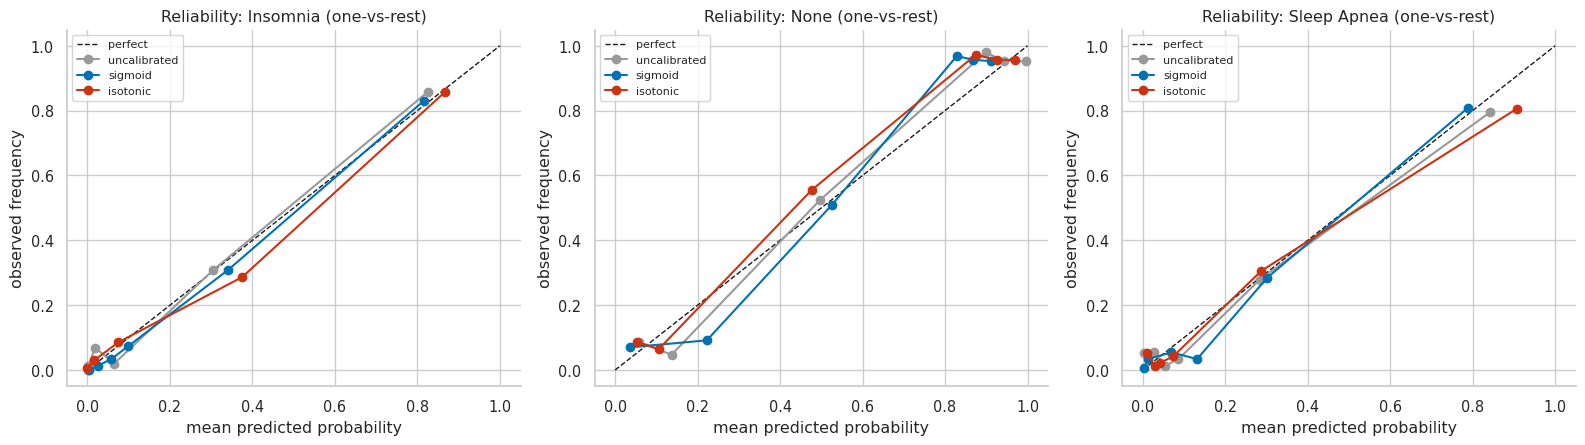

In [ ]:
def make_calibrated(estimator, method):
    return CalibratedClassifierCV(clone(estimator), method=method, cv=GroupCV(3, True, SEED + 500), ensemble=False)

def class_ece(y_true, proba, n_bins=5):
    """Expected calibration error per class (one-vs-rest, quantile bins): average gap between predicted and observed frequency."""
    out = {}
    for k, c in enumerate(CLASS_ORDER):
        yb = (np.asarray(y_true) == c).astype(float); p = proba[:, k]
        edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1))); edges[0], edges[-1] = -1e-9, 1 + 1e-9
        b = np.digitize(p, edges[1:-1])
        out[c] = sum((b == i).mean() * abs(yb[b == i].mean() - p[b == i].mean()) for i in np.unique(b))
    return out

cal_res = {"uncalibrated": evaluate(FINAL_ESTIMATOR, X_dev, y_dev, DEV_SPLITS, name="uncalibrated"),
           "sigmoid": evaluate(make_calibrated(FINAL_ESTIMATOR, "sigmoid"), X_dev, y_dev, DEV_SPLITS, name="sigmoid"),
           "isotonic": evaluate(make_calibrated(FINAL_ESTIMATOR, "isotonic"), X_dev, y_dev, DEV_SPLITS, name="isotonic")}

cal_rows = []
for k, r in cal_res.items():
    ece_df = pd.DataFrame([class_ece(y_dev, r["oof_proba"][i]) for i in range(r["oof_proba"].shape[0])]).mean()
    cal_rows.append({"method": k, "log loss": r["pooled"].log_loss, "Brier": r["pooled"].brier, "mean class ECE": ece_df.mean(), **{f"ECE {c}": ece_df[c] for c in CLASS_ORDER},
                     "macro F1": r["pooled"].macro_f1, "balanced acc": r["pooled"].balanced_accuracy, "accuracy": r["pooled"].accuracy})
cal_tab = pd.DataFrame(cal_rows).set_index("method"); display(cal_tab); cal_tab.to_csv(OUTPUTS_DIR / "calibration_comparison.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (k, c) in zip(axes, enumerate(CLASS_ORDER)):
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
    for meth, col in [("uncalibrated", "#999999"), ("sigmoid", "#0072B2"), ("isotonic", "#CC3311")]:
        pp = cal_res[meth]["oof_proba"][:, :, k].ravel(); yy = np.tile((np.asarray(y_dev) == c).astype(int), cal_res[meth]["oof_proba"].shape[0])
        frac, mean_pred = calibration_curve(yy, pp, n_bins=6, strategy="quantile"); ax.plot(mean_pred, frac, "o-", color=col, label=meth)
    ax.set_title(f"Reliability: {c} (one-vs-rest)"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency"); ax.legend(fontsize=8)
savefig("calibration_reliability.png")

In [ ]:
unc, sig, iso = cal_tab.loc["uncalibrated"], cal_tab.loc["sigmoid"], cal_tab.loc["isotonic"]
def calibrator_ok(row):
    """Adopt a calibrator only if it improves log loss AND Brier without costing more than 0.01 macro-F1."""
    return (row["log loss"] < unc["log loss"]) and (row["Brier"] < unc["Brier"]) and (row["macro F1"] >= unc["macro F1"] - 0.01)
ok_methods = [m for m in ["sigmoid", "isotonic"] if calibrator_ok(cal_tab.loc[m])]
CAL_CHOICE = min(ok_methods, key=lambda m: cal_tab.loc[m, "log loss"]) if ok_methods else "uncalibrated"
say(f"**Reading.** Log loss: uncalibrated {unc['log loss']:.3f}, sigmoid {sig['log loss']:.3f}, isotonic {iso['log loss']:.3f}; Brier: {unc['Brier']:.3f} / {sig['Brier']:.3f} / {iso['Brier']:.3f}; "
    f"mean class ECE: {unc['mean class ECE']:.3f} / {sig['mean class ECE']:.3f} / {iso['mean class ECE']:.3f}. Macro-F1 moves {sig['macro F1']-unc['macro F1']:+.3f} (sigmoid) / {iso['macro F1']-unc['macro F1']:+.3f} (isotonic): "
    f"calibration changes *probability quality*, not (much) *discrimination*. **Decision: {CAL_CHOICE}.** " +
    ("" if CAL_CHOICE != "uncalibrated" else "No calibrator improved both log loss and Brier without hurting macro-F1, so the raw probabilities are kept. ") +
    "Whatever the choice, the probabilities are *model scores learned from ~300 rows with duplicated profiles* and must not be read as validated clinical risk.")

# Fit the FINAL model on ALL development data (the test rows are still locked)
FINAL_UNFITTED = make_calibrated(FINAL_ESTIMATOR, CAL_CHOICE) if CAL_CHOICE != "uncalibrated" else clone(FINAL_ESTIMATOR)
FINAL_MODEL = clone(FINAL_UNFITTED).fit(X_dev, y_dev)
FITTED_BASE = FINAL_MODEL.calibrated_classifiers_[0].estimator if CAL_CHOICE != "uncalibrated" else FINAL_MODEL
print("Final model fitted on development data only:", FINAL_NAME, "| calibration:", CAL_CHOICE, "| classes:", list(FINAL_MODEL.classes_))

**Reading.** Log loss: uncalibrated 0.413, sigmoid 0.410, isotonic 0.656; Brier: 0.177 / 0.196 / 0.181; mean class ECE: 0.047 / 0.060 / 0.040. Macro-F1 moves +0.003 (sigmoid) / -0.006 (isotonic): calibration changes *probability quality*, not (much) *discrimination*. **Decision: uncalibrated.** No calibrator improved both log loss and Brier without hurting macro-F1, so the raw probabilities are kept. Whatever the choice, the probabilities are *model scores learned from ~300 rows with duplicated profiles* and must not be read as validated clinical risk.

Final model fitted on development data only: SVM | calibration: uncalibrated | classes: ['Insomnia', 'None', 'Sleep Apnea']


## Phase 16 — Final evaluation on the untouched test partition
This is the **first and only** modelling use of the locked test rows (the earlier access was an integrity check). The model was selected, tuned and calibrated on development data only. Because the test set has only ~75 rows from ~15 profile groups, point estimates come with **group-cluster bootstrap** intervals.

In [ ]:
Xte, yte, gte = open_test_rows("FINAL evaluation of the selected pipeline (single use)")
pred = FINAL_MODEL.predict(Xte)
proba = FINAL_MODEL.predict_proba(Xte)
Yb = label_binarize(yte, classes=CLASS_ORDER)

p_m, r_m, f_m, _ = precision_recall_fscore_support(yte, pred, labels=CLASS_ORDER, average="macro", zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(yte, pred, labels=CLASS_ORDER, average="weighted", zero_division=0)
p_u, r_u, f_u, _ = precision_recall_fscore_support(yte, pred, labels=CLASS_ORDER, average="micro", zero_division=0)
pc_p, pc_r, pc_f, pc_s = precision_recall_fscore_support(yte, pred, labels=CLASS_ORDER, zero_division=0)

metrics = {"Accuracy": accuracy_score(yte, pred), "Balanced accuracy": balanced_accuracy_score(yte, pred),
           "Precision (micro)": p_u, "Recall (micro)": r_u, "F1 (micro)": f_u,
           "Macro precision": p_m, "Macro recall": r_m, "Macro F1": f_m, "Weighted precision": p_w, "Weighted recall": r_w, "Weighted F1": f_w,
           "ROC-AUC (OvR macro)": roc_auc_score(yte, proba, multi_class="ovr", average="macro", labels=CLASS_ORDER),
           "Log loss": log_loss(yte, proba, labels=CLASS_ORDER), "Brier (multiclass)": brier_multiclass(yte, proba),
           "Matthews corr. coef.": matthews_corrcoef(yte, pred), "Cohen's kappa": cohen_kappa_score(yte, pred)}
test_metrics = pd.Series(metrics, name="test").to_frame(); display(test_metrics)

per_class = pd.DataFrame({"precision": pc_p, "recall": pc_r, "f1": pc_f, "support": pc_s,
                          "ROC-AUC (OvR)": [roc_auc_score(Yb[:, k], proba[:, k]) for k in range(3)],
                          "Avg precision (PR-AUC)": [average_precision_score(Yb[:, k], proba[:, k]) for k in range(3)]}, index=CLASS_ORDER)
display(per_class)
print(classification_report(yte, pred, labels=CLASS_ORDER, zero_division=0))

,test
Accuracy,0.8182
Balanced accuracy,0.7072
Precision (micro),0.8182
Recall (micro),0.8182
F1 (micro),0.8182
Macro precision,0.8922
Macro recall,0.7072
Macro F1,0.7070
Weighted precision,0.8507
Weighted recall,0.8182


,precision,recall,f1,support,ROC-AUC (OvR),Avg precision (PR-AUC)
Insomnia,1.0000,0.2000,0.3333,15,0.8048,0.7375
None,0.7818,0.9773,0.8687,44,0.9091,0.8870
Sleep Apnea,0.8947,0.9444,0.9189,18,0.9656,0.8617


              precision    recall  f1-score   support

    Insomnia       1.00      0.20      0.33        15
        None       0.78      0.98      0.87        44
 Sleep Apnea       0.89      0.94      0.92        18

    accuracy                           0.82        77
   macro avg       0.89      0.71      0.71        77
weighted avg       0.85      0.82      0.78        77



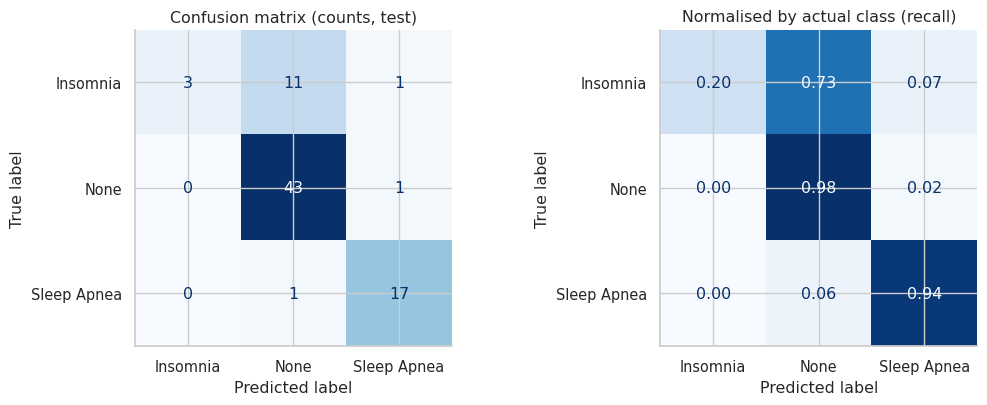

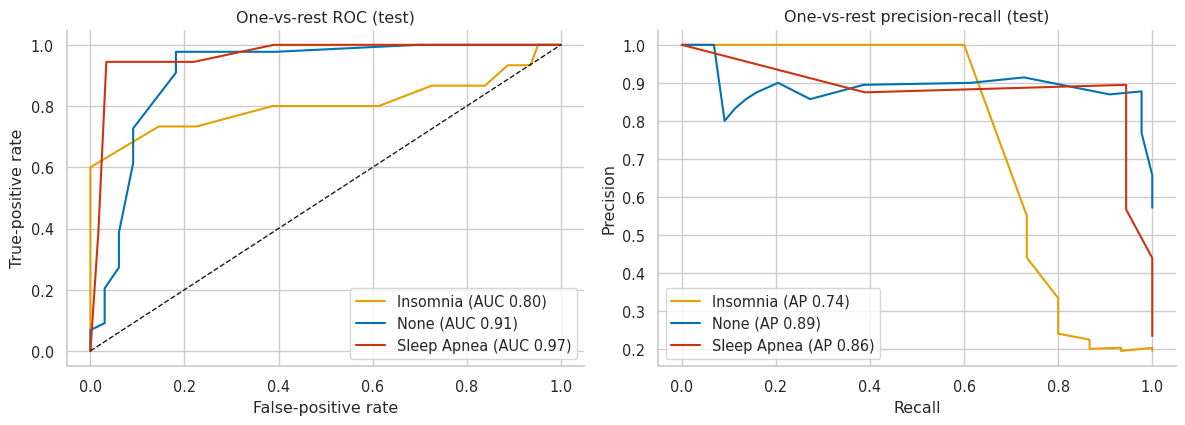

In [ ]:
cm = confusion_matrix(yte, pred, labels=CLASS_ORDER)
cm_norm = confusion_matrix(yte, pred, labels=CLASS_ORDER, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=CLASS_ORDER).plot(ax=axes[0], cmap="Blues", colorbar=False); axes[0].set_title("Confusion matrix (counts, test)")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_ORDER).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f"); axes[1].set_title("Normalised by actual class (recall)")
savefig("final_confusion_matrices.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for k, c in enumerate(CLASS_ORDER):
    fpr, tpr, _ = roc_curve(Yb[:, k], proba[:, k]); axes[0].plot(fpr, tpr, label=f"{c} (AUC {per_class.loc[c,'ROC-AUC (OvR)']:.2f})", color=PALETTE[c])
    prec, rec, _ = precision_recall_curve(Yb[:, k], proba[:, k]); axes[1].plot(rec, prec, label=f"{c} (AP {per_class.loc[c,'Avg precision (PR-AUC)']:.2f})", color=PALETTE[c])
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("One-vs-rest ROC (test)"); axes[0].legend()
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("One-vs-rest precision-recall (test)"); axes[1].legend()
savefig("final_roc_pr.png")

In [ ]:
# Group-cluster bootstrap: resample whole profile groups of the test set, 2000 times
rng = np.random.default_rng(SEED)
ug = np.unique(gte); idx_by_group = {g: np.where(gte == g)[0] for g in ug}; yte_a = np.asarray(yte); boot = []
for _ in range(500 if FAST_MODE else 2000):
    ii = np.concatenate([idx_by_group[g] for g in rng.choice(ug, len(ug), replace=True)])
    yt_, yp_ = yte_a[ii], pred[ii]
    rec = recall_score(yt_, yp_, labels=CLASS_ORDER, average=None, zero_division=0); present = [c in set(yt_) for c in CLASS_ORDER]
    boot.append({"macro_f1": macro_f1(yt_, yp_), "balanced_accuracy": rec[present].mean(), "accuracy": (yt_ == yp_).mean(),
                 **{f"recall_{c}": (rec[i] if present[i] else np.nan) for i, c in enumerate(CLASS_ORDER)}})
boot = pd.DataFrame(boot)
ci = boot.quantile([.025, .5, .975]).T; ci.columns = ["2.5%", "median", "97.5%"]
point = {"macro_f1": metrics["Macro F1"], "balanced_accuracy": metrics["Balanced accuracy"], "accuracy": metrics["Accuracy"], **{f"recall_{c}": per_class.loc[c, "recall"] for c in CLASS_ORDER}}
ci.insert(0, "point estimate", pd.Series(point)); display(ci)

# For reference: the majority baseline on the same test rows, the development estimates, and the uncalibrated model
base_test = DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev).predict(Xte); base_f1 = macro_f1(yte, base_test)
dev_oof_f1 = cal_res[CAL_CHOICE]["pooled"].macro_f1; dev_fold = cal_res[CAL_CHOICE]["fold_df"].macro_f1
unc_proba = clone(FINAL_ESTIMATOR).fit(X_dev, y_dev).predict_proba(Xte)
test_cal = pd.DataFrame({"log loss": [log_loss(yte, unc_proba, labels=CLASS_ORDER), metrics["Log loss"]], "Brier": [brier_multiclass(yte, unc_proba), metrics["Brier (multiclass)"]]},
                        index=["uncalibrated", f"final ({CAL_CHOICE})"])
print("Calibration check on test (shown for transparency; the calibration decision was made on development data):"); display(test_cal)

say(f"**Reading.** On {len(yte)} test rows from {len(ug)} unseen profile groups the final **{FINAL_LABEL}** ({CAL_CHOICE}) reaches accuracy **{metrics['Accuracy']:.3f}**, balanced accuracy **{metrics['Balanced accuracy']:.3f}** "
    f"and macro-F1 **{metrics['Macro F1']:.3f}** (95% group-bootstrap interval for macro-F1: {ci.loc['macro_f1','2.5%']:.2f}-{ci.loc['macro_f1','97.5%']:.2f}). The majority baseline scores macro-F1 {base_f1:.3f} on the same rows. "
    f"Development estimate for the same pipeline: OOF macro-F1 {dev_oof_f1:.3f} (fold SD {dev_fold.std():.3f}); the test value is {'within' if abs(metrics['Macro F1']-dev_oof_f1) <= dev_fold.std() else 'outside'} one fold-SD of it. "
    "Per-class recall: " + ", ".join(f"{c} {per_class.loc[c,'recall']:.2f} (n={int(per_class.loc[c,'support'])})" for c in CLASS_ORDER) + ". "
    "With so few test groups the interval is wide: do not read the point estimate as a precise or transferable accuracy. This is **not** an independent-cohort result — the test rows come from the same file and generating process.")

,point estimate,2.5%,median,97.5%
macro_f1,0.7070,0.3129,0.6445,0.8489
balanced_accuracy,0.7072,0.3563,0.6780,0.8241
accuracy,0.8182,0.6428,0.8217,0.9219
recall_Insomnia,0.2000,0.0000,0.2000,0.6000
recall_None,0.9773,0.8889,0.9796,1.0000
recall_Sleep Apnea,0.9444,0.0000,0.9444,1.0000


Calibration check on test (shown for transparency; the calibration decision was made on development data):


,log loss,Brier
uncalibrated,0.8078,0.2919
final (uncalibrated),0.8078,0.2919


**Reading.** On 77 test rows from 15 unseen profile groups the final **SVM (linear kernel, C=1)** (uncalibrated) reaches accuracy **0.818**, balanced accuracy **0.707** and macro-F1 **0.707** (95% group-bootstrap interval for macro-F1: 0.31-0.85). The majority baseline scores macro-F1 0.242 on the same rows. Development estimate for the same pipeline: OOF macro-F1 0.876 (fold SD 0.048); the test value is outside one fold-SD of it. Per-class recall: Insomnia 0.20 (n=15), None 0.98 (n=44), Sleep Apnea 0.94 (n=18). With so few test groups the interval is wide: do not read the point estimate as a precise or transferable accuracy. This is **not** an independent-cohort result — the test rows come from the same file and generating process.

## Phase 17 — False-negative and
For each class (one-vs-rest) TP / FP / TN / FN, recall, false-negative rate (FNR) and precision are computed on the **test** rows and — because 75 rows are very few — also on the **development out-of-fold** predictions (n≈300). A "missed disorder" is a person with Insomnia or Sleep Apnea predicted as *None*; confusing the two disorders is a different, usually less severe, error.

In [ ]:
def wilson(k, n, z=1.96):
    """95 % Wilson confidence interval for a proportion k/n (works well for small n)."""
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (centre - half, centre + half)

def ovr_table(y_true, y_pred):
    """One-vs-rest TP/FP/TN/FN, recall, false-negative rate, precision and specificity for every class."""
    cm_ = confusion_matrix(y_true, y_pred, labels=CLASS_ORDER); rows = []
    for k, c in enumerate(CLASS_ORDER):
        tp = cm_[k, k]; fn = cm_[k].sum() - tp; fp = cm_[:, k].sum() - tp; tn = cm_.sum() - tp - fn - fp
        lo, hi = wilson(tp, tp + fn)
        rows.append({"class": c, "TP": tp, "FP": fp, "TN": tn, "FN": fn, "recall": tp / (tp + fn) if tp + fn else np.nan, "FNR": fn / (tp + fn) if tp + fn else np.nan,
                     "recall 95% CI": f"{lo:.2f}-{hi:.2f}", "precision": tp / (tp + fp) if tp + fp else np.nan, "specificity": tn / (tn + fp) if tn + fp else np.nan})
    return pd.DataFrame(rows).set_index("class")

def missed_disorder(y_true, y_pred):
    """A 'missed disorder' = Insomnia or Sleep Apnea predicted as None."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    is_dis = y_true != "None"; k = int((is_dis & (y_pred == "None")).sum()); n = int(is_dis.sum()); lo, hi = wilson(k, n)
    return {"actual disorders": n, "missed (pred None)": k, "missed-disorder rate": k / n if n else np.nan, "95% CI": f"{lo:.2f}-{hi:.2f}",
            "wrong disorder type": int((is_dis & (y_pred != "None") & (y_pred != y_true)).sum()),
            "false alarms (None -> disorder)": int(((y_true == "None") & (y_pred != "None")).sum()), "actual None": int((y_true == "None").sum())}

oof_pred0 = cal_res[CAL_CHOICE]["oof_pred"]
print("TEST partition - one-vs-rest error table"); tt = ovr_table(yte, pred); display(tt)
print("Development OOF (repeat 0) - one-vs-rest error table"); to = ovr_table(y_dev, oof_pred0[0]); display(to)
md_test, md_oof = missed_disorder(yte, pred), missed_disorder(y_dev, oof_pred0[0])
display(pd.DataFrame({"test": md_test, "dev OOF (repeat 0)": md_oof}))
tt.to_csv(OUTPUTS_DIR / "fn_fp_by_class_test.csv"); to.to_csv(OUTPUTS_DIR / "fn_fp_by_class_oof.csv")

say(f"**Reading.** On the test rows the model misses {md_test['missed (pred None)']} of {md_test['actual disorders']} people with a recorded disorder (missed-disorder rate {md_test['missed-disorder rate']:.0%}, 95% CI {md_test['95% CI']}), "
    f"confuses the two disorders in {md_test['wrong disorder type']} cases and raises {md_test['false alarms (None -> disorder)']} false alarms among {md_test['actual None']} people with no disorder. "
    f"Over the larger development OOF set the missed-disorder rate is {md_oof['missed-disorder rate']:.0%} ({md_oof['95% CI']}). Per-class FNR on OOF: " + ", ".join(f"{c} {to.loc[c,'FNR']:.0%}" for c in CLASS_ORDER) +
    ". In a screening setting a missed disorder is generally more costly than a false alarm (which is followed by further assessment) — but how much more is a stakeholder / clinical judgement the data cannot supply.")

TEST partition - one-vs-rest error table


,TP,FP,TN,FN,recall,FNR,recall 95% CI,precision,specificity
class,,,,,,,,,
Insomnia,3,0,62,12,0.2000,0.8000,0.07-0.45,1.0000,1.0000
None,43,12,21,1,0.9773,0.0227,0.88-1.00,0.7818,0.6364
Sleep Apnea,17,2,57,1,0.9444,0.0556,0.74-0.99,0.8947,0.9661


Development OOF (repeat 0) - one-vs-rest error table


,TP,FP,TN,FN,recall,FNR,recall 95% CI,precision,specificity
class,,,,,,,,,
Insomnia,54,10,225,8,0.8710,0.1290,0.77-0.93,0.8438,0.9574
None,166,6,116,9,0.9486,0.0514,0.91-0.97,0.9651,0.9508
Sleep Apnea,50,11,226,10,0.8333,0.1667,0.72-0.91,0.8197,0.9536


,test,dev OOF (repeat 0)
actual disorders,33,122
missed (pred None),12,6
missed-disorder rate,0.3636,0.0492
95% CI,0.22-0.53,0.02-0.10
wrong disorder type,1,12
false alarms (None -> disorder),1,9
actual None,44,175


**Reading.** On the test rows the model misses 12 of 33 people with a recorded disorder (missed-disorder rate 36%, 95% CI 0.22-0.53), confuses the two disorders in 1 cases and raises 1 false alarms among 44 people with no disorder. Over the larger development OOF set the missed-disorder rate is 5% (0.02-0.10). Per-class FNR on OOF: Insomnia 13%, None 5%, Sleep Apnea 17%. In a screening setting a missed disorder is generally more costly than a false alarm (which is followed by further assessment) — but how much more is a stakeholder / clinical judgement the data cannot supply.

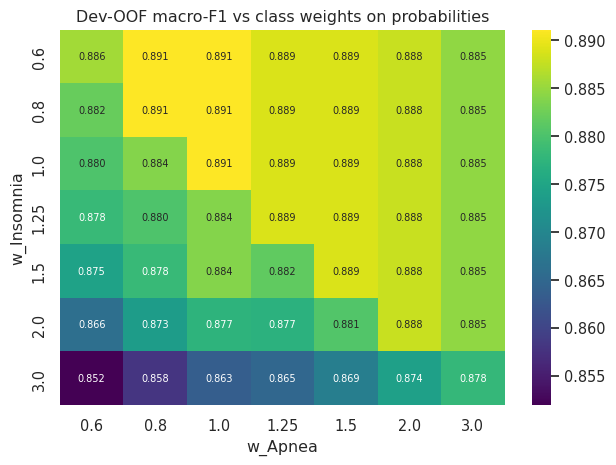

,w_Insomnia,w_Apnea,macro_f1,recall_Insomnia,recall_Apnea,missed_disorder_rate
"default (1,1)",1.0000,1.0000,0.8911,0.8710,0.8667,0.0492
best macro-F1,0.6000,0.8000,0.8911,0.8710,0.8667,0.0492
recall-first (<=0.02 macro-F1 loss),0.6000,0.8000,0.8911,0.8710,0.8667,0.0492


**Decision (computed).** The best development-OOF weights (0.6, 0.8) raise OOF macro-F1 by +0.000 (2 SE = 0.025) → **do NOT adopt**; the default decision rule is kept. A recall-first rule would use weights (0.6, 0.8): missed-disorder rate 4.9% → 4.9% on OOF at a macro-F1 cost of 0.000. Exploratory effect on the test rows (reported only, not used for choosing): macro-F1 0.671 with the weighted-probability rule vs 0.707 with the default `model.predict()` rule (plain argmax of the probabilities gives 0.671; for an SVM, `predict()` and the Platt-scaled probabilities can disagree on a few rows — all headline metrics here use `predict()`).

In [ ]:
# Class-specific decision rules: multiply the class probabilities by weights chosen on DEVELOPMENT OOF probabilities only
grid = [0.6, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0]
P = cal_res[CAL_CHOICE]["oof_proba"]; ytrue_dev = np.asarray(y_dev)

def oof_score_for(w_ins, w_apn):
    w = np.array([w_ins, 1.0, w_apn]); scores = []
    for r in range(P.shape[0]):
        pr_ = np.array(CLASS_ORDER)[np.argmax(P[r] * w, axis=1)]; rec = recall_score(ytrue_dev, pr_, labels=CLASS_ORDER, average=None, zero_division=0)
        scores.append((macro_f1(ytrue_dev, pr_), rec[0], rec[2], missed_disorder(ytrue_dev, pr_)["missed-disorder rate"]))
    return np.mean(scores, axis=0)

gr = pd.DataFrame([{"w_Insomnia": a, "w_Apnea": b, **dict(zip(["macro_f1", "recall_Insomnia", "recall_Apnea", "missed_disorder_rate"], oof_score_for(a, b)))} for a in grid for b in grid])
base_row = gr[(gr.w_Insomnia == 1) & (gr.w_Apnea == 1)].iloc[0]
best_row = gr.sort_values("macro_f1", ascending=False).iloc[0]
recall_first = gr[gr.macro_f1 >= base_row.macro_f1 - 0.02].sort_values(["missed_disorder_rate", "macro_f1"], ascending=[True, False]).iloc[0]

fig, ax = plt.subplots(figsize=(6.4, 4.8)); sns.heatmap(gr.pivot(index="w_Insomnia", columns="w_Apnea", values="macro_f1"), annot=True, fmt=".3f", cmap="viridis", ax=ax, annot_kws={"size": 7})
ax.set_title("Dev-OOF macro-F1 vs class weights on probabilities"); savefig("threshold_weight_grid.png")
display(pd.DataFrame({"default (1,1)": base_row, "best macro-F1": best_row, "recall-first (<=0.02 macro-F1 loss)": recall_first}).T)

se_oof = cal_res[CAL_CHOICE]["fold_df"].macro_f1.std() / np.sqrt(len(DEV_SPLITS))
ADOPT_WEIGHTS = bool(best_row.macro_f1 - base_row.macro_f1 > 2 * se_oof)
wv = np.array([best_row.w_Insomnia, 1.0, best_row.w_Apnea]); pred_w = np.array(CLASS_ORDER)[np.argmax(proba * wv, axis=1)]
plain_argmax = np.array(CLASS_ORDER)[np.argmax(proba, axis=1)]
say(f"**Decision (computed).** The best development-OOF weights ({best_row.w_Insomnia}, {best_row.w_Apnea}) raise OOF macro-F1 by {best_row.macro_f1-base_row.macro_f1:+.3f} (2 SE = {2*se_oof:.3f}) → **{'adopt' if ADOPT_WEIGHTS else 'do NOT adopt'}**; the default decision rule is kept. "
    f"A recall-first rule would use weights ({recall_first.w_Insomnia}, {recall_first.w_Apnea}): missed-disorder rate {base_row.missed_disorder_rate:.1%} → {recall_first.missed_disorder_rate:.1%} on OOF at a macro-F1 cost of {base_row.macro_f1-recall_first.macro_f1:.3f}. "
    f"Exploratory effect on the test rows (reported only, not used for choosing): macro-F1 {macro_f1(yte, pred_w):.3f} with the weighted-probability rule vs {metrics['Macro F1']:.3f} with the default `model.predict()` rule "
    f"(plain argmax of the probabilities gives {macro_f1(yte, plain_argmax):.3f}; for an SVM, `predict()` and the Platt-scaled probabilities can disagree on a few rows — all headline metrics here use `predict()`).")

,final model,model + class weights,always predict None,always predict a disorder
scenario (illustrative),,,,
S1 symmetric (all errors = 1),0.1820,0.1950,0.4290,0.7660
S2 missed disorder = 3x false alarm,0.4940,0.5320,1.2860,0.7660
S3 missed disorder = 5x false alarm,0.8050,0.8700,2.1430,0.7660
S4 missed disorder = 10x false alarm,1.5840,1.7140,4.2860,0.7660


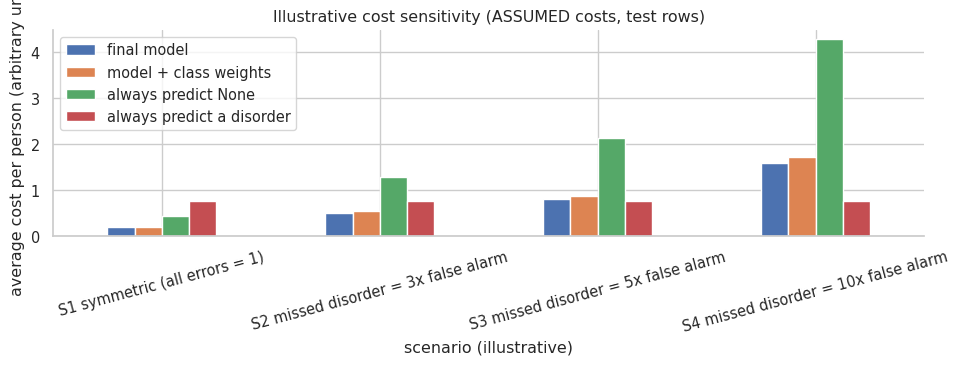

**Reading.** Under the assumed scenarios the model's average cost is S1: 0.18 (vs 0.43 for 'always None'), S2: 0.49 (vs 1.29 for 'always None'), S3: 0.81 (vs 2.14 for 'always None'), S4: 1.58 (vs 4.29 for 'always None'). These numbers only show *how conclusions would change if* missed disorders were weighted more heavily; they are **not** clinical costs and no clinical decision should be derived from them.

In [ ]:
# ILLUSTRATIVE cost scenarios. The cost values are ASSUMPTIONS for a sensitivity analysis only - no stakeholder costs were supplied and no clinical costs are implied.
scenarios = {"S1 symmetric (all errors = 1)": (1, 1, 1), "S2 missed disorder = 3x false alarm": (3, 1, 1),
             "S3 missed disorder = 5x false alarm": (5, 1, 1), "S4 missed disorder = 10x false alarm": (10, 1, 1)}

def cost_matrix(miss, alarm, wrong):
    """Rows = actual class, columns = predicted class (order: Insomnia, None, Sleep Apnea)."""
    C_ = np.zeros((3, 3)); i_ins, i_none, i_apn = 0, 1, 2
    for a in (i_ins, i_apn):
        C_[a, i_none] = miss                                   # a disorder predicted as None
        for p in (i_ins, i_apn):
            if p != a: C_[a, p] = wrong                        # one disorder confused with the other
    for p in (i_ins, i_apn): C_[i_none, p] = alarm             # None predicted as a disorder
    return C_

def avg_cost(y_true, y_pred, Cm):
    cm_ = confusion_matrix(y_true, y_pred, labels=CLASS_ORDER); return float((cm_ * Cm).sum() / cm_.sum())

rows = []
for sname, (miss, alarm, wrong) in scenarios.items():
    Cm = cost_matrix(miss, alarm, wrong)
    rows.append({"scenario (illustrative)": sname, "final model": avg_cost(yte, pred, Cm), "model + class weights": avg_cost(yte, pred_w, Cm),
                 "always predict None": avg_cost(yte, np.array(["None"] * len(yte)), Cm), "always predict a disorder": avg_cost(yte, np.array(["Sleep Apnea"] * len(yte)), Cm)})
cost_df = pd.DataFrame(rows).set_index("scenario (illustrative)"); display(cost_df.round(3)); cost_df.to_csv(OUTPUTS_DIR / "cost_sensitivity_illustrative.csv")
cost_df[["final model", "model + class weights", "always predict None", "always predict a disorder"]].plot.bar(figsize=(10, 3.8), rot=15)
plt.ylabel("average cost per person (arbitrary units)"); plt.title("Illustrative cost sensitivity (ASSUMED costs, test rows)"); savefig("cost_sensitivity.png")
say("**Reading.** Under the assumed scenarios the model's average cost is " + ", ".join(f"{s.split(' ')[0]}: {v:.2f} (vs {cost_df.loc[s,'always predict None']:.2f} for 'always None')" for s, v in cost_df['final model'].items()) +
    ". These numbers only show *how conclusions would change if* missed disorders were weighted more heavily; they are **not** clinical costs and no clinical decision should be derived from them.")

## Phase 18 — Over-fitting and under-fitting
Evidence compared: training score → group-CV score → nested-CV score → final test score, a learning curve (group-aware) and a validation curve over tree depth.

In [ ]:
gap_tab = pd.DataFrame([{"Model": n, "Train macro-F1": tuned_res[n]["fold_df"].train_macro_f1.mean(), "CV macro-F1": tuned_res[n]["fold_df"].macro_f1.mean(),
                         "Nested CV macro-F1": nested[n]["macro_f1"].mean()} for n in tuned_res]).set_index("Model")
gap_tab["Train - CV gap"] = gap_tab["Train macro-F1"] - gap_tab["CV macro-F1"]
display(gap_tab.sort_values("Train - CV gap", ascending=False))

fin_train_f1 = macro_f1(y_dev, FINAL_MODEL.predict(X_dev))
chain = pd.DataFrame({"macro-F1": [fin_train_f1, cal_res[CAL_CHOICE]["fold_df"].train_macro_f1.mean(), cal_res[CAL_CHOICE]["fold_df"].macro_f1.mean(),
                                   nested[FINAL_NAME]["macro_f1"].mean() if FINAL_NAME in nested else np.nan, metrics["Macro F1"]]},
                     index=["train (full dev, resubstitution)", "train (inside CV folds)", f"group-CV validation ({len(DEV_SPLITS)} folds)", "nested CV (tune+fit)", "final test (locked)"])
display(chain)

,Train macro-F1,CV macro-F1,Nested CV macro-F1,Train - CV gap
Model,,,,
Decision Tree,0.9136,0.8179,0.7940,0.0958
Random Forest,0.9189,0.8397,0.8433,0.0792
XGBoost,0.9267,0.8487,0.7960,0.0780
Extra Trees,0.9139,0.8444,0.8461,0.0696
HistGradientBoosting,0.9159,0.8495,0.7960,0.0664
Logistic Regression,0.9181,0.8548,0.8449,0.0633
SVM,0.9192,0.8696,0.8147,0.0496
K-Nearest Neighbors,0.9019,0.8604,0.8469,0.0415


,macro-F1
"train (full dev, resubstitution)",0.9158
train (inside CV folds),0.9192
group-CV validation (15 folds),0.8696
nested CV (tune+fit),0.8147
final test (locked),0.7070


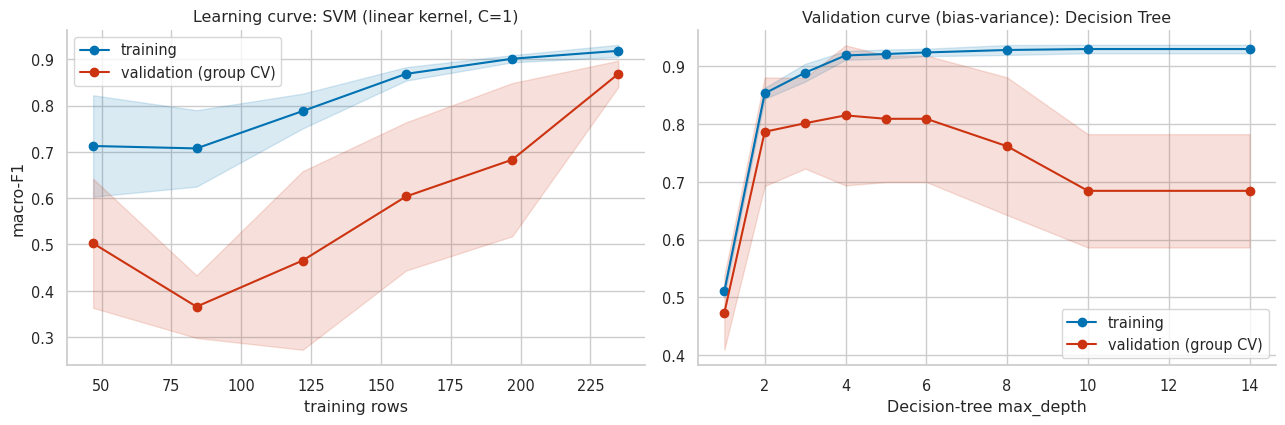

**Reading.** For **SVM (linear kernel, C=1)** the training-fold macro-F1 is 0.919 against 0.870 on validation folds (gap +0.050) and 0.707 on the locked test rows. At full size the learning curve shows a train-validation gap of +0.050; validation changed by +0.265 over the last two increments, so more data would probably help (curve still rising). The decision-tree validation curve peaks at depth 4 (validation macro-F1 0.815); at the deepest setting (depth 14) training is 0.930 against validation 0.684 (gap +0.245) — a larger gap than at the best depth is the over-fitting signature; at depth 1 training / validation are 0.510 / 0.473 (under-fitting if both are low).

In [ ]:
lc_cv = GroupCV(5, True, SEED + 600)
sizes, tr_sc, va_sc = learning_curve(clone(FINAL_ESTIMATOR), X_dev, y_dev, cv=lc_cv, train_sizes=np.linspace(0.2, 1.0, 6), scoring="f1_macro", n_jobs=N_JOBS)
depths = [1, 2, 3, 4, 5, 6, 8, 10, 14]
dt_pipe = make_pipeline(DecisionTreeClassifier(random_state=SEED), scaler=None, clip=CLIP_CHOICE)
vc_tr, vc_va = validation_curve(dt_pipe, X_dev, y_dev, param_name="clf__max_depth", param_range=depths, cv=lc_cv, scoring="f1_macro", n_jobs=N_JOBS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for scores, lab, col in [(tr_sc, "training", "#0072B2"), (va_sc, "validation (group CV)", "#CC3311")]:
    axes[0].plot(sizes, scores.mean(1), "o-", label=lab, color=col); axes[0].fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), alpha=.15, color=col)
axes[0].set_xlabel("training rows"); axes[0].set_ylabel("macro-F1"); axes[0].set_title(f"Learning curve: {FINAL_LABEL}"); axes[0].legend()
for scores, lab, col in [(vc_tr, "training", "#0072B2"), (vc_va, "validation (group CV)", "#CC3311")]:
    axes[1].plot(depths, scores.mean(1), "o-", label=lab, color=col); axes[1].fill_between(depths, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), alpha=.15, color=col)
axes[1].set_xlabel("Decision-tree max_depth"); axes[1].set_title("Validation curve (bias-variance): Decision Tree"); axes[1].legend()
savefig("overfitting_curves.png")

gap_end = tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]; slope = va_sc.mean(1)[-1] - va_sc.mean(1)[-3]
best_depth = depths[int(vc_va.mean(1).argmax())]; cvf = cal_res[CAL_CHOICE]["fold_df"]
say(f"**Reading.** For **{FINAL_LABEL}** the training-fold macro-F1 is {cvf.train_macro_f1.mean():.3f} against {cvf.macro_f1.mean():.3f} on validation folds (gap {cvf.train_macro_f1.mean()-cvf.macro_f1.mean():+.3f}) and {metrics['Macro F1']:.3f} on the locked test rows. "
    f"At full size the learning curve shows a train-validation gap of {gap_end:+.3f}; validation changed by {slope:+.3f} over the last two increments, so " +
    ("more data would probably help (curve still rising)." if slope > 0.01 else "the curve has largely flattened — more rows of the *same kind* are unlikely to help much; the ceiling is set by label noise and feature information.") +
    f" The decision-tree validation curve peaks at depth {best_depth} (validation macro-F1 {vc_va.mean(1).max():.3f}); at the deepest setting (depth {depths[-1]}) training is {vc_tr.mean(1)[-1]:.3f} against validation {vc_va.mean(1)[-1]:.3f} "
    f"(gap {vc_tr.mean(1)[-1]-vc_va.mean(1)[-1]:+.3f}) — a larger gap than at the best depth is the over-fitting signature; at depth 1 training / validation are {vc_tr.mean(1)[0]:.3f} / {vc_va.mean(1)[0]:.3f} (under-fitting if both are low).")

## Phase 19 — Model interpretability
Methods: **permutation importance** on the raw input columns (model-agnostic; computed on the *validation folds* of the development CV to check stability, plus a supplementary run on the test rows), the model's own coefficients / importances where they exist, and **SHAP**. Importances describe what the model *uses*, not what *causes* sleep disorders, and correlated predictors share credit.

,mean importance (drop in macro-F1),SD across folds,mean rank,share of folds in top-3
Blood Pressure,0.3636,0.0912,1.0667,1.0000
Quality of Sleep,0.1282,0.0886,3.8000,0.4667
Sleep Duration,0.0973,0.0865,5.0667,0.4667
Heart Rate,0.0910,0.0822,5.0000,0.5333
Occupation,0.0698,0.1062,5.9333,0.2000
Physical Activity Level,0.0648,0.0646,5.9000,0.1333
Daily Steps,0.0507,0.0516,5.9333,0.2000
Gender,0.0275,0.0432,7.1667,0.0000
BMI Category,0.0101,0.0255,8.4000,0.0000
Stress Level,0.0040,0.0098,8.6000,0.0000


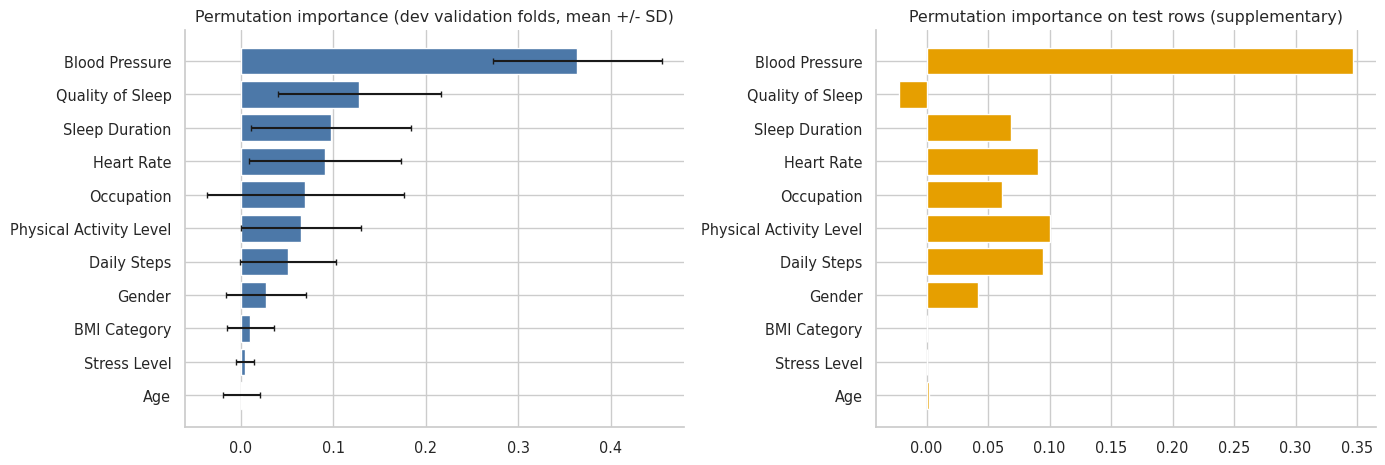

**Reading.** Most influential inputs (out-of-fold permutation importance): *Blood Pressure* (0.364), *Quality of Sleep* (0.128), *Sleep Duration* (0.097), *Heart Rate* (0.091). Stability over the 15 validation folds: average Spearman correlation of the feature rankings = **0.47**; *Blood Pressure* in the top-3 in 100% of folds, *Quality of Sleep* in the top-3 in 47% of folds, *Sleep Duration* in the top-3 in 47% of folds. The test rows rank the same top feature: **Blood Pressure**. Raw `Blood Pressure` stands for four parsed/derived pressure features at once (permuting one raw column breaks all of them). Correlated inputs can substitute for each other, so low importance does not mean uninformative.

In [ ]:
# Permutation importance on every validation fold (15 folds x 5 shuffles). A raw column is shuffled, the whole pipeline re-predicts, and we record the drop in macro-F1.
imp_rows = []
for (r, k, tr, va) in DEV_SPLITS:
    m = clone(FINAL_ESTIMATOR).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    pi = permutation_importance(m, X_dev.iloc[va], y_dev.iloc[va], scoring="f1_macro", n_repeats=5, random_state=SEED + r * 10 + k, n_jobs=1)
    imp_rows.append(pd.Series(pi.importances_mean, index=RAW_FEATURES, name=(r, k)))
imp_folds = pd.DataFrame(imp_rows); imp_mean, imp_std = imp_folds.mean(), imp_folds.std()

rank_mat = imp_folds.rank(axis=1, ascending=False)
rank_corr = pd.DataFrame(rank_mat.T.values).corr(method="spearman").values
stab_rho = rank_corr[np.triu_indices_from(rank_corr, 1)].mean()                        # how similar are the feature rankings across folds?
top3_freq = pd.Series({f: float((rank_mat[f] <= 3).mean()) for f in RAW_FEATURES})
imp_tab = pd.DataFrame({"mean importance (drop in macro-F1)": imp_mean, "SD across folds": imp_std, "mean rank": rank_mat.mean(),
                        "share of folds in top-3": top3_freq}).sort_values("mean importance (drop in macro-F1)", ascending=False)
display(imp_tab)

Xte2, yte2, _ = open_test_rows("interpretation only: permutation importance on test rows with the already-selected model")
pi_te = permutation_importance(FINAL_MODEL, Xte2, yte2, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=1)
imp_test = pd.Series(pi_te.importances_mean, index=RAW_FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); o = imp_tab.index[::-1]
axes[0].barh(o, imp_tab.loc[o, "mean importance (drop in macro-F1)"], xerr=imp_tab.loc[o, "SD across folds"], color="#4C78A8", capsize=2); axes[0].set_title("Permutation importance (dev validation folds, mean +/- SD)")
axes[1].barh(o, imp_test.loc[o], color="#E69F00"); axes[1].set_title("Permutation importance on test rows (supplementary)")
savefig("permutation_importance.png")
imp_tab.to_csv(OUTPUTS_DIR / "permutation_importance_dev_folds.csv")

say("**Reading.** Most influential inputs (out-of-fold permutation importance): " + ", ".join(f"*{f}* ({imp_tab.loc[f].iloc[0]:.3f})" for f in imp_tab.index[:4]) +
    f". Stability over the {len(DEV_SPLITS)} validation folds: average Spearman correlation of the feature rankings = **{stab_rho:.2f}**; " +
    ", ".join(f"*{f}* in the top-3 in {imp_tab.loc[f,'share of folds in top-3']:.0%} of folds" for f in imp_tab.index[:3]) + f". The test rows rank the same top feature: **{imp_test.idxmax()}**. "
    "Raw `Blood Pressure` stands for four parsed/derived pressure features at once (permuting one raw column breaks all of them). Correlated inputs can substitute for each other, so low importance does not mean uninformative.")

,coef Insomnia,coef None,coef Sleep Apnea
Age,0.1295,0.6131,-0.2327
Sleep Duration,0.0570,-0.6766,-1.0580
Quality of Sleep,-0.9693,-0.1467,0.3114
Physical Activity Level,-0.6043,-0.2076,0.7166
Stress Level,-0.0436,-0.1922,-0.3258
Heart Rate,-0.3032,-0.8214,-0.7772
Daily Steps,-0.4889,-0.9136,-0.3095
Systolic BP,0.5144,0.0318,-0.3816
Diastolic BP,0.4107,-0.1950,-0.5911
BMI Ordinal,-0.1054,-0.0939,0.1804


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr

,Insomnia,None,Sleep Apnea,total
Sleep Duration,0.0181,0.1217,0.1359,0.2757
Physical Activity Level,0.0406,0.1312,0.0907,0.2626
Diastolic BP,0.0186,0.1090,0.0905,0.2181
Systolic BP,0.0393,0.1049,0.0658,0.2100
Mean Arterial Pressure,0.0239,0.1034,0.0796,0.2069
Pulse Pressure,0.0652,0.0379,0.0853,0.1885
Daily Steps,0.0681,0.0294,0.0888,0.1863
Heart Rate,0.0485,0.0406,0.0835,0.1726
Quality of Sleep,0.0485,0.0646,0.0173,0.1303
Age,0.0390,0.0512,0.0338,0.1240


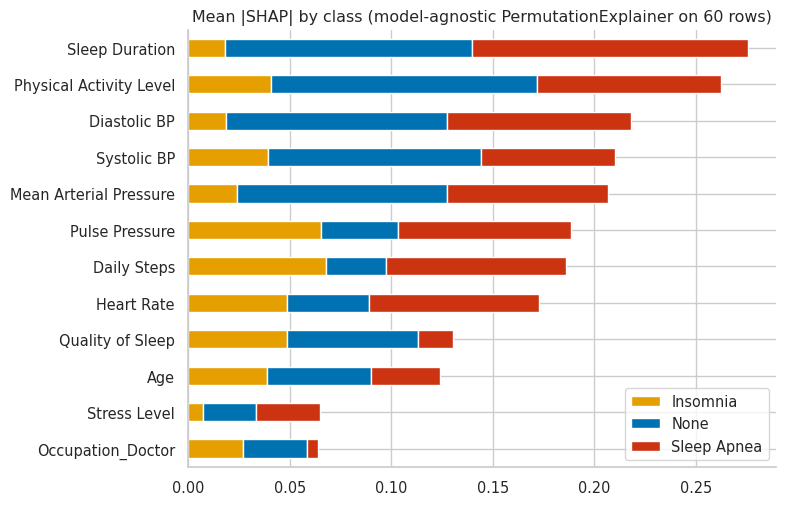

/tmp/ipykernel_1121/1984264057.py:35: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv[:, :, k_apn], Ztr, show=False, max_display=12); plt.title("SHAP beeswarm: Sleep Apnea (base model, transformed features)"); savefig("shap_beeswarm_apnea.png")


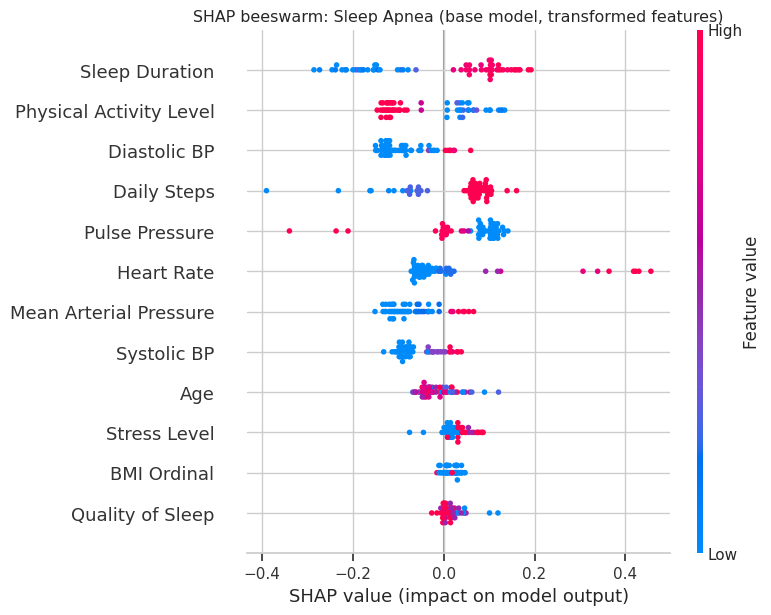

**SHAP (model-agnostic PermutationExplainer on 60 rows).** Largest mean |SHAP|: *Sleep Duration*, *Physical Activity Level*, *Diastolic BP*, *Systolic BP*, *Mean Arterial Pressure*. SHAP explains the *uncalibrated base model* on the transformed features; it shows how the model uses inputs, not causal effects.

SHAP produced: True


In [ ]:
# The model's own coefficients / importances, and SHAP (SHAP only explains the uncalibrated base model)
clf_inner = FITTED_BASE.named_steps["clf"] if hasattr(FITTED_BASE, "named_steps") else None
feat_names = feature_names(FITTED_BASE) if clf_inner is not None else []

native = None
if clf_inner is not None and hasattr(clf_inner, "feature_importances_"):
    native = pd.Series(clf_inner.feature_importances_, index=feat_names, name="impurity importance").sort_values(ascending=False)
elif clf_inner is not None and hasattr(clf_inner, "coef_"):
    native = pd.DataFrame(clf_inner.coef_.T, index=feat_names, columns=[f"coef {c}" for c in clf_inner.classes_])
if native is not None:
    display(native.head(12)); native.to_csv(OUTPUTS_DIR / "native_importance.csv")
    if isinstance(native, pd.Series):
        fig, ax = plt.subplots(figsize=(7, 5)); native.head(15)[::-1].plot.barh(ax=ax, color="#31a354"); ax.set_title(f"{FINAL_LABEL}: native importances"); savefig("native_importance.png")
else:
    print(f"{FINAL_NAME}: no native importance/coefficient attribute; permutation importance and SHAP are used instead.")

shap_done = False
if SHAP_AVAILABLE and clf_inner is not None:
    try:
        Ztr = pd.DataFrame(FITTED_BASE[:-1].transform(X_dev), columns=feat_names)           # what the classifier actually sees
        core_est = clf_inner.estimator_ if hasattr(clf_inner, "estimator_") else clf_inner
        if isinstance(core_est, (DecisionTreeClassifier, RandomForestClassifier, ExtraTreesClassifier)) or core_est.__class__.__name__ == "XGBClassifier":
            sv = shap.TreeExplainer(core_est).shap_values(Ztr, check_additivity=False); how = "TreeExplainer"
        else:
            background = shap.maskers.Independent(Ztr, max_samples=40)
            explainer = shap.Explainer(lambda Z: core_est.predict_proba(pd.DataFrame(Z, columns=feat_names)), background, algorithm="permutation")
            sv = explainer(Ztr.iloc[:60], max_evals=2 * Ztr.shape[1] + 1).values; Ztr = Ztr.iloc[:60]; how = "model-agnostic PermutationExplainer on 60 rows"
        sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
        mean_abs = pd.DataFrame(np.abs(sv).mean(axis=0), index=feat_names, columns=CLASS_ORDER)
        mean_abs["total"] = mean_abs.sum(axis=1); mean_abs = mean_abs.sort_values("total", ascending=False)
        display(mean_abs.head(12)); mean_abs.to_csv(OUTPUTS_DIR / "shap_mean_abs.csv")
        fig, ax = plt.subplots(figsize=(8, 5.2)); mean_abs.drop(columns="total").head(12)[::-1].plot.barh(stacked=True, ax=ax, color=[PALETTE[c] for c in CLASS_ORDER])
        ax.set_title(f"Mean |SHAP| by class ({how})"); savefig("shap_mean_abs.png")
        k_apn = CLASS_ORDER.index("Sleep Apnea")
        shap.summary_plot(sv[:, :, k_apn], Ztr, show=False, max_display=12); plt.title("SHAP beeswarm: Sleep Apnea (base model, transformed features)"); savefig("shap_beeswarm_apnea.png")
        shap_done = True
        say(f"**SHAP ({how}).** Largest mean |SHAP|: " + ", ".join(f"*{f}*" for f in mean_abs.index[:5]) + ". SHAP explains the *uncalibrated base model* on the transformed features; it shows how the model uses inputs, not causal effects.")
    except Exception as exc:                                  # reported, never silent
        print(f"SHAP could not be completed for {FINAL_NAME}: {type(exc).__name__}: {exc}")
print("SHAP produced:", shap_done)

## Phase 20 — Error analysis
Rows are identified only by their dataset row index (the file has no personal identifiers, and `Person ID` is deliberately not displayed).

In [ ]:
te_df = Xte.copy(); te_df["actual"] = np.asarray(yte); te_df["predicted"] = pred
for k, c in enumerate(CLASS_ORDER): te_df[f"p({c})"] = proba[:, k]
te_df["confidence"] = proba.max(axis=1); te_df["correct"] = te_df.actual == te_df.predicted

show_cols = ["actual", "predicted", "p(Insomnia)", "p(None)", "p(Sleep Apnea)", "Age", "Gender", "Occupation", "BMI Category", "Blood Pressure", "Sleep Duration", "Quality of Sleep", "Stress Level"]
wrong = te_df[~te_df.correct]
print(f"Misclassified test rows: {len(wrong)} of {len(te_df)}"); display(wrong[show_cols])

cp = pd.crosstab(te_df.actual, te_df.predicted).reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0)
print("Confusion patterns (rows = actual, columns = predicted):"); display(cp)

LOWC = 0.60; low = te_df[te_df.confidence < LOWC]
print(f"Low-confidence predictions (max p < {LOWC}): {len(low)} rows, accuracy {low.correct.mean() if len(low) else float('nan'):.2f} vs {te_df[te_df.confidence >= LOWC].correct.mean():.2f} for the rest")
te_df.assign(row_id=te_df.index).to_csv(OUTPUTS_DIR / "predictions.csv", index=False)

Misclassified test rows: 14 of 77


,actual,predicted,p(Insomnia),p(None),p(Sleep Apnea),Age,Gender,Occupation,BMI Category,Blood Pressure,Sleep Duration,Quality of Sleep,Stress Level
94,Insomnia,None,0.0000,0.9992,0.0008,36,Female,Accountant,Normal,115/75,7.2000,8,4
146,Insomnia,None,0.0078,0.9108,0.0814,39,Male,Lawyer,Normal,130/85,7.2000,8,5
165,Insomnia,None,0.0010,0.9388,0.0603,41,Male,Lawyer,Normal,130/85,7.6000,8,5
201,Insomnia,None,0.0088,0.8860,0.1052,43,Male,Engineer,Normal,130/85,7.8000,8,5
202,Insomnia,None,0.0088,0.8860,0.1052,43,Male,Engineer,Normal,130/85,7.8000,8,5
218,Sleep Apnea,None,0.0088,0.8860,0.1052,43,Male,Engineer,Normal,130/85,7.8000,8,5
278,Insomnia,Sleep Apnea,0.0051,0.1144,0.8804,50,Female,Nurse,Overweight,140/95,6.1000,6,8
280,None,Sleep Apnea,0.0068,0.1405,0.8527,50,Female,Nurse,Overweight,140/95,6.0000,6,8
306,Insomnia,None,0.2174,0.6552,0.1274,52,Female,Accountant,Overweight,130/85,6.5000,7,7
307,Insomnia,None,0.2174,0.6552,0.1274,52,Female,Accountant,Overweight,130/85,6.5000,7,7


Confusion patterns (rows = actual, columns = predicted):


predicted,Insomnia,None,Sleep Apnea
actual,,,
Insomnia,3,11,1
None,0,43,1
Sleep Apnea,0,1,17


Low-confidence predictions (max p < 0.6): 1 rows, accuracy 1.00 vs 0.82 for the rest


n  error_rate
feature      level                         
Occupation   Teacher         40      0.1250
             Nurse           53      0.1132
             Salesperson     31      0.0968
             Lawyer          24      0.0833
             Doctor          71      0.0704
             Engineer        44      0.0455
             Accountant      26      0.0000
Gender       Male           143      0.0979
             Female         154      0.0844
BMI Category Normal Weight   16      0.1875
             Overweight     121      0.1074
             Normal         151      0.0397

,n,accuracy
conf,,
"(0.0, 0.5]",2,0.0000
"(0.5, 0.6]",3,0.6667
"(0.6, 0.7]",5,0.8000
"(0.7, 0.8]",63,0.8889
"(0.8, 0.9]",84,0.9405
"(0.9, 1.0]",140,0.9214


OOF errors on rows whose feature vector has a single label (potentially reducible): 10 of 27


rows
actual      pred             
Insomnia    Sleep Apnea     4
None        Insomnia        1
            Sleep Apnea     1
Sleep Apnea Insomnia        4

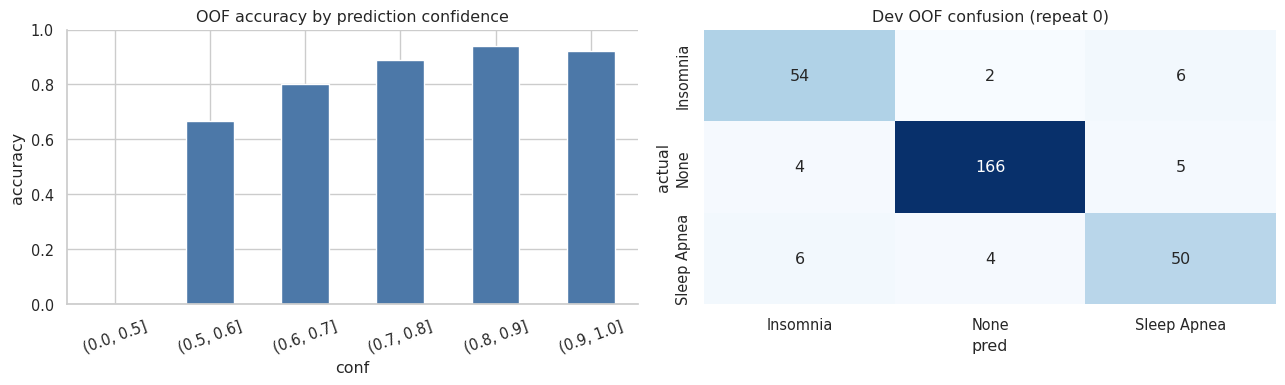

**Reading.** Test errors: 14 of 77; the most common confusion is **Insomnia predicted as None** (11 rows). On the larger development OOF set, **63% of errors fall on feature vectors that carry contradictory labels** (identical inputs, different diagnoses) — no model using these features could get them right; the oracle accuracy ceiling on the development data is 0.943 against an OOF accuracy of 0.909. Only 10 OOF errors lie on single-label vectors. Accuracy rises with confidence: (0.0, 0.5] → 0.00 (n=2), (0.5, 0.6] → 0.67 (n=3), (0.6, 0.7] → 0.80 (n=5), (0.7, 0.8] → 0.89 (n=63), (0.8, 0.9] → 0.94 (n=84), (0.9, 1.0] → 0.92 (n=140), so low-confidence predictions deserve manual review.

In [ ]:
# Larger-sample view: development OOF errors (3 repeats), and how many are explained by contradictory labels
oofp, oofpr = cal_res[CAL_CHOICE]["oof_pred"], cal_res[CAL_CHOICE]["oof_proba"]
dv = X_dev.copy(); dv["actual"] = np.asarray(y_dev); dv["pred"] = oofp[0]; dv["conf"] = oofpr[0].max(axis=1); dv["wrong"] = dv.actual != dv.pred
dv["key"] = dev_key.values; dv["n_labels_for_same_vector"] = dv.groupby("key")["actual"].transform("nunique")
dv_wrong = dv[dv.wrong]; share_conf = (dv_wrong.n_labels_for_same_vector > 1).mean()
oracle_dev = dv.groupby("key")["actual"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(dv)

by = {}
for col in ["Occupation", "Gender", "BMI Category"]:
    t = dv.groupby(col).agg(n=("wrong", "size"), error_rate=("wrong", "mean")); by[col] = t[t.n >= 10].sort_values("error_rate", ascending=False)
display(pd.concat(by, names=["feature", "level"]))

bins = pd.cut(dv.conf, [0, .5, .6, .7, .8, .9, 1.0])
acc_bin = dv.groupby(bins, observed=True).agg(n=("wrong", "size"), accuracy=("wrong", lambda s: 1 - s.mean())); display(acc_bin)
reducible = dv_wrong[dv_wrong.n_labels_for_same_vector == 1]
print(f"OOF errors on rows whose feature vector has a single label (potentially reducible): {len(reducible)} of {len(dv_wrong)}")
display(reducible.groupby(["actual", "pred"]).size().rename("rows").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
acc_bin["accuracy"].plot.bar(ax=axes[0], color="#4C78A8", rot=20); axes[0].set_ylim(0, 1); axes[0].set_title("OOF accuracy by prediction confidence"); axes[0].set_ylabel("accuracy")
sns.heatmap(pd.crosstab(dv.actual, dv.pred).reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0), annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False); axes[1].set_title("Dev OOF confusion (repeat 0)")
savefig("error_analysis.png")

off_diag = cp.where(~np.eye(3, dtype=bool)).stack()
common = (f"**{off_diag.idxmax()[0]} predicted as {off_diag.idxmax()[1]}** ({int(off_diag.max())} rows)" if len(wrong) else "none (no errors)")
say(f"**Reading.** Test errors: {len(wrong)} of {len(te_df)}; the most common confusion is {common}. On the larger development OOF set, **{share_conf:.0%} of errors fall on feature vectors that carry contradictory labels** "
    f"(identical inputs, different diagnoses) — no model using these features could get them right; the oracle accuracy ceiling on the development data is {oracle_dev:.3f} against an OOF accuracy of {1-dv.wrong.mean():.3f}. "
    f"Only {len(reducible)} OOF errors lie on single-label vectors. Accuracy rises with confidence: " + ", ".join(f"{str(i)} → {r.accuracy:.2f} (n={int(r.n)})" for i, r in acc_bin.iterrows()) + ", so low-confidence predictions deserve manual review.")

## Phase 20B — Where did the Insomnia misses on the test rows occur? (description only — no modelling decision is taken here)
Phase 14B decided, on development data and *before* the test evaluation, that the selected model is retained. The test rows are used below **only to describe** the Insomnia misses; nothing here changes the model, the threshold or any setting.

In [ ]:
ins_te = te_df[te_df.actual == "Insomnia"].copy()
n_ins_te = len(ins_te); k_ins_te = int((ins_te.predicted == "Insomnia").sum()); lo_i, hi_i = wilson(k_ins_te, n_ins_te)
dev_recall_final = cal_res[CAL_CHOICE]["pooled"]["recall_Insomnia"]

# For every test Insomnia row: which development row is its nearest neighbour (in the model's own transformed space)?
T_dev = FITTED_BASE[:-1].transform(X_dev); T_te = FITTED_BASE[:-1].transform(Xte.loc[ins_te.index])
D_ = cdist(np.asarray(T_te, dtype=float), np.asarray(T_dev, dtype=float)); nn_ = D_.argmin(axis=1)
ins_te["1-NN dev label"] = np.asarray(y_dev)[nn_]; ins_te["1-NN distance"] = D_.min(axis=1)

# ... and how are the development rows with the same occupation x BMI category labelled?
occ_dev_clean = X_dev["Occupation"].map(clean_occupation).values; bmi_dev_clean = X_dev["BMI Category"].map(clean_bmi).values; yd = np.asarray(y_dev)
def cell_labels(r):
    m = (occ_dev_clean == clean_occupation(r["Occupation"])) & (bmi_dev_clean == clean_bmi(r["BMI Category"]))
    return f"{int((yd[m] == 'Insomnia').sum())}/{int((yd[m] == 'None').sum())}/{int((yd[m] == 'Sleep Apnea').sum())}"
CELL_COL = "dev rows in same occupation x BMI (Ins/None/Apnea)"
ins_te[CELL_COL] = ins_te.apply(cell_labels, axis=1)
display(ins_te[["predicted", "p(Insomnia)", "p(None)", "p(Sleep Apnea)", "Occupation", "Age", "BMI Category", "Sleep Duration", "Quality of Sleep", "Stress Level", "1-NN dev label", "1-NN distance", CELL_COL]].round(3))

n_groups_ins = pd.Series(np.asarray(gte), index=Xte.index).loc[ins_te.index].nunique()
missed_ins = ins_te[ins_te.predicted != "Insomnia"]
share_nn_none = float((missed_ins["1-NN dev label"] == "None").mean()) if len(missed_ins) else float("nan")
share_nn_ins = float((ins_te["1-NN dev label"] == "Insomnia").mean())
no_ins_cell = float(np.mean([c.split("/")[0] == "0" for c in missed_ins[CELL_COL]])) if len(missed_ins) else float("nan")
say(f"**Reading (descriptive).** The model found {k_ins_te} of {n_ins_te} Insomnia test rows (recall {k_ins_te/n_ins_te:.2f}, Wilson 95% CI {lo_i:.2f}-{hi_i:.2f}) against a development out-of-fold Insomnia recall of {dev_recall_final:.2f}. "
    f"The {n_ins_te} test Insomnia rows come from only **{n_groups_ins} profile groups**, so the effective sample for this class is closer to {n_groups_ins} than to {n_ins_te}. "
    f"Of the {len(missed_ins)} missed rows, {share_nn_none:.0%} have a nearest development neighbour labelled *None* and {no_ins_cell:.0%} come from an occupation × BMI cell with no Insomnia row in development; overall {share_nn_ins:.0%} of test Insomnia rows have an Insomnia nearest neighbour. "
    "This is consistent with the test partition containing Insomnia *profiles* that look like None profiles to a model trained on the development profiles — exactly what a group-independent split is meant to expose — rather than a simple threshold problem. "
    "With so few groups this is a description, not a proof, and no setting was changed because of it.")

,predicted,p(Insomnia),p(None),p(Sleep Apnea),Occupation,Age,BMI Category,Sleep Duration,Quality of Sleep,Stress Level,1-NN dev label,1-NN distance,dev rows in same occupation x BMI (Ins/None/Apnea)
5,Insomnia,0.8630,0.0030,0.1340,Software Engineer,28,Obese,5.9000,4,8,Sleep Apnea,1.4140,0/0/0
94,None,0.0000,0.9990,0.0010,Accountant,36,Normal,7.2000,8,4,None,0.1080,0/26/0
146,None,0.0080,0.9110,0.0810,Lawyer,39,Normal,7.2000,8,5,None,0.1630,0/19/1
165,None,0.0010,0.9390,0.0600,Lawyer,41,Normal,7.6000,8,5,None,0.2670,0/19/1
177,Insomnia,0.7840,0.1370,0.0800,Salesperson,42,Overweight,6.5000,6,7,Insomnia,0.1080,28/2/1
201,None,0.0090,0.8860,0.1050,Engineer,43,Normal,7.8000,8,5,None,1.4180,1/41/0
202,None,0.0090,0.8860,0.1050,Engineer,43,Normal,7.8000,8,5,None,1.4180,1/41/0
247,Insomnia,0.2730,0.4100,0.3170,Engineer,44,Overweight,6.8000,7,7,Insomnia,1.9930,1/1/0
278,Sleep Apnea,0.0050,0.1140,0.8800,Nurse,50,Overweight,6.1000,6,8,Sleep Apnea,0.1080,0/5/42
306,None,0.2170,0.6550,0.1270,Accountant,52,Overweight,6.5000,7,7,None,2.3210,0/0/0


**Reading (descriptive).** The model found 3 of 15 Insomnia test rows (recall 0.20, Wilson 95% CI 0.07-0.45) against a development out-of-fold Insomnia recall of 0.87. The 15 test Insomnia rows come from only **9 profile groups**, so the effective sample for this class is closer to 9 than to 15. Of the 12 missed rows, 92% have a nearest development neighbour labelled *None* and 83% come from an occupation × BMI cell with no Insomnia row in development; overall 13% of test Insomnia rows have an Insomnia nearest neighbour. This is consistent with the test partition containing Insomnia *profiles* that look like None profiles to a model trained on the development profiles — exactly what a group-independent split is meant to expose — rather than a simple threshold problem. With so few groups this is a description, not a proof, and no setting was changed because of it.

## Phase 21 — Fairness and subgroup analysis
A 75-row test set cannot support subgroup statistics, so the **primary evidence is the development out-of-fold predictions** (n≈300, three repeats averaged); test results are shown alongside. Groups with fewer than 30 rows are flagged `SMALL n` and wide Wilson intervals are shown. Similar overall accuracy does **not** establish fairness.

In [ ]:
def subgroup_table(Xf, y_true, preds_list, col, min_n=30):
    """Accuracy, balanced accuracy, macro-F1, per-class recall and missed-disorder rate for every level of `col`."""
    d = eda_frame(Xf, y_true).assign(y=np.asarray(y_true))
    if col == "Occupation":                                           # pool occupations with fewer than 15 rows
        counts = d["Occupation"].value_counts(); d["Occupation"] = d["Occupation"].where(d["Occupation"].map(counts) >= 15, "Other (n<15 each)")
    rows = []
    for level, idx in d.groupby(col, observed=True).groups.items():
        pos = d.index.get_indexer(idx); n = len(pos); accs, bals, f1s, rec_ins, rec_apn = [], [], [], [], []
        for pr_ in preds_list:                                        # one prediction vector per CV repeat
            yt_, yp_ = d["y"].values[pos], np.asarray(pr_)[pos]
            rec = recall_score(yt_, yp_, labels=CLASS_ORDER, average=None, zero_division=0); present = np.array([c in set(yt_) for c in CLASS_ORDER])
            bals.append(rec[present].mean()); f1s.append(f1_score(yt_, yp_, labels=[c for c in CLASS_ORDER if c in set(yt_)], average="macro", zero_division=0)); accs.append((yt_ == yp_).mean())
            rec_ins.append(rec[0] if present[0] else np.nan); rec_apn.append(rec[2] if present[2] else np.nan)
        md_ = missed_disorder(d["y"].values[pos], np.asarray(preds_list[0])[pos])
        k_miss = int(np.mean([missed_disorder(d["y"].values[pos], np.asarray(p)[pos])["missed (pred None)"] for p in preds_list]))
        lo, hi = wilson(k_miss, md_["actual disorders"])
        rows.append({"group": col, "level": str(level), "n": n, "n Insomnia": int((d["y"].values[pos] == "Insomnia").sum()), "n Apnea": int((d["y"].values[pos] == "Sleep Apnea").sum()),
                     "accuracy": np.mean(accs), "balanced acc": np.mean(bals), "macro F1 (classes present)": np.mean(f1s),
                     "recall Insomnia": np.nanmean(rec_ins) if not np.all(np.isnan(rec_ins)) else np.nan, "recall Apnea": np.nanmean(rec_apn) if not np.all(np.isnan(rec_apn)) else np.nan,
                     "missed-disorder rate": k_miss / md_["actual disorders"] if md_["actual disorders"] else np.nan, "MDR lo": lo, "MDR hi": hi, "flag": "SMALL n" if n < min_n else ""})
    return pd.DataFrame(rows)

sub_oof = pd.concat([subgroup_table(X_dev, y_dev, [oofp[i] for i in range(oofp.shape[0])], c) for c in ["Gender", "Age Group", "BMI Category", "Occupation"]], ignore_index=True)
display(sub_oof.drop(columns=["MDR lo", "MDR hi"]))
sub_te = pd.concat([subgroup_table(Xte, yte, [pred], c, min_n=15) for c in ["Gender", "Age Group", "BMI Category"]], ignore_index=True)
print("Test partition (very small n - indicative only):"); display(sub_te.drop(columns=["MDR lo", "MDR hi"]))
pd.concat([sub_oof.assign(source="dev OOF"), sub_te.assign(source="test")], ignore_index=True).to_csv(OUTPUTS_DIR / "subgroup_analysis.csv", index=False)

,group,level,n,n Insomnia,n Apnea,accuracy,balanced acc,macro F1 (classes present),recall Insomnia,recall Apnea,missed-disorder rate,flag
0,Gender,Female,154,28,50,0.9156,0.9136,0.9066,0.8929,0.9400,0.0256,
1,Gender,Male,143,34,10,0.8928,0.7064,0.7121,0.8529,0.3000,0.0909,
2,Age Group,<35,80,4,8,0.8750,0.4412,0.4451,0.0000,0.3333,0.2500,
3,Age Group,35-44,118,44,8,0.9209,0.7795,0.7934,0.9773,0.4167,0.0385,
4,Age Group,45-54,64,14,14,0.9062,0.9008,0.8870,0.7857,1.0000,0.0357,
5,Age Group,55+,35,0,30,0.9143,0.7000,0.7619,NaN,1.0000,0.0000,
6,BMI Category,Normal,167,4,6,0.9421,0.4409,0.4403,0.0000,0.3333,0.6000,
7,BMI Category,Obese,9,3,6,0.4444,0.3333,0.3077,0.0000,0.6667,0.0000,SMALL n
8,BMI Category,Overweight,121,55,48,0.8871,0.8057,0.8355,0.9818,0.9167,0.0000,
9,Occupation,Accountant,26,0,0,1.0000,1.0000,1.0000,NaN,NaN,NaN,SMALL n


Test partition (very small n - indicative only):


,group,level,n,n Insomnia,n Apnea,accuracy,balanced acc,macro F1 (classes present),recall Insomnia,recall Apnea,missed-disorder rate,flag
0,Gender,Female,31,8,17,0.7097,0.6111,0.5000,0.0000,1.0000,0.2800,
1,Gender,Male,46,7,1,0.8913,0.4762,0.5128,0.4286,0.0000,0.6250,
2,Age Group,<35,2,1,0,1.0000,1.0000,1.0000,1.0000,NaN,0.0000,SMALL n
3,Age Group,35-44,50,7,1,0.8800,0.4286,0.4593,0.2857,0.0000,0.7500,
4,Age Group,45-54,25,7,17,0.6800,0.3333,0.3148,0.0000,1.0000,0.2500,
5,BMI Category,Normal,49,5,1,0.8776,0.3333,0.3116,0.0000,0.0000,1.0000,
6,BMI Category,Obese,1,1,0,1.0000,1.0000,1.0000,1.0000,NaN,0.0000,SMALL n
7,BMI Category,Overweight,27,9,17,0.7037,0.4074,0.4360,0.2222,1.0000,0.2308,


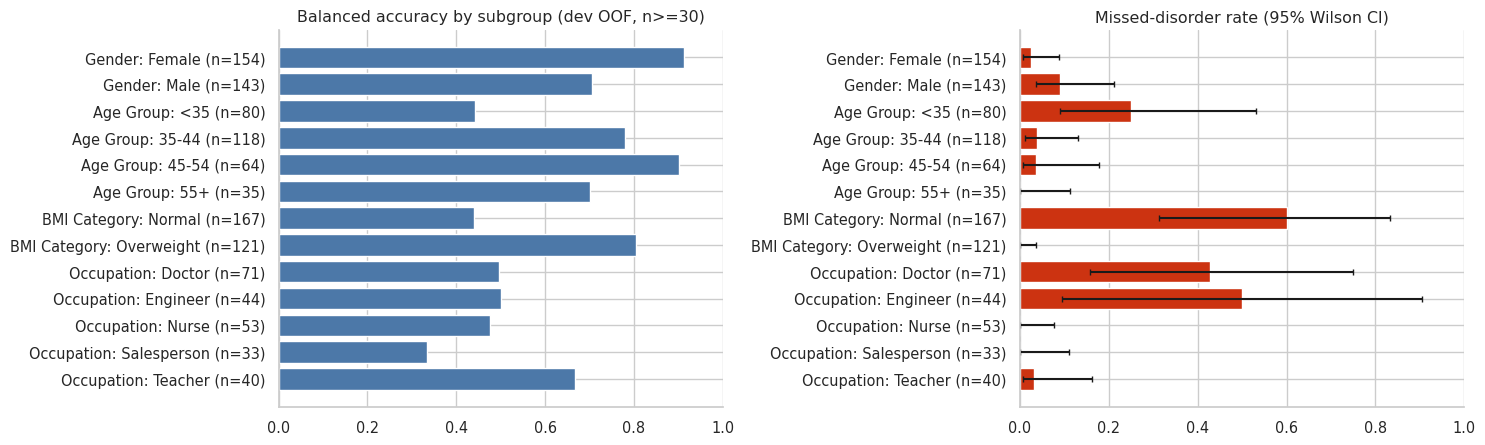

**Reading.** Largest between-level gaps among subgroups with n>=30 (missed-disorder-rate gap, balanced-accuracy gap): **Gender**: 0.07, 0.21; **Age Group**: 0.25, 0.46; **BMI Category**: 0.60, 0.36; **Occupation**: 0.50, 0.33. 4 subgroup levels are too small (n<30) for any conclusion, and the Wilson intervals overlap widely for most levels. Occupation, gender, age and BMI are tightly entangled in this file (specific occupations are almost entirely one gender or disorder), so differences may reflect that confounding or label noise rather than model bias. **No claim of fairness is made**; an audit would need larger, representative data.

In [ ]:
big = sub_oof[sub_oof.n >= 30]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6)); lab = big.group + ": " + big.level + " (n=" + big.n.astype(str) + ")"
axes[0].barh(lab[::-1], big["balanced acc"][::-1], color="#4C78A8"); axes[0].set_xlim(0, 1); axes[0].set_title("Balanced accuracy by subgroup (dev OOF, n>=30)")
mdr = big["missed-disorder rate"]; err = np.vstack([mdr - big["MDR lo"], big["MDR hi"] - mdr])
axes[1].barh(lab[::-1], mdr[::-1], xerr=err[:, ::-1], color="#CC3311", capsize=2); axes[1].set_xlim(0, 1); axes[1].set_title("Missed-disorder rate (95% Wilson CI)")
savefig("subgroup_performance.png")

disp = {c: (big[big.group == c]["missed-disorder rate"].max() - big[big.group == c]["missed-disorder rate"].min(),
            big[big.group == c]["balanced acc"].max() - big[big.group == c]["balanced acc"].min()) for c in big.group.unique()}
say("**Reading.** Largest between-level gaps among subgroups with n>=30 (missed-disorder-rate gap, balanced-accuracy gap): " + "; ".join(f"**{c}**: {v[0]:.2f}, {v[1]:.2f}" for c, v in disp.items()) +
    f". {int((sub_oof['flag']=='SMALL n').sum())} subgroup levels are too small (n<30) for any conclusion, and the Wilson intervals overlap widely for most levels. "
    "Occupation, gender, age and BMI are tightly entangled in this file (specific occupations are almost entirely one gender or disorder), so differences may reflect that confounding or label noise rather than model bias. "
    "**No claim of fairness is made**; an audit would need larger, representative data.")

## Phase 22 — Distribution shift and generalisation
What can be examined without external data: (a) development-vs-test covariate and target shift, (b) performance spread across validation folds and subgroups (above), and (c) **stress tests** that force a population shift *inside the development data*: leave-one-occupation-out and train-young/test-old. These are **not** temporal or external validation (neither exists) and are not used for model selection.

(a) Development vs test partitions - PSI / KS / chi-square (computed in Phase 4):


,feature,kind,psi,test,statistic,p_value,flag
0,Age,numeric,1.6888,KS,0.2953,0.0000,ALERT
1,Sleep Duration,numeric,2.5376,KS,0.2463,0.0009,ALERT
2,Quality of Sleep,numeric,0.2238,KS,0.2391,0.0015,WARN
3,Physical Activity Level,numeric,1.1762,KS,0.4940,0.0000,ALERT
4,Stress Level,numeric,3.1563,KS,0.3766,0.0000,ALERT
5,Heart Rate,numeric,2.1311,KS,0.2381,0.0016,ALERT
6,Daily Steps,numeric,1.6078,KS,0.5200,0.0000,ALERT
7,Gender,categorical,0.0543,chi-square,2.8397,0.0920,OK
8,Occupation,categorical,3.6054,chi-square,74.3969,0.0000,ALERT
9,BMI Category,categorical,0.0325,chi-square,1.7824,0.6188,OK


Reading guide: PSI < 0.10 stable, 0.10-0.25 moderate, > 0.25 large; a flag is a prompt to investigate, not proof of model failure.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,scenario,n_train,n_heldout,accuracy,balanced acc,macro F1 (present),recall Insomnia,recall Apnea,held-out class mix
0,hold out Occupation = Doctor,226,71,0.6056,0.4861,0.4420,0.3333,0.5000,"{'Insomnia': 3, 'None': 64, 'Sleep Apnea': 4}"
1,hold out Occupation = Nurse,244,53,0.0943,0.1580,0.2278,0.0000,0.0455,"{'Insomnia': 2, 'None': 7, 'Sleep Apnea': 44}"
2,hold out Occupation = Engineer,253,44,0.9773,0.7500,0.8275,0.5000,NaN,"{'Insomnia': 2, 'None': 42, 'Sleep Apnea': 0}"
3,hold out Occupation = Teacher,257,40,0.2500,0.3457,0.1594,0.0370,0.0000,"{'Insomnia': 27, 'None': 9, 'Sleep Apnea': 4}"
4,hold out Occupation = Salesperson,264,33,0.0606,0.3333,0.0404,0.0000,0.0000,"{'Insomnia': 28, 'None': 2, 'Sleep Apnea': 3}"
5,hold out Occupation = Accountant,271,26,1.0000,1.0000,1.0000,NaN,NaN,"{'Insomnia': 0, 'None': 26, 'Sleep Apnea': 0}"
6,hold out Occupation = Lawyer,273,24,0.9167,0.8095,0.8095,NaN,0.6667,"{'Insomnia': 0, 'None': 21, 'Sleep Apnea': 3}"
7,train Age<=44 -> test Age>=45,198,99,0.4848,0.5941,0.4109,0.9286,0.0000,"{'Insomnia': 14, 'None': 41, 'Sleep Apnea': 44}"
8,train Age>=45 -> test Age<=44,99,198,0.8838,0.6359,0.5978,0.9375,0.0000,"{'Insomnia': 48, 'None': 134, 'Sleep Apnea': 16}"


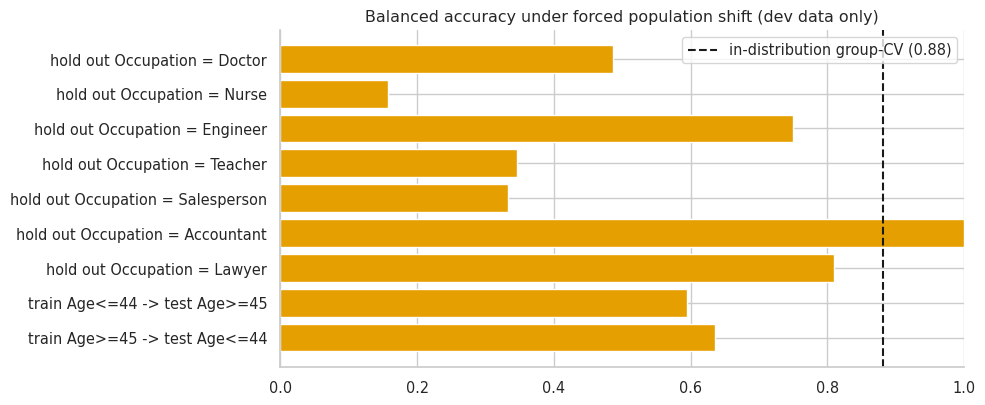

**Reading.** (a) Development-vs-test: 8 of 10 features are flagged (max PSI 3.61 for *Occupation*); with ~75 test rows and entangled categories some drift is expected by chance and is not a verdict on the model. (c) When an entire occupation or age band is withheld, balanced accuracy ranges 0.16-1.00 (mean 0.57) versus 0.88 for ordinary group-CV. Performance degrades markedly under these shifts — the honest warning for any deployment on a different population. Because occupation is both a predictor and a near-proxy for disorder class in this file, held-out-occupation results are a severe test: read them as a lower bound on robustness, not as an expected deployment accuracy.

In [ ]:
print("(a) Development vs test partitions - PSI / KS / chi-square (computed in Phase 4):"); display(drift_split)
print("Reading guide: PSI < 0.10 stable, 0.10-0.25 moderate, > 0.25 large; a flag is a prompt to investigate, not proof of model failure.")

def stress_eval(train_idx, test_idx, label):
    """Train on some development rows, test on a deliberately different part of the development data."""
    m = clone(FINAL_ESTIMATOR).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    p = m.predict(X_dev.iloc[test_idx]); yt_ = y_dev.iloc[test_idx]; present = [c for c in CLASS_ORDER if c in set(yt_)]
    rec = recall_score(yt_, p, labels=CLASS_ORDER, average=None, zero_division=0)
    return {"scenario": label, "n_train": len(train_idx), "n_heldout": len(test_idx), "accuracy": accuracy_score(yt_, p), "balanced acc": balanced_accuracy_score(yt_, p),
            "macro F1 (present)": f1_score(yt_, p, labels=present, average="macro", zero_division=0),
            "recall Insomnia": rec[0] if "Insomnia" in present else np.nan, "recall Apnea": rec[2] if "Sleep Apnea" in present else np.nan,
            "held-out class mix": dict(yt_.value_counts().reindex(CLASS_ORDER).fillna(0).astype(int))}

occ_values = eda["Occupation"].values; rows = []
for occ_name in pd.Series(occ_values).value_counts().loc[lambda s: s >= 20].index:            # hold out one whole occupation at a time
    rows.append(stress_eval(np.where(occ_values != occ_name)[0], np.where(occ_values == occ_name)[0], f"hold out Occupation = {occ_name}"))
age_values = X_dev["Age"].values
rows.append(stress_eval(np.where(age_values <= 44)[0], np.where(age_values >= 45)[0], "train Age<=44 -> test Age>=45"))
rows.append(stress_eval(np.where(age_values >= 45)[0], np.where(age_values <= 44)[0], "train Age>=45 -> test Age<=44"))
stress = pd.DataFrame(rows); display(stress); stress.to_csv(OUTPUTS_DIR / "stress_tests_shift.csv", index=False)

in_dist = cal_res[CAL_CHOICE]["pooled"]
fig, ax = plt.subplots(figsize=(10, 4.2)); ax.barh(stress.scenario[::-1], stress["balanced acc"][::-1], color="#E69F00")
ax.axvline(in_dist.balanced_accuracy, color="k", ls="--", label=f"in-distribution group-CV ({in_dist.balanced_accuracy:.2f})"); ax.legend(); ax.set_xlim(0, 1)
ax.set_title("Balanced accuracy under forced population shift (dev data only)"); savefig("stress_tests.png")

mean_stress = stress["balanced acc"].mean()
say(f"**Reading.** (a) Development-vs-test: {int((drift_split['flag']!='OK').sum())} of {len(drift_split)} features are flagged (max PSI {drift_split.psi.max():.2f} for *{drift_split.loc[drift_split.psi.idxmax(),'feature']}*); "
    "with ~75 test rows and entangled categories some drift is expected by chance and is not a verdict on the model. "
    f"(c) When an entire occupation or age band is withheld, balanced accuracy ranges {stress['balanced acc'].min():.2f}-{stress['balanced acc'].max():.2f} (mean {mean_stress:.2f}) versus {in_dist.balanced_accuracy:.2f} for ordinary group-CV. " +
    ("Performance degrades markedly under these shifts — the honest warning for any deployment on a different population." if mean_stress < in_dist.balanced_accuracy - 0.05 else "Performance degrades only modestly under these shifts.") +
    " Because occupation is both a predictor and a near-proxy for disorder class in this file, held-out-occupation results are a severe test: read them as a lower bound on robustness, not as an expected deployment accuracy.")

## Phase 23 — Saving the model, a simple prediction function and simple tests

The file saved below is the **complete fitted model**: cleaning → imputation → encoding → scaling → selection → classifier → calibration. It is the very model that was scored on the locked test rows (trained on the development partition), not a silently re-fitted variant.

We save it with `cloudpickle`, which stores the notebook's own helper functions *inside* the file, so it can be loaded in a brand-new Colab session without re-running this notebook. Then we write a prediction function that **checks the input first** and a list of small `assert` tests (no extra test framework needed).

In [ ]:
import cloudpickle, subprocess, sys, tempfile
MODEL_PATH = MODELS_DIR / "final_sleep_disorder_pipeline.pkl"
with open(MODEL_PATH, "wb") as fh:
    cloudpickle.dump(FINAL_MODEL, fh)
print(f"Saved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1024:.0f} KiB")

# Facts about the training data that the prediction function and the monitoring code use
known_occupations = sorted(set(X_dev["Occupation"].map(clean_occupation)))
train_ranges = {c: [float(X_dev[c].min()), float(X_dev[c].max())] for c in NUMERIC_RAW}
n_unique_vectors = int(n_unique_vectors)
ci_dict = {k: [float(v["2.5%"]), float(v["97.5%"])] for k, v in ci.iterrows()}
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
            "xgboost": xgboost.__version__ if XGB_AVAILABLE else "n/a", "shap": shap.__version__ if SHAP_AVAILABLE else "n/a", "cloudpickle": cloudpickle.__version__}

Saved final_sleep_disorder_pipeline.pkl: 23 KiB


In [ ]:
# Model card data ("metadata") saved next to the model
select_step = FINAL_ESTIMATOR.named_steps["select"] if hasattr(FINAL_ESTIMATOR, "named_steps") else "n/a"
meta = {
  "model_name": f"{FINAL_LABEL} ({'calibrated: ' + CAL_CHOICE if CAL_CHOICE != 'uncalibrated' else 'uncalibrated'})",
  "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
  "purpose": "Exploratory research model that predicts a recorded sleep-disorder label (None / Insomnia / Sleep Apnea). NOT a validated diagnostic tool.",
  "raw_feature_names": RAW_FEATURES, "excluded_columns": ["Person ID"], "target": TARGET, "target_classes": list(FINAL_MODEL.classes_),
  "engineered_model_features": feature_names(FITTED_BASE),
  "training_numeric_ranges": train_ranges, "categorical_levels": {"Gender": GENDER_VALUES, "BMI Category": sorted(set(BMI_ALIASES.values())), "Occupation": known_occupations},
  "preprocessing": {"features": "engineer(): label harmonisation, BP parsing, BMI ordinal, pulse & mean arterial pressure",
                    "numeric": "median imputation" + (f", learned winsorisation {CLIP_CHOICE}" if CLIP_CHOICE else ", no clipping (outliers retained)") + ", scaling per algorithm",
                    "categorical": "mode imputation + one-hot (unseen/rare -> infrequent bucket)", "selection": str(select_step)},
  "final_estimator": {"family": FINAL_NAME, "class": type(FINAL_CLF).__name__, "description": FINAL_LABEL, "kernel": getattr(FINAL_CLF, "kernel", None), "C": getattr(FINAL_CLF, "C", None),
                      "gamma_setting": str(getattr(FINAL_CLF, "gamma", None)), "gamma_is_used": (getattr(FINAL_CLF, "kernel", None) not in (None, "linear")),
                      "class_weight": str(getattr(FINAL_CLF, "class_weight", None)), "note": "For SVC(kernel='linear') the gamma hyper-parameter is accepted but has no effect."},
  "decision_rule": "predicted_class = model.predict(); probabilities are model scores from model.predict_proba() (SVC: Platt scaling with internal cross-validation) and the highest probability can, on rare rows, belong to a different class than predict(). All reported metrics use predict().",
  "calibration": CAL_CHOICE, "random_seed": SEED, "split_seed": SPLIT_SEED, "validation": "Locked group-independent hold-out + repeated StratifiedGroupKFold on profile groups (identical-profile rows)",
  "training_rows": int(len(X_dev)), "training_class_counts": y_dev.value_counts().to_dict(), "dataset_sha256": dataset_sha256,
  "evaluation": {"dev_oof_macro_f1": float(cal_res[CAL_CHOICE]["pooled"].macro_f1), "dev_cv_macro_f1_std": float(cal_res[CAL_CHOICE]["fold_df"].macro_f1.std()),
                 "nested_cv_macro_f1": float(nested[FINAL_NAME]["macro_f1"].mean()) if FINAL_NAME in nested else None,
                 "test_n": int(len(yte)), "test_metrics": {k: float(v) for k, v in metrics.items()}, "test_macro_f1_95ci_group_bootstrap": ci_dict["macro_f1"],
                 "test_per_class_recall": {c: float(per_class.loc[c, "recall"]) for c in CLASS_ORDER}},
  "library_versions": versions,
  "limitations": ["374 rows, only %d distinct feature vectors: effective sample size is small" % n_unique_vectors, "Contradictory labels on identical inputs cap achievable accuracy (oracle ceiling %.2f)" % oracle_acc_vec,
                  "No independent external or temporal validation was possible", "Profile-group validation does not prove generalisation to new people, sites or periods",
                  "Probabilities are not medically validated risk estimates", "Sleep Duration / Quality of Sleep are symptom-adjacent predictors",
                  "Training age range %d-%d; occupation mix is narrow" % (X_dev.Age.min(), X_dev.Age.max()), "Not for clinical decision-making"]}
with open(MODELS_DIR / "model_metadata.json", "w", encoding="utf-8") as fh:
    json.dump(meta, fh, indent=2)
print("Metadata saved. Keys:", list(meta))

Metadata saved. Keys: ['model_name', 'created_utc', 'purpose', 'raw_feature_names', 'excluded_columns', 'target', 'target_classes', 'engineered_model_features', 'training_numeric_ranges', 'categorical_levels', 'preprocessing', 'final_estimator', 'decision_rule', 'calibration', 'random_seed', 'split_seed', 'validation', 'training_rows', 'training_class_counts', 'dataset_sha256', 'evaluation', 'library_versions', 'limitations']


In [ ]:
class InputProblem(ValueError):
    """Raised when rows cannot be scored safely. `.issues` lists EVERY problem found."""
    def __init__(self, issues):
        self.issues = list(issues); super().__init__("Invalid input: " + " | ".join(self.issues))

def check_input(data):
    """Validate raw rows against the training schema. Returns (clean_table, warnings) or raises InputProblem."""
    df = data.copy() if isinstance(data, pd.DataFrame) else pd.DataFrame([data] if isinstance(data, dict) else list(data))
    if len(df) == 0: raise InputProblem(["Input contains no rows."])
    missing_cols = [c for c in RAW_FEATURES if c not in df.columns]
    if missing_cols: raise InputProblem([f"Missing required columns: {missing_cols}"])
    issues, warns = [], []
    extra = [c for c in df.columns if c not in RAW_FEATURES]
    if extra: warns.append(f"Unexpected columns ignored: {extra}")
    df = df[RAW_FEATURES].replace({"": np.nan})

    if df.isna().all(axis=1).any(): issues.append(f"Rows with every field missing: {df.index[df.isna().all(axis=1)].tolist()}")
    miss = df.isna().sum(); miss = miss[miss > 0]
    if len(miss): warns.append("Missing values will be imputed with training statistics: " + ", ".join(f"{k}={v}" for k, v in miss.items()))

    for col in NUMERIC_RAW:                                           # numbers: must be numeric, finite and inside the hard limits
        num = pd.to_numeric(df[col], errors="coerce")
        bad = df[col].notna() & num.isna()
        if bad.any(): issues.append(f"{col}: non-numeric values at rows {df.index[bad].tolist()}")
        if np.isinf(num).any(): issues.append(f"{col}: infinite values"); num = num.replace([np.inf, -np.inf], np.nan)
        lo, hi = HARD_BOUNDS[col]; out = num.notna() & ((num < lo) | (num > hi))
        if out.any(): issues.append(f"{col}: values outside valid range [{lo}, {hi}] at rows {df.index[out].tolist()}")
        df[col] = num

    parsed = df["Blood Pressure"].map(parse_bp)                       # blood pressure: 'SYS/DIA', plausible, systolic > diastolic
    s_, d_ = pd.Series([t[0] for t in parsed], index=df.index), pd.Series([t[1] for t in parsed], index=df.index)
    malformed = df["Blood Pressure"].notna() & s_.isna()
    if malformed.any(): issues.append(f"Blood Pressure: malformed values (expected 'SYS/DIA', e.g. '120/80') at rows {df.index[malformed].tolist()}")
    for nm, s in (("Systolic BP", s_), ("Diastolic BP", d_)):
        lo, hi = HARD_BOUNDS[nm]; out = s.notna() & ((s < lo) | (s > hi))
        if out.any(): issues.append(f"Blood Pressure: {nm} outside [{lo}, {hi}] at rows {df.index[out].tolist()}")
    if (s_.notna() & d_.notna() & (s_ <= d_)).any(): issues.append("Blood Pressure: systolic must exceed diastolic")

    bad_g = df["Gender"].notna() & df["Gender"].map(clean_gender).isna()
    if bad_g.any(): issues.append(f"Gender: unsupported values {sorted(df.loc[bad_g, 'Gender'].astype(str).unique())}; allowed {GENDER_VALUES}")
    bad_b = df["BMI Category"].notna() & df["BMI Category"].map(clean_bmi).isna()
    if bad_b.any(): issues.append(f"BMI Category: unsupported values {sorted(df.loc[bad_b, 'BMI Category'].astype(str).unique())}; allowed {sorted(BMI_ALIASES)}")
    if issues: raise InputProblem(issues)

    unseen = sorted(set(df["Occupation"].map(clean_occupation).dropna()) - set(known_occupations))     # warnings only: the model can still score these
    if unseen: warns.append(f"Unseen Occupation values {unseen}: treated as an infrequent category (prediction less reliable).")
    for col, (lo, hi) in train_ranges.items():
        n_out = int((df[col].notna() & ((df[col] < lo) | (df[col] > hi))).sum())
        if n_out: warns.append(f"{col}: {n_out} value(s) outside the training range [{lo}, {hi}] - extrapolation, interpret with caution.")
    return df.reset_index(drop=True), warns

def predict_sleep_disorder(data, model=None, return_warnings=False):
    """Predict for raw rows. predicted_class = model.predict() (the SAME rule every reported metric used)."""
    model = model if model is not None else FINAL_MODEL
    rows, warns = check_input(data)
    proba = pd.DataFrame(model.predict_proba(rows), columns=list(model.classes_))
    pred = model.predict(rows)
    out = pd.DataFrame({"predicted_class": pred, "max_probability": proba.max(axis=1).values,
                        "predicted_class_probability": [proba.at[i, c] for i, c in enumerate(pred)]})
    out = pd.concat([out, proba.add_prefix("p_")], axis=1)
    return (out, warns) if return_warnings else out

In [ ]:
# Demonstration on SYNTHETIC rows (hand-written, not real people)
synthetic = pd.DataFrame([
 {"Gender": "Male", "Age": 38, "Occupation": "Lawyer", "Sleep Duration": 7.3, "Quality of Sleep": 8, "Physical Activity Level": 60, "Stress Level": 5, "BMI Category": "Normal", "Blood Pressure": "130/85", "Heart Rate": 68, "Daily Steps": 8000},
 {"Gender": "Female", "Age": 50, "Occupation": "Nurse", "Sleep Duration": 6.1, "Quality of Sleep": 6, "Physical Activity Level": 90, "Stress Level": 8, "BMI Category": "Overweight", "Blood Pressure": "140/95", "Heart Rate": 75, "Daily Steps": 10000},
 {"Gender": "Male", "Age": 44, "Occupation": "Astronaut", "Sleep Duration": 6.4, "Quality of Sleep": 6, "Physical Activity Level": 45, "Stress Level": 7, "BMI Category": "Overweight", "Blood Pressure": "130/85", "Heart Rate": 72, "Daily Steps": 6000},
 {"Gender": "Female", "Age": 29, "Occupation": "Accountant", "Sleep Duration": None, "Quality of Sleep": 5, "Physical Activity Level": 40, "Stress Level": 7, "BMI Category": "Normal Weight", "Blood Pressure": "132/87", "Heart Rate": 80, "Daily Steps": 4000}])
synthetic.to_csv(OUTPUTS_DIR / "synthetic_inference_example.csv", index=False)

result, warns = predict_sleep_disorder(synthetic, return_warnings=True)
display(pd.concat([synthetic[["Gender", "Age", "Occupation"]], result.round(3)], axis=1))
print("Warnings returned by check_input:"); [print("  -", w) for w in warns]

print("\nInvalid input is rejected, and EVERY problem is listed:")
bad_rows = synthetic.assign(**{"Blood Pressure": ["abc", "140/95", "130/85", "90/120"], "Quality of Sleep": [6, 11, 6, 6]})
try:
    predict_sleep_disorder(bad_rows)
except InputProblem as exc:
    [print("  -", i) for i in exc.issues]

,Gender,Age,Occupation,predicted_class,max_probability,predicted_class_probability,p_Insomnia,p_None,p_Sleep Apnea
0,Male,38,Lawyer,None,0.8960,0.8960,0.0070,0.8960,0.0970
1,Female,50,Nurse,Sleep Apnea,0.8800,0.8800,0.0050,0.1140,0.8800
2,Male,44,Astronaut,None,0.5440,0.5440,0.3710,0.5440,0.0850
3,Female,29,Accountant,Sleep Apnea,0.9590,0.9590,0.0270,0.0150,0.9590


Warnings returned by check_input:
  - Missing values will be imputed with training statistics: Sleep Duration=1
  - Unseen Occupation values ['Astronaut']: treated as an infrequent category (prediction less reliable).

Invalid input is rejected, and EVERY problem is listed:
  - Quality of Sleep: values outside valid range [1, 10] at rows [1]
  - Blood Pressure: malformed values (expected 'SYS/DIA', e.g. '120/80') at rows [0]
  - Blood Pressure: systolic must exceed diastolic


### Simple tests
Each test is a small function that raises an error if something is wrong. All of them run below and a pass/fail table is printed; a failing test stops the notebook, so problems are never hidden.

In [ ]:
tests = {}
def test(fn):
    tests[fn.__name__] = fn; return fn

def must_fail(data, text):
    """The input must be rejected, and the error text must mention `text`."""
    try: predict_sleep_disorder(data)
    except InputProblem as exc: return any(text in i for i in exc.issues)
    return False

first_dev_row = X_dev.head(1)

@test
def parse_blood_pressure_valid():          assert parse_bp("126/83") == (126.0, 83.0) and parse_bp(" 120 / 80 ") == (120.0, 80.0)
@test
def parse_blood_pressure_malformed():      assert all(np.isnan(parse_bp(v)[0]) for v in ["abc", "120", "/80", "120/", "120-80", None, np.nan, ""])
@test
def bmi_aliases_are_harmonised():          assert clean_bmi("Normal Weight") == "Normal" and clean_bmi("Obesity") == "Obese" and np.isnan(clean_bmi("Giant"))
@test
def occupation_alias_and_strip():          assert clean_occupation("Sales Representative") == "Salesperson" and clean_occupation("  Nurse ") == "Nurse"
@test
def gender_cleaning():                     assert clean_gender(" male ") == "Male" and np.isnan(clean_gender("robot"))
@test
def engineered_values_are_correct():
    f = engineer(pd.DataFrame([{**synthetic.iloc[0].to_dict()}])).iloc[0]
    assert f["Systolic BP"] == 130 and f["Diastolic BP"] == 85 and f["Pulse Pressure"] == 45 and abs(f["Mean Arterial Pressure"] - (130 + 170) / 3) < 1e-9
@test
def engineer_never_uses_the_target():      assert TARGET not in engineer(X_dev).columns and "Person ID" not in RAW_FEATURES
@test
def identical_profiles_share_a_group():    assert len(set(make_groups(pd.concat([first_dev_row, first_dev_row])))) == 1
@test
def dev_and_test_share_no_rows_or_groups():
    assert len(set(dev_idx) & set(test_idx)) == 0 and len(set(g_dev) & set(groups_all[test_idx])) == 0
@test
def cv_folds_never_split_a_group():
    assert all(not (set(g_dev[tr]) & set(g_dev[va])) for _, _, tr, va in DEV_SPLITS)
@test
def class_none_is_a_label_not_missing():   assert df[TARGET].isna().sum() == 0 and (df[TARGET] == "None").sum() == 219
@test
def valid_training_rows_are_accepted():    assert len(check_input(X_dev.head(20))[0]) == 20
@test
def missing_column_is_rejected():          assert must_fail(synthetic.drop(columns=["Age"]), "Missing required columns")
@test
def malformed_blood_pressure_is_rejected():assert must_fail(synthetic.assign(**{"Blood Pressure": ["abc"] * 4}), "malformed")
@test
def inverted_blood_pressure_is_rejected(): assert must_fail(synthetic.assign(**{"Blood Pressure": ["90/120"] * 4}), "systolic must exceed")
@test
def out_of_range_value_is_rejected():      assert must_fail(synthetic.assign(**{"Quality of Sleep": [11] * 4}), "outside valid range")
@test
def non_numeric_value_is_rejected():       assert must_fail(synthetic.assign(Age=["old"] * 4), "non-numeric")
@test
def unknown_gender_is_rejected():          assert must_fail(synthetic.assign(Gender=["robot"] * 4), "Gender")
@test
def unknown_bmi_is_rejected():             assert must_fail(synthetic.assign(**{"BMI Category": ["Giant"] * 4}), "BMI Category")
@test
def empty_input_is_rejected():             assert must_fail(synthetic.iloc[0:0], "no rows")
@test
def unseen_occupation_warns_but_predicts():
    out, w = predict_sleep_disorder(synthetic.iloc[[2]], return_warnings=True)
    assert len(out) == 1 and any("Unseen Occupation" in x for x in w)
@test
def missing_value_warns_but_predicts():
    out, w = predict_sleep_disorder(synthetic.iloc[[3]], return_warnings=True)
    assert len(out) == 1 and any("Missing values" in x for x in w)
@test
def extra_column_is_ignored_with_warning():
    out, w = predict_sleep_disorder(synthetic.assign(Notes="x"), return_warnings=True)
    assert len(out) == 4 and any("Unexpected columns" in x for x in w)
@test
def single_row_dict_input_works():         assert len(predict_sleep_disorder(synthetic.iloc[0].to_dict())) == 1
@test
def probabilities_sum_to_one():            assert np.allclose(predict_sleep_disorder(X_dev.head(30))[[f"p_{c}" for c in CLASS_ORDER]].sum(axis=1), 1.0)
@test
def predicted_classes_are_known_labels():  assert set(predict_sleep_disorder(X_dev.head(50)).predicted_class) <= set(CLASS_ORDER)
@test
def prediction_is_deterministic():
    a, b = predict_sleep_disorder(X_dev.head(40)), predict_sleep_disorder(X_dev.head(40)); assert a.equals(b)
@test
def bmi_alias_gives_same_prediction():
    a = predict_sleep_disorder(synthetic.iloc[[3]]); b = predict_sleep_disorder(synthetic.iloc[[3]].assign(**{"BMI Category": "Normal"}))
    assert (a.predicted_class.values == b.predicted_class.values).all() and np.allclose(a.max_probability, b.max_probability)
@test
def deployed_function_reproduces_phase_16_exactly():
    api = predict_sleep_disorder(Xte)
    assert (api.predicted_class.values == np.asarray(pred)).all() and np.allclose(api[[f"p_{c}" for c in CLASS_ORDER]].values, proba, atol=1e-8)
    assert abs(macro_f1(yte, api.predicted_class) - metrics["Macro F1"]) < 1e-12
@test
def saved_file_reloads_to_identical_probabilities():
    with open(MODEL_PATH, "rb") as fh: reloaded = cloudpickle.load(fh)
    sample = pd.concat([X_dev.head(30), Xte.head(30)]); assert np.allclose(FINAL_MODEL.predict_proba(sample), reloaded.predict_proba(sample))
@test
def fresh_python_process_can_load_and_predict():
    with tempfile.TemporaryDirectory() as td:
        sample_csv = Path(td) / "rows.csv"; pd.concat([X_dev.head(10), Xte.head(10)]).to_csv(sample_csv, index=False)
        code = ("import pickle, pandas as pd\n"
                f"model = pickle.load(open(r'{MODEL_PATH.resolve()}', 'rb'))\n"
                f"rows = pd.read_csv(r'{sample_csv}', keep_default_na=False)\n"
                "print('|'.join(model.predict(rows)))")
        run = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, cwd=td, timeout=300)
    assert run.returncode == 0, run.stderr[-500:]
    expected = "|".join(FINAL_MODEL.predict(pd.concat([X_dev.head(10), Xte.head(10)]))); assert run.stdout.strip().endswith(expected)

results = []
for name, fn in tests.items():
    try:
        fn(); results.append({"test": name, "result": "PASS", "detail": ""})
    except Exception as exc:
        results.append({"test": name, "result": "FAIL", "detail": f"{type(exc).__name__}: {exc}"[:200]})
test_table = pd.DataFrame(results); display(test_table)
TESTS_PASSED = int((test_table.result == "PASS").sum()); TESTS_FAILED = int((test_table.result == "FAIL").sum())
print(f"{TESTS_PASSED} passed, {TESTS_FAILED} failed")
test_table.to_csv(OUTPUTS_DIR / "simple_tests.csv", index=False)
assert TESTS_FAILED == 0, "some tests failed - see the table above"

,test,result,detail
0,parse_blood_pressure_valid,PASS,
1,parse_blood_pressure_malformed,PASS,
2,bmi_aliases_are_harmonised,PASS,
3,occupation_alias_and_strip,PASS,
4,gender_cleaning,PASS,
5,engineered_values_are_correct,PASS,
6,engineer_never_uses_the_target,PASS,
7,identical_profiles_share_a_group,PASS,
8,dev_and_test_share_no_rows_or_groups,PASS,
9,cv_folds_never_split_a_group,PASS,


31 passed, 0 failed


In [ ]:
# Which library versions produced this model? (A saved model is only guaranteed to load with the same scikit-learn version.)
lines = [f"# Python {platform.python_version()} - versions used to produce the saved model"] + [f"{p}=={v}" for p, v in versions.items() if p != "python" and v != "n/a"]
(BASE / "requirements.txt").write_text("\n".join(lines) + "\n"); print("\n".join(lines))

# Python 3.13.18 - versions used to produce the saved model
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
imbalanced-learn==0.14.2
xgboost==3.4.1
shap==0.54.1
cloudpickle==3.1.2


## Phase 24 — Model-monitoring plan and reusable monitoring code
No production deployment or incoming data exists, so **no live-monitoring result is claimed**. Delivered: (1) a *reference profile* of the training data (saved with the model), (2) reusable functions for data quality, drift and performance, (3) a demonstration on a held-out batch and on a **clearly labelled synthetic perturbed batch** that proves the alerts can fire, and (4) a monitoring specification.

In [ ]:
MON_NUM = NUMERIC_RAW + ["Systolic BP", "Diastolic BP"]; MON_CAT = ["Gender", "Occupation", "BMI Category"]

def monitor_frame(X):
    """Readable monitoring table: parsed BP and harmonised category labels."""
    d = X.copy(); bp = d["Blood Pressure"].map(parse_bp)
    d["Systolic BP"] = [t[0] for t in bp]; d["Diastolic BP"] = [t[1] for t in bp]
    d["Occupation"] = d["Occupation"].map(clean_occupation); d["BMI Category"] = d["BMI Category"].map(clean_bmi); d["Gender"] = d["Gender"].map(clean_gender)
    return d

def build_reference_profile(frame, numeric_cols, categorical_cols):
    """Summarise the training data so later batches can be compared without the raw rows."""
    prof = {"n_rows": int(len(frame)), "numeric": {}, "categorical": {}}
    for c in numeric_cols:
        s = pd.to_numeric(frame[c], errors="coerce")
        prof["numeric"][c] = {"mean": float(s.mean()), "std": float(s.std()), "min": float(s.min()), "max": float(s.max()),
                              "quantiles": [float(v) for v in s.quantile(np.linspace(0, 1, 11))], "missing_rate": float(s.isna().mean())}
    for c in categorical_cols:
        vc = frame[c].astype(str).value_counts(normalize=True)
        prof["categorical"][c] = {"proportions": {k: float(v) for k, v in vc.items()}, "missing_rate": float(frame[c].isna().mean())}
    return prof

def data_quality_report(frame, profile):
    """Missing rate, out-of-reference-range rate (numbers) and unseen-category rate (categories) per column."""
    def status(miss, other):
        return "ALERT" if miss >= 0.10 or other >= 0.10 else ("WARN" if miss >= 0.02 or other >= 0.02 else "OK")
    rows = []
    for c, ref in profile["numeric"].items():
        s = pd.to_numeric(frame[c], errors="coerce"); miss = float(s.isna().mean()); oor = float(((s < ref["min"]) | (s > ref["max"])).mean())
        rows.append({"column": c, "kind": "numeric", "missing_rate": miss, "out_of_reference_range_rate": oor, "unseen_category_rate": np.nan, "status": status(miss, oor)})
    for c, ref in profile["categorical"].items():
        s = frame[c]; miss = float(s.isna().mean()); unseen = float((~s.dropna().astype(str).isin(ref["proportions"].keys())).sum() / max(len(s), 1))
        rows.append({"column": c, "kind": "categorical", "missing_rate": miss, "out_of_reference_range_rate": np.nan, "unseen_category_rate": unseen, "status": status(miss, unseen)})
    return pd.DataFrame(rows)

ref_frame = monitor_frame(X_dev)
ref_profile = build_reference_profile(ref_frame, MON_NUM, MON_CAT)
ref_profile["predicted_class_proportions"] = dict(pd.Series(cal_res[CAL_CHOICE]["oof_pred"][0]).value_counts(normalize=True))
ref_profile["mean_max_probability"] = float(cal_res[CAL_CHOICE]["oof_proba"][0].max(axis=1).mean())
ref_profile["reference_macro_f1_nested_or_oof"] = float(meta["evaluation"]["nested_cv_macro_f1"] or meta["evaluation"]["dev_oof_macro_f1"])
with open(MODELS_DIR / "reference_profile.json", "w") as fh:
    json.dump(ref_profile, fh, indent=2)
print("Reference profile saved (n=%d)." % ref_profile["n_rows"])

Reference profile saved (n=297).


In [ ]:
def monitor_batch(X_batch, y_true=None, model=None):
    """Data quality + drift + prediction shift (+ performance if labels are known) for a batch of raw rows."""
    model = model if model is not None else FINAL_MODEL
    mf = monitor_frame(X_batch)
    out = {"data_quality": data_quality_report(mf, ref_profile), "drift": drift_report(ref_frame, mf, MON_NUM, MON_CAT)}
    pr_ = model.predict_proba(X_batch); pred_ = np.array(CLASS_ORDER)[pr_.argmax(1)]
    out["prediction_shift"] = {"predicted_class_PSI": psi(pd.Series(cal_res[CAL_CHOICE]["oof_pred"][0]), pd.Series(pred_), categorical=True),
                               "mean_max_probability": float(pr_.max(1).mean()), "reference_mean_max_probability": ref_profile["mean_max_probability"]}
    if y_true is not None:
        y_true = np.asarray(y_true); rec = recall_score(y_true, pred_, labels=CLASS_ORDER, average=None, zero_division=0)
        out["performance"] = {"n": len(y_true), "accuracy": accuracy_score(y_true, pred_), "balanced_accuracy": balanced_accuracy_score(y_true, pred_), "macro_f1": macro_f1(y_true, pred_),
                              "log_loss": float(log_loss(y_true, pr_, labels=CLASS_ORDER)), **{f"recall_{c}": float(r) for c, r in zip(CLASS_ORDER, rec)}}
    return out

batch_real = monitor_batch(Xte, yte)
print("=== Held-out batch (real rows from the same file; NOT production data) ===")
display(batch_real["data_quality"]); display(batch_real["drift"]); print(batch_real["prediction_shift"]); print({k: round(v, 3) for k, v in batch_real["performance"].items()})

# A SYNTHETIC perturbed batch - fabricated on purpose to show that the alerts fire. It is NOT a monitoring result.
syn = Xte.copy().reset_index(drop=True)
syn["Heart Rate"] += 15; syn["Stress Level"] = (syn["Stress Level"] + 2).clip(upper=10)
syn.loc[syn.sample(frac=.25, random_state=SEED).index, "Age"] = np.nan
syn.loc[syn.sample(frac=.25, random_state=1).index, "Occupation"] = "Astronaut"
batch_syn = monitor_batch(syn)
print("\n=== SYNTHETIC shifted batch (demonstration that alerts fire; not real) ===")
display(batch_syn["data_quality"][batch_syn["data_quality"].status != "OK"]); display(batch_syn["drift"][batch_syn["drift"].flag != "OK"]); print(batch_syn["prediction_shift"])

n_alert_syn = int((batch_syn["drift"].flag == "ALERT").sum()) + int((batch_syn["data_quality"].status == "ALERT").sum())
say(f"**Reading.** On the held-out real batch {int((batch_real['drift'].flag!='OK').sum())} of {len(batch_real['drift'])} features are flagged (the same dev-vs-test differences as in Phase 4); "
    f"data-quality status is OK for {int((batch_real['data_quality'].status=='OK').sum())} of {len(batch_real['data_quality'])} columns. "
    f"The synthetic perturbed batch triggers **{n_alert_syn} ALERT-level signals** (heart-rate / stress drift, injected missing ages, unseen occupation), showing the monitors detect the changes they were designed for. A flag is a prompt to investigate — not proof the model has failed.")

=== Held-out batch (real rows from the same file; NOT production data) ===


,column,kind,missing_rate,out_of_reference_range_rate,unseen_category_rate,status
0,Age,numeric,0.0000,0.0000,NaN,OK
1,Sleep Duration,numeric,0.0000,0.0000,NaN,OK
2,Quality of Sleep,numeric,0.0000,0.0000,NaN,OK
3,Physical Activity Level,numeric,0.0000,0.0000,NaN,OK
4,Stress Level,numeric,0.0000,0.0000,NaN,OK
5,Heart Rate,numeric,0.0000,0.0000,NaN,OK
6,Daily Steps,numeric,0.0000,0.0000,NaN,OK
7,Systolic BP,numeric,0.0000,0.0000,NaN,OK
8,Diastolic BP,numeric,0.0000,0.0000,NaN,OK
9,Gender,categorical,0.0000,NaN,0.0000,OK


,feature,kind,psi,test,statistic,p_value,flag
0,Age,numeric,1.6888,KS,0.2953,0.0000,ALERT
1,Sleep Duration,numeric,2.5376,KS,0.2463,0.0009,ALERT
2,Quality of Sleep,numeric,0.2238,KS,0.2391,0.0015,WARN
3,Physical Activity Level,numeric,1.1762,KS,0.4940,0.0000,ALERT
4,Stress Level,numeric,3.1563,KS,0.3766,0.0000,ALERT
5,Heart Rate,numeric,2.1311,KS,0.2381,0.0016,ALERT
6,Daily Steps,numeric,1.6078,KS,0.5200,0.0000,ALERT
7,Systolic BP,numeric,3.4306,KS,0.3954,0.0000,ALERT
8,Diastolic BP,numeric,1.7393,KS,0.3853,0.0000,ALERT
9,Gender,categorical,0.0543,chi-square,2.8397,0.0920,OK


{'predicted_class_PSI': 0.44166307351722883, 'mean_max_probability': 0.8761875836273725, 'reference_mean_max_probability': 0.8750756675442429}
{'n': 77, 'accuracy': 0.805, 'balanced_accuracy': np.float64(0.685), 'macro_f1': 0.671, 'log_loss': 0.808, 'recall_Insomnia': 0.133, 'recall_None': 0.977, 'recall_Sleep Apnea': 0.944}

=== SYNTHETIC shifted batch (demonstration that alerts fire; not real) ===


,column,kind,missing_rate,out_of_reference_range_rate,unseen_category_rate,status
0,Age,numeric,0.2468,0.0000,NaN,ALERT
4,Stress Level,numeric,0.0000,0.3766,NaN,ALERT
5,Heart Rate,numeric,0.0000,0.3766,NaN,ALERT
10,Occupation,categorical,0.0000,NaN,0.2468,ALERT


,feature,kind,psi,test,statistic,p_value,flag
0,Age,numeric,1.9936,KS,0.3305,0.0000,ALERT
1,Sleep Duration,numeric,2.5376,KS,0.2463,0.0009,ALERT
2,Quality of Sleep,numeric,0.2238,KS,0.2391,0.0015,WARN
3,Physical Activity Level,numeric,1.1762,KS,0.4940,0.0000,ALERT
4,Stress Level,numeric,4.8341,KS,0.6157,0.0000,ALERT
5,Heart Rate,numeric,8.4479,KS,0.9731,0.0000,ALERT
6,Daily Steps,numeric,1.6078,KS,0.5200,0.0000,ALERT
7,Systolic BP,numeric,3.4306,KS,0.3954,0.0000,ALERT
8,Diastolic BP,numeric,1.7393,KS,0.3853,0.0000,ALERT
10,Occupation,categorical,5.2664,chi-square,127.2952,0.0000,ALERT


{'predicted_class_PSI': 3.7348445422690606, 'mean_max_probability': 0.9565711531894041, 'reference_mean_max_probability': 0.8750756675442429}


**Reading.** On the held-out real batch 10 of 12 features are flagged (the same dev-vs-test differences as in Phase 4); data-quality status is OK for 12 of 12 columns. The synthetic perturbed batch triggers **13 ALERT-level signals** (heart-rate / stress drift, injected missing ages, unseen occupation), showing the monitors detect the changes they were designed for. A flag is a prompt to investigate — not proof the model has failed.

In [ ]:
plan = pd.DataFrame([
 ["Data quality", "Missing-value rate per column", "Incoming batch vs reference profile", ">= 2 %", ">= 10 %", "Check upstream collection; imputation hides this - investigate"],
 ["Data quality", "Invalid-input rate (rows rejected by check_input)", "Inference log", "> 1 % of rows", "> 5 % of rows", "Fix upstream formatting / schema"],
 ["Data quality", "Unseen-category rate (Occupation) / out-of-training-range values", "Batch vs reference levels & ranges", ">= 2 %", ">= 10 %", "Predictions less reliable; consider re-training with new categories"],
 ["Data quality", "Schema violations (missing/extra columns, types)", "check_input", "any extra column", "any missing column / type error", "Block scoring, fix pipeline contract"],
 ["Data drift (numeric)", "PSI and two-sample KS per numeric feature", "Batch vs reference_frame", "PSI >= 0.10", "PSI >= 0.25", "Investigate population change; compare feature means / ranges"],
 ["Data drift (categorical)", "PSI and chi-square per categorical feature", "Batch vs reference_frame", "PSI >= 0.10 or p < 0.01", "PSI >= 0.25", "Check mix of occupation / gender / BMI"],
 ["Prediction drift", "PSI of predicted-class mix; mean max-probability", "Batch vs reference OOF", "PSI >= 0.10 or |delta conf| > 0.05", "PSI >= 0.25 or |delta conf| > 0.10", "Often the earliest sign of concept/covariate shift"],
 ["Performance (needs outcome labels)", "Accuracy, macro-F1, per-class recall, missed-disorder rate", "Labelled window (>= 100 rows recommended)", "macro-F1 drop > 0.05 vs reference", "macro-F1 drop > 0.10 or any class recall < 0.5", "Re-validate; consider re-training"],
 ["Calibration (needs labels)", "Log loss, Brier, class-wise ECE", "Labelled window", "log loss +15 % vs reference", "log loss +30 % or ECE doubled", "Re-calibrate on new labelled data"],
], columns=["Area", "Metric", "Reference / source", "Warning threshold", "Investigation / alert threshold", "Action"])
display(plan.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})); plan.to_csv(OUTPUTS_DIR / "monitoring_plan.csv", index=False)
say("**Reference dataset:** `models/reference_profile.json` (quantiles, ranges and category proportions of the development data). **Thresholds** are conventional starting points (PSI 0.10 / 0.25) to be tuned with stakeholders. "
    "**Cadence:** per scoring batch for data quality and drift; monthly or per 100+ newly labelled rows for performance.\n\n"
    "**Re-validation conditions:** any ALERT on ≥ 3 features, any performance ALERT, a new data source/site/population, or a schema change. **Re-training:** collect ≥ several hundred labelled rows from the *new* population, keep group-aware validation (use true subject IDs!), compare the candidate with the current model on the same hold-out, version the model + metadata, and never tune on the final hold-out.")

,Area,Metric,Reference / source,Warning threshold,Investigation / alert threshold,Action
0,Data quality,Missing-value rate per column,Incoming batch vs reference profile,>= 2 %,>= 10 %,Check upstream collection; imputation hides this - investigate
1,Data quality,Invalid-input rate (rows rejected by check_input),Inference log,> 1 % of rows,> 5 % of rows,Fix upstream formatting / schema
2,Data quality,Unseen-category rate (Occupation) / out-of-training-range values,Batch vs reference levels & ranges,>= 2 %,>= 10 %,Predictions less reliable; consider re-training with new categories
3,Data quality,"Schema violations (missing/extra columns, types)",check_input,any extra column,any missing column / type error,"Block scoring, fix pipeline contract"
4,Data drift (numeric),PSI and two-sample KS per numeric feature,Batch vs reference_frame,PSI >= 0.10,PSI >= 0.25,Investigate population change; compare feature means / ranges
5,Data drift (categorical),PSI and chi-square per categorical feature,Batch vs reference_frame,PSI >= 0.10 or p < 0.01,PSI >= 0.25,Check mix of occupation / gender / BMI
6,Prediction drift,PSI of predicted-class mix; mean max-probability,Batch vs reference OOF,PSI >= 0.10 or |delta conf| > 0.05,PSI >= 0.25 or |delta conf| > 0.10,Often the earliest sign of concept/covariate shift
7,Performance (needs outcome labels),"Accuracy, macro-F1, per-class recall, missed-disorder rate",Labelled window (>= 100 rows recommended),macro-F1 drop > 0.05 vs reference,macro-F1 drop > 0.10 or any class recall < 0.5,Re-validate; consider re-training
8,Calibration (needs labels),"Log loss, Brier, class-wise ECE",Labelled window,log loss +15 % vs reference,log loss +30 % or ECE doubled,Re-calibrate on new labelled data


**Reference dataset:** `models/reference_profile.json` (quantiles, ranges and category proportions of the development data). **Thresholds** are conventional starting points (PSI 0.10 / 0.25) to be tuned with stakeholders. **Cadence:** per scoring batch for data quality and drift; monthly or per 100+ newly labelled rows for performance.

**Re-validation conditions:** any ALERT on ≥ 3 features, any performance ALERT, a new data source/site/population, or a schema change. **Re-training:** collect ≥ several hundred labelled rows from the *new* population, keep group-aware validation (use true subject IDs!), compare the candidate with the current model on the same hold-out, version the model + metadata, and never tune on the final hold-out.

## Phase 25 — Reproducibility and experiment record

In [ ]:
t0 = time.perf_counter()
refit = clone(FINAL_UNFITTED).fit(X_dev, y_dev)
repro_ok = bool(np.allclose(refit.predict_proba(Xte), proba, atol=1e-9))
print(f"A deterministic re-fit reproduces the saved model's test probabilities: {repro_ok} ({time.perf_counter()-t0:.1f}s)")

project_meta = {"project": "Predicting Sleep Disorders", "organization": "First Quadrant Labs", "seed": SEED, "split_seed": SPLIT_SEED,
  "dataset": {"file": CSV_NAME, "sha256": dataset_sha256, "rows": int(len(raw)), "columns": int(raw.shape[1])},
  "validation": {"profile_groups": int(n_unique_profiles), "dev_rows": int(len(X_dev)), "test_rows": int(len(Xte)), "cv": "GroupCV(5) x %d repeats" % (max(s[0] for s in DEV_SPLITS) + 1), "nested_outer_folds": 5},
  "final_model": meta["model_name"], "calibration": CAL_CHOICE, "outlier_decision": "retain" if CLIP_CHOICE is None else f"winsorise {CLIP_CHOICE}", "imbalance_decision": IMBALANCE_CHOICE,
  "search_budgets": {n: {"kind": s["kind"], "n_iter": s["n_iter"], "nested_iter": s["nested_iter"]} for n, s in TUNE_SPECS.items()}, "fast_mode": FAST_MODE,
  "test_access_log": test_access_log, "library_versions": meta["library_versions"], "reproducible_refit": repro_ok}
with open(BASE / "project_metadata.json", "w") as fh:
    json.dump(project_meta, fh, indent=2, default=str)
print(json.dumps({k: project_meta[k] for k in ("seed", "split_seed", "final_model", "outlier_decision", "imbalance_decision", "reproducible_refit")}, indent=2))
print("\nTest-partition access log (the only uses of the locked test rows):"); display(pd.DataFrame(test_access_log))
assert repro_ok

A deterministic re-fit reproduces the saved model's test probabilities: True (0.1s)
{
  "seed": 42,
  "split_seed": 69,
  "final_model": "SVM (linear kernel, C=1) (uncalibrated)",
  "outlier_decision": "retain",
  "imbalance_decision": "none",
  "reproducible_refit": true
}

Test-partition access log (the only uses of the locked test rows):


,purpose,time
0,split-integrity verification (class proportion...,2026-11-10T22:55:28
1,FINAL evaluation of the selected pipeline (sin...,2026-11-10T23:20:00
2,interpretation only: permutation importance on...,2026-11-10T23:20:32


## Phase 26 — Final business insights
Statements are split into **observed patterns** (descriptive statistics of the development data) and **model-derived patterns** (what the fitted model uses). Neither is causal.

In [ ]:
d_ = eda.copy(); d_["any"] = (d_[TARGET] != "None")
gen_rate = d_.groupby("Gender")["any"].mean(); age_med = d_.groupby(TARGET)["Age"].median()
occ_n = d_["Occupation"].value_counts(); occ_rate = d_.groupby("Occupation")["any"].mean()[occ_n[occ_n >= 10].index].sort_values(ascending=False)
life_med = d_.groupby(TARGET)[["Stress Level", "Daily Steps", "Physical Activity Level"]].median(); sleep_med = d_.groupby(TARGET)[["Sleep Duration", "Quality of Sleep"]].median()
cv_med = d_.groupby(TARGET)[["Systolic BP", "Diastolic BP", "Heart Rate"]].median(); bmi_rate = d_.groupby("BMI Category", observed=True)["any"].mean()
worst_cls = per_class["recall"].idxmin(); top_feats = list(imp_tab.index[:4])

def by_class(table, col, fmt):
    return ", ".join(f"{k} {format(table.loc[k, col], fmt)}" for k in PLOT_ORDER)

say(f"""### Observed patterns (development data, n={len(d_)})
* **Demographics:** recorded disorder rate is {gen_rate.get('Female', float('nan')):.0%} among women vs {gen_rate.get('Male', float('nan')):.0%} among men; median age is {age_med['None']:.0f} (None), {age_med['Insomnia']:.0f} (Insomnia), {age_med['Sleep Apnea']:.0f} (Sleep Apnea). Highest-rate occupations (n>=10): {', '.join(f'{o} {r:.0%}' for o, r in occ_rate.head(3).items())}; lowest: {', '.join(f'{o} {r:.0%}' for o, r in occ_rate.tail(3).items())}.
* **Lifestyle:** median stress {by_class(life_med, 'Stress Level', '.0f')}; median daily steps {by_class(life_med, 'Daily Steps', ',.0f')}.
* **Sleep:** median duration {by_class(sleep_med, 'Sleep Duration', '.1f')} h; median quality {by_class(sleep_med, 'Quality of Sleep', '.0f')}.
* **BMI and cardiovascular indicators:** share with any disorder by BMI category: {', '.join(f'{k} {v:.0%}' for k, v in bmi_rate.items())}; median BP {', '.join(f"{k} {cv_med.loc[k, 'Systolic BP']:.0f}/{cv_med.loc[k, 'Diastolic BP']:.0f}" for k in PLOT_ORDER)}; median heart rate {by_class(cv_med, 'Heart Rate', '.0f')}.

### Model-derived patterns
* The final model (**{FINAL_LABEL}**, calibration: {CAL_CHOICE}) relies most on **{', '.join(top_feats)}** (out-of-fold permutation importance; average rank correlation across folds {stab_rho:.2f}).
* Test performance (n={len(yte)} rows from {len(ug)} unseen proxy groups): macro-F1 {metrics['Macro F1']:.2f} (95% interval {ci.loc['macro_f1','2.5%']:.2f}-{ci.loc['macro_f1','97.5%']:.2f}), balanced accuracy {metrics['Balanced accuracy']:.2f}; per-class recall: {', '.join(f"{c} {per_class.loc[c, 'recall']:.2f}" for c in CLASS_ORDER)}. Weakest class: **{worst_cls}**.
* Missed-disorder rate: {md_test['missed-disorder rate']:.0%} on test rows, {md_oof['missed-disorder rate']:.0%} on development out-of-fold predictions.

### Practical opportunities
* Use the analysis to **prioritise data collection**: true subject identifiers, dates, site codes and clinically verified diagnoses would allow genuine external / temporal validation.
* The model can serve as a *transparent baseline* for follow-up studies and for discussing which self-reported and cardiovascular measures co-occur with recorded disorders.
* Low-confidence predictions (max probability < 0.60) are the natural place for human review.

### Cautions
* Associations only: no causal claim is made (BMI, occupation, sleep quality and stress are entangled).
* **This model is not a substitute for professional medical assessment** and must not be used to diagnose or triage anyone.""")

### Observed patterns (development data, n=297)
* **Demographics:** recorded disorder rate is 51% among women vs 31% among men; median age is 37 (None), 44 (Insomnia), 53 (Sleep Apnea). Highest-rate occupations (n>=10): Salesperson 94%, Nurse 87%, Teacher 78%; lowest: Doctor 10%, Engineer 5%, Accountant 0%.
* **Lifestyle:** median stress None 5, Insomnia 7, Sleep Apnea 4; median daily steps None 7,000, Insomnia 6,000, Sleep Apnea 7,000.
* **Sleep:** median duration None 7.3, Insomnia 6.5, Sleep Apnea 8.0 h; median quality None 8, Insomnia 6, Sleep Apnea 9.
* **BMI and cardiovascular indicators:** share with any disorder by BMI category: Normal 6%, Obese 100%, Overweight 85%; median BP None 125/80, Insomnia 130/86, Sleep Apnea 140/95; median heart rate None 68, Insomnia 72, Sleep Apnea 69.

### Model-derived patterns
* The final model (**SVM (linear kernel, C=1)**, calibration: uncalibrated) relies most on **Blood Pressure, Quality of Sleep, Sleep Duration, Heart Rate** (out-of-fold permutation importance; average rank correlation across folds 0.47).
* Test performance (n=77 rows from 15 unseen proxy groups): macro-F1 0.71 (95% interval 0.31-0.85), balanced accuracy 0.71; per-class recall: Insomnia 0.20, None 0.98, Sleep Apnea 0.94. Weakest class: **Insomnia**.
* Missed-disorder rate: 36% on test rows, 5% on development out-of-fold predictions.

### Practical opportunities
* Use the analysis to **prioritise data collection**: true subject identifiers, dates, site codes and clinically verified diagnoses would allow genuine external / temporal validation.
* The model can serve as a *transparent baseline* for follow-up studies and for discussing which self-reported and cardiovascular measures co-occur with recorded disorders.
* Low-confidence predictions (max probability < 0.60) are the natural place for human review.

### Cautions
* Associations only: no causal claim is made (BMI, occupation, sleep quality and stress are entangled).
* **This model is not a substitute for professional medical assessment** and must not be used to diagnose or triage anyone.

## Phase 27 — Limitations and future scope

In [ ]:
say(f"""* **Dataset size and representativeness.** {len(raw)} rows but only **{n_unique_vectors} distinct feature vectors** ({n_unique_profiles} near-duplicate profiles); ages {raw.Age.min()}-{raw.Age.max()}, {raw.Occupation.nunique()} occupations (several with <5 rows). The file looks synthetic or templated; it is unlikely to represent any real population.
* **Missing information.** No polysomnography / clinical confirmation, no timestamps, subject, site or cohort identifiers, no medication, comorbidity, caffeine/alcohol or screen-time variables; the physical-activity unit is undocumented; the dictionary and file disagree (Phase 3).
* **Target-label reliability.** {profiles_conflict_vec} identical feature vectors carry contradictory labels ({rows_conflict_vec} rows); the in-sample oracle accuracy ceiling is {oracle_acc_vec:.1%}. Accuracies near that ceiling mean *the model matches the data, not that it diagnoses disease*.
* **Class imbalance.** 59 / 21 / 21 %: handled with macro-F1, per-class recall and class weights; strategy study in Phase 10 (decision: {IMBALANCE_CHOICE}). Insomnia recall stays weak (Phase 14B / 20B) and is documented, not hidden.
* **Outlier treatment.** Decision: {'retain all values' if CLIP_CHOICE is None else 'learned winsorisation'}. Values were judged plausible mostly because they recur in templated profiles; with real data this must be rechecked at source.
* **Validation limitations.** Proxy groups remove duplicate leakage but cannot prove generalisation to new people, sites or periods; the test partition has {len(yte)} rows from {len(ug)} groups (wide intervals); temporal and independent-cohort validation were impossible. Stress tests (occupation / age held out) gave balanced accuracy of {stress['balanced acc'].min():.2f}-{stress['balanced acc'].max():.2f} under forced shift.
* **Calibration.** Learned from ~300 correlated rows; decision = {CAL_CHOICE}. Probabilities are model scores, not validated risks.
* **Potential bias / fairness.** Subgroup estimates (Phase 21) are noisy and confounded; no fairness claim is made.
* **Clinical applicability.** None established. Sleep Duration and Quality of Sleep are symptom-adjacent, so a screening model using them is partly circular.
* **Deployment requirements.** Pinned library versions (`requirements.txt`), schema validation, monitoring on real incoming data, governance and clinical sign-off before any real-world use.
* **Library-version fragility.** The saved file is only guaranteed to load with the library versions listed in `requirements.txt`. Recent scikit-learn releases warn that `SVC(probability=True)` is deprecated, so a future upgrade may require re-fitting (re-validated from scratch), not just reloading the file.

**Future scope:** (1) independent external validation on a representative, clinically labelled cohort with real subject IDs; (2) temporal validation once dates exist; (3) richer features (apnea-hypopnea proxies, neck circumference, snoring, medication); (4) prospective calibration study; (5) fairness audit with adequate subgroup sizes; (6) integration of stakeholder-defined error costs.""")

* **Dataset size and representativeness.** 374 rows but only **109 distinct feature vectors** (77 near-duplicate profiles); ages 27-59, 11 occupations (several with <5 rows). The file looks synthetic or templated; it is unlikely to represent any real population.
* **Missing information.** No polysomnography / clinical confirmation, no timestamps, subject, site or cohort identifiers, no medication, comorbidity, caffeine/alcohol or screen-time variables; the physical-activity unit is undocumented; the dictionary and file disagree (Phase 3).
* **Target-label reliability.** 22 identical feature vectors carry contradictory labels (128 rows); the in-sample oracle accuracy ceiling is 93.3%. Accuracies near that ceiling mean *the model matches the data, not that it diagnoses disease*.
* **Class imbalance.** 59 / 21 / 21 %: handled with macro-F1, per-class recall and class weights; strategy study in Phase 10 (decision: none). Insomnia recall stays weak (Phase 14B / 20B) and is documented, not hidden.
* **Outlier treatment.** Decision: retain all values. Values were judged plausible mostly because they recur in templated profiles; with real data this must be rechecked at source.
* **Validation limitations.** Proxy groups remove duplicate leakage but cannot prove generalisation to new people, sites or periods; the test partition has 77 rows from 15 groups (wide intervals); temporal and independent-cohort validation were impossible. Stress tests (occupation / age held out) gave balanced accuracy of 0.16-1.00 under forced shift.
* **Calibration.** Learned from ~300 correlated rows; decision = uncalibrated. Probabilities are model scores, not validated risks.
* **Potential bias / fairness.** Subgroup estimates (Phase 21) are noisy and confounded; no fairness claim is made.
* **Clinical applicability.** None established. Sleep Duration and Quality of Sleep are symptom-adjacent, so a screening model using them is partly circular.
* **Deployment requirements.** Pinned library versions (`requirements.txt`), schema validation, monitoring on real incoming data, governance and clinical sign-off before any real-world use.
* **Library-version fragility.** The saved file is only guaranteed to load with the library versions listed in `requirements.txt`. Recent scikit-learn releases warn that `SVC(probability=True)` is deprecated, so a future upgrade may require re-fitting (re-validated from scratch), not just reloading the file.

**Future scope:** (1) independent external validation on a representative, clinically labelled cohort with real subject IDs; (2) temporal validation once dates exist; (3) richer features (apnea-hypopnea proxies, neck circumference, snoring, medication); (4) prospective calibration study; (5) fairness audit with adequate subgroup sizes; (6) integration of stakeholder-defined error costs.

## Phase 28 — Final conclusion

In [ ]:
tuned_gain = ba["Gain from tuning (re-eval - default)"]; nested_col = "Nested CV macro-F1 (unbiased for tune-then-fit)"
say(f"""**Problem.** Predict recorded sleep-disorder status (None / Insomnia / Sleep Apnea) from demographic, lifestyle, sleep and cardiovascular variables — an exploratory, non-diagnostic model.

**Data and quality.** {len(raw)} rows x {raw.shape[1]} columns; the class label 'None' must not be parsed as missing. {n_unique_vectors} distinct feature vectors, {profiles_conflict_vec} with contradictory labels (oracle ceiling {oracle_acc_vec:.1%}); label aliases harmonised; no rows deleted.

**EDA.** Strongest associations with the target: {', '.join(biv.feature.head(4))}; recorded-disorder share by BMI: {', '.join(f'{k} {v:.0%}' for k, v in bmi_rate.items())}.

**Outliers.** {int(outl['n_outliers (1.5 IQR)'].sum())} IQR flags, {int(plaus.n_outside_hard.sum())} impossible values; decision: {'retain all original values' if CLIP_CHOICE is None else 'learned winsorisation inside the pipeline'} (macro-F1 effect of treatment {decisions.worst_delta.min():+.3f} to {decisions.best_delta.max():+.3f}).

**Feature engineering and validation.** Blood pressure parsed; BMI ordinal; pulse / mean arterial pressure derived; Person ID excluded. Validation: locked group-independent test ({len(yte)} rows) + {len(DEV_SPLITS)} repeated StratifiedGroupKFold folds on proxy groups + nested CV; random CV would inflate macro-F1 by {infl['inflation (random - group)'].min():+.3f} to {infl['inflation (random - group)'].max():+.3f}. External and temporal validation were impossible and are not claimed.

**Models.** {len(model_res)} classifiers trained and cross-validated (+ 3 baselines, 2 meta-ensembles). Best untuned: {best_def} (macro-F1 {default_tab.loc[best_def, 'Macro F1']:.3f}); majority baseline {BASELINE_RES['pooled'].macro_f1:.3f}. Tuning changed OOF macro-F1 by {tuned_gain.min():+.3f} to {tuned_gain.max():+.3f}; nested-CV best {ba[nested_col].max():.3f} ({ba[nested_col].idxmax()}), and many models are statistically indistinguishable.

**Final model.** **{FINAL_LABEL}**, chosen by a documented multi-criteria framework (performance, minority recall, stability, log loss, over-fitting, interpretability, speed, deployment); calibration: {CAL_CHOICE}.

**Final test metrics (n={len(yte)}).** accuracy {metrics['Accuracy']:.3f}, balanced accuracy {metrics['Balanced accuracy']:.3f}, macro-F1 {metrics['Macro F1']:.3f} [{ci.loc['macro_f1','2.5%']:.2f}-{ci.loc['macro_f1','97.5%']:.2f}], ROC-AUC (OvR) {metrics['ROC-AUC (OvR macro)']:.3f}, log loss {metrics['Log loss']:.3f}, MCC {metrics['Matthews corr. coef.']:.3f}. Per-class recall: {', '.join(f"{c} {per_class.loc[c, 'recall']:.2f}" for c in CLASS_ORDER)}.

**Calibration, errors, interpretability.** Calibration comparison on development data selected *{CAL_CHOICE}*; {share_conf:.0%} of development out-of-fold errors sit on feature vectors whose label contradicts another row; most important inputs: {', '.join(top_feats)}.

**Deployment readiness.** One self-contained saved pipeline (cloudpickle), input-validating `predict_sleep_disorder()`, metadata, pinned versions; {TESTS_PASSED} simple tests passed in this run (including a fresh-Python-process reload); monitoring design + reusable code (no live monitoring claimed).

**Limitations / next steps.** Small, templated, label-noisy data; no external validation; probabilities not calibrated for clinical use. Recommended: independent validation on representative, clinically labelled data with real subject identifiers and timestamps. *Not a substitute for professional medical assessment.*""")

**Problem.** Predict recorded sleep-disorder status (None / Insomnia / Sleep Apnea) from demographic, lifestyle, sleep and cardiovascular variables — an exploratory, non-diagnostic model.

**Data and quality.** 374 rows x 13 columns; the class label 'None' must not be parsed as missing. 109 distinct feature vectors, 22 with contradictory labels (oracle ceiling 93.3%); label aliases harmonised; no rows deleted.

**EDA.** Strongest associations with the target: Occupation, Diastolic BP, Systolic BP, BMI Category; recorded-disorder share by BMI: Normal 6%, Obese 100%, Overweight 85%.

**Outliers.** 14 IQR flags, 0 impossible values; decision: retain all original values (macro-F1 effect of treatment -0.008 to +0.014).

**Feature engineering and validation.** Blood pressure parsed; BMI ordinal; pulse / mean arterial pressure derived; Person ID excluded. Validation: locked group-independent test (77 rows) + 15 repeated StratifiedGroupKFold folds on proxy groups + nested CV; random CV would inflate macro-F1 by +0.016 to +0.021. External and temporal validation were impossible and are not claimed.

**Models.** 8 classifiers trained and cross-validated (+ 3 baselines, 2 meta-ensembles). Best untuned: SVM (macro-F1 0.863); majority baseline 0.247. Tuning changed OOF macro-F1 by +0.000 to +0.050; nested-CV best 0.847 (K-Nearest Neighbors), and many models are statistically indistinguishable.

**Final model.** **SVM (linear kernel, C=1)**, chosen by a documented multi-criteria framework (performance, minority recall, stability, log loss, over-fitting, interpretability, speed, deployment); calibration: uncalibrated.

**Final test metrics (n=77).** accuracy 0.818, balanced accuracy 0.707, macro-F1 0.707 [0.31-0.85], ROC-AUC (OvR) 0.893, log loss 0.808, MCC 0.692. Per-class recall: Insomnia 0.20, None 0.98, Sleep Apnea 0.94.

**Calibration, errors, interpretability.** Calibration comparison on development data selected *uncalibrated*; 63% of development out-of-fold errors sit on feature vectors whose label contradicts another row; most important inputs: Blood Pressure, Quality of Sleep, Sleep Duration, Heart Rate.

**Deployment readiness.** One self-contained saved pipeline (cloudpickle), input-validating `predict_sleep_disorder()`, metadata, pinned versions; 31 simple tests passed in this run (including a fresh-Python-process reload); monitoring design + reusable code (no live monitoring claimed).

**Limitations / next steps.** Small, templated, label-noisy data; no external validation; probabilities not calibrated for clinical use. Recommended: independent validation on representative, clinically labelled data with real subject identifiers and timestamps. *Not a substitute for professional medical assessment.*

## Phase 29 — Dashboard-ready exports and specification
No Power BI / Tableau is available here, so **no `.pbix` / `.twb` file is claimed**. All dashboard data are written as CSV files (no personal identifiers; rows are indexed by dataset position only) together with a page-by-page design specification.

In [ ]:
def save_csv(table, name, index=False):
    """Write a table to outputs/ and also copy it to the dashboard folder."""
    table.to_csv(OUTPUTS_DIR / name, index=index); shutil.copy(OUTPUTS_DIR / name, DASH_DIR / name)

def read_saved(name):
    return pd.read_csv(OUTPUTS_DIR / name, keep_default_na=False)       # keep_default_na=False: the class label "None" must stay a label

# 1) model comparison (default, tuned, ensembles, nested CV)
mc = pd.concat([default_tab.assign(stage="default (untuned)"),
                cmp.loc[[n for n in cmp.index if n.endswith("(tuned)")]].assign(stage="tuned"),
                cmp.loc[list(ens_res)].assign(stage="meta-ensemble")]).reset_index().rename(columns={"index": "Model"})
mc["Nested CV Macro F1"] = mc["Model"].str.replace(" (tuned)", "", regex=False).map({n: v["macro_f1"].mean() for n, v in nested.items()})
mc["Selected as final"] = mc["Model"].str.replace(" (tuned)", "", regex=False).eq(FINAL_NAME) & mc["stage"].ne("default (untuned)")
save_csv(mc, "model_comparison.csv")

# 2) evaluation metrics (test + development out-of-fold) with bootstrap intervals
ev = pd.concat([test_metrics.rename(columns={"test": "value"}).assign(split="test", ci_low=np.nan, ci_high=np.nan),
                pd.DataFrame({"value": [cal_res[CAL_CHOICE]["pooled"].macro_f1, cal_res[CAL_CHOICE]["pooled"].balanced_accuracy, cal_res[CAL_CHOICE]["pooled"].accuracy]},
                             index=["Macro F1", "Balanced accuracy", "Accuracy"]).assign(split="dev OOF", ci_low=np.nan, ci_high=np.nan)])
for key, label in [("macro_f1", "Macro F1"), ("balanced_accuracy", "Balanced accuracy"), ("accuracy", "Accuracy")]:
    ev.loc[(ev.index == label) & (ev.split == "test"), ["ci_low", "ci_high"]] = [ci.loc[key, "2.5%"], ci.loc[key, "97.5%"]]
save_csv(ev.rename_axis("metric").reset_index(), "evaluation_metrics.csv")

# 3) classification report, confusion matrix, feature importance
save_csv(pd.DataFrame(classification_report(yte, pred, labels=CLASS_ORDER, output_dict=True, zero_division=0)).T.rename_axis("label").reset_index(), "classification_report.csv")
save_csv(pd.DataFrame([{"actual": a, "predicted": p, "count": int(cm[i, j]), "share_of_actual": float(cm_norm[i, j])} for i, a in enumerate(CLASS_ORDER) for j, p in enumerate(CLASS_ORDER)]), "confusion_matrix.csv")
save_csv(imp_tab.rename_axis("feature").reset_index().assign(test_importance=lambda d: d.feature.map(imp_test)), "feature_importance.csv")

# 4) files that already exist are simply copied
for name in ["predictions.csv", "subgroup_analysis.csv"]:
    shutil.copy(OUTPUTS_DIR / name, DASH_DIR / name)
save_csv(read_saved("data_quality_issues.csv"), "data_quality_issues.csv"); save_csv(read_saved("monitoring_plan.csv"), "monitoring_plan.csv")
save_csv(read_saved("fn_fp_by_class_test.csv"), "fn_fp_by_class_test.csv"); save_csv(biv, "eda_bivariate_tests.csv"); save_csv(crit.reset_index(), "model_selection_matrix.csv")

# 5) EDA summary and target distribution
eda_sum = eda[eda_num].describe().T.rename_axis("feature").reset_index().merge(
    eda.groupby(TARGET)[eda_num].median().T.add_prefix("median_").rename_axis("feature").reset_index(), on="feature")
save_csv(eda_sum, "eda_summary.csv")
save_csv(pd.DataFrame({"overall": y_all.value_counts(), "development": y_dev.value_counts(), "test": yte.value_counts()}).reindex(CLASS_ORDER).rename_axis("Sleep Disorder").reset_index(), "target_distribution.csv")

# 6) drift reference statistics (from the reference profile of Phase 24)
ref_rows = [{"feature": k, "kind": "numeric", "level": "", "mean": v["mean"], "std": v["std"], "min": v["min"], "max": v["max"], "proportion": np.nan, "missing_rate": v["missing_rate"]} for k, v in ref_profile["numeric"].items()]
ref_rows += [{"feature": k, "kind": "categorical", "level": lv, "mean": np.nan, "std": np.nan, "min": np.nan, "max": np.nan, "proportion": pr, "missing_rate": v["missing_rate"]}
             for k, v in ref_profile["categorical"].items() for lv, pr in v["proportions"].items()]
save_csv(pd.DataFrame(ref_rows), "drift_reference_statistics.csv")

# 7) calibration curve points
cal_pts = []
for meth in cal_res:
    for k, c in enumerate(CLASS_ORDER):
        pp = cal_res[meth]["oof_proba"][:, :, k].ravel(); yy = np.tile((np.asarray(y_dev) == c).astype(int), cal_res[meth]["oof_proba"].shape[0])
        frac, mean_pred = calibration_curve(yy, pp, n_bins=6, strategy="quantile")
        cal_pts += [{"method": meth, "class": c, "mean_predicted": a, "observed_frequency": b} for a, b in zip(mean_pred, frac)]
save_csv(pd.DataFrame(cal_pts), "calibration_curve_points.csv")

# 8) one row per person-record (position only - no identifiers)
dash_ds = eda_frame(X_all, y_all).assign(split=np.where(np.isin(np.arange(len(X_all)), test_idx), "test", "development"), row_id=X_all.index)[
    ["row_id", "split", "Gender", "Age", "Age Group", "Occupation", "Sleep Duration", "Quality of Sleep", "Physical Activity Level", "Stress Level", "BMI Category",
     "Systolic BP", "Diastolic BP", "Pulse Pressure", "Heart Rate", "Daily Steps", TARGET]]
save_csv(dash_ds, "dashboard_dataset.csv")

exports = sorted(p.name for p in DASH_DIR.glob("*.csv")); print(f"{len(exports)} dashboard CSV files in {DASH_DIR}:"); print("\n".join(f"  - {e}" for e in exports))
pii = [c for c in dash_ds.columns if "id" in c.lower() and c != "row_id"]; assert not pii, pii

17 dashboard CSV files in sleep_disorder_project/dashboard/dashboard_data:
  - calibration_curve_points.csv
  - classification_report.csv
  - confusion_matrix.csv
  - dashboard_dataset.csv
  - data_quality_issues.csv
  - drift_reference_statistics.csv
  - eda_bivariate_tests.csv
  - eda_summary.csv
  - evaluation_metrics.csv
  - feature_importance.csv
  - fn_fp_by_class_test.csv
  - model_comparison.csv
  - model_selection_matrix.csv
  - monitoring_plan.csv
  - predictions.csv
  - subgroup_analysis.csv
  - target_distribution.csv


In [ ]:
spec = f"""# Dashboard specification - Predicting Sleep Disorders (Power BI / Tableau)

*Exploratory analysis only - not a diagnostic tool. Data files: `dashboard/dashboard_data/*.csv` (no personal identifiers). No .pbix/.twb file was generated (no BI tool in the build environment).*

**Global filters (all pages):** Split (development/test) - Gender - Age Group - BMI Category - Occupation.
**Colour convention:** None = blue (#0072B2), Insomnia = orange (#E69F00), Sleep Apnea = vermilion (#CC3311); colour-blind safe.

| # | Page | Source file(s) | Visuals | KPIs / measures |
|---|---|---|---|---|
| 1 | **Project overview and KPIs** | evaluation_metrics.csv, model_comparison.csv | KPI cards, caveat banner | Final model ({FINAL_LABEL}); test macro-F1 (+95% CI); balanced accuracy; ROC-AUC; missed-disorder rate; models compared ({len(model_res)}) |
| 2 | **Dataset overview** | dashboard_dataset.csv, data_quality_issues.csv, eda_summary.csv | data-quality issue table, descriptive statistics, rows by split | Rows ({len(raw)}), distinct profiles ({n_unique_vectors}), conflicting-label vectors ({profiles_conflict_vec}), oracle ceiling ({oracle_acc_vec:.0%}) |
| 3 | **Sleep disorder distribution** | target_distribution.csv, dashboard_dataset.csv | column chart by split, 100 % stacked bar by BMI | Class counts / %; imbalance ratio |
| 4 | **Demographic analysis** | dashboard_dataset.csv, eda_bivariate_tests.csv | stacked bars: gender, age group, occupation (show n); effect-size bars | Disorder rate by group; Cramer's V |
| 5 | **Lifestyle and sleep analysis** | dashboard_dataset.csv | box plots of stress, steps, activity, sleep duration, quality by disorder; scatter duration vs quality | Median by class |
| 6 | **Model comparison** | model_comparison.csv, model_selection_matrix.csv | macro-F1 bars with CV SD, train-vs-CV gap, decision-score ranking | Macro-F1, balanced acc., nested CV, gap |
| 7 | **Final model performance** | evaluation_metrics.csv, classification_report.csv, confusion_matrix.csv, calibration_curve_points.csv, fn_fp_by_class_test.csv | confusion-matrix heat map, per-class P/R/F1 bars, reliability diagram | Per-class recall / FNR, log loss, Brier |
| 8 | **Feature importance** | feature_importance.csv | bar chart with error bars (fold SD), test-importance markers | Mean drop in macro-F1; share of folds in top-3 |
| 9 | **Error and subgroup analysis** | predictions.csv, subgroup_analysis.csv, drift_reference_statistics.csv | misclassified rows (row_id only), subgroup bars with CI, small-n flag, drift reference table | Missed-disorder rate by subgroup; SMALL-n flag |

**Notes for builders.** (1) Always show sample sizes; subgroups with n<30 must carry a warning. (2) Show the caveat that all metrics come from one small, duplicated, templated dataset. (3) Do not present probabilities as medical risk."""
(BASE / "dashboard" / "dashboard_specification.md").write_text(spec, encoding="utf-8"); print("dashboard_specification.md written")

dashboard_specification.md written


In [ ]:
card = f"""# Model card - Sleep Disorder classifier (exploratory)

**Model:** {meta['model_name']}  |  **Created (UTC):** {meta['created_utc']}  |  **Artifact:** `models/final_sleep_disorder_pipeline.pkl`
**Owner:** First Quadrant Labs project team  |  **Status:** research prototype - NOT clinically validated

## Intended use
Exploring which lifestyle, sleep and cardiovascular variables co-occur with a recorded sleep-disorder label, and serving as a transparent baseline for future studies.
**Out of scope:** diagnosis, triage, treatment decisions, insurance/employment decisions, or any use on populations unlike the training data.

## Data
Public sleep-health-and-lifestyle CSV, {len(raw)} rows (SHA-256 `{dataset_sha256[:16]}...`). Only {n_unique_vectors} distinct feature vectors; contradictory labels on {profiles_conflict_vec} identical vectors (oracle ceiling {oracle_acc_vec:.1%}). Ages {raw.Age.min()}-{raw.Age.max()}. Likely synthetic/templated. Classes: None {int((y_all=='None').sum())}, Insomnia {int((y_all=='Insomnia').sum())}, Sleep Apnea {int((y_all=='Sleep Apnea').sum())}.
Inputs (raw schema): {', '.join(RAW_FEATURES)}. `Person ID` is excluded.

## Training and validation
Locked group-independent test partition ({len(Xte)} rows); development data ({len(X_dev)} rows) used for repeated StratifiedGroupKFold on proxy groups, nested-CV model assessment, tuning (macro-F1) and calibration ({CAL_CHOICE}). Imbalance decision: {IMBALANCE_CHOICE}. Outlier decision: {'retain' if CLIP_CHOICE is None else 'winsorise'}.

## Performance
| Metric | Dev OOF / CV | Test (n={len(yte)}) |
|---|---|---|
| Macro-F1 | {cal_res[CAL_CHOICE]['pooled'].macro_f1:.3f} (fold SD {cal_res[CAL_CHOICE]['fold_df'].macro_f1.std():.3f}) | {metrics['Macro F1']:.3f} (95% CI {ci.loc['macro_f1','2.5%']:.2f}-{ci.loc['macro_f1','97.5%']:.2f}) |
| Balanced accuracy | {cal_res[CAL_CHOICE]['pooled'].balanced_accuracy:.3f} | {metrics['Balanced accuracy']:.3f} |
| Accuracy | {cal_res[CAL_CHOICE]['pooled'].accuracy:.3f} | {metrics['Accuracy']:.3f} |
| Log loss | {cal_res[CAL_CHOICE]['pooled'].log_loss:.3f} | {metrics['Log loss']:.3f} |
Per-class test recall: {', '.join(f"{c} {per_class.loc[c, 'recall']:.2f} (n={int(per_class.loc[c, 'support'])})" for c in CLASS_ORDER)}. Missed-disorder rate: test {md_test['missed-disorder rate']:.0%}, dev OOF {md_oof['missed-disorder rate']:.0%}.

## Estimator and decision rule
Actual estimator inside the saved pipeline: `{FINAL_CLF!r}` ({meta['final_estimator']['description']}), after feature engineering, imputation/encoding/scaling and the selection step `{meta['preprocessing']['selection']}`. {meta['final_estimator']['note']}
Predicted class = `model.predict()` (the rule used for every metric above). Probabilities are model scores (calibration choice: {CAL_CHOICE}) and can, on rare rows, favour a different class than `predict()`; `predict_sleep_disorder()` reports both `max_probability` and `predicted_class_probability`.

## Known weakness - Insomnia recall
Development out-of-fold Insomnia recall {ins_dev_recall:.2f} (per-fold range {fold_recall.recall_Insomnia.min():.2f}-{fold_recall.recall_Insomnia.max():.2f}); locked-test Insomnia recall {per_class.loc['Insomnia','recall']:.2f} (n={int(per_class.loc['Insomnia','support'])}, from only {n_groups_ins} proxy groups). Phase 14B applied a pre-declared adoption rule to imbalance strategies, an Insomnia-specific threshold and alternative classifiers on development data only: {'; '.join(INSOMNIA_DECISION)}. The model was therefore retained and the weakness is documented rather than tuned away.

## Limitations and risks
{chr(10).join('* ' + l for l in meta['limitations'])}
* Subgroup analyses (gender, age band, occupation, BMI) are noisy; no fairness claim is made.
* Under forced population shift (hold out an occupation / age band) balanced accuracy was {stress['balanced acc'].min():.2f}-{stress['balanced acc'].max():.2f}.

## How to use
`predict_sleep_disorder(rows)` (Phase 23) or load `models/final_sleep_disorder_pipeline.pkl` with `pickle.load` and call `.predict(rows)` on raw rows (needs the library versions in `requirements.txt`). Inputs are validated by `check_input`. Re-validate on local data before any use; monitor with `monitor_batch` and `models/reference_profile.json`.

*This model is not a substitute for professional medical assessment.*"""
(REPORTS_DIR / "model_card.md").write_text(card, encoding="utf-8"); print("model_card.md written (%d chars)" % len(card))

model_card.md written (4301 chars)


## Phase 30 — Technical report (Word file generated from this run's results)

In [ ]:
from docx import Document
from docx.shared import Inches, Pt

def add_table(doc, table, fmt="{:.3f}", max_rows=20):
    """Put a small DataFrame into the Word report."""
    table = table.head(max_rows)
    t = doc.add_table(rows=1, cols=len(table.columns)); t.style = "Light Grid Accent 1"
    for i, c in enumerate(table.columns): t.rows[0].cells[i].text = str(c)
    for _, r in table.iterrows():
        cells_ = t.add_row().cells
        for i, v in enumerate(r): cells_[i].text = fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
    for row_ in t.rows:
        for c in row_.cells:
            for p in c.paragraphs:
                for run in p.runs: run.font.size = Pt(8)

def add_figure(doc, name, width=6.2):
    if (FIG_DIR / name).exists(): doc.add_picture(str(FIG_DIR / name), width=Inches(width))

doc = Document(); doc.add_heading("Predicting Sleep Disorders - Technical Report", 0)
doc.add_paragraph("First Quadrant Labs | Exploratory machine-learning study. This is a research prototype, not a medically validated diagnostic system.")

doc.add_heading("1. Executive summary", 1)
doc.add_paragraph(f"Using {len(raw)} records ({n_unique_vectors} distinct feature vectors) we built and compared {len(model_res)} classifiers to predict a recorded sleep-disorder label (None / Insomnia / Sleep Apnea). "
                  f"Because the file is dominated by repeated profiles, validation used a locked group-independent test partition and repeated StratifiedGroupKFold on proxy groups. The selected model is {FINAL_LABEL} (calibration: {CAL_CHOICE}). "
                  f"On {len(yte)} unseen test rows it reached macro-F1 {metrics['Macro F1']:.2f} (95% interval {ci.loc['macro_f1','2.5%']:.2f}-{ci.loc['macro_f1','97.5%']:.2f}) and balanced accuracy {metrics['Balanced accuracy']:.2f}; the majority baseline reached macro-F1 {base_f1:.2f}. "
                  f"Results are bounded by contradictory labels (oracle ceiling {oracle_acc_vec:.0%}) and by the absence of any external or temporal validation data.")

doc.add_heading("2. Data and quality audit", 1); add_table(doc, issues[["Check", "Affected records", "Severity", "Treatment decision"]], max_rows=19)
doc.add_heading("3. Validation design and leakage audit", 1)
doc.add_paragraph("No subject, site, time or external-cohort information exists, so external/temporal validation were not possible and were not fabricated. Proxy groups (identical profiles) prevent duplicate leakage; the test partition stayed locked until final evaluation.")
add_table(doc, leak_table[["Leakage type", "Status"]], max_rows=12)
doc.add_heading("4. Exploratory findings", 1); add_figure(doc, "eda_demographics.png"); add_figure(doc, "eda_health.png"); add_table(doc, biv[["feature", "test", "effect_size", "effect_metric", "p_bonferroni"]], max_rows=10)
doc.add_heading("5. Outliers", 1)
doc.add_paragraph(f"{int(outl['n_outliers (1.5 IQR)'].sum())} IQR flags; {int(plaus.n_outside_hard.sum())} impossible values. Decision: {'retain all original values' if CLIP_CHOICE is None else 'learned winsorisation'}; evidence: Phase 6 treatment comparison.")
doc.add_heading("6. Models, tuning and selection", 1)
add_table(doc, default_tab.loc[list(MODEL_SPECS), cmp_cols[1:]].reset_index(), max_rows=10); add_figure(doc, "models_default_comparison.png")
add_table(doc, ba.reset_index().rename(columns={"index": "Model"}).iloc[:, :6], max_rows=10); add_figure(doc, "model_selection_scores.png", 4.5)
doc.add_heading("7. Final test evaluation", 1)
add_table(doc, test_metrics.reset_index().rename(columns={"index": "metric", "test": "value"}), max_rows=20); add_figure(doc, "final_confusion_matrices.png", 5.8); add_table(doc, per_class.reset_index().rename(columns={"index": "class"}))
doc.add_heading("7B. Final-model identity and decision rule", 2)
doc.add_paragraph(f"Estimator inside the saved pipeline: {FINAL_CLF!r}. {meta['final_estimator']['note']} Predicted class = model.predict(), the rule used for every reported metric; the deployed prediction function was verified in Phase 23 to reproduce the Phase-16 test predictions exactly.")
doc.add_heading("7C. Why Insomnia recall is weak (development-data investigation, Phase 14B; test rows described in Phase 20B)", 2)
doc.add_paragraph(f"Development out-of-fold Insomnia recall {ins_dev_recall:.2f} (per-fold {fold_recall.recall_Insomnia.min():.2f}-{fold_recall.recall_Insomnia.max():.2f}); locked-test Insomnia recall {per_class.loc['Insomnia','recall']:.2f} from {n_groups_ins} proxy groups. Pre-declared adoption rule applied to imbalance strategies, an Insomnia threshold and alternative classifiers: " + "; ".join(INSOMNIA_DECISION) + ". The model was retained and the weakness is documented, not tuned away.")
add_table(doc, lev_df.iloc[:, :7].round(3)); add_figure(doc, "insomnia_investigation_dev.png", 6.4)
doc.add_heading("8. Calibration, errors and subgroup analysis", 1); add_table(doc, cal_tab.reset_index().iloc[:, :6]); add_figure(doc, "calibration_reliability.png"); add_figure(doc, "subgroup_performance.png")
doc.add_heading("9. Interpretability and generalisation", 1); add_figure(doc, "permutation_importance.png"); add_figure(doc, "stress_tests.png", 5.5)
doc.add_heading("10. Deployment and monitoring", 1)
doc.add_paragraph(f"One self-contained saved pipeline (cloudpickle), an input-validating prediction function, metadata, pinned library versions and {TESTS_PASSED} simple tests that passed in this run (including a reload in a fresh Python process). A monitoring plan and reusable code are provided; no live monitoring has occurred.")
doc.add_heading("11. Limitations and recommendations", 1)
for l in meta["limitations"]: doc.add_paragraph(l, style="List Bullet")
doc.add_paragraph("Recommended next step: independent external validation on representative, clinically labelled data with real subject identifiers and timestamps. This model is not a substitute for professional medical assessment.")
doc.save(REPORTS_DIR / "final_project_report.docx"); print("Report saved:", (REPORTS_DIR / "final_project_report.docx").stat().st_size // 1024, "KiB")

Report saved: 870 KiB


## Phase 31 — Final audit against the project checklist
Statuses are **computed from objects and files that exist in this run**. `PASS WITH LIMITATION` is used wherever the data or environment imposes a documented limit; limitations are **not** turned into PASS.

What this table can and cannot prove: it is the notebook's own self-check. It does not (and cannot) show that a *fresh* "Restart and run all" works — that is a separate check you can do yourself with **Runtime → Restart session and run all**. Row 39 says so explicitly.

## Download everything
The cell below zips the whole `sleep_disorder_project` folder (model, tables, figures, dashboard files, model card, report

In [ ]:
zip_path = shutil.make_archive("sleep_disorder_project", "zip", root_dir=".", base_dir=str(BASE))
print("Created:", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab - the zip file is in the current folder.")

Created: /content/sleep_disorder_project.zip (3.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>